
# 05 — Multimodal Fusion

## Multimodal Medicinal Plant Leaf Retrieval Using Visual and Textual Features

---

## 1. Notebook Overview

This notebook focuses on integrating visual and textual features
for a multimodal medicinal plant leaf retrieval system.

The visual modality is represented using HSV Histogram,
Gray-Level Co-occurrence Matrix (GLCM), and Hu Moments.

The textual modality is represented using Term Frequency-Inverse
Document Frequency (TF-IDF) with two configurations:

- Unigram
- Unigram + Bigram

Visual feature matching is performed using Euclidean Distance,
while textual feature matching is performed using Cosine Similarity.

Both modality scores are integrated through a weighted
score-level late fusion approach to generate ranked retrieval results.

---

## 2. Objectives

The objectives of this notebook are:

1. Load previously extracted visual and textual feature artifacts.
2. Validate multimodal sample identities and feature alignment.
3. Calculate visual Euclidean distance matrices.
4. Analyze visual distance distributions.
5. Convert visual distances into similarity scores.
6. Calculate textual cosine similarity matrices.
7. Analyze cross-modality similarity score distributions.
8. Implement weighted score-level late fusion.
9. Analyze the sensitivity of different fusion weights.
10. Generate Top-K multimodal retrieval results.
11. Visualize image-only, text-only, and multimodal retrieval results.
12. Validate the mathematical and technical consistency of fusion.
13. Save multimodal fusion artifacts for subsequent evaluation.

---

## 3. Dataset Information

The multimodal dataset contains 104 paired image-text samples
representing five medicinal plant classes.

| Plant Class | Number of Samples |
|---|---:|
| Mangkok | 20 |
| Salam | 19 |
| Sambang Darah | 20 |
| Sirih | 20 |
| Tapak Kuda | 25 |
| **Total** | **104** |

Each sample contains:

- Unique sample ID
- Processed leaf image
- Binary segmentation mask
- Leaf description
- Plant class label
- Visual feature vector
- Textual feature vector

All modality features must follow the same sample ID order.

---

## 4. Feature Representation

### 4.1 Visual Features

| Feature Extraction Method | Feature Dimension |
|---|---:|
| HSV Histogram | 64 |
| GLCM | 72 |
| Hu Moments | 7 |
| **Total** | **143** |

Visual feature matrix:

$$
X_{image}\in\mathbb{R}^{104\times143}
$$

Visual features have been normalized and combined
through feature-level concatenation.

### 4.2 Textual Features

| TF-IDF Configuration | Feature Dimension |
|---|---:|
| Unigram | 68 |
| Unigram + Bigram | 261 |

Unigram feature matrix:

$$
X_{text}^{uni}\in\mathbb{R}^{104\times68}
$$

Unigram and bigram feature matrix:

$$
X_{text}^{uni+bi}\in\mathbb{R}^{104\times261}
$$

Both configurations are retained for comparison.

---

## 5. Visual Feature Matching

Visual feature matching is performed using Euclidean Distance.

$$
d(q,i)=
\sqrt{
\sum_{j=1}^{143}(q_j-i_j)^2
}
$$

Where:

- $q$ represents the visual query feature vector.
- $i$ represents the reference visual feature vector.
- $d(q,i)$ represents the Euclidean distance.

A smaller distance indicates greater similarity
in the visual feature space.

---

## 6. Visual Distance-to-Similarity Conversion

Euclidean Distance and Cosine Similarity have different
score interpretations.

Therefore, visual distances must be converted into
similarity scores before multimodal fusion.

An initial inverse-distance similarity function is defined as:

$$
S_{image}(q,i)=
\frac{1}{1+d(q,i)}
$$

The resulting similarity score satisfies:

$$
0<S_{image}\leq1
$$

A higher similarity score indicates a more similar
visual representation.

The suitability of the score conversion method will be
examined through score distribution analysis.

---

## 7. Text Feature Matching

Text feature matching is performed using Cosine Similarity.

$$
S_{text}(q,i)=
\frac{q\cdot i}
{\|q\|_2\|i\|_2}
$$

For nonnegative TF-IDF feature vectors:

$$
0\leq S_{text}\leq1
$$

Higher values indicate greater textual similarity.

Empty and all-OOV query vectors must not generate
arbitrary text-only retrieval rankings.

---

## 8. Multimodal Fusion Method

This project applies score-level late fusion.

Visual and textual features are processed independently
before their similarity scores are combined.

The final multimodal similarity score is calculated using:

$$
S_{final}(q,i)=
\alpha S_{image}(q,i)
+(1-\alpha)S_{text}(q,i)
$$

Where:

- $S_{image}$ is the visual similarity score.
- $S_{text}$ is the textual similarity score.
- $\alpha$ is the visual modality weight.
- $(1-\alpha)$ is the textual modality weight.
- $S_{final}$ is the final multimodal similarity score.

The weight constraint is:

$$
0\leq\alpha\leq1
$$

The main fusion scenarios are:

| Scenario | Visual Weight | Text Weight |
|---|---:|---:|
| Image Only | 1.0 | 0.0 |
| Text Only | 0.0 | 1.0 |
| Balanced Multimodal Fusion | 0.5 | 0.5 |

Additional weight configurations will be examined
through fusion weight sensitivity analysis.

---

## 9. Multimodal Retrieval Pipeline

```text
Multimodal Query
        |
        +-------------------------+
        |                         |
    Image Query               Text Query
        |                         |
 Image Preprocessing       Text Preprocessing
        |                         |
 HSV + GLCM + Hu Moments        TF-IDF
        |                         |
 Visual Normalization      Query Transformation
        |                         |
 Euclidean Distance       Cosine Similarity
        |                         |
 Distance-to-Similarity     Text Similarity
        |                         |
        +-----------+-------------+
                    |
        Weighted Score-Level Fusion
                    |
          Final Similarity Score
                    |
             Top-K Ranking
                    |
           Retrieval Results
```

---

## 10. Experimental Configurations

The following retrieval configurations are investigated:

| ID | Configuration |
|---|---|
| C01 | Image Only |
| C02 | Text Only — Unigram |
| C03 | Text Only — Unigram + Bigram |
| C04 | Multimodal — Image + Unigram |
| C05 | Multimodal — Image + Unigram + Bigram |

Fusion weights will be investigated using:

$$
\alpha\in
\{0.0,0.1,0.2,0.3,0.4,0.5,
0.6,0.7,0.8,0.9,1.0\}
$$

Top-K retrieval configurations:

$$
K\in\{1,3,5,10\}
$$

Image-only configurations shared across both
text representations will not be counted as
different retrieval methods.

---

## 11. Notebook Workflow

| Cell | Processing Stage |
|---:|---|
| 1 | Notebook Overview |
| 2 | Import Libraries |
| 3 | Path Configuration |
| 4 | Load Visual Feature Artifacts |
| 5 | Load Text Feature Artifacts |
| 6 | Multimodal Dataset Validation |
| 7 | Fusion Configuration |
| 8 | Euclidean Distance Calculation |
| 9 | Visual Distance Analysis |
| 10 | Visual Distance-to-Similarity Conversion |
| 11 | Text Cosine Similarity Calculation |
| 12 | Cross-Modality Score Distribution Analysis |
| 13 | Weighted Score-Level Late Fusion |
| 14 | Fusion Weight Sensitivity Analysis |
| 15 | Multimodal Similarity Matrix Analysis |
| 16 | Top-K Multimodal Retrieval |
| 17 | Retrieval Result Visualization |
| 18 | Multimodal Fusion Validation |
| 19 | Save Multimodal Fusion Artifacts |
| 20 | Multimodal Fusion Summary |

---

## 12. Expected Outputs

The expected outputs of this notebook include:

- Visual Euclidean distance matrices
- Visual similarity matrices
- Textual cosine similarity matrices
- Multimodal similarity matrices
- Cross-modality score distribution reports
- Fusion weight sensitivity reports
- Top-K retrieval results
- Comparative retrieval visualizations
- Mathematical validation reports
- Multimodal fusion configuration
- Saved fusion artifacts
- Final multimodal fusion summary

---

## 13. Methodological Considerations

The following methodological principles are maintained:

1. Visual and textual samples must be aligned by sample ID.
2. Visual and textual feature spaces remain separate.
3. All fusion scores must have consistent similarity direction.
4. Fusion weights must be nonnegative and sum to one.
5. Self-matches must be excluded when reference samples
   are used as exploratory queries.
6. Similarity ties must be handled consistently.
7. Empty or unusable modalities require an appropriate
   single-modality fallback or query rejection.
8. Original dataset review flags must be preserved.
9. Full-gallery analyses are exploratory and must not be
   reported as independent retrieval evaluation.
10. Final configuration and weight selection must use
    validation data rather than final test data.
11. TF-IDF vectorizers and visual normalizers must be
    refitted using reference data only during
    independent evaluation.
12. Duplicate descriptions and related specimens must
    be considered when constructing evaluation splits.

---

## 14. Research Hypothesis

Combining complementary visual and textual information
through score-level late fusion may improve medicinal
plant leaf retrieval compared with using either
modality independently.

This hypothesis will be investigated through comparative
retrieval experiments and subsequently evaluated using
Precision@K, Recall@K, and mean Average Precision (mAP).

---

## 15. Notebook Status

**Current Stage:** Multimodal Fusion

**Fusion Method:** Score-Level Late Fusion

**Fusion Strategy:** Weighted Sum

**Previous Notebook:** 04_text_feature_extraction.ipynb

**Next Notebook:** 06_retrieval_evaluation.ipynb

**Status:** In Progress

---


In [1]:
# ==================================================
# CELL 2 - IMPORT LIBRARIES
# ==================================================

# ==================================================
# 1. STANDARD LIBRARIES
# ==================================================

import os
import sys
import json
import time
import hashlib
import warnings
import platform
import itertools

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
from importlib.metadata import version


# ==================================================
# 2. NUMERICAL COMPUTATION AND DATA PROCESSING
# ==================================================

import numpy as np
import pandas as pd

import scipy
from scipy.sparse import (
    csr_matrix,
    issparse,
    load_npz,
    save_npz
)


# ==================================================
# 3. DISTANCE AND SIMILARITY CALCULATION
# ==================================================

from scipy.spatial.distance import (
    cdist,
    pdist,
    squareform
)

from scipy.stats import (
    pearsonr,
    spearmanr
)

import sklearn

from sklearn.metrics.pairwise import (
    euclidean_distances,
    cosine_similarity
)

from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler
)


# ==================================================
# 4. MODEL AND ARTIFACT MANAGEMENT
# ==================================================

import joblib


# ==================================================
# 5. IMAGE PROCESSING
# ==================================================

import cv2

from PIL import Image


# ==================================================
# 6. DATA VISUALIZATION
# ==================================================

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter


# ==================================================
# 7. NOTEBOOK UTILITIES
# ==================================================

from tqdm.auto import tqdm
from IPython.display import display, Markdown


# ==================================================
# 8. REPRODUCIBILITY CONFIGURATION
# ==================================================

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

EPSILON = 1e-10

FEATURE_DTYPE = np.float64

np.set_printoptions(
    precision=6,
    suppress=True
)

pd.set_option(
    "display.max_columns",
    50
)

pd.set_option(
    "display.max_rows",
    100
)

pd.set_option(
    "display.max_colwidth",
    150
)

pd.set_option(
    "display.precision",
    6
)


# ==================================================
# 9. VISUALIZATION CONFIGURATION
# ==================================================

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams.update({

    "figure.figsize": (12, 6),

    "figure.dpi": 120,

    "savefig.dpi": 300,

    "font.family": "DejaVu Sans",

    "font.size": 11,

    "axes.titlesize": 13,

    "axes.titleweight": "bold",

    "axes.labelsize": 11,

    "axes.spines.top": False,

    "axes.spines.right": False,

    "xtick.labelsize": 10,

    "ytick.labelsize": 10,

    "legend.fontsize": 10,

    "grid.alpha": 0.25,

    "figure.facecolor": "white",

    "axes.facecolor": "white",

    "savefig.facecolor": "white",

    "savefig.bbox": "tight"
})


# ==================================================
# 10. COLOR PALETTE CONFIGURATION
# ==================================================

CLASS_COLORS = {

    "Mangkok": "#66A58A",

    "Salam": "#83A7C7",

    "Sambang Darah": "#CBA461",

    "Sirih": "#998AB8",

    "Tapak Kuda": "#D97878"
}


MODALITY_COLORS = {

    "Image Only": "#66A58A",

    "Text Only": "#83A7C7",

    "Multimodal": "#CBA461"
}


TFIDF_COLORS = {

    "Unigram": "#66A58A",

    "Unigram + Bigram": "#83A7C7"
}


FEATURE_GROUP_COLORS = {

    "HSV": "#66A58A",

    "GLCM": "#83A7C7",

    "Hu Moments": "#CBA461"
}


RETRIEVAL_COLORS = {

    "Image Only": "#66A58A",

    "Text Only - Unigram": "#83A7C7",

    "Text Only - Unigram + Bigram": "#998AB8",

    "Multimodal - Unigram": "#CBA461",

    "Multimodal - Unigram + Bigram": "#D97878"
}


VALIDATION_COLORS = {

    "Passed": "#66A58A",

    "Pending Review": "#CBA461",

    "Failed": "#D97878"
}


PAIR_TYPE_COLORS = {

    "Within Class": "#66A58A",

    "Cross Class": "#83A7C7"
}


SIMILARITY_CMAP = "viridis"

DISTANCE_CMAP = "magma_r"

DIVERGING_CMAP = "RdBu_r"


# ==================================================
# 11. SOFTWARE ENVIRONMENT INFORMATION
# ==================================================

library_versions = {

    "Python": platform.python_version(),

    "NumPy": np.__version__,

    "Pandas": pd.__version__,

    "SciPy": scipy.__version__,

    "Scikit-learn": sklearn.__version__,

    "Joblib": joblib.__version__,

    "OpenCV": cv2.__version__,

    "Pillow": version("Pillow"),

    "Matplotlib": matplotlib.__version__,

    "Seaborn": sns.__version__,

    "TQDM": version("tqdm"),

    "IPython": version("ipython")
}


library_versions_df = pd.DataFrame(

    library_versions.items(),

    columns=[
        "Library",
        "Version"
    ]
)


# ==================================================
# 12. MATHEMATICAL FUNCTION SANITY CHECK
# ==================================================

# Synthetic vectors for basic mathematical validation.
# These are not actual dataset features.

test_vector_a = np.array([
    [1.0, 0.0, 0.0]
])

test_vector_b = np.array([
    [0.0, 1.0, 0.0]
])

test_vector_c = np.array([
    [1.0, 0.0, 0.0]
])


# A. Euclidean Distance validation.

test_euclidean_same = float(

    euclidean_distances(
        test_vector_a,
        test_vector_c
    )[0, 0]

)

test_euclidean_different = float(

    euclidean_distances(
        test_vector_a,
        test_vector_b
    )[0, 0]

)


# B. Cosine Similarity validation.

test_cosine_same = float(

    cosine_similarity(
        test_vector_a,
        test_vector_c
    )[0, 0]

)

test_cosine_orthogonal = float(

    cosine_similarity(
        test_vector_a,
        test_vector_b
    )[0, 0]

)


# C. Distance-to-similarity validation.

test_visual_similarity_same = (

    1.0 / (1.0 + test_euclidean_same)

)

test_visual_similarity_different = (

    1.0 / (1.0 + test_euclidean_different)

)


# D. Weighted score fusion validation.

test_image_score = 0.8
test_text_score = 0.6
test_alpha = 0.5

test_fusion_score = (

    test_alpha * test_image_score

    +

    (1 - test_alpha) * test_text_score

)


# ==================================================
# 13. SPARSE MATRIX SANITY CHECK
# ==================================================

test_dense_matrix = np.array([

    [1.0, 0.0, 0.0],

    [0.0, 1.0, 0.0]

])

test_sparse_matrix = csr_matrix(
    test_dense_matrix
)

test_sparse_similarity = cosine_similarity(
    test_sparse_matrix
)

test_dense_similarity = cosine_similarity(
    test_dense_matrix
)


# ==================================================
# 14. REGISTER LIBRARY VALIDATION RESULTS
# ==================================================

fusion_library_checks = [

    {
        "validation_check":
            "Euclidean distance of identical vectors",

        "expected": 0.0,

        "actual": test_euclidean_same,

        "passed": np.isclose(
            test_euclidean_same,
            0.0,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Euclidean distance of orthogonal unit vectors",

        "expected": np.sqrt(2),

        "actual": test_euclidean_different,

        "passed": np.isclose(
            test_euclidean_different,
            np.sqrt(2),
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Cosine similarity of identical vectors",

        "expected": 1.0,

        "actual": test_cosine_same,

        "passed": np.isclose(
            test_cosine_same,
            1.0,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Cosine similarity of orthogonal vectors",

        "expected": 0.0,

        "actual": test_cosine_orthogonal,

        "passed": np.isclose(
            test_cosine_orthogonal,
            0.0,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Zero distance produces similarity one",

        "expected": 1.0,

        "actual": test_visual_similarity_same,

        "passed": np.isclose(
            test_visual_similarity_same,
            1.0,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Inverse-distance similarity calculation",

        "expected": 1 / (1 + np.sqrt(2)),

        "actual": test_visual_similarity_different,

        "passed": np.isclose(

            test_visual_similarity_different,

            1 / (1 + np.sqrt(2)),

            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Weighted score fusion calculation",

        "expected": 0.7,

        "actual": test_fusion_score,

        "passed": np.isclose(
            test_fusion_score,
            0.7,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Sparse and dense cosine similarity consistency",

        "expected": 0.0,

        "actual": float(

            np.max(

                np.abs(

                    test_sparse_similarity

                    - test_dense_similarity

                )

            )
        ),

        "passed": np.allclose(

            test_sparse_similarity,

            test_dense_similarity,

            atol=EPSILON,

            rtol=0
        )
    }
]


fusion_library_validation_df = pd.DataFrame(
    fusion_library_checks
)

fusion_library_validation_df["status"] = np.where(

    fusion_library_validation_df["passed"],

    "Passed",

    "Failed"
)


# ==================================================
# 15. VALIDATE LIBRARY ENVIRONMENT
# ==================================================

FUSION_LIBRARIES_IMPORTED = False

assert fusion_library_validation_df[
    "passed"
].all(), (

    fusion_library_validation_df.loc[

        ~fusion_library_validation_df["passed"]

    ].to_string(index=False)
)

FUSION_LIBRARIES_IMPORTED = True


# ==================================================
# 16. PRINT IMPORT SUMMARY
# ==================================================

print("=" * 70)

print("MULTIMODAL FUSION - LIBRARY INITIALIZATION")

print("=" * 70)


print("\nSYSTEM INFORMATION")

print("-" * 70)

print(f"Operating system : {platform.system()}")

print(f"OS release       : {platform.release()}")

print(f"Python version   : {platform.python_version()}")

print(f"Architecture     : {platform.machine()}")

print(f"Random state     : {RANDOM_STATE}")

print(f"Feature dtype    : {FEATURE_DTYPE.__name__}")

print(f"Tolerance        : {EPSILON}")


print("\nLIBRARY VERSIONS")

print("-" * 70)

display(library_versions_df)


print("\nMATHEMATICAL FUNCTION VALIDATION")

print("-" * 70)

display(
    fusion_library_validation_df.round(8)
)


print("\nIMPORT STATUS")

print("-" * 70)

print("[PASS] Standard libraries imported.")

print("[PASS] Numerical computation libraries imported.")

print("[PASS] Sparse matrix utilities imported.")

print("[PASS] Euclidean distance functions imported.")

print("[PASS] Cosine similarity functions imported.")

print("[PASS] Statistical analysis libraries imported.")

print("[PASS] Model and artifact utilities imported.")

print("[PASS] Image processing libraries imported.")

print("[PASS] Visualization libraries imported.")

print("[PASS] Notebook utilities imported.")

print("[PASS] Reproducibility configuration initialized.")

print("[PASS] Visualization configuration initialized.")

print("[PASS] Mathematical sanity checks completed.")


print("\nVALIDATION SUMMARY")

print("-" * 70)

print(

    f"Total checks  : "

    f"{len(fusion_library_validation_df)}"

)

print(

    f"Passed checks : "

    f"{fusion_library_validation_df['passed'].sum()}"

)

print(

    f"Failed checks : "

    f"{(~fusion_library_validation_df['passed']).sum()}"

)


print("\n" + "=" * 70)

print("ALL LIBRARIES IMPORTED SUCCESSFULLY")

print("=" * 70)

print("\nNext cell: Cell 3 - Path Configuration")

MULTIMODAL FUSION - LIBRARY INITIALIZATION

SYSTEM INFORMATION
----------------------------------------------------------------------
Operating system : Windows
OS release       : 11
Python version   : 3.13.14
Architecture     : AMD64
Random state     : 42
Feature dtype    : float64
Tolerance        : 1e-10

LIBRARY VERSIONS
----------------------------------------------------------------------


,Library,Version
0,Python,3.13.14
1,NumPy,2.5.5
2,Pandas,3.1.1
3,SciPy,1.18.1
4,Scikit-learn,1.9.1
5,Joblib,1.6.0
6,OpenCV,5.1.0
7,Pillow,13.0.0
8,Matplotlib,3.11.2
9,Seaborn,0.13.2



MATHEMATICAL FUNCTION VALIDATION
----------------------------------------------------------------------


,validation_check,expected,actual,passed,status
0,Euclidean distance of identical vectors,0.000000,0.000000,True,Passed
1,Euclidean distance of orthogonal unit vectors,1.414214,1.414214,True,Passed
2,Cosine similarity of identical vectors,1.000000,1.000000,True,Passed
3,Cosine similarity of orthogonal vectors,0.000000,0.000000,True,Passed
4,Zero distance produces similarity one,1.000000,1.000000,True,Passed
5,Inverse-distance similarity calculation,0.414214,0.414214,True,Passed
6,Weighted score fusion calculation,0.700000,0.700000,True,Passed
7,Sparse and dense cosine similarity consistency,0.000000,0.000000,True,Passed



IMPORT STATUS
----------------------------------------------------------------------
[PASS] Standard libraries imported.
[PASS] Numerical computation libraries imported.
[PASS] Sparse matrix utilities imported.
[PASS] Euclidean distance functions imported.
[PASS] Cosine similarity functions imported.
[PASS] Statistical analysis libraries imported.
[PASS] Model and artifact utilities imported.
[PASS] Image processing libraries imported.
[PASS] Visualization libraries imported.
[PASS] Notebook utilities imported.
[PASS] Reproducibility configuration initialized.
[PASS] Visualization configuration initialized.
[PASS] Mathematical sanity checks completed.

VALIDATION SUMMARY
----------------------------------------------------------------------
Total checks  : 8
Passed checks : 8
Failed checks : 0

ALL LIBRARIES IMPORTED SUCCESSFULLY

Next cell: Cell 3 - Path Configuration


In [2]:
# ==================================================
# CELL 3 - PATH CONFIGURATION
# ==================================================

from tempfile import NamedTemporaryFile

print("MULTIMODAL FUSION - PATH CONFIGURATION")
print("=" * 70)

FUSION_PATH_CONFIGURATION_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS CELL
# ==================================================

assert FUSION_LIBRARIES_IMPORTED is True, (
    "Run Cell 2 - Import Libraries first."
)

assert fusion_library_validation_df["passed"].all()

print("[PASS] Library initialization validated.")


# ==================================================
# 2. AUTOMATIC PROJECT ROOT DETECTION
# ==================================================

# Set a manual path only if automatic detection fails.
# Example:
# MANUAL_PROJECT_ROOT = r"D:\Project\Your_Project"

MANUAL_PROJECT_ROOT = None


def detect_project_root(start_path=None):

    start_path = Path(
        start_path or Path.cwd()
    ).resolve()

    candidates = [
        start_path,
        *start_path.parents
    ]

    for candidate in candidates:

        metadata_file = (
            candidate
            / "dataset"
            / "processed"
            / "metadata_processed.csv"
        )

        if metadata_file.is_file():

            return candidate

    raise FileNotFoundError(
        "Project root could not be detected. "
        "Set MANUAL_PROJECT_ROOT to the project directory."
    )


if MANUAL_PROJECT_ROOT is not None:

    PROJECT_ROOT = Path(
        MANUAL_PROJECT_ROOT
    ).expanduser().resolve()

else:

    PROJECT_ROOT = detect_project_root()


assert PROJECT_ROOT.is_dir(), (
    f"Invalid project root: {PROJECT_ROOT}"
)

print("\n1. PROJECT ROOT DETECTION")
print("-" * 70)

print(f"Working directory : {Path.cwd()}")
print(f"Project root      : {PROJECT_ROOT}")

print("[PASS] Project root detected successfully.")


# ==================================================
# 3. MAIN PROJECT DIRECTORIES
# ==================================================

DATASET_DIR = PROJECT_ROOT / "dataset"

PROCESSED_DIR = DATASET_DIR / "processed"

FEATURES_DIR = DATASET_DIR / "features"

VISUAL_FEATURES_DIR = FEATURES_DIR / "visual"

TEXT_FEATURES_DIR = FEATURES_DIR / "text"

FUSION_FEATURES_DIR = FEATURES_DIR / "fusion"

NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"

RESULTS_DIR = PROJECT_ROOT / "results"

FIGURES_DIR = RESULTS_DIR / "figures"

METRICS_DIR = RESULTS_DIR / "metrics"

FUSION_FIGURES_DIR = (
    FIGURES_DIR / "multimodal_fusion"
)

# Alias for consistency with previous notebooks.

MULTIMODAL_FUSION_DIR = FUSION_FEATURES_DIR

MULTIMODAL_FUSION_FIGURES_DIR = FUSION_FIGURES_DIR


# ==================================================
# 4. CONFIGURE METADATA PATHS
# ==================================================

PROCESSED_METADATA_PATH = (
    PROCESSED_DIR
    / "metadata_processed.csv"
)

VISUAL_METADATA_PATH = (
    VISUAL_FEATURES_DIR
    / "visual_feature_metadata.csv"
)

MULTIMODAL_METADATA_PATH = (
    TEXT_FEATURES_DIR
    / "multimodal_feature_metadata.csv"
)


# ==================================================
# 5. CONFIGURE VISUAL FEATURE ARTIFACTS
# ==================================================

VISUAL_ARTIFACT_PATHS = {

    "hsv_features":
        VISUAL_FEATURES_DIR
        / "hsv_features.npy",

    "glcm_features":
        VISUAL_FEATURES_DIR
        / "glcm_features.npy",

    "hu_features":
        VISUAL_FEATURES_DIR
        / "hu_features.npy",

    "hu_raw_moments":
        VISUAL_FEATURES_DIR
        / "hu_raw_moments.npy",

    "raw_features":
        VISUAL_FEATURES_DIR
        / "visual_features_raw.npy",

    "baseline_features":
        VISUAL_FEATURES_DIR
        / "visual_features_baseline.npy",

    "normalized_features":
        VISUAL_FEATURES_DIR
        / "visual_features_normalized.npy",

    "sample_ids":
        VISUAL_FEATURES_DIR
        / "visual_sample_ids.npy",

    "metadata":
        VISUAL_METADATA_PATH,

    "feature_index":
        VISUAL_FEATURES_DIR
        / "visual_feature_index.csv",

    "normalizer":
        VISUAL_FEATURES_DIR
        / "visual_normalizer.joblib",

    "baseline_normalizer":
        VISUAL_FEATURES_DIR
        / "baseline_visual_normalizer.joblib",

    "feature_names":
        VISUAL_FEATURES_DIR
        / "visual_feature_names.json",

    "configuration":
        VISUAL_FEATURES_DIR
        / "visual_feature_config.json"
}


# Main visual feature aliases.

VISUAL_RAW_FEATURES_PATH = (
    VISUAL_ARTIFACT_PATHS["raw_features"]
)

VISUAL_BASELINE_FEATURES_PATH = (
    VISUAL_ARTIFACT_PATHS["baseline_features"]
)

VISUAL_NORMALIZED_FEATURES_PATH = (
    VISUAL_ARTIFACT_PATHS["normalized_features"]
)

VISUAL_SAMPLE_IDS_PATH = (
    VISUAL_ARTIFACT_PATHS["sample_ids"]
)

VISUAL_NORMALIZER_PATH = (
    VISUAL_ARTIFACT_PATHS["normalizer"]
)

VISUAL_CONFIG_PATH = (
    VISUAL_ARTIFACT_PATHS["configuration"]
)


# ==================================================
# 6. CONFIGURE TF-IDF ARTIFACTS
# ==================================================

TEXT_CONFIGURATION_SLUGS = {

    "Unigram": "unigram",

    "Unigram + Bigram": "unigram_bigram"
}

TEXT_ARTIFACT_PATHS = {}

for configuration_name, slug in (
    TEXT_CONFIGURATION_SLUGS.items()
):

    TEXT_ARTIFACT_PATHS[
        configuration_name
    ] = {

        "matrix":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_features.npz",

        "vectorizer":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_vectorizer.joblib",

        "feature_names":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_feature_names.npy",

        "idf_weights":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_idf_weights.npy",

        "vocabulary":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_vocabulary.csv"
    }


# ==================================================
# 7. CONFIGURE SHARED TEXT ARTIFACTS
# ==================================================

TEXT_SHARED_ARTIFACT_PATHS = {

    "sample_ids":
        TEXT_FEATURES_DIR
        / "text_sample_ids.npy",

    "class_labels":
        TEXT_FEATURES_DIR
        / "text_class_labels.npy",

    "metadata":
        MULTIMODAL_METADATA_PATH,

    "corpus":
        TEXT_FEATURES_DIR
        / "text_corpus.json",

    "preprocessing_config":
        TEXT_FEATURES_DIR
        / "text_query_preprocessing_config.json",

    "feature_config":
        TEXT_FEATURES_DIR
        / "text_feature_extraction_config.json",

    "manifest":
        TEXT_FEATURES_DIR
        / "text_feature_artifact_manifest.csv"
}


# Main text feature aliases.

TFIDF_UNIGRAM_FEATURES_PATH = (
    TEXT_ARTIFACT_PATHS["Unigram"]["matrix"]
)

TFIDF_BIGRAM_FEATURES_PATH = (
    TEXT_ARTIFACT_PATHS["Unigram + Bigram"]["matrix"]
)

TFIDF_UNIGRAM_VECTORIZER_PATH = (
    TEXT_ARTIFACT_PATHS["Unigram"]["vectorizer"]
)

TFIDF_BIGRAM_VECTORIZER_PATH = (
    TEXT_ARTIFACT_PATHS["Unigram + Bigram"]["vectorizer"]
)

TEXT_SAMPLE_IDS_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["sample_ids"]
)

TEXT_CLASS_LABELS_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["class_labels"]
)

TEXT_CORPUS_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["corpus"]
)

TEXT_CONFIG_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["feature_config"]
)

TEXT_PREPROCESSING_CONFIG_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["preprocessing_config"]
)

TEXT_MANIFEST_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["manifest"]
)


# ==================================================
# 8. CONFIGURE MANIFEST AND HANDOFF PATHS
# ==================================================

VISUAL_MANIFEST_JSON_PATH = (
    VISUAL_FEATURES_DIR
    / "visual_feature_manifest.json"
)

VISUAL_MANIFEST_CSV_PATH = (
    METRICS_DIR
    / "174_visual_feature_artifact_manifest.csv"
)

TEXT_HANDOFF_PATH = (
    METRICS_DIR
    / "347_text_feature_extraction_handoff.json"
)

FUSION_SUPPORTING_PATHS = {

    "Visual Manifest JSON":
        VISUAL_MANIFEST_JSON_PATH,

    "Visual Manifest CSV":
        VISUAL_MANIFEST_CSV_PATH,

    "Text Notebook Handoff":
        TEXT_HANDOFF_PATH
}


# ==================================================
# 9. REGISTER REQUIRED INPUT FILES
# ==================================================

fusion_required_inputs = [

    (
        "Processed Metadata",
        "Dataset",
        PROCESSED_METADATA_PATH
    )
]

# Visual payload artifacts.

for name, path in VISUAL_ARTIFACT_PATHS.items():

    fusion_required_inputs.append((

        name,

        "Visual",

        path
    ))


# Configuration-specific text artifacts.

for configuration_name, paths in (
    TEXT_ARTIFACT_PATHS.items()
):

    for name, path in paths.items():

        fusion_required_inputs.append((

            name,

            f"Text - {configuration_name}",

            path
        ))


# Shared text artifacts and manifest.

for name, path in (
    TEXT_SHARED_ARTIFACT_PATHS.items()
):

    fusion_required_inputs.append((

        name,

        "Text - Shared",

        path
    ))


# ==================================================
# 10. VALIDATE REQUIRED INPUT DIRECTORIES
# ==================================================

fusion_input_directories = {

    "Dataset":
        DATASET_DIR,

    "Processed Dataset":
        PROCESSED_DIR,

    "Feature Dataset":
        FEATURES_DIR,

    "Visual Features":
        VISUAL_FEATURES_DIR,

    "Text Features":
        TEXT_FEATURES_DIR
}

fusion_input_directory_records = []

for name, path in (
    fusion_input_directories.items()
):

    available = path.is_dir()

    fusion_input_directory_records.append({

        "directory": name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "exists": available,

        "passed": available,

        "status": (
            "Available"
            if available
            else "Missing"
        )
    })


fusion_input_directory_df = pd.DataFrame(
    fusion_input_directory_records
)

print("\n2. INPUT DIRECTORY VALIDATION")
print("-" * 70)

display(fusion_input_directory_df)


# ==================================================
# 11. VALIDATE REQUIRED INPUT ARTIFACTS
# ==================================================

fusion_input_file_records = []

for name, modality, path in (
    fusion_required_inputs
):

    exists = path.is_file()

    file_size = (
        path.stat().st_size
        if exists
        else 0
    )

    valid = (
        exists
        and file_size > 0
    )

    fusion_input_file_records.append({

        "artifact": name,

        "modality": modality,

        "filename": path.name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "exists": exists,

        "size_bytes": file_size,

        "size_kib": file_size / 1024,

        "passed": valid,

        "status": (

            "Available"
            if valid
            else "Empty File"
            if exists
            else "Missing"
        )
    })


fusion_input_file_validation_df = pd.DataFrame(
    fusion_input_file_records
)

print("\n3. REQUIRED INPUT FILE VALIDATION")
print("-" * 70)

display(
    fusion_input_file_validation_df[
        [
            "modality",
            "filename",
            "size_kib",
            "status"
        ]
    ].round(4)
)


# ==================================================
# 12. VALIDATE SUPPORTING ARTIFACTS
# ==================================================

fusion_supporting_file_records = []

for name, path in (
    FUSION_SUPPORTING_PATHS.items()
):

    available = (
        path.is_file()
        and path.stat().st_size > 0
    )

    fusion_supporting_file_records.append({

        "artifact": name,

        "filename": path.name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "available": available,

        "status": (
            "Available"
            if available
            else "Unavailable"
        )
    })


fusion_supporting_file_df = pd.DataFrame(
    fusion_supporting_file_records
)

visual_manifest_available = any(

    path.is_file()
    and path.stat().st_size > 0

    for path in [
        VISUAL_MANIFEST_JSON_PATH,
        VISUAL_MANIFEST_CSV_PATH
    ]
)

print("\n4. SUPPORTING ARTIFACTS")
print("-" * 70)

display(fusion_supporting_file_df)

print(
    "Visual manifest available:",
    visual_manifest_available
)


# ==================================================
# 13. CREATE OUTPUT DIRECTORIES
# ==================================================

fusion_output_directories = {

    "Fusion Features":
        FUSION_FEATURES_DIR,

    "Fusion Figures":
        FUSION_FIGURES_DIR,

    "Metrics":
        METRICS_DIR
}

fusion_output_directory_records = []

for name, path in (
    fusion_output_directories.items()
):

    error_message = ""

    try:

        path.mkdir(
            parents=True,
            exist_ok=True
        )

        # Test actual write access using a temporary file.
        # Existing project artifacts are not modified.

        with NamedTemporaryFile(

            mode="w",

            prefix=".fusion_write_test_",

            suffix=".tmp",

            dir=path,

            encoding="utf-8",

            delete=True

        ) as temporary_file:

            temporary_file.write(
                "Multimodal fusion write test."
            )

            temporary_file.flush()

        writable = True

    except OSError as error:

        writable = False

        error_message = str(error)

    fusion_output_directory_records.append({

        "directory": name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "exists": path.is_dir(),

        "writable": writable,

        "passed": (
            path.is_dir()
            and writable
        ),

        "error": error_message,

        "status": (
            "Ready"
            if path.is_dir() and writable
            else "Failed"
        )
    })


fusion_output_directory_df = pd.DataFrame(
    fusion_output_directory_records
)

print("\n5. OUTPUT DIRECTORY VALIDATION")
print("-" * 70)

display(fusion_output_directory_df)


# ==================================================
# 14. SUMMARIZE INPUT ARTIFACT AVAILABILITY
# ==================================================

fusion_input_artifact_summary_df = (

    fusion_input_file_validation_df

    .groupby("modality", sort=False)

    .agg(

        required_files=(
            "filename",
            "count"
        ),

        available_files=(
            "passed",
            "sum"
        ),

        total_size_bytes=(
            "size_bytes",
            "sum"
        ),

        total_size_kib=(
            "size_kib",
            "sum"
        )
    )

    .reset_index()
)

fusion_input_artifact_summary_df[
    "missing_or_invalid_files"
] = (

    fusion_input_artifact_summary_df[
        "required_files"
    ]

    -

    fusion_input_artifact_summary_df[
        "available_files"
    ]
)

print("\n6. INPUT ARTIFACT SUMMARY")
print("-" * 70)

display(
    fusion_input_artifact_summary_df.round(4)
)


# ==================================================
# 15. CONFIGURE PLANNED FUSION OUTPUT ARTIFACTS
# ==================================================

# These paths will be used by subsequent cells.
# No fusion matrices are generated at this stage.

FUSION_OUTPUT_ARTIFACT_PATHS = {

    "visual_distance_matrix":
        FUSION_FEATURES_DIR
        / "visual_euclidean_distance_matrix.npy",

    "visual_similarity_matrix":
        FUSION_FEATURES_DIR
        / "visual_similarity_matrix.npy",

    "text_unigram_similarity_matrix":
        FUSION_FEATURES_DIR
        / "text_unigram_cosine_similarity_matrix.npy",

    "text_combined_similarity_matrix":
        FUSION_FEATURES_DIR
        / "text_combined_cosine_similarity_matrix.npy",

    "fusion_unigram_matrices":
        FUSION_FEATURES_DIR
        / "fusion_unigram_similarity_matrices.npz",

    "fusion_combined_matrices":
        FUSION_FEATURES_DIR
        / "fusion_combined_similarity_matrices.npz",

    "sample_ids":
        FUSION_FEATURES_DIR
        / "fusion_sample_ids.npy",

    "class_labels":
        FUSION_FEATURES_DIR
        / "fusion_class_labels.npy",

    "metadata":
        FUSION_FEATURES_DIR
        / "fusion_metadata.csv",

    "configuration":
        FUSION_FEATURES_DIR
        / "multimodal_fusion_config.json",

    "manifest":
        FUSION_FEATURES_DIR
        / "multimodal_fusion_artifact_manifest.csv"
}

fusion_planned_artifacts_df = pd.DataFrame([

    {

        "artifact": name,

        "filename": path.name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "already_exists": path.is_file()

    }

    for name, path in (
        FUSION_OUTPUT_ARTIFACT_PATHS.items()
    )
])

print("\n7. PLANNED FUSION ARTIFACTS")
print("-" * 70)

display(fusion_planned_artifacts_df)


# ==================================================
# 16. FINAL PATH CONFIGURATION VALIDATION
# ==================================================

fusion_path_checks = {

    "Project root detected":

        PROJECT_ROOT.is_dir(),

    "Required input directories available":

        fusion_input_directory_df["passed"].all(),

    "All required input artifacts available":

        fusion_input_file_validation_df["passed"].all(),

    "All required input files nonempty":

        fusion_input_file_validation_df[
            "size_bytes"
        ].gt(0).all(),

    "Visual artifact manifest available":

        visual_manifest_available,

    "Text artifact manifest available":

        TEXT_MANIFEST_PATH.is_file()
        and TEXT_MANIFEST_PATH.stat().st_size > 0,

    "Output directories available":

        fusion_output_directory_df["exists"].all(),

    "Output directories writable":

        fusion_output_directory_df["writable"].all(),

    "Required input paths unique":

        len({
            path.resolve()
            for _, _, path in fusion_required_inputs
        }) == len(fusion_required_inputs),

    "Planned output paths unique":

        len({
            path.resolve()
            for path in FUSION_OUTPUT_ARTIFACT_PATHS.values()
        }) == len(FUSION_OUTPUT_ARTIFACT_PATHS),

    "Input and output paths do not overlap":

        {
            path.resolve()
            for _, _, path in fusion_required_inputs
        }.isdisjoint({

            path.resolve()
            for path in FUSION_OUTPUT_ARTIFACT_PATHS.values()
        }),

    "Previous library checks passed":

        fusion_library_validation_df["passed"].all()
}

fusion_path_validation_df = pd.DataFrame([

    {

        "validation_check": check_name,

        "passed": bool(passed),

        "status": (
            "Passed" if passed else "Failed"
        )
    }

    for check_name, passed in (
        fusion_path_checks.items()
    )
])

fusion_path_total_checks = len(
    fusion_path_validation_df
)

fusion_path_passed_checks = int(

    fusion_path_validation_df["passed"].sum()
)

fusion_path_failed_checks = (

    fusion_path_total_checks

    - fusion_path_passed_checks
)

print("\n8. PATH CONFIGURATION VALIDATION")
print("-" * 70)

display(fusion_path_validation_df)


# ==================================================
# 17. CREATE PATH CONFIGURATION SUMMARY
# ==================================================

fusion_path_summary_df = pd.DataFrame([

    (
        "Project root detected",
        PROJECT_ROOT.is_dir()
    ),

    (
        "Required input directories",
        len(fusion_input_directory_df)
    ),

    (
        "Available input directories",
        int(
            fusion_input_directory_df["passed"].sum()
        )
    ),

    (
        "Required visual payload artifacts",
        len(VISUAL_ARTIFACT_PATHS)
    ),

    (
        "Required text artifacts including manifest",
        (
            sum(
                len(paths)
                for paths in TEXT_ARTIFACT_PATHS.values()
            )

            + len(TEXT_SHARED_ARTIFACT_PATHS)
        )
    ),

    (
        "Total required input files",
        len(fusion_input_file_validation_df)
    ),

    (
        "Available required input files",
        int(
            fusion_input_file_validation_df[
                "passed"
            ].sum()
        )
    ),

    (
        "Missing or invalid input files",
        int(
            (
                ~fusion_input_file_validation_df["passed"]
            ).sum()
        )
    ),

    (
        "Visual manifest available",
        visual_manifest_available
    ),

    (
        "Text handoff available",
        TEXT_HANDOFF_PATH.is_file()
        and TEXT_HANDOFF_PATH.stat().st_size > 0
    ),

    (
        "Supporting artifact paths",
        len(fusion_supporting_file_df)
    ),

    (
        "Available supporting artifacts",
        int(
            fusion_supporting_file_df["available"].sum()
        )
    ),

    (
        "Output directories",
        len(fusion_output_directory_df)
    ),

    (
        "Writable output directories",
        int(
            fusion_output_directory_df["writable"].sum()
        )
    ),

    (
        "Planned fusion artifacts",
        len(FUSION_OUTPUT_ARTIFACT_PATHS)
    ),

    (
        "Total validation checks",
        fusion_path_total_checks
    ),

    (
        "Validation checks passed",
        fusion_path_passed_checks
    ),

    (
        "Validation checks failed",
        fusion_path_failed_checks
    ),

    ("Visual features loaded", False),

    ("Text features loaded", False),

    ("Artifact checksums verified", False),

    ("Multimodal alignment validated", False),

    ("Fusion calculation completed", False),

    (
        "Path configuration checks passed",
        fusion_path_failed_checks == 0
    )

], columns=["Indicator", "Result"])

print("\n9. PATH CONFIGURATION SUMMARY")
print("-" * 70)

display(fusion_path_summary_df)


# ==================================================
# 18. SAVE PATH CONFIGURATION REPORTS
# ==================================================

fusion_path_reports = {

    "348_fusion_input_directory_validation.csv":
        fusion_input_directory_df,

    "349_fusion_input_file_validation.csv":
        fusion_input_file_validation_df,

    "350_fusion_supporting_artifact_validation.csv":
        fusion_supporting_file_df,

    "351_fusion_output_directory_validation.csv":
        fusion_output_directory_df,

    "352_fusion_input_artifact_summary.csv":
        fusion_input_artifact_summary_df,

    "353_fusion_planned_artifacts.csv":
        fusion_planned_artifacts_df,

    "354_fusion_path_validation.csv":
        fusion_path_validation_df,

    "355_fusion_path_configuration_summary.csv":
        fusion_path_summary_df,

    "356_fusion_library_versions.csv":
        library_versions_df,

    "357_fusion_library_validation.csv":
        fusion_library_validation_df
}

print("\n10. SAVING PATH CONFIGURATION REPORTS")
print("-" * 70)

metrics_writable = bool(

    fusion_output_directory_df.loc[

        fusion_output_directory_df[
            "directory"
        ].eq("Metrics"),

        "writable"

    ].iloc[0]
)

assert metrics_writable, (
    f"Cannot write validation reports to {METRICS_DIR}"
)

for filename, dataframe in (
    fusion_path_reports.items()
):

    output_path = METRICS_DIR / filename

    dataframe.to_csv(

        output_path,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 19. FINAL COMPLETION CHECKS
# ==================================================

# Print invalid input files before stopping.

invalid_input_files = (

    fusion_input_file_validation_df.loc[

        ~fusion_input_file_validation_df["passed"]

    ]
)

if not invalid_input_files.empty:

    print("\n[ERROR] Missing or invalid input artifacts:")

    display(

        invalid_input_files[
            [
                "modality",
                "filename",
                "relative_path",
                "status"
            ]
        ]
    )

assert fusion_path_validation_df["passed"].all(), (

    fusion_path_validation_df.loc[

        ~fusion_path_validation_df["passed"]

    ].to_string(index=False)
)

assert all(

    (METRICS_DIR / filename).is_file()

    and (
        METRICS_DIR / filename
    ).stat().st_size > 0

    for filename in fusion_path_reports
)

FUSION_PATH_CONFIGURATION_COMPLETED = True


# ==================================================
# 20. PRINT FINAL SUMMARY
# ==================================================

print("\n" + "=" * 70)

print("FINAL MULTIMODAL FUSION PATH SUMMARY")

print("=" * 70)

print("\nPROJECT INFORMATION")
print("-" * 70)

print(f"Project root : {PROJECT_ROOT}")

print(f"Visual path  : {VISUAL_FEATURES_DIR}")

print(f"Text path    : {TEXT_FEATURES_DIR}")

print(f"Fusion path  : {FUSION_FEATURES_DIR}")

print(f"Figures path : {FUSION_FIGURES_DIR}")

print(f"Metrics path : {METRICS_DIR}")


print("\nINPUT ARTIFACT INFORMATION")
print("-" * 70)

print(

    f"Visual payload artifacts : "

    f"{len(VISUAL_ARTIFACT_PATHS)}"
)

print(

    f"Text artifacts           : "

    f"{sum(len(p) for p in TEXT_ARTIFACT_PATHS.values()) + len(TEXT_SHARED_ARTIFACT_PATHS)}"
)

print(

    f"Required input files     : "

    f"{len(fusion_input_file_validation_df)}"
)

print(

    f"Available input files    : "

    f"{fusion_input_file_validation_df['passed'].sum()}"
)

print(

    f"Missing or invalid files : "

    f"{(~fusion_input_file_validation_df['passed']).sum()}"
)


print("\nOUTPUT CONFIGURATION")
print("-" * 70)

print(

    f"Output directories       : "

    f"{len(fusion_output_directory_df)}"
)

print(

    f"Writable directories     : "

    f"{fusion_output_directory_df['writable'].sum()}"
)

print(

    f"Planned fusion artifacts : "

    f"{len(FUSION_OUTPUT_ARTIFACT_PATHS)}"
)

print(

    f"Generated reports        : "

    f"{len(fusion_path_reports)}"
)


print("\nVALIDATION RESULTS")
print("-" * 70)

print(

    f"Technical checks : "

    f"{fusion_path_passed_checks}/{fusion_path_total_checks}"
)

print(

    f"Failed checks    : "

    f"{fusion_path_failed_checks}"
)


print("\n[PASS] Project root detected.")

print("[PASS] Visual artifact paths configured.")

print("[PASS] Text artifact paths configured.")

print("[PASS] Metadata paths configured.")

print("[PASS] Required input files validated.")

print("[PASS] Artifact manifests available.")

print("[PASS] Output directories created.")

print("[PASS] Output write access validated.")

print("[PASS] Path configuration reports saved.")

print("\n[INFO] No feature matrices were loaded.")

print("[INFO] No vectorizers were refitted.")

print("[INFO] No input artifacts were modified.")

print("[INFO] Artifact integrity will be verified during loading.")

print("[INFO] Multimodal fusion has not been performed.")

print("\n" + "=" * 70)

print("PATH CONFIGURATION COMPLETED SUCCESSFULLY")

print("=" * 70)

print("\nNext cell: Cell 4 - Load Visual Feature Artifacts")

MULTIMODAL FUSION - PATH CONFIGURATION
[PASS] Library initialization validated.

1. PROJECT ROOT DETECTION
----------------------------------------------------------------------
Working directory : d:\Project\Multimodal_Leaf_Retrieval\notebooks
Project root      : D:\Project\Multimodal_Leaf_Retrieval
[PASS] Project root detected successfully.

2. INPUT DIRECTORY VALIDATION
----------------------------------------------------------------------


,directory,relative_path,exists,passed,status
0,Dataset,dataset,True,True,Available
1,Processed Dataset,dataset/processed,True,True,Available
2,Feature Dataset,dataset/features,True,True,Available
3,Visual Features,dataset/features/visual,True,True,Available
4,Text Features,dataset/features/text,True,True,Available



3. REQUIRED INPUT FILE VALIDATION
----------------------------------------------------------------------


,modality,filename,size_kib,status
0,Dataset,metadata_processed.csv,147.1865,Available
1,Visual,hsv_features.npy,52.1250,Available
2,Visual,glcm_features.npy,58.6250,Available
3,Visual,hu_features.npy,5.8125,Available
4,Visual,hu_raw_moments.npy,5.8125,Available
5,Visual,visual_features_raw.npy,116.3125,Available
6,Visual,visual_features_baseline.npy,116.3125,Available
7,Visual,visual_features_normalized.npy,116.3125,Available
8,Visual,visual_sample_ids.npy,8.6562,Available
9,Visual,visual_feature_metadata.csv,159.1514,Available



4. SUPPORTING ARTIFACTS
----------------------------------------------------------------------


,artifact,filename,relative_path,available,status
0,Visual Manifest JSON,visual_feature_manifest.json,dataset/features/visual/visual_feature_manifest.json,True,Available
1,Visual Manifest CSV,174_visual_feature_artifact_manifest.csv,results/metrics/174_visual_feature_artifact_manifest.csv,True,Available
2,Text Notebook Handoff,347_text_feature_extraction_handoff.json,results/metrics/347_text_feature_extraction_handoff.json,True,Available


... (7 outputs left out)

,validation_check,passed,status
0,Project root detected,True,Passed
1,Required input directories available,True,Passed
2,All required input artifacts available,True,Passed
3,All required input files nonempty,True,Passed
4,Visual artifact manifest available,True,Passed
5,Text artifact manifest available,True,Passed
6,Output directories available,True,Passed
7,Output directories writable,True,Passed
8,Required input paths unique,True,Passed
9,Planned output paths unique,True,Passed



9. PATH CONFIGURATION SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Project root detected,True
1,Required input directories,5
2,Available input directories,5
3,Required visual payload artifacts,14
4,Required text artifacts including manifest,17
5,Total required input files,32
6,Available required input files,32
7,Missing or invalid input files,0
8,Visual manifest available,True
9,Text handoff available,True



10. SAVING PATH CONFIGURATION REPORTS
----------------------------------------------------------------------
[SAVED] 348_fusion_input_directory_validation.csv
[SAVED] 349_fusion_input_file_validation.csv
[SAVED] 350_fusion_supporting_artifact_validation.csv
[SAVED] 351_fusion_output_directory_validation.csv
[SAVED] 352_fusion_input_artifact_summary.csv
[SAVED] 353_fusion_planned_artifacts.csv
[SAVED] 354_fusion_path_validation.csv
[SAVED] 355_fusion_path_configuration_summary.csv
[SAVED] 356_fusion_library_versions.csv
[SAVED] 357_fusion_library_validation.csv

FINAL MULTIMODAL FUSION PATH SUMMARY

PROJECT INFORMATION
----------------------------------------------------------------------
Project root : D:\Project\Multimodal_Leaf_Retrieval
Visual path  : D:\Project\Multimodal_Leaf_Retrieval\dataset\features\visual
Text path    : D:\Project\Multimodal_Leaf_Retrieval\dataset\features\text
Fusion path  : D:\Project\Multimodal_Leaf_Retrieval\dataset\features\fusion
Figures path : D:\Projec

MULTIMODAL FUSION - LOAD VISUAL FEATURE ARTIFACTS
[PASS] Previous processing stages validated.

1. VISUAL FEATURE CONFIGURATION
----------------------------------------------------------------------
Expected samples   : 104
Expected dimension : 143
HSV SD floor       : 0.001
Numerical tolerance: 1e-10
Loading scope      : Full Dataset - Gallery Development

2. VISUAL ARTIFACT MANIFEST
----------------------------------------------------------------------
Manifest source: 174_visual_feature_artifact_manifest.csv
Manifest records: 14


,filename,size_bytes,sha256
0,hsv_features.npy,53376,94d72ed42a2e5b214f1f6563ce047e059ec37a550ce65bc08b8e2372158cc2b9
1,glcm_features.npy,60032,6be0b76ec5630a8fb502836141a2c1ec625c4669064d385c5e9613e997be7c53
2,hu_features.npy,5952,165fc78b99ebcf8bbcf7270b30ea768076fa3dc5784d6813ff62499242b635a0
3,hu_raw_moments.npy,5952,31ad406af5bc9562c99c8b5a2b145a11acf3ce0f3e95a5ed9ca220592d0aec31
4,visual_features_raw.npy,119104,fc8f1e228d396ba81d7cd7022ff5aefe51ae83a0e301b0ec4f858a0c2a8e487f
5,visual_features_baseline.npy,119104,b7f86896292501dc54261d4e63fa47c3f494f7d3936aaf2e45c343a12d1e1567
6,visual_features_normalized.npy,119104,ee895109bff88e88a2ee5e11dadfbf90496b5772a9d0630248064c0969be2647
7,visual_sample_ids.npy,8864,758d6eb8617c04fa4f7635f03204da8de8452f18f4aeb43919f2f56bd78d4869
8,visual_feature_metadata.csv,162971,5481f6e929630663a1a1c7d01baddb5ff0042efb1e9dfe7be3f14924a764179d
9,visual_feature_index.csv,6442,e512bec7e96bd856454ca63fcf6a5bf8e961b4ee411e2823d352f123ed2daf05


[PASS] hsv_features.npy
[PASS] glcm_features.npy
[PASS] hu_features.npy
[PASS] hu_raw_moments.npy
[PASS] visual_features_raw.npy
[PASS] visual_features_baseline.npy
[PASS] visual_features_normalized.npy
[PASS] visual_sample_ids.npy
[PASS] visual_feature_metadata.csv
[PASS] visual_feature_index.csv
[PASS] visual_normalizer.joblib
[PASS] baseline_visual_normalizer.joblib
[PASS] visual_feature_names.json
[PASS] visual_feature_config.json

[PASS] All visual artifact checksums verified.

3. LOADING VISUAL NUMPY ARRAYS
----------------------------------------------------------------------
[LOADED] hsv_features: (104, 64)
[LOADED] glcm_features: (104, 72)
[LOADED] hu_features: (104, 7)
[LOADED] hu_raw_moments: (104, 7)
[LOADED] raw_features: (104, 143)
[LOADED] baseline_features: (104, 143)
[LOADED] normalized_features: (104, 143)
[LOADED] sample_ids: (104,)

4. VISUAL MATRIX VALIDATION
----------------------------------------------------------------------


,artifact,number_of_samples,feature_dimension,matrix_shape,dtype,minimum_value,maximum_value,mean_value,std_value,nan_values,infinite_values,memory_kib,passed
0,hsv_features,104,64,"(104, 64)",float64,0.000000,0.968563,0.046875,0.119236,0,0,52.0000,True
1,glcm_features,104,72,"(104, 72)",float64,0.008254,15.209430,0.941043,1.389015,0,0,58.5000,True
2,hu_features,104,7,"(104, 7)",float64,-12.853698,13.568041,2.563587,5.563924,0,0,5.6875,True
3,hu_raw_moments,104,7,"(104, 7)",float64,-0.000002,0.288816,0.029503,0.069019,0,0,5.6875,True
4,raw_features,104,143,"(104, 143)",float64,-12.853698,15.209430,0.620281,1.696171,0,0,116.1875,True
5,baseline_features,104,143,"(104, 143)",float64,-1.010125,1.268610,-0.000000,0.144841,0,0,116.1875,True
6,normalized_features,104,143,"(104, 143)",float64,-1.010125,1.268610,-0.000000,0.140891,0,0,116.1875,True



5. VISUAL SAMPLE IDENTITIES
----------------------------------------------------------------------
Total sample IDs  : 104
Unique sample IDs : 104
First five IDs:


array(['leaf_165d2f32c7fda707', 'leaf_8473270c3702f48b',
       'leaf_8f425d66b1e193b9', 'leaf_0ebc8f4f3ee9c8d5',
       'leaf_b0c5f55e42499cae'], dtype='<U21')

... (14 outputs left out)

,dataset_status,number_of_samples,percentage
0,Ready - Pending Review,70,67.3077
1,Ready - Initial Checks Passed,34,32.6923


[INFO] Manual review flags remain unchanged.

14. VISUAL FEATURE LOADING VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Manifest,All expected visual artifacts listed,True,Passed
1,Artifact Integrity,hsv_features.npy file size and checksum,True,Passed
2,Artifact Integrity,glcm_features.npy file size and checksum,True,Passed
3,Artifact Integrity,hu_features.npy file size and checksum,True,Passed
4,Artifact Integrity,hu_raw_moments.npy file size and checksum,True,Passed
5,Artifact Integrity,visual_features_raw.npy file size and checksum,True,Passed
6,Artifact Integrity,visual_features_baseline.npy file size and checksum,True,Passed
7,Artifact Integrity,visual_features_normalized.npy file size and checksum,True,Passed
8,Artifact Integrity,visual_sample_ids.npy file size and checksum,True,Passed
9,Artifact Integrity,visual_feature_metadata.csv file size and checksum,True,Passed


[PASS] All visual loading checks passed.


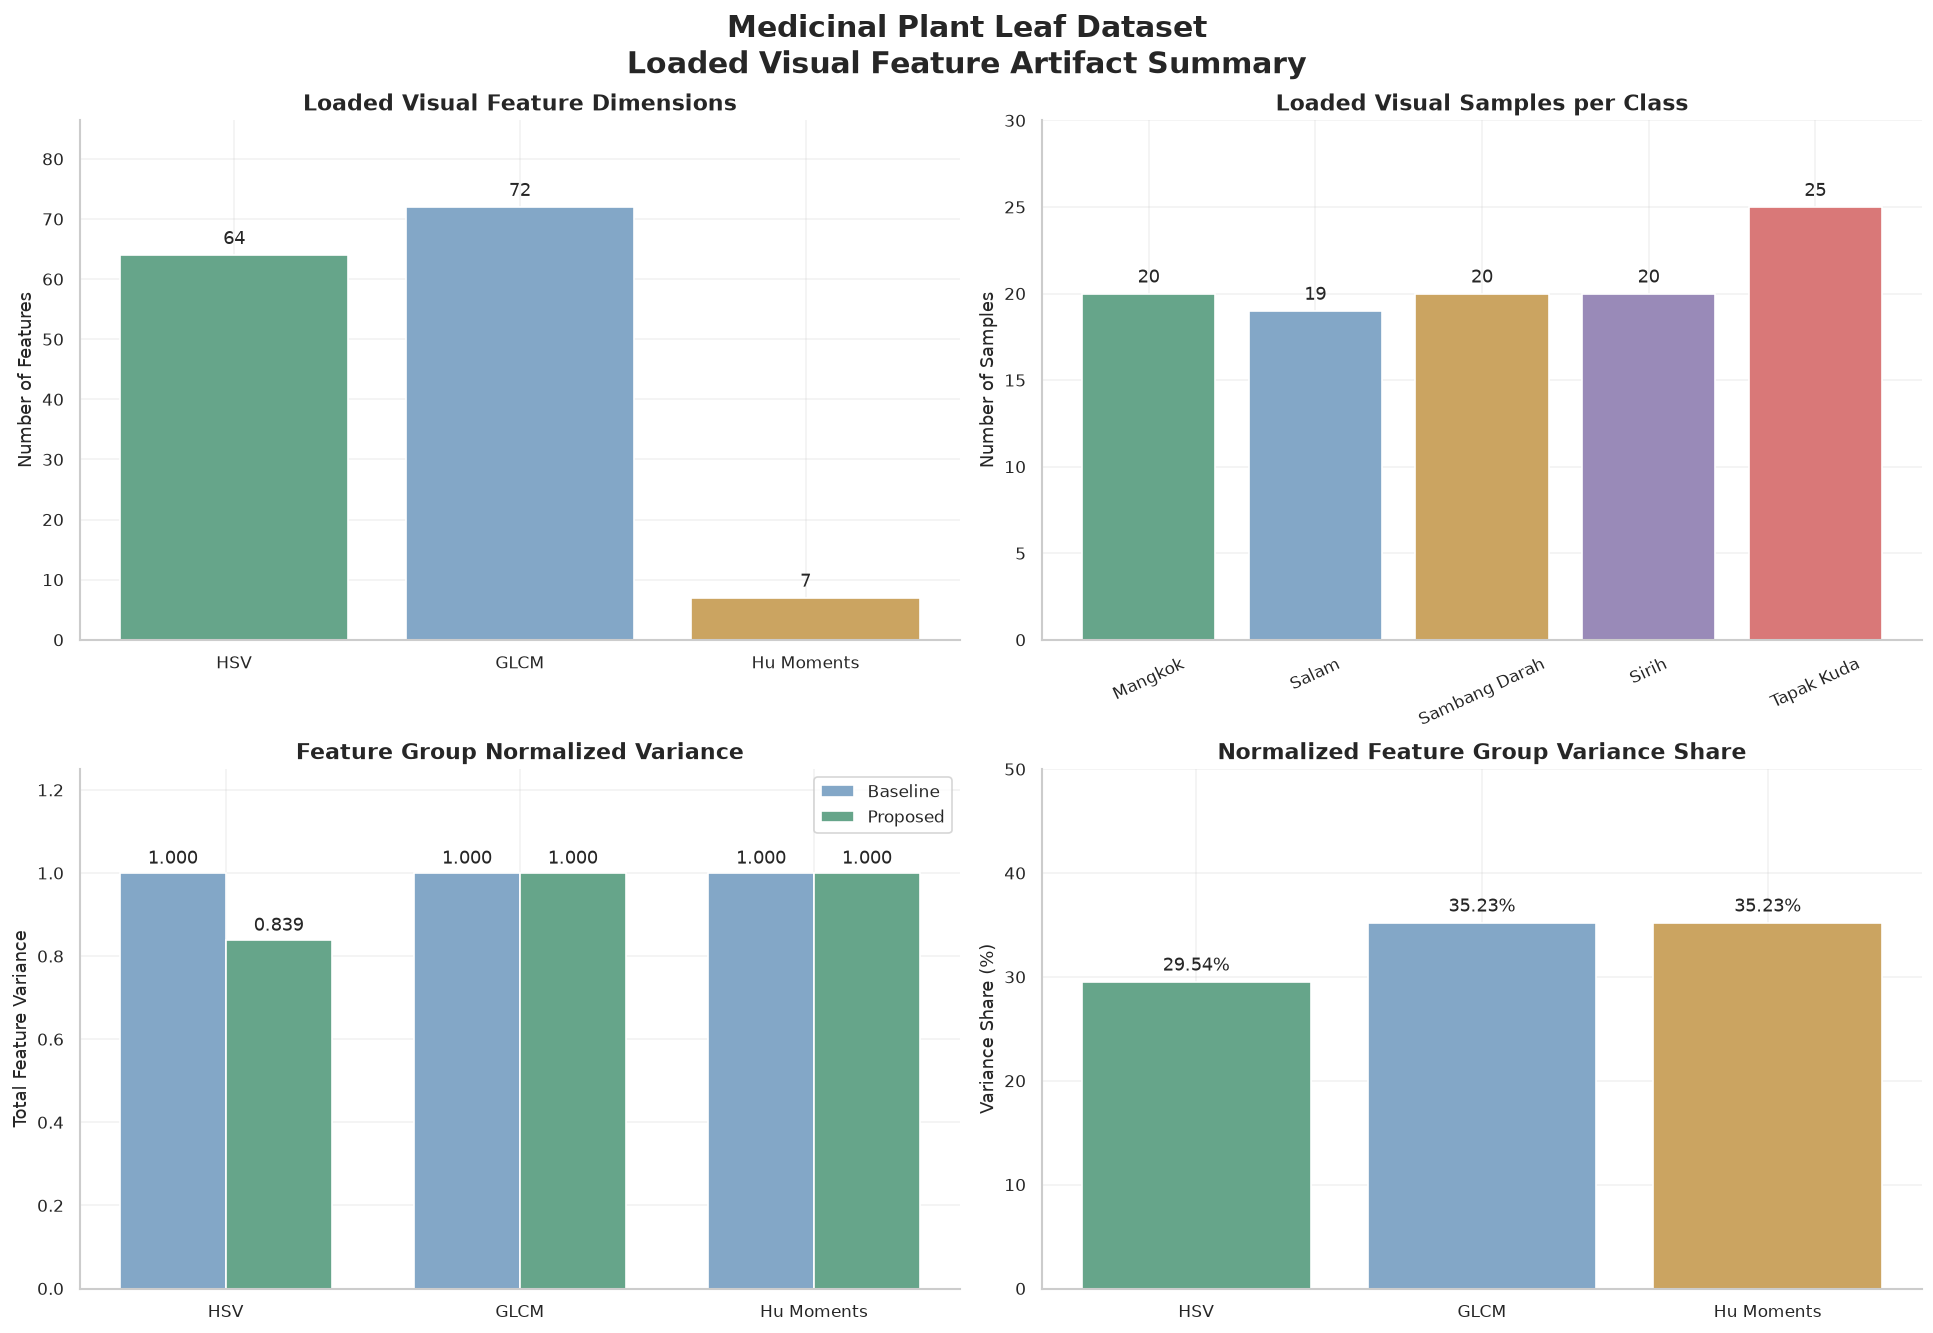

[SAVED] 104_loaded_visual_feature_summary.png


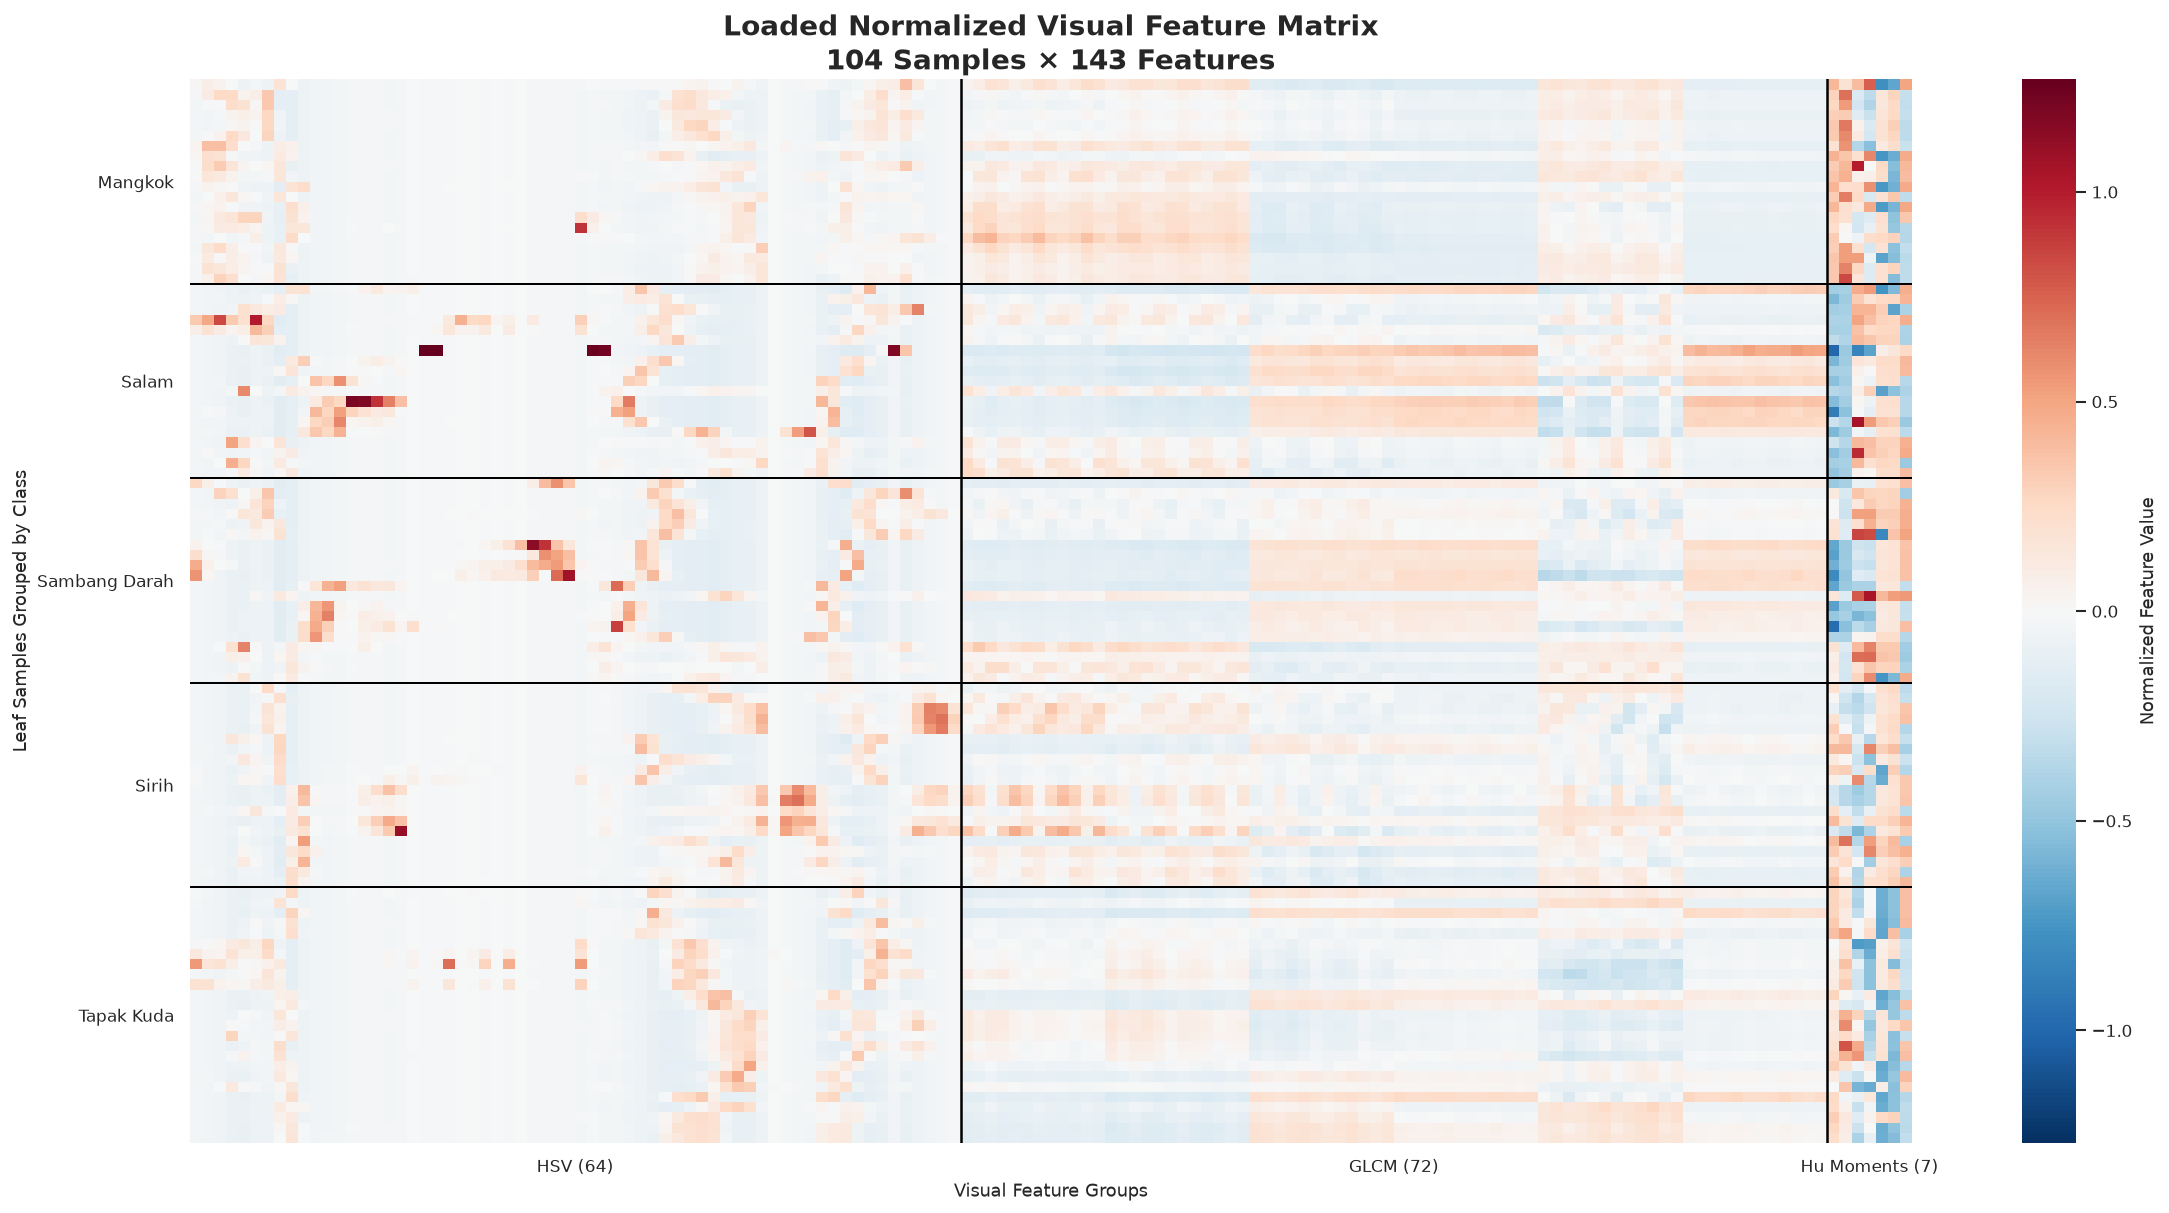

[SAVED] 105_loaded_visual_feature_matrix.png

15. VISUAL LOADING SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Total visual artifacts,14
1,Verified visual artifacts,14
2,Loaded NumPy arrays,8
3,Loaded visual normalizers,2
4,Total samples,104
5,Total classes,5
6,HSV feature dimension,64
7,GLCM feature dimension,72
8,Hu Moments feature dimension,7
9,Total visual feature dimension,143



16. SAVING VISUAL LOADING REPORTS
----------------------------------------------------------------------
[SAVED] 358_visual_artifact_integrity.csv
[SAVED] 359_loaded_visual_matrix_summary.csv
[SAVED] 360_visual_source_sample_alignment.csv
[SAVED] 361_visual_normalization_reconstruction.csv
[SAVED] 362_loaded_visual_group_summary.csv
[SAVED] 363_loaded_visual_class_summary.csv
[SAVED] 364_loaded_visual_review_summary.csv
[SAVED] 365_visual_loading_validation.csv
[SAVED] 366_visual_artifact_loading_times.csv
[SAVED] 367_visual_loading_summary.csv

FINAL VISUAL FEATURE LOADING SUMMARY

ARTIFACT INFORMATION
----------------------------------------------------------------------
Visual artifacts verified : 14/14
Loaded NumPy arrays       : 8
Loaded normalizers        : 2

VISUAL FEATURE DIMENSIONS
----------------------------------------------------------------------
HSV features        : (104, 64)
GLCM features       : (104, 72)
Hu Moments features : (104, 7)
Raw visual matrix   : (104, 14

In [5]:
# ==================================================
# CELL 4 - LOAD VISUAL FEATURE ARTIFACTS
# ==================================================

print("MULTIMODAL FUSION - LOAD VISUAL FEATURE ARTIFACTS")
print("=" * 70)

VISUAL_FEATURE_LOADING_COMPLETED = False
VISUAL_FEATURES_LOADED = False


# ==================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ==================================================

assert FUSION_LIBRARIES_IMPORTED is True

assert FUSION_PATH_CONFIGURATION_COMPLETED is True, (
    "Run Cell 3 - Path Configuration first."
)

assert fusion_path_validation_df["passed"].all()

print("[PASS] Previous processing stages validated.")


# ==================================================
# 2. VISUAL FEATURE CONFIGURATION
# ==================================================

EXPECTED_VISUAL_SAMPLES = 104

EXPECTED_VISUAL_DIMENSION = 143

VISUAL_LOADING_TOLERANCE = 1e-10

VISUAL_HSV_SD_FLOOR = 0.001

VISUAL_FEATURE_GROUP_DIMENSIONS = {
    "HSV": 64,
    "GLCM": 72,
    "Hu Moments": 7
}

VISUAL_FEATURE_GROUP_ORDER = [
    "HSV",
    "GLCM",
    "Hu Moments"
]

VISUAL_FEATURE_GROUP_SLICES = {
    "HSV": slice(0, 64),
    "GLCM": slice(64, 136),
    "Hu Moments": slice(136, 143)
}

VISUAL_LOADING_SCOPE = (
    "Full Dataset - Gallery Development"
)

visual_loading_validation_records = []
visual_loading_figure_paths = []

print("\n1. VISUAL FEATURE CONFIGURATION")
print("-" * 70)

print(f"Expected samples   : {EXPECTED_VISUAL_SAMPLES}")
print(f"Expected dimension : {EXPECTED_VISUAL_DIMENSION}")
print(f"HSV SD floor       : {VISUAL_HSV_SD_FLOOR}")
print(f"Numerical tolerance: {VISUAL_LOADING_TOLERANCE}")
print(f"Loading scope      : {VISUAL_LOADING_SCOPE}")


# ==================================================
# 3. HELPER FUNCTIONS
# ==================================================

def register_visual_loading_check(
    category,
    check_name,
    passed
):

    visual_loading_validation_records.append({
        "category": category,
        "validation_check": check_name,
        "passed": bool(passed),
        "status": "Passed" if passed else "Failed"
    })


def to_clean_string_array(values):

    # Convert any input (object/list/Series) into a
    # trimmed NumPy unicode array (dtype "<U...").
    # np.char functions in NumPy 2.x reject object arrays.

    return (
        pd.Series(np.asarray(values).ravel())
        .astype(str)
        .str.strip()
        .to_numpy(dtype=str)
    )


def all_nonempty_strings(values):

    return bool(
        (pd.Series(np.asarray(values).ravel())
         .astype(str)
         .str.strip() != "").all()
    )


def calculate_artifact_sha256(file_path):

    checksum = hashlib.sha256()

    with open(file_path, "rb") as file:

        for block in iter(
            lambda: file.read(65536),
            b""
        ):
            checksum.update(block)

    return checksum.hexdigest()


def read_fusion_json(file_path):

    with open(
        file_path,
        "r",
        encoding="utf-8-sig"
    ) as file:

        return json.load(file)


def save_visual_loading_figure(fig, filename):

    output_path = FUSION_FIGURES_DIR / filename

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    visual_loading_figure_paths.append(output_path)

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


# ==================================================
# 4. LOAD VISUAL ARTIFACT MANIFEST
# ==================================================

# Prefer the CSV manifest generated in Notebook 03.

if VISUAL_MANIFEST_CSV_PATH.is_file():

    loaded_visual_manifest_df = pd.read_csv(
        VISUAL_MANIFEST_CSV_PATH,
        dtype={
            "filename": str,
            "relative_path": str,
            "sha256": str
        },
        keep_default_na=False
    )

    visual_manifest_source = VISUAL_MANIFEST_CSV_PATH

else:

    # Support JSON manifests containing artifact records.

    visual_manifest_payload = read_fusion_json(
        VISUAL_MANIFEST_JSON_PATH
    )

    def extract_manifest_records(node):

        records = []

        if isinstance(node, list):

            for item in node:
                records.extend(
                    extract_manifest_records(item)
                )

        elif isinstance(node, dict):

            if {
                "filename",
                "sha256",
                "size_bytes"
            }.issubset(node):

                records.append(node)

            else:

                for value in node.values():
                    records.extend(
                        extract_manifest_records(value)
                    )

        return records

    loaded_visual_manifest_df = pd.DataFrame(
        extract_manifest_records(
            visual_manifest_payload
        )
    )

    visual_manifest_source = VISUAL_MANIFEST_JSON_PATH


required_manifest_columns = {
    "filename",
    "size_bytes",
    "sha256"
}

assert required_manifest_columns.issubset(
    loaded_visual_manifest_df.columns
), "Unsupported visual manifest structure."

assert loaded_visual_manifest_df[
    "filename"
].is_unique

visual_manifest_index = (
    loaded_visual_manifest_df
    .set_index("filename")
)

expected_visual_filenames = {
    path.name
    for path in VISUAL_ARTIFACT_PATHS.values()
}

register_visual_loading_check(
    "Manifest",
    "All expected visual artifacts listed",
    expected_visual_filenames.issubset(
        set(visual_manifest_index.index)
    )
)

assert expected_visual_filenames.issubset(
    set(visual_manifest_index.index)
), "Some visual artifacts are absent from the manifest."

print("\n2. VISUAL ARTIFACT MANIFEST")
print("-" * 70)

print(f"Manifest source: {visual_manifest_source.name}")
print(f"Manifest records: {len(loaded_visual_manifest_df)}")

display(
    loaded_visual_manifest_df[
        ["filename", "size_bytes", "sha256"]
    ]
)


# ==================================================
# 5. VERIFY ARTIFACT CHECKSUMS BEFORE LOADING
# ==================================================

visual_artifact_integrity_records = []

for artifact_name, file_path in (
    VISUAL_ARTIFACT_PATHS.items()
):

    manifest_record = visual_manifest_index.loc[
        file_path.name
    ]

    expected_size = int(
        manifest_record["size_bytes"]
    )

    expected_checksum = str(
        manifest_record["sha256"]
    ).strip().lower()

    exists = file_path.is_file()

    actual_size = (
        file_path.stat().st_size
        if exists
        else 0
    )

    actual_checksum = (
        calculate_artifact_sha256(file_path)
        if exists
        else ""
    )

    size_match = (
        exists
        and actual_size == expected_size
    )

    checksum_match = (
        exists
        and actual_checksum == expected_checksum
    )

    passed = (
        exists
        and size_match
        and checksum_match
    )

    visual_artifact_integrity_records.append({
        "artifact": artifact_name,
        "filename": file_path.name,
        "expected_size_bytes": expected_size,
        "actual_size_bytes": actual_size,
        "expected_sha256": expected_checksum,
        "actual_sha256": actual_checksum,
        "file_exists": exists,
        "size_match": size_match,
        "checksum_match": checksum_match,
        "passed": passed
    })

    register_visual_loading_check(
        "Artifact Integrity",
        f"{file_path.name} file size and checksum",
        passed
    )

    print(
        f"[{'PASS' if passed else 'FAIL'}] "
        f"{file_path.name}"
    )


visual_artifact_integrity_df = pd.DataFrame(
    visual_artifact_integrity_records
)

visual_artifact_integrity_df.to_csv(
    METRICS_DIR / "358_visual_artifact_integrity.csv",
    index=False,
    encoding="utf-8-sig"
)

assert visual_artifact_integrity_df["passed"].all(), (
    visual_artifact_integrity_df.loc[
        ~visual_artifact_integrity_df["passed"]
    ].to_string(index=False)
)

print("\n[PASS] All visual artifact checksums verified.")


# ==================================================
# 6. LOAD VISUAL NUMPY ARRAYS
# ==================================================

visual_array_keys = [
    "hsv_features",
    "glcm_features",
    "hu_features",
    "hu_raw_moments",
    "raw_features",
    "baseline_features",
    "normalized_features",
    "sample_ids"
]

loaded_visual_arrays = {}
visual_loading_time_records = []

print("\n3. LOADING VISUAL NUMPY ARRAYS")
print("-" * 70)

for artifact_name in visual_array_keys:

    start_time = time.perf_counter()

    array = np.load(
        VISUAL_ARTIFACT_PATHS[artifact_name],
        allow_pickle=False
    )

    loading_time_ms = (
        time.perf_counter() - start_time
    ) * 1000

    loaded_visual_arrays[artifact_name] = array

    visual_loading_time_records.append({
        "artifact": artifact_name,
        "filename": (
            VISUAL_ARTIFACT_PATHS[
                artifact_name
            ].name
        ),
        "loading_time_ms": loading_time_ms,
        "array_shape": str(array.shape),
        "dtype": str(array.dtype)
    })

    print(
        f"[LOADED] {artifact_name}: "
        f"{array.shape}"
    )


# ==================================================
# 7. CREATE MAIN VISUAL FEATURE VARIABLES
# ==================================================

loaded_hsv_features = (
    loaded_visual_arrays["hsv_features"]
)

loaded_glcm_features = (
    loaded_visual_arrays["glcm_features"]
)

loaded_hu_features = (
    loaded_visual_arrays["hu_features"]
)

loaded_hu_raw_moments = (
    loaded_visual_arrays["hu_raw_moments"]
)

loaded_visual_raw_features = (
    loaded_visual_arrays["raw_features"]
)

loaded_visual_baseline_features = (
    loaded_visual_arrays["baseline_features"]
)

loaded_visual_normalized_features = (
    loaded_visual_arrays["normalized_features"]
)

loaded_visual_sample_ids = to_clean_string_array(
    loaded_visual_arrays["sample_ids"]
)

# Main representation for subsequent fusion.

visual_features = (
    loaded_visual_normalized_features
)

visual_sample_ids = (
    loaded_visual_sample_ids
)

visual_n_samples = len(
    loaded_visual_sample_ids
)

VISUAL_FEATURE_DIM = (
    visual_features.shape[1]
)


# ==================================================
# 8. VALIDATE MATRIX DIMENSIONS AND VALUES
# ==================================================

visual_expected_shapes = {
    "hsv_features": (104, 64),
    "glcm_features": (104, 72),
    "hu_features": (104, 7),
    "hu_raw_moments": (104, 7),
    "raw_features": (104, 143),
    "baseline_features": (104, 143),
    "normalized_features": (104, 143)
}

visual_matrix_records = []

for artifact_name, expected_shape in (
    visual_expected_shapes.items()
):

    matrix = loaded_visual_arrays[
        artifact_name
    ]

    correct_shape = (
        matrix.shape == expected_shape
    )

    correct_dtype = (
        matrix.dtype == np.float64
    )

    finite_values = bool(
        np.isfinite(matrix).all()
    )

    register_visual_loading_check(
        "Matrix Validation",
        f"{artifact_name} correct dimensions",
        correct_shape
    )

    register_visual_loading_check(
        "Matrix Validation",
        f"{artifact_name} float64 dtype",
        correct_dtype
    )

    register_visual_loading_check(
        "Matrix Validation",
        f"{artifact_name} finite values",
        finite_values
    )

    visual_matrix_records.append({
        "artifact": artifact_name,
        "number_of_samples": matrix.shape[0],
        "feature_dimension": matrix.shape[1],
        "matrix_shape": str(matrix.shape),
        "dtype": str(matrix.dtype),
        "minimum_value": float(matrix.min()),
        "maximum_value": float(matrix.max()),
        "mean_value": float(matrix.mean()),
        "std_value": float(matrix.std()),
        "nan_values": int(np.isnan(matrix).sum()),
        "infinite_values": int(np.isinf(matrix).sum()),
        "memory_kib": matrix.nbytes / 1024,
        "passed": (
            correct_shape
            and correct_dtype
            and finite_values
        )
    })


visual_loaded_matrix_summary_df = pd.DataFrame(
    visual_matrix_records
)

print("\n4. VISUAL MATRIX VALIDATION")
print("-" * 70)

display(
    visual_loaded_matrix_summary_df.round(6)
)

assert visual_loaded_matrix_summary_df[
    "passed"
].all()


# ==================================================
# 9. VALIDATE SAMPLE IDENTITIES
# ==================================================

visual_id_checks = {

    "Sample ID array is one dimensional":
        loaded_visual_sample_ids.ndim == 1,

    "Expected sample ID count":
        visual_n_samples == EXPECTED_VISUAL_SAMPLES,

    "Sample IDs are unique":
        len(np.unique(loaded_visual_sample_ids))
        == visual_n_samples,

    "Sample IDs are nonempty":
        all_nonempty_strings(
            loaded_visual_sample_ids
        ),

    "Sample IDs contain no invalid placeholders":
        not pd.Series(loaded_visual_sample_ids)
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["nan", "none", "null"])
        .any()
}

for check_name, passed in visual_id_checks.items():

    register_visual_loading_check(
        "Sample Identity",
        check_name,
        passed
    )

assert all(visual_id_checks.values()), (
    "Invalid visual sample IDs detected."
)

print("\n5. VISUAL SAMPLE IDENTITIES")
print("-" * 70)

print(f"Total sample IDs  : {visual_n_samples}")

print(
    "Unique sample IDs :",
    len(np.unique(loaded_visual_sample_ids))
)

print("First five IDs:")

display(loaded_visual_sample_ids[:5])


# ==================================================
# 10. LOAD VISUAL METADATA
# ==================================================

loaded_visual_metadata_df = pd.read_csv(
    VISUAL_METADATA_PATH,
    dtype={"sample_id": str},
    keep_default_na=False,
    float_precision="round_trip"
)

loaded_processed_metadata_df = pd.read_csv(
    PROCESSED_METADATA_PATH,
    dtype={"sample_id": str},
    keep_default_na=False,
    float_precision="round_trip"
)

required_visual_metadata_columns = {
    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",
    "processed_image_path",
    "mask_path",
    "validation_status"
}

assert required_visual_metadata_columns.issubset(
    loaded_visual_metadata_df.columns
), (
    "Required visual metadata columns missing."
)

assert {
    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",
    "processed_image_path",
    "mask_path",
    "multimodal_valid",
    "final_dataset_status"
}.issubset(
    loaded_processed_metadata_df.columns
)

assert loaded_visual_metadata_df[
    "sample_id"
].is_unique

assert loaded_processed_metadata_df[
    "sample_id"
].is_unique

assert len(loaded_visual_metadata_df) == visual_n_samples

assert np.array_equal(
    loaded_visual_metadata_df[
        "sample_id"
    ].to_numpy(dtype=str),
    loaded_visual_sample_ids
), "Visual metadata row order mismatch."

assert set(
    loaded_visual_sample_ids
) == set(
    loaded_processed_metadata_df["sample_id"]
), "Source and visual sample coverage mismatch."

# Align source metadata only.
# The saved feature matrix order remains unchanged.

visual_source_aligned_df = (
    loaded_processed_metadata_df
    .set_index("sample_id")
    .loc[loaded_visual_sample_ids]
    .reset_index()
)

loaded_visual_labels = to_clean_string_array(
    loaded_visual_metadata_df["kelas"]
)

visual_labels = loaded_visual_labels

visual_class_names = sorted(
    np.unique(visual_labels)
)

# Identify the saved row-index column.

visual_row_index_column = next(
    (
        column
        for column in [
            "feature_row_index",
            "visual_feature_row",
            "feature_row",
            "row_index",
            "sample_index"
        ]
        if column in loaded_visual_metadata_df.columns
    ),
    None
)

assert visual_row_index_column is not None, (
    "Saved visual feature row-index column not found."
)

saved_row_indices = pd.to_numeric(
    loaded_visual_metadata_df[
        visual_row_index_column
    ],
    errors="raise"
).to_numpy()

register_visual_loading_check(
    "Metadata Alignment",
    "Visual row indices sequential",
    np.array_equal(
        saved_row_indices,
        np.arange(visual_n_samples)
    )
)

print("\n6. VISUAL METADATA")
print("-" * 70)

print(
    "Visual metadata shape:",
    loaded_visual_metadata_df.shape
)

display(
    loaded_visual_metadata_df[
        [
            "sample_id",
            "nama_file",
            "kelas",
            "tampilan_daun",
            "validation_status"
        ]
    ].head(10)
)


# ==================================================
# 11. VALIDATE METADATA ALIGNMENT
# ==================================================

visual_sample_alignment_df = pd.DataFrame({
    "row_index": np.arange(visual_n_samples),
    "sample_id": loaded_visual_sample_ids,
    "kelas": visual_labels
})

visual_identity_columns = [
    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",
    "processed_image_path",
    "mask_path"
]

visual_alignment_columns = []

for column in visual_identity_columns:

    visual_values = (
        loaded_visual_metadata_df[
            column
        ].astype(str).to_numpy()
    )

    source_values = (
        visual_source_aligned_df[
            column
        ].astype(str).to_numpy()
    )

    match_column = f"{column}_match"

    visual_sample_alignment_df[
        match_column
    ] = (
        visual_values == source_values
    )

    visual_alignment_columns.append(
        match_column
    )

    register_visual_loading_check(
        "Metadata Alignment",
        f"{column} matches processed metadata",
        visual_sample_alignment_df[
            match_column
        ].all()
    )


visual_sample_alignment_df[
    "alignment_passed"
] = visual_sample_alignment_df[
    visual_alignment_columns
].all(axis=1)

register_visual_loading_check(
    "Metadata Alignment",
    "All visual samples match source metadata",
    visual_sample_alignment_df[
        "alignment_passed"
    ].all()
)

assert visual_sample_alignment_df[
    "alignment_passed"
].all()

print("[PASS] Visual metadata alignment validated.")


# ==================================================
# 12. LOAD VISUAL FEATURE INDEX AND CONFIGURATION
# ==================================================

loaded_visual_feature_index_df = pd.read_csv(
    VISUAL_ARTIFACT_PATHS["feature_index"],
    encoding="utf-8-sig",
    keep_default_na=False
)

loaded_visual_feature_names_payload = read_fusion_json(
    VISUAL_ARTIFACT_PATHS["feature_names"]
)

loaded_visual_config = read_fusion_json(
    VISUAL_ARTIFACT_PATHS["configuration"]
)

# Clean CSV header names.
loaded_visual_feature_index_df.columns = (
    loaded_visual_feature_index_df.columns
    .astype(str)
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
)

print("\n7. VISUAL FEATURE INDEX")
print("-" * 70)

print(
    "Original CSV columns:",
    loaded_visual_feature_index_df.columns.tolist()
)

print(
    "Total feature records:",
    len(loaded_visual_feature_index_df)
)

# --------------------------------------------------
# A. Detect column names based on actual CSV schema
# --------------------------------------------------

def find_existing_column(dataframe, candidates):

    lookup = {
        str(column).strip().lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:

        match = lookup.get(candidate.lower())

        if match is not None:
            return match

    return None


index_column = find_existing_column(
    loaded_visual_feature_index_df,
    [
        "feature_index",
        "global_feature_index",
        "global_index",
        "column_index",
        "feature_position",
        "index",
        "idx"
    ]
)

name_column = find_existing_column(
    loaded_visual_feature_index_df,
    [
        "feature_name",
        "feature",
        "name",
        "feature_label",
        "feature_id",
        "feature_description"
    ]
)

group_column = find_existing_column(
    loaded_visual_feature_index_df,
    [
        "feature_group",
        "group",
        "feature_type",
        "feature_category"
    ]
)

print("Detected index column:", index_column)
print("Detected name column :", name_column)
print("Detected group column:", group_column)

# Do not invent feature names or indices.
# Report the real schema if it is not recognized.

if index_column is None or name_column is None:

    display(
        loaded_visual_feature_index_df.head(5)
    )

    raise ValueError(
        "Visual feature index CSV schema is not recognized. "
        f"Available columns: "
        f"{loaded_visual_feature_index_df.columns.tolist()}"
    )

# --------------------------------------------------
# B. Standardize column names for subsequent checks
# --------------------------------------------------

rename_columns = {
    index_column: "feature_index",
    name_column: "feature_name"
}

if group_column is not None:

    rename_columns[group_column] = "feature_group"

loaded_visual_feature_index_df = (
    loaded_visual_feature_index_df.rename(
        columns=rename_columns
    )
)

# Validate row count.

assert len(
    loaded_visual_feature_index_df
) == EXPECTED_VISUAL_DIMENSION, (
    "Feature index row count does not match "
    "the expected 143 visual features."
)

# --------------------------------------------------
# C. Validate and normalize feature indices
# --------------------------------------------------

feature_indices = pd.to_numeric(
    loaded_visual_feature_index_df["feature_index"],
    errors="raise"
).to_numpy()

expected_zero_based = np.arange(
    EXPECTED_VISUAL_DIMENSION
)

expected_one_based = np.arange(
    1,
    EXPECTED_VISUAL_DIMENSION + 1
)

if np.array_equal(
    feature_indices,
    expected_zero_based
):

    print("[PASS] Zero-based feature indices detected.")

elif np.array_equal(
    feature_indices,
    expected_one_based
):

    print("[INFO] One-based feature indices detected.")

    # Convert index labels to zero-based positions.
    # The row order is not changed.

    loaded_visual_feature_index_df[
        "feature_index"
    ] = expected_zero_based

else:

    raise ValueError(
        "Feature indices are not sequential "
        "or do not follow the saved column order."
    )

# --------------------------------------------------
# D. Validate feature names
# --------------------------------------------------

# FIX: use dtype=str so the array is "<U..." rather
# than object dtype (np.char rejects object arrays).

loaded_visual_feature_names = to_clean_string_array(
    loaded_visual_feature_index_df["feature_name"]
)

assert len(
    np.unique(loaded_visual_feature_names)
) == EXPECTED_VISUAL_DIMENSION, (
    "Duplicate visual feature names detected."
)

assert all_nonempty_strings(
    loaded_visual_feature_names
), "Empty visual feature names detected."

# Normalize recognized group labels without
# changing the feature-group sequence.

if "feature_group" in loaded_visual_feature_index_df:

    normalized_groups = (
        loaded_visual_feature_index_df[
            "feature_group"
        ]
        .astype(str)
        .str.strip()
    )

    group_aliases = {
        "hsv": "HSV",
        "glcm": "GLCM",
        "hu": "Hu Moments",
        "hu moments": "Hu Moments",
        "hu_moments": "Hu Moments",
        "humoments": "Hu Moments"
    }

    loaded_visual_feature_index_df[
        "feature_group"
    ] = normalized_groups.map(
        lambda value: group_aliases.get(
            value.lower(),
            value
        )
    )

# --------------------------------------------------
# E. Register validation results
# --------------------------------------------------

register_visual_loading_check(
    "Feature Index",
    "Visual feature indices sequential",
    np.array_equal(
        loaded_visual_feature_index_df[
            "feature_index"
        ].to_numpy(),
        expected_zero_based
    )
)

register_visual_loading_check(
    "Feature Index",
    "Visual feature names unique",
    len(np.unique(
        loaded_visual_feature_names
    )) == EXPECTED_VISUAL_DIMENSION
)

register_visual_loading_check(
    "Feature Index",
    "Visual feature names nonempty",
    all_nonempty_strings(
        loaded_visual_feature_names
    )
)

print("\nStandardized CSV columns:")
print(
    loaded_visual_feature_index_df.columns.tolist()
)

display(
    loaded_visual_feature_index_df.head(10)
)

print("[PASS] Visual feature index loaded and validated.")


# ==================================================
# 13. VALIDATE FEATURE NAME ORDER
# ==================================================

# Support either a single complete feature-name list
# or separate lists for HSV, GLCM, and Hu Moments.

def collect_feature_name_lists(node):

    results = []

    if isinstance(node, list):

        if node and all(
            isinstance(item, str)
            for item in node
        ):

            results.append(node)

        else:

            for item in node:

                results.extend(
                    collect_feature_name_lists(item)
                )

    elif isinstance(node, dict):

        for value in node.values():

            results.extend(
                collect_feature_name_lists(value)
            )

    return results


visual_name_lists = [
    [str(name).strip() for name in names]
    for names in collect_feature_name_lists(
        loaded_visual_feature_names_payload
    )
]

expected_names_list = (
    loaded_visual_feature_names.tolist()
)

complete_name_order_match = any(
    names == expected_names_list
    for names in visual_name_lists
)

group_name_order_match = all(

    any(
        names == expected_names_list[
            VISUAL_FEATURE_GROUP_SLICES[group_name]
        ]

        for names in visual_name_lists
    )

    for group_name in VISUAL_FEATURE_GROUP_ORDER
)

register_visual_loading_check(
    "Feature Index",
    "Feature-name JSON matches feature index",
    complete_name_order_match
    or group_name_order_match
)

register_visual_loading_check(
    "Feature Index",
    "Feature configuration loaded",
    isinstance(loaded_visual_config, dict)
    and len(loaded_visual_config) > 0
)

if "feature_group" in (
    loaded_visual_feature_index_df.columns
):

    expected_group_sequence = np.repeat(
        VISUAL_FEATURE_GROUP_ORDER,
        [64, 72, 7]
    )

    actual_group_sequence = (
        loaded_visual_feature_index_df[
            "feature_group"
        ].to_numpy(dtype=str)
    )

    register_visual_loading_check(
        "Feature Index",
        "Feature group order preserved",
        np.array_equal(
            actual_group_sequence,
            expected_group_sequence
        )
    )


print("\n7. VISUAL FEATURE INDEX")
print("-" * 70)

print(
    "Feature names:",
    len(loaded_visual_feature_names)
)

display(
    loaded_visual_feature_index_df.head(10)
)


# ==================================================
# 14. LOAD SAVED NORMALIZERS
# ==================================================

# Only load locally generated, trusted Joblib files.
# The manifest checks were completed before this stage.

loaded_visual_normalizer = joblib.load(
    VISUAL_ARTIFACT_PATHS["normalizer"]
)

loaded_baseline_visual_normalizer = joblib.load(
    VISUAL_ARTIFACT_PATHS["baseline_normalizer"]
)

register_visual_loading_check(
    "Normalizer Loading",
    "Main visual normalizer loaded",
    loaded_visual_normalizer is not None
)

register_visual_loading_check(
    "Normalizer Loading",
    "Baseline visual normalizer loaded",
    loaded_baseline_visual_normalizer is not None
)

print("\n8. LOADED VISUAL NORMALIZERS")
print("-" * 70)

print(
    "Main normalizer type:",
    type(loaded_visual_normalizer).__name__
)

print(
    "Baseline normalizer type:",
    type(loaded_baseline_visual_normalizer).__name__
)

if isinstance(loaded_visual_normalizer, dict):

    print(
        "Main normalizer keys:",
        list(loaded_visual_normalizer.keys())
    )

if isinstance(
    loaded_baseline_visual_normalizer,
    dict
):

    print(
        "Baseline normalizer keys:",
        list(
            loaded_baseline_visual_normalizer.keys()
        )
    )


# ==================================================
# 15. RECONSTRUCT RAW FEATURE CONCATENATION
# ==================================================

reconstructed_visual_raw_features = np.hstack([
    loaded_hsv_features,
    loaded_glcm_features,
    loaded_hu_features
])

visual_raw_reconstruction_difference = float(
    np.max(
        np.abs(
            reconstructed_visual_raw_features
            - loaded_visual_raw_features
        )
    )
)

register_visual_loading_check(
    "Feature Reconstruction",
    "Raw feature concatenation exactly preserved",
    np.array_equal(
        reconstructed_visual_raw_features,
        loaded_visual_raw_features
    )
)

print("\n9. RAW FEATURE RECONSTRUCTION")
print("-" * 70)

print(
    "Reconstructed raw shape:",
    reconstructed_visual_raw_features.shape
)

print(
    "Maximum reconstruction difference:",
    f"{visual_raw_reconstruction_difference:.3e}"
)


# ==================================================
# 16. VERIFY NORMALIZATION MATHEMATICALLY
# ==================================================

# Independently reproduce the documented normalization
# formulas from Notebook 03.
#
# No saved normalizer is refitted or modified.
# Reconstructed arrays are used only for verification.

visual_raw_group_matrices = {
    "HSV": loaded_hsv_features,
    "GLCM": loaded_glcm_features,
    "Hu Moments": loaded_hu_features
}

visual_reconstructed_baseline_groups = {}

visual_reconstructed_normalized_groups = {}

visual_normalization_records = []

for group_name in VISUAL_FEATURE_GROUP_ORDER:

    raw_group = visual_raw_group_matrices[
        group_name
    ]

    dimension = raw_group.shape[1]

    feature_mean = raw_group.mean(axis=0)

    feature_std = raw_group.std(
        axis=0,
        ddof=0
    )

    constant_mask = feature_std == 0

    baseline_scale = np.where(
        constant_mask,
        1.0,
        feature_std
    )

    proposed_scale = baseline_scale.copy()

    floor_mask = np.zeros(
        dimension,
        dtype=bool
    )

    if group_name == "HSV":

        floor_mask = (
            (feature_std < VISUAL_HSV_SD_FLOOR)
            & ~constant_mask
        )

        proposed_scale[floor_mask] = (
            VISUAL_HSV_SD_FLOOR
        )

    # Group balancing.

    group_weight = 1.0 / np.sqrt(
        dimension
    )

    baseline_group = (
        (raw_group - feature_mean)
        / baseline_scale
    ) * group_weight

    proposed_group = (
        (raw_group - feature_mean)
        / proposed_scale
    ) * group_weight

    group_slice = (
        VISUAL_FEATURE_GROUP_SLICES[
            group_name
        ]
    )

    saved_baseline_group = (
        loaded_visual_baseline_features[
            :, group_slice
        ]
    )

    saved_normalized_group = (
        loaded_visual_normalized_features[
            :, group_slice
        ]
    )

    baseline_difference = float(
        np.max(
            np.abs(
                baseline_group
                - saved_baseline_group
            )
        )
    )

    proposed_difference = float(
        np.max(
            np.abs(
                proposed_group
                - saved_normalized_group
            )
        )
    )

    register_visual_loading_check(
        "Normalization Reconstruction",
        f"{group_name} baseline normalization consistent",
        baseline_difference <= VISUAL_LOADING_TOLERANCE
    )

    register_visual_loading_check(
        "Normalization Reconstruction",
        f"{group_name} proposed normalization consistent",
        proposed_difference <= VISUAL_LOADING_TOLERANCE
    )

    visual_reconstructed_baseline_groups[
        group_name
    ] = baseline_group

    visual_reconstructed_normalized_groups[
        group_name
    ] = proposed_group

    visual_normalization_records.append({
        "feature_group": group_name,
        "feature_dimension": dimension,
        "group_weight": group_weight,
        "constant_features": int(constant_mask.sum()),
        "sd_floor_adjusted_features": int(
            floor_mask.sum()
        ),
        "raw_total_variance": float(
            raw_group.var(axis=0).sum()
        ),
        "baseline_total_variance": float(
            saved_baseline_group.var(axis=0).sum()
        ),
        "normalized_total_variance": float(
            saved_normalized_group.var(axis=0).sum()
        ),
        "baseline_max_difference": baseline_difference,
        "normalized_max_difference": proposed_difference
    })


visual_normalization_reconstruction_df = pd.DataFrame(
    visual_normalization_records
)

print("\n10. NORMALIZATION RECONSTRUCTION")
print("-" * 70)

display(
    visual_normalization_reconstruction_df.round(8)
)


# ==================================================
# 17. VALIDATE COMPLETE NORMALIZED MATRICES
# ==================================================

reconstructed_visual_baseline_features = np.hstack([

    visual_reconstructed_baseline_groups[
        group_name
    ]

    for group_name in VISUAL_FEATURE_GROUP_ORDER

])

reconstructed_visual_normalized_features = np.hstack([

    visual_reconstructed_normalized_groups[
        group_name
    ]

    for group_name in VISUAL_FEATURE_GROUP_ORDER

])

visual_baseline_max_difference = float(
    np.max(
        np.abs(
            reconstructed_visual_baseline_features
            - loaded_visual_baseline_features
        )
    )
)

visual_normalized_max_difference = float(
    np.max(
        np.abs(
            reconstructed_visual_normalized_features
            - loaded_visual_normalized_features
        )
    )
)

register_visual_loading_check(
    "Normalization Reconstruction",
    "Complete baseline matrix reproduced",
    visual_baseline_max_difference
    <= VISUAL_LOADING_TOLERANCE
)

register_visual_loading_check(
    "Normalization Reconstruction",
    "Complete normalized matrix reproduced",
    visual_normalized_max_difference
    <= VISUAL_LOADING_TOLERANCE
)

register_visual_loading_check(
    "Normalization Reconstruction",
    "Normalized features centered around zero",
    np.allclose(
        visual_features.mean(axis=0),
        0,
        atol=VISUAL_LOADING_TOLERANCE,
        rtol=0
    )
)

print(
    "Baseline maximum difference:",
    f"{visual_baseline_max_difference:.3e}"
)

print(
    "Normalized maximum difference:",
    f"{visual_normalized_max_difference:.3e}"
)


# ==================================================
# 18. ANALYZE VISUAL FEATURE GROUPS
# ==================================================

visual_group_statistics_records = []

for group_name in VISUAL_FEATURE_GROUP_ORDER:

    group_slice = VISUAL_FEATURE_GROUP_SLICES[
        group_name
    ]

    group_matrix = visual_features[
        :, group_slice
    ]

    group_variance = group_matrix.var(
        axis=0
    )

    visual_group_statistics_records.append({
        "feature_group": group_name,
        "number_of_samples": group_matrix.shape[0],
        "feature_dimension": group_matrix.shape[1],
        "minimum_value": float(group_matrix.min()),
        "maximum_value": float(group_matrix.max()),
        "mean_value": float(group_matrix.mean()),
        "std_value": float(group_matrix.std()),
        "total_variance": float(group_variance.sum()),
        "constant_features": int(
            (np.ptp(group_matrix, axis=0) == 0).sum()
        ),
        "nan_values": int(
            np.isnan(group_matrix).sum()
        ),
        "infinite_values": int(
            np.isinf(group_matrix).sum()
        )
    })


visual_loaded_group_summary_df = pd.DataFrame(
    visual_group_statistics_records
)

total_visual_variance = (
    visual_loaded_group_summary_df[
        "total_variance"
    ].sum()
)

assert total_visual_variance > 0

visual_loaded_group_summary_df[
    "variance_share_percent"
] = (
    visual_loaded_group_summary_df[
        "total_variance"
    ]
    / total_visual_variance
    * 100
)

register_visual_loading_check(
    "Feature Groups",
    "Feature dimensions reconcile",
    visual_loaded_group_summary_df[
        "feature_dimension"
    ].sum() == EXPECTED_VISUAL_DIMENSION
)

register_visual_loading_check(
    "Feature Groups",
    "Feature group variance shares reconcile",
    np.isclose(
        visual_loaded_group_summary_df[
            "variance_share_percent"
        ].sum(),
        100.0,
        atol=VISUAL_LOADING_TOLERANCE
    )
)

print("\n11. VISUAL FEATURE GROUP SUMMARY")
print("-" * 70)

display(
    visual_loaded_group_summary_df.round(6)
)


# ==================================================
# 19. ANALYZE CLASS DISTRIBUTION
# ==================================================

visual_loaded_class_summary_df = (
    pd.Series(
        visual_labels,
        name="kelas"
    )
    .value_counts()
    .sort_index()
    .rename_axis("kelas")
    .reset_index(name="number_of_samples")
)

visual_loaded_class_summary_df[
    "percentage"
] = (
    visual_loaded_class_summary_df[
        "number_of_samples"
    ]
    / visual_n_samples
    * 100
)

expected_visual_class_counts = {
    "Mangkok": 20,
    "Salam": 19,
    "Sambang Darah": 20,
    "Sirih": 20,
    "Tapak Kuda": 25
}

actual_visual_class_counts = dict(zip(
    visual_loaded_class_summary_df["kelas"],
    visual_loaded_class_summary_df["number_of_samples"]
))

register_visual_loading_check(
    "Class Distribution",
    "Expected five-class distribution preserved",
    actual_visual_class_counts
    == expected_visual_class_counts
)

print("\n12. VISUAL CLASS DISTRIBUTION")
print("-" * 70)

display(
    visual_loaded_class_summary_df.round(4)
)


# ==================================================
# 20. PRESERVE DATASET REVIEW STATUS
# ==================================================

visual_loaded_review_summary_df = (
    visual_source_aligned_df[
        "final_dataset_status"
    ]
    .value_counts(dropna=False)
    .rename_axis("dataset_status")
    .reset_index(name="number_of_samples")
)

visual_loaded_review_summary_df[
    "percentage"
] = (
    visual_loaded_review_summary_df[
        "number_of_samples"
    ]
    / visual_n_samples
    * 100
)

source_technical_validity = (
    visual_source_aligned_df[
        "multimodal_valid"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
)

register_visual_loading_check(
    "Dataset Readiness",
    "All source samples technically valid",
    source_technical_validity.all()
)

register_visual_loading_check(
    "Dataset Readiness",
    "Dataset review status counts reconcile",
    visual_loaded_review_summary_df[
        "number_of_samples"
    ].sum() == visual_n_samples
)

print("\n13. DATASET REVIEW STATUS")
print("-" * 70)

display(
    visual_loaded_review_summary_df.round(4)
)

print(
    "[INFO] Manual review flags remain unchanged."
)


# ==================================================
# 21. FINAL VISUAL LOADING VALIDATION
# ==================================================

visual_loading_validation_df = pd.DataFrame(
    visual_loading_validation_records
)

visual_loading_total_checks = len(
    visual_loading_validation_df
)

visual_loading_passed_checks = int(
    visual_loading_validation_df[
        "passed"
    ].sum()
)

visual_loading_failed_checks = (
    visual_loading_total_checks
    - visual_loading_passed_checks
)

visual_loading_validation_df.to_csv(
    METRICS_DIR / "365_visual_loading_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n14. VISUAL FEATURE LOADING VALIDATION")
print("-" * 70)

display(visual_loading_validation_df)

assert visual_loading_validation_df[
    "passed"
].all(), (
    visual_loading_validation_df.loc[
        ~visual_loading_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All visual loading checks passed.")


# ==================================================
# 22. VISUALIZE LOADED VISUAL FEATURE SUMMARY
# ==================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11),
    constrained_layout=True
)

# A. Feature dimensions.

ax = axes[0, 0]

group_names = (
    visual_loaded_group_summary_df[
        "feature_group"
    ].tolist()
)

group_colors = [
    FEATURE_GROUP_COLORS[name]
    for name in group_names
]

bars = ax.bar(
    group_names,
    visual_loaded_group_summary_df[
        "feature_dimension"
    ],
    color=group_colors
)

ax.bar_label(bars, padding=4)

ax.set_title("Loaded Visual Feature Dimensions")
ax.set_ylabel("Number of Features")
ax.margins(y=0.2)


# B. Class distribution.

ax = axes[0, 1]

bars = ax.bar(
    visual_loaded_class_summary_df["kelas"],
    visual_loaded_class_summary_df[
        "number_of_samples"
    ],
    color=[
        CLASS_COLORS.get(name, "#83A7C7")
        for name in visual_loaded_class_summary_df[
            "kelas"
        ]
    ]
)

ax.bar_label(bars, padding=4)

ax.set_title("Loaded Visual Samples per Class")
ax.set_ylabel("Number of Samples")
ax.tick_params(axis="x", labelrotation=25)
ax.margins(y=0.2)


# C. Baseline vs proposed normalization variance.

ax = axes[1, 0]

positions = np.arange(len(group_names))

bars_baseline = ax.bar(
    positions - 0.18,
    visual_normalization_reconstruction_df[
        "baseline_total_variance"
    ],
    width=0.36,
    color="#83A7C7",
    label="Baseline"
)

bars_proposed = ax.bar(
    positions + 0.18,
    visual_normalization_reconstruction_df[
        "normalized_total_variance"
    ],
    width=0.36,
    color="#66A58A",
    label="Proposed"
)

ax.bar_label(
    bars_baseline,
    fmt="%.3f",
    padding=3
)

ax.bar_label(
    bars_proposed,
    fmt="%.3f",
    padding=3
)

ax.set_xticks(positions)
ax.set_xticklabels(group_names)

ax.set_title("Feature Group Normalized Variance")
ax.set_ylabel("Total Feature Variance")
ax.set_ylim(0, 1.25)
ax.legend()


# D. Variance contribution after normalization.

ax = axes[1, 1]

bars = ax.bar(
    group_names,
    visual_loaded_group_summary_df[
        "variance_share_percent"
    ],
    color=group_colors
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4
)

ax.set_title("Normalized Feature Group Variance Share")
ax.set_ylabel("Variance Share (%)")
ax.set_ylim(0, 50)

fig.suptitle(
    "Medicinal Plant Leaf Dataset\n"
    "Loaded Visual Feature Artifact Summary",
    fontsize=18,
    fontweight="bold"
)

save_visual_loading_figure(
    fig,
    "104_loaded_visual_feature_summary.png"
)


# ==================================================
# 23. VISUALIZE LOADED VISUAL FEATURE MATRIX
# ==================================================

visual_plot_order = np.argsort(
    visual_labels,
    kind="stable"
)

visual_plot_labels = visual_labels[
    visual_plot_order
]

visual_plot_matrix = visual_features[
    visual_plot_order
]

visual_class_boundaries = np.flatnonzero(
    visual_plot_labels[1:]
    != visual_plot_labels[:-1]
) + 1

visual_class_starts = np.r_[
    0,
    visual_class_boundaries
]

visual_class_ends = np.r_[
    visual_class_boundaries,
    visual_n_samples
]

visual_class_centers = (
    visual_class_starts
    + visual_class_ends
) / 2

# Use symmetric limits around zero.

visual_heatmap_limit = float(
    np.max(np.abs(visual_plot_matrix))
)

fig, ax = plt.subplots(
    figsize=(18, 10),
    constrained_layout=True
)

sns.heatmap(
    visual_plot_matrix,
    cmap="RdBu_r",
    center=0,
    vmin=-visual_heatmap_limit,
    vmax=visual_heatmap_limit,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={
        "label": "Normalized Feature Value"
    },
    ax=ax
)

# Mark visual feature-group boundaries.

for boundary in [64, 136]:

    ax.axvline(
        boundary,
        color="black",
        linewidth=1.5
    )

# Mark class boundaries.

for boundary in visual_class_boundaries:

    ax.axhline(
        boundary,
        color="black",
        linewidth=1.2
    )

ax.set_xticks([
    32,
    100,
    139.5
])

ax.set_xticklabels([
    "HSV (64)",
    "GLCM (72)",
    "Hu Moments (7)"
], rotation=0)

ax.set_yticks(
    visual_class_centers
)

ax.set_yticklabels(
    visual_plot_labels[
        visual_class_starts
    ],
    rotation=0
)

ax.set_xlabel("Visual Feature Groups")
ax.set_ylabel("Leaf Samples Grouped by Class")

ax.set_title(
    "Loaded Normalized Visual Feature Matrix\n"
    f"{visual_n_samples} Samples × "
    f"{VISUAL_FEATURE_DIM} Features",
    fontsize=17,
    fontweight="bold"
)

save_visual_loading_figure(
    fig,
    "105_loaded_visual_feature_matrix.png"
)


# ==================================================
# 24. CREATE VISUAL LOADING SUMMARY
# ==================================================

visual_loading_time_df = pd.DataFrame(
    visual_loading_time_records
)

visual_loading_summary_df = pd.DataFrame([

    ("Total visual artifacts",
     len(VISUAL_ARTIFACT_PATHS)),

    ("Verified visual artifacts",
     int(visual_artifact_integrity_df["passed"].sum())),

    ("Loaded NumPy arrays",
     len(loaded_visual_arrays)),

    ("Loaded visual normalizers", 2),

    ("Total samples", visual_n_samples),

    ("Total classes", len(visual_class_names)),

    ("HSV feature dimension",
     loaded_hsv_features.shape[1]),

    ("GLCM feature dimension",
     loaded_glcm_features.shape[1]),

    ("Hu Moments feature dimension",
     loaded_hu_features.shape[1]),

    ("Total visual feature dimension",
     VISUAL_FEATURE_DIM),

    ("Raw visual matrix shape",
     str(loaded_visual_raw_features.shape)),

    ("Baseline visual matrix shape",
     str(loaded_visual_baseline_features.shape)),

    ("Normalized visual matrix shape",
     str(loaded_visual_normalized_features.shape)),

    ("Raw reconstruction maximum difference",
     visual_raw_reconstruction_difference),

    ("Baseline reconstruction maximum difference",
     visual_baseline_max_difference),

    ("Normalized reconstruction maximum difference",
     visual_normalized_max_difference),

    ("Total normalized feature variance",
     total_visual_variance),

    ("Aligned visual samples",
     int(
         visual_sample_alignment_df[
             "alignment_passed"
         ].sum()
     )),

    ("Total validation checks",
     visual_loading_total_checks),

    ("Validation checks passed",
     visual_loading_passed_checks),

    ("Validation checks failed",
     visual_loading_failed_checks),

    ("Generated figures",
     len(visual_loading_figure_paths)),

    ("Main visual representation",
     "visual_features_normalized.npy"),

    ("Raw visual features retained", True),

    ("Feature order preserved", True),

    ("Sample order preserved", True),

    ("Review flags preserved", True),

    ("Saved normalizers refitted", False),

    ("Visual features modified", False),

    ("Independent evaluation completed", False),

    ("Evaluation requires reference-only refit", True),

    ("Text features loaded", False),

    ("Image-text alignment validated", False),

    ("Multimodal fusion completed", False),

    ("Loading scope", VISUAL_LOADING_SCOPE)

], columns=["Indicator", "Result"])

print("\n15. VISUAL LOADING SUMMARY")
print("-" * 70)

display(visual_loading_summary_df)


# ==================================================
# 25. SAVE VISUAL LOADING REPORTS
# ==================================================

visual_loading_reports = {

    "358_visual_artifact_integrity.csv":
        visual_artifact_integrity_df,

    "359_loaded_visual_matrix_summary.csv":
        visual_loaded_matrix_summary_df,

    "360_visual_source_sample_alignment.csv":
        visual_sample_alignment_df,

    "361_visual_normalization_reconstruction.csv":
        visual_normalization_reconstruction_df,

    "362_loaded_visual_group_summary.csv":
        visual_loaded_group_summary_df,

    "363_loaded_visual_class_summary.csv":
        visual_loaded_class_summary_df,

    "364_loaded_visual_review_summary.csv":
        visual_loaded_review_summary_df,

    "365_visual_loading_validation.csv":
        visual_loading_validation_df,

    "366_visual_artifact_loading_times.csv":
        visual_loading_time_df,

    "367_visual_loading_summary.csv":
        visual_loading_summary_df
}

print("\n16. SAVING VISUAL LOADING REPORTS")
print("-" * 70)

for filename, dataframe in (
    visual_loading_reports.items()
):

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 26. FINAL COMPLETION CHECKS
# ==================================================

assert visual_artifact_integrity_df[
    "passed"
].all()

assert visual_loading_validation_df[
    "passed"
].all()

assert visual_loading_failed_checks == 0

assert visual_features.shape == (104, 143)

assert len(visual_sample_ids) == 104

assert len(visual_labels) == 104

assert visual_sample_alignment_df[
    "alignment_passed"
].all()

assert np.isfinite(visual_features).all()

assert len(visual_loading_figure_paths) == 2

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in visual_loading_figure_paths
)

assert all(
    (METRICS_DIR / filename).is_file()
    and (METRICS_DIR / filename).stat().st_size > 0
    for filename in visual_loading_reports
)

VISUAL_FEATURE_LOADING_COMPLETED = True

VISUAL_FEATURES_LOADED = True


# ==================================================
# 27. PRINT FINAL SUMMARY
# ==================================================

print("\n" + "=" * 70)

print("FINAL VISUAL FEATURE LOADING SUMMARY")

print("=" * 70)

print("\nARTIFACT INFORMATION")
print("-" * 70)

print(
    f"Visual artifacts verified : "
    f"{visual_artifact_integrity_df['passed'].sum()}/"
    f"{len(VISUAL_ARTIFACT_PATHS)}"
)

print(
    f"Loaded NumPy arrays       : "
    f"{len(loaded_visual_arrays)}"
)

print("Loaded normalizers        : 2")


print("\nVISUAL FEATURE DIMENSIONS")
print("-" * 70)

print("HSV features        :", loaded_hsv_features.shape)

print("GLCM features       :", loaded_glcm_features.shape)

print("Hu Moments features :", loaded_hu_features.shape)

print("Raw visual matrix   :", loaded_visual_raw_features.shape)

print("Baseline matrix     :", loaded_visual_baseline_features.shape)

print("Normalized matrix   :", visual_features.shape)


print("\nDATASET INFORMATION")
print("-" * 70)

print(f"Total samples   : {visual_n_samples}")

print(f"Total classes   : {len(visual_class_names)}")

print(
    f"Aligned samples : "
    f"{visual_sample_alignment_df['alignment_passed'].sum()}"
)


print("\nRECONSTRUCTION RESULTS")
print("-" * 70)

print(
    f"Raw difference        : "
    f"{visual_raw_reconstruction_difference:.3e}"
)

print(
    f"Baseline difference   : "
    f"{visual_baseline_max_difference:.3e}"
)

print(
    f"Normalized difference : "
    f"{visual_normalized_max_difference:.3e}"
)


print("\nVALIDATION RESULTS")
print("-" * 70)

print(
    f"Technical checks  : "
    f"{visual_loading_passed_checks}/"
    f"{visual_loading_total_checks}"
)

print(
    f"Failed checks     : "
    f"{visual_loading_failed_checks}"
)

print(
    f"Generated reports : "
    f"{len(visual_loading_reports)}"
)

print(
    f"Generated figures : "
    f"{len(visual_loading_figure_paths)}"
)


print("\n[PASS] Visual artifact checksums verified.")

print("[PASS] All visual feature arrays loaded.")

print("[PASS] Visual matrix dimensions validated.")

print("[PASS] Visual sample identities validated.")

print("[PASS] Source metadata alignment validated.")

print("[PASS] Feature order validated.")

print("[PASS] Both saved visual normalizers loaded.")

print("[PASS] Raw feature concatenation validated.")

print("[PASS] Normalization formulas verified.")

print("[PASS] Original dataset review flags preserved.")

print("[PASS] All visual loading reports saved.")


print("\n[INFO] No visual features were re-extracted.")

print("[INFO] No saved normalizers were refitted.")

print("[INFO] No feature matrices were reordered.")

print("[INFO] Full-gallery features remain exploratory.")

print("[INFO] Text feature loading is the next stage.")

print("\n" + "=" * 70)

print("VISUAL FEATURE LOADING COMPLETED SUCCESSFULLY")

print("=" * 70)

print("\nNext cell: Cell 5 - Load Text Feature Artifacts")

MULTIMODAL FUSION - LOAD TEXT FEATURE ARTIFACTS
[PASS] Previous cells validated.

1. TEXT ARTIFACT LOCATIONS
----------------------------------------------------------------------
Text feature directory: D:\Project\Multimodal_Leaf_Retrieval\dataset\features\text
Expected payload files : 16
Manifest              : text_feature_artifact_manifest.csv
[PASS] Text artifact manifest loaded.

2. TEXT ARTIFACT INTEGRITY
----------------------------------------------------------------------
[PASS] tfidf_unigram_features.npz
[PASS] tfidf_unigram_vectorizer.joblib
[PASS] tfidf_unigram_feature_names.npy
[PASS] tfidf_unigram_idf_weights.npy
[PASS] tfidf_unigram_vocabulary.csv
[PASS] tfidf_unigram_bigram_features.npz
[PASS] tfidf_unigram_bigram_vectorizer.joblib
[PASS] tfidf_unigram_bigram_feature_names.npy
[PASS] tfidf_unigram_bigram_idf_weights.npy
[PASS] tfidf_unigram_bigram_vocabulary.csv
[PASS] text_sample_ids.npy
[PASS] text_class_labels.npy
[PASS] multimodal_feature_metadata.csv
[PASS] text_c

,row_index,sample_id,kelas,visual_id_match,visual_label_match,metadata_id_match,metadata_label_match,corpus_match,alignment_flag,passed
0,0,leaf_165d2f32c7fda707,Mangkok,True,True,True,True,True,True,True
1,1,leaf_8473270c3702f48b,Mangkok,True,True,True,True,True,True,True
2,2,leaf_8f425d66b1e193b9,Mangkok,True,True,True,True,True,True,True
3,3,leaf_0ebc8f4f3ee9c8d5,Mangkok,True,True,True,True,True,True,True
4,4,leaf_b0c5f55e42499cae,Mangkok,True,True,True,True,True,True,True
5,5,leaf_de9e3e4ed5d89dfc,Mangkok,True,True,True,True,True,True,True
6,6,leaf_23b789945271fb92,Mangkok,True,True,True,True,True,True,True
7,7,leaf_84de0dc731018607,Mangkok,True,True,True,True,True,True,True



5. LOADING TF-IDF CONFIGURATIONS
----------------------------------------------------------------------

Configuration: Unigram
Matrix shape : (104, 68)
Nonzero      : 2086
Unigram      : 68
Bigram       : 0
Reproduction difference: 1.665e-16

Configuration: Unigram + Bigram
Matrix shape : (104, 261)
Nonzero      : 4166
Unigram      : 68
Bigram       : 193
Reproduction difference: 1.110e-16

6. LOADED TEXT MATRIX SUMMARY
----------------------------------------------------------------------


C:\Users\ronn7\AppData\Local\Temp\ipykernel_22184\2737530108.py:532: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  vocabulary_df = pd.read_csv(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_22184\2737530108.py:532: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  vocabulary_df = pd.read_csv(


,configuration,samples,feature_dimension,unigram_features,bigram_features,nonzero_values,zero_values,sparsity_percent,minimum_l2_norm,maximum_l2_norm,reproduction_max_difference,matrix_file_kib,vectorizer_file_kib
0,Unigram,104,68,68,0,2086,4986,70.503394,1.0,1.0,0.0,10.820312,1.419922
1,Unigram + Bigram,104,261,68,193,4166,22978,84.652225,1.0,1.0,0.0,17.756836,3.093750



7. MAIN TEXT FEATURE VARIABLES
----------------------------------------------------------------------
Unigram features : (104, 68)
Combined features: (104, 261)
Text sample IDs  : (104,)
Text labels      : (104,)

8. CLASS DISTRIBUTION
----------------------------------------------------------------------


,kelas,number_of_samples,percentage
0,Mangkok,20,19.2308
1,Salam,19,18.2692
2,Sambang Darah,20,19.2308
3,Sirih,20,19.2308
4,Tapak Kuda,25,24.0385



9. TEXT FEATURE LOADING VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Manifest,Manifest covers all expected text artifacts,True,Passed
1,Artifact Integrity,tfidf_unigram_features.npz integrity,True,Passed
2,Artifact Integrity,tfidf_unigram_vectorizer.joblib integrity,True,Passed
3,Artifact Integrity,tfidf_unigram_feature_names.npy integrity,True,Passed
4,Artifact Integrity,tfidf_unigram_idf_weights.npy integrity,True,Passed
5,Artifact Integrity,tfidf_unigram_vocabulary.csv integrity,True,Passed
6,Artifact Integrity,tfidf_unigram_bigram_features.npz integrity,True,Passed
7,Artifact Integrity,tfidf_unigram_bigram_vectorizer.joblib integrity,True,Passed
8,Artifact Integrity,tfidf_unigram_bigram_feature_names.npy integrity,True,Passed
9,Artifact Integrity,tfidf_unigram_bigram_idf_weights.npy integrity,True,Passed


[PASS] All text loading checks passed.


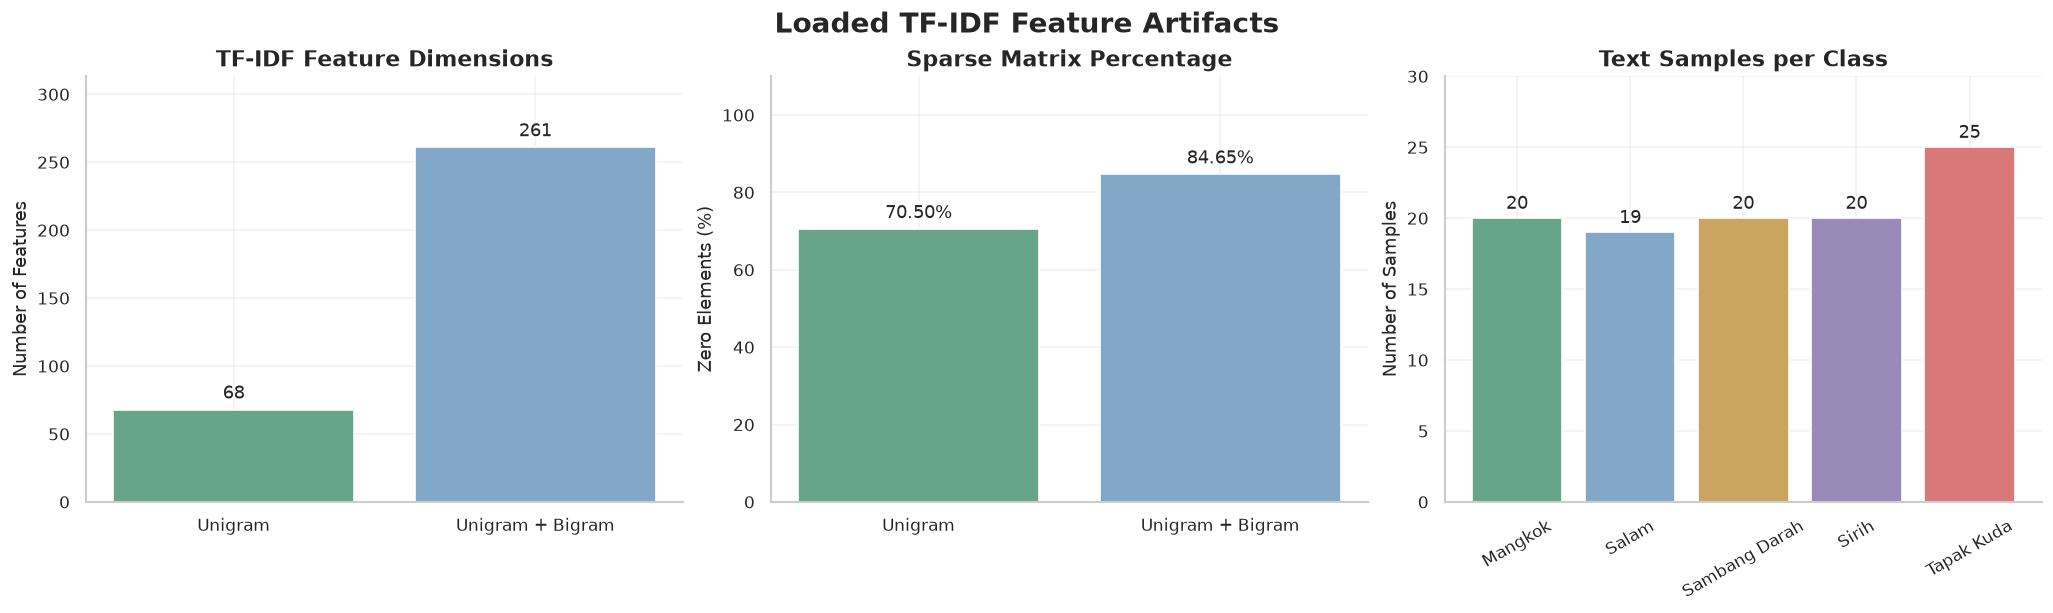

[SAVED] 106_loaded_text_feature_summary.png


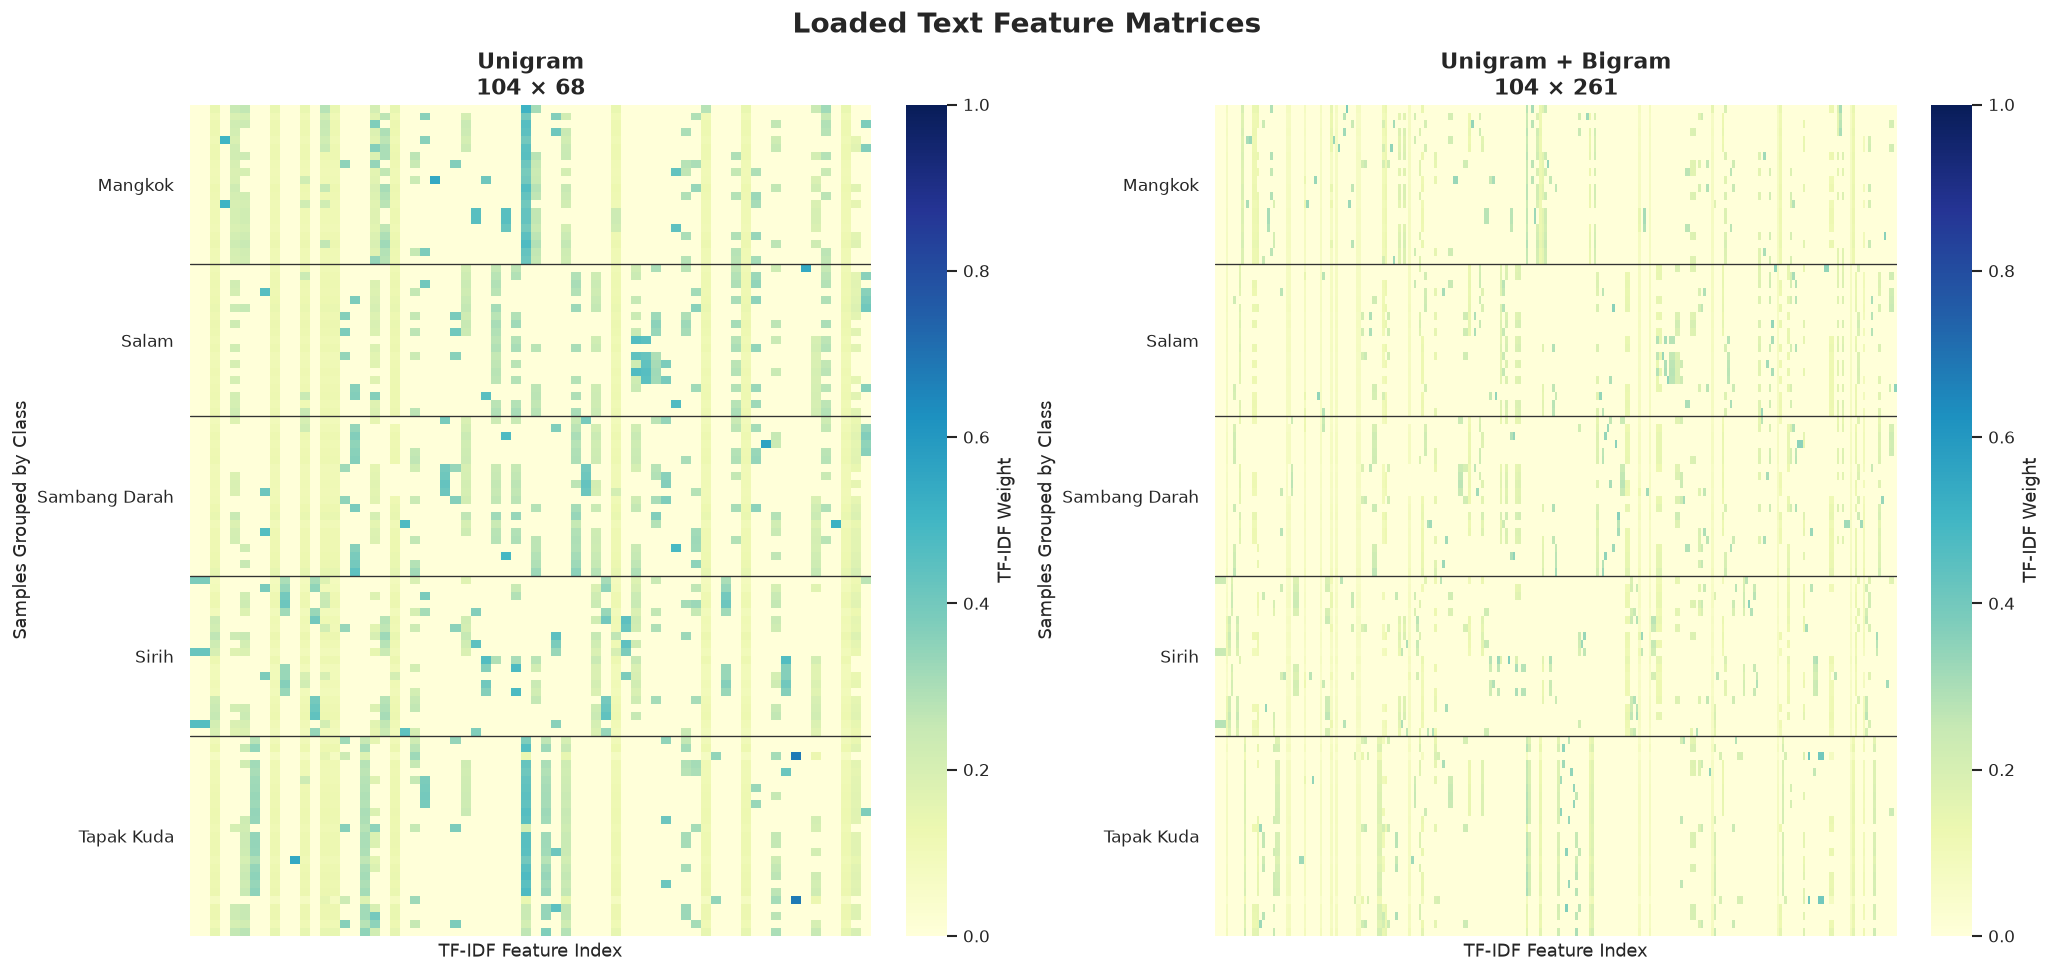

[SAVED] 107_loaded_text_feature_matrices.png

10. TEXT LOADING SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Total samples,104
1,Total classes,5
2,TF-IDF configurations,2
3,Unigram matrix shape,"(104, 68)"
4,Combined matrix shape,"(104, 261)"
5,Verified payload artifacts,16
6,Aligned samples,104
7,Validation checks,80
8,Passed checks,80
9,Failed checks,0



11. SAVING TEXT LOADING REPORTS
----------------------------------------------------------------------
[SAVED] 368_text_artifact_integrity.csv
[SAVED] 369_loaded_text_matrix_summary.csv
[SAVED] 370_text_vocabulary_integrity.csv
[SAVED] 371_text_visual_identity_alignment.csv
[SAVED] 372_text_loading_validation.csv
[SAVED] 373_loaded_text_class_distribution.csv
[SAVED] 374_text_loading_summary.csv

FINAL TEXT FEATURE LOADING SUMMARY

DATASET INFORMATION
----------------------------------------------------------------------
Text samples      : 104
Visual samples    : 104
Aligned samples   : 104
Plant classes     : 5

TEXT FEATURE MATRICES
----------------------------------------------------------------------
Unigram features  : (104, 68)
Combined features : (104, 261)

ARTIFACT INFORMATION
----------------------------------------------------------------------
Verified payloads : 16/16
Loaded vectorizers: 2

VALIDATION
----------------------------------------------------------------------

In [6]:
# ============================================================
# CELL 5 - LOAD TEXT FEATURE ARTIFACTS
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer

print("MULTIMODAL FUSION - LOAD TEXT FEATURE ARTIFACTS")
print("=" * 70)

TEXT_FEATURE_LOADING_COMPLETED = False
TEXT_FEATURES_LOADED = False

# ============================================================
# 1. VALIDATE PREVIOUS CELLS
# ============================================================

assert FUSION_LIBRARIES_IMPORTED is True
assert FUSION_PATH_CONFIGURATION_COMPLETED is True
assert VISUAL_FEATURE_LOADING_COMPLETED is True, (
    "Run Cell 4 successfully before Cell 5."
)

assert fusion_path_validation_df["passed"].all()
assert visual_loading_validation_df["passed"].all()

TEXT_LOADING_TOLERANCE = 1e-10
TEXT_EXPECTED_SAMPLES = 104

TEXT_EXPECTED_DIMENSIONS = {
    "Unigram": 68,
    "Unigram + Bigram": 261
}

TEXT_CONFIGURATION_ORDER = [
    "Unigram",
    "Unigram + Bigram"
]

TEXT_CONFIGURATION_COLORS = {
    "Unigram": "#66A58A",
    "Unigram + Bigram": "#83A7C7"
}

text_loading_checks = []
text_loading_figures = []

def check_text_loading(category, name, condition):
    text_loading_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(condition)
    })

def sha256_text_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(65536), b""):
            digest.update(chunk)
    return digest.hexdigest()

def maximum_sparse_difference(a, b):
    assert a.shape == b.shape
    delta = (a - b).tocsr()
    delta.eliminate_zeros()
    return (
        float(np.max(np.abs(delta.data)))
        if delta.nnz else 0.0
    )

print("[PASS] Previous cells validated.")


# ============================================================
# 2. PREPARE EXPECTED ARTIFACT PATHS
# ============================================================

# Use only paths established in Cell 3.
# Never load files using unvalidated paths from CSV.

text_expected_payload_paths = {}

for config_name in TEXT_CONFIGURATION_ORDER:
    for artifact_name, path in TEXT_ARTIFACT_PATHS[
        config_name
    ].items():
        text_expected_payload_paths[path.name] = path

for artifact_name, path in TEXT_SHARED_ARTIFACT_PATHS.items():
    if artifact_name != "manifest":
        text_expected_payload_paths[path.name] = path

assert len(text_expected_payload_paths) == 16
assert TEXT_MANIFEST_PATH.is_file()

print("\n1. TEXT ARTIFACT LOCATIONS")
print("-" * 70)
print("Text feature directory:", TEXT_FEATURES_DIR)
print("Expected payload files :", len(text_expected_payload_paths))
print("Manifest              :", TEXT_MANIFEST_PATH.name)


# ============================================================
# 3. LOAD AND VALIDATE TEXT MANIFEST
# ============================================================

loaded_text_manifest_df = pd.read_csv(
    TEXT_MANIFEST_PATH,
    dtype={
        "filename": str,
        "relative_path": str,
        "sha256": str
    },
    keep_default_na=False
)

manifest_columns = {
    "filename",
    "relative_path",
    "size_bytes",
    "sha256"
}

assert manifest_columns.issubset(
    loaded_text_manifest_df.columns
)

assert loaded_text_manifest_df["filename"].is_unique

expected_filenames = set(text_expected_payload_paths)
manifest_filenames = set(
    loaded_text_manifest_df["filename"]
)

assert manifest_filenames == expected_filenames, (
    "Manifest content does not match the 16 "
    "expected text payload artifacts."
)

loaded_text_manifest_df["size_bytes"] = pd.to_numeric(
    loaded_text_manifest_df["size_bytes"],
    errors="raise"
)

text_manifest_index = loaded_text_manifest_df.set_index(
    "filename"
)

check_text_loading(
    "Manifest",
    "Manifest covers all expected text artifacts",
    manifest_filenames == expected_filenames
)

print("[PASS] Text artifact manifest loaded.")


# ============================================================
# 4. VERIFY FILE INTEGRITY BEFORE JOBLIB LOADING
# ============================================================

text_artifact_integrity_records = []

print("\n2. TEXT ARTIFACT INTEGRITY")
print("-" * 70)

for filename, path in text_expected_payload_paths.items():

    manifest_row = text_manifest_index.loc[filename]

    exists = path.is_file()

    actual_size = (
        path.stat().st_size if exists else 0
    )

    actual_sha256 = (
        sha256_text_file(path) if exists else ""
    )

    expected_size = int(manifest_row["size_bytes"])

    expected_sha256 = str(
        manifest_row["sha256"]
    ).strip().lower()

    expected_relative_path = path.relative_to(
        PROJECT_ROOT
    ).as_posix()

    relative_path_match = (
        str(manifest_row["relative_path"])
        == expected_relative_path
    )

    size_match = actual_size == expected_size

    checksum_match = (
        actual_sha256 == expected_sha256
    )

    passed = (
        exists
        and actual_size > 0
        and size_match
        and checksum_match
        and relative_path_match
    )

    text_artifact_integrity_records.append({
        "filename": filename,
        "exists": exists,
        "size_bytes": actual_size,
        "size_match": size_match,
        "checksum_match": checksum_match,
        "relative_path_match": relative_path_match,
        "passed": passed
    })

    check_text_loading(
        "Artifact Integrity",
        f"{filename} integrity",
        passed
    )

    print(
        f"[{'PASS' if passed else 'FAIL'}] {filename}"
    )

text_artifact_integrity_df = pd.DataFrame(
    text_artifact_integrity_records
)

text_artifact_integrity_df.to_csv(
    METRICS_DIR / "368_text_artifact_integrity.csv",
    index=False,
    encoding="utf-8-sig"
)

# IMPORTANT: Do not unpickle Joblib files
# if their integrity check fails.
assert text_artifact_integrity_df["passed"].all(), (
    "Artifact integrity verification failed."
)

print("[PASS] 16 text payload artifacts verified.")


# ============================================================
# 5. LOAD SHARED TEXT ARTIFACTS
# ============================================================

loaded_text_sample_ids = np.asarray(
    np.load(
        TEXT_SAMPLE_IDS_PATH,
        allow_pickle=False
    ),
    dtype=str
)

loaded_text_class_labels = np.asarray(
    np.load(
        TEXT_CLASS_LABELS_PATH,
        allow_pickle=False
    ),
    dtype=str
)

loaded_text_metadata_df = pd.read_csv(
    MULTIMODAL_METADATA_PATH,
    dtype={"sample_id": str},
    keep_default_na=False
)

with open(
    TEXT_CORPUS_PATH,
    "r",
    encoding="utf-8"
) as file:
    loaded_text_corpus_payload = json.load(file)

with open(
    TEXT_PREPROCESSING_CONFIG_PATH,
    "r",
    encoding="utf-8"
) as file:
    loaded_text_preprocessing_config = json.load(file)

with open(
    TEXT_CONFIG_PATH,
    "r",
    encoding="utf-8"
) as file:
    loaded_text_feature_config = json.load(file)

loaded_text_corpus = list(
    loaded_text_corpus_payload["descriptions"]
)

loaded_text_n_samples = len(
    loaded_text_sample_ids
)

print("\n3. SHARED TEXT ARTIFACTS")
print("-" * 70)

print("Sample IDs       :", loaded_text_sample_ids.shape)
print("Class labels     :", loaded_text_class_labels.shape)
print("Text corpus      :", len(loaded_text_corpus))
print("Metadata         :", loaded_text_metadata_df.shape)
print("Preprocessing    : Loaded")
print("Feature config   : Loaded")


# ============================================================
# 6. VALIDATE SAMPLE IDENTITIES AND METADATA
# ============================================================

assert loaded_text_n_samples == TEXT_EXPECTED_SAMPLES

assert len(loaded_text_class_labels) == (
    loaded_text_n_samples
)

assert len(loaded_text_corpus) == (
    loaded_text_n_samples
)

assert len(loaded_text_metadata_df) == (
    loaded_text_n_samples
)

assert len(np.unique(
    loaded_text_sample_ids
)) == loaded_text_n_samples

assert all(
    isinstance(doc, str) and doc.strip()
    for doc in loaded_text_corpus
)

assert loaded_text_corpus_payload[
    "sample_ids"
] == loaded_text_sample_ids.tolist()

assert loaded_text_corpus_payload[
    "number_of_documents"
] == loaded_text_n_samples

required_metadata_columns = {
    "sample_id",
    "kelas",
    "cleaned_description",
    "image_text_alignment_valid"
}

assert required_metadata_columns.issubset(
    loaded_text_metadata_df.columns
)

text_metadata_ids = (
    loaded_text_metadata_df["sample_id"]
    .to_numpy(dtype=str)
)

text_metadata_labels = (
    loaded_text_metadata_df["kelas"]
    .to_numpy(dtype=str)
)

text_metadata_corpus = (
    loaded_text_metadata_df["cleaned_description"]
    .astype(str)
    .tolist()
)

text_alignment_status = (
    loaded_text_metadata_df[
        "image_text_alignment_valid"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
)

text_identity_checks = {
    "Sample IDs unique":
        len(np.unique(loaded_text_sample_ids))
        == loaded_text_n_samples,

    "Metadata sample order preserved":
        np.array_equal(
            text_metadata_ids,
            loaded_text_sample_ids
        ),

    "Metadata labels preserved":
        np.array_equal(
            text_metadata_labels,
            loaded_text_class_labels
        ),

    "Metadata descriptions preserved":
        text_metadata_corpus == loaded_text_corpus,

    "Text corpus sample IDs preserved":
        loaded_text_corpus_payload["sample_ids"]
        == loaded_text_sample_ids.tolist(),

    "Previous image-text alignment preserved":
        text_alignment_status.all(),

    "Visual and text sample IDs identical":
        np.array_equal(
            loaded_text_sample_ids,
            visual_sample_ids
        ),

    "Visual and text class labels identical":
        np.array_equal(
            loaded_text_class_labels,
            visual_labels
        )
}

text_identity_alignment_df = pd.DataFrame({
    "row_index": np.arange(loaded_text_n_samples),
    "sample_id": loaded_text_sample_ids,
    "kelas": loaded_text_class_labels,
    "visual_id_match": (
        loaded_text_sample_ids == visual_sample_ids
    ),
    "visual_label_match": (
        loaded_text_class_labels == visual_labels
    ),
    "metadata_id_match": (
        loaded_text_sample_ids == text_metadata_ids
    ),
    "metadata_label_match": (
        loaded_text_class_labels == text_metadata_labels
    ),
    "corpus_match": np.asarray([
        a == b for a, b in zip(
            loaded_text_corpus,
            text_metadata_corpus
        )
    ]),
    "alignment_flag": text_alignment_status.to_numpy()
})

alignment_columns = [
    "visual_id_match",
    "visual_label_match",
    "metadata_id_match",
    "metadata_label_match",
    "corpus_match",
    "alignment_flag"
]

text_identity_alignment_df["passed"] = (
    text_identity_alignment_df[
        alignment_columns
    ].all(axis=1)
)

for name, passed in text_identity_checks.items():
    check_text_loading("Sample Alignment", name, passed)

check_text_loading(
    "Sample Alignment",
    "All 104 sample-level alignment records passed",
    text_identity_alignment_df["passed"].all()
)

assert all(text_identity_checks.values()), (
    "Text and visual sample identity mismatch."
)

print("\n4. TEXT-VISUAL SAMPLE ALIGNMENT")
print("-" * 70)

print(
    "Aligned samples:",
    int(text_identity_alignment_df["passed"].sum()),
    "/",
    loaded_text_n_samples
)

display(text_identity_alignment_df.head(8))


# ============================================================
# 7. LOAD TF-IDF MATRICES AND VECTORIZERS
# ============================================================

loaded_text_vectorizers = {}
loaded_text_feature_matrices = {}
loaded_text_feature_names = {}
loaded_text_idf_weights = {}
loaded_text_vocabulary_reports = {}

text_matrix_summary_records = []
text_vocabulary_validation_records = []

print("\n5. LOADING TF-IDF CONFIGURATIONS")
print("-" * 70)

for configuration_name in TEXT_CONFIGURATION_ORDER:

    artifact_paths = TEXT_ARTIFACT_PATHS[
        configuration_name
    ]

    vectorizer = joblib.load(
        artifact_paths["vectorizer"]
    )

    feature_matrix = load_npz(
        artifact_paths["matrix"]
    ).tocsr()

    feature_names = np.load(
        artifact_paths["feature_names"],
        allow_pickle=False
    )

    idf_weights = np.load(
        artifact_paths["idf_weights"],
        allow_pickle=False
    )

    vocabulary_df = pd.read_csv(
        artifact_paths["vocabulary"],
        dtype={"term": str},
        keep_default_na=False,
        float_precision="round_trip"
    )

    loaded_text_vectorizers[
        configuration_name
    ] = vectorizer

    loaded_text_feature_matrices[
        configuration_name
    ] = feature_matrix

    loaded_text_feature_names[
        configuration_name
    ] = feature_names

    loaded_text_idf_weights[
        configuration_name
    ] = idf_weights

    loaded_text_vocabulary_reports[
        configuration_name
    ] = vocabulary_df

    expected_dimension = (
        TEXT_EXPECTED_DIMENSIONS[configuration_name]
    )

    expected_ngram_range = (
        (1, 1)
        if configuration_name == "Unigram"
        else (1, 2)
    )

    # ----------------------------------------------
    # A. Verify matrix properties
    # ----------------------------------------------

    row_norms = np.sqrt(
        np.asarray(
            feature_matrix.multiply(
                feature_matrix
            ).sum(axis=1)
        ).ravel()
    )

    matrix_checks = {
        "Matrix shape":
            feature_matrix.shape
            == (
                TEXT_EXPECTED_SAMPLES,
                expected_dimension
            ),

        "CSR sparse format":
            issparse(feature_matrix)
            and feature_matrix.format == "csr",

        "Float64 dtype":
            feature_matrix.dtype == np.float64,

        "Finite matrix values":
            np.isfinite(
                feature_matrix.data
            ).all(),

        "Nonnegative TF-IDF weights":
            np.all(
                feature_matrix.data >= 0
            ),

        "No zero document vectors":
            np.all(
                row_norms > 0
            ),

        "Unit L2 row normalization":
            np.allclose(
                row_norms,
                1.0,
                atol=TEXT_LOADING_TOLERANCE,
                rtol=0
            )
    }

    # ----------------------------------------------
    # B. Verify vectorizer properties
    # ----------------------------------------------

    vectorizer_feature_names = (
        vectorizer.get_feature_names_out()
    )

    vectorizer_checks = {
        "TF-IDF vectorizer type":
            isinstance(
                vectorizer,
                TfidfVectorizer
            ),

        "Vectorizer fitted":
            hasattr(vectorizer, "vocabulary_")
            and hasattr(vectorizer, "idf_"),

        "N-gram configuration":
            vectorizer.ngram_range
            == expected_ngram_range,

        "Vectorizer uses L2":
            vectorizer.norm == "l2",

        "Vocabulary dimension":
            len(vectorizer.vocabulary_)
            == expected_dimension,

        "Saved feature names identical":
            np.array_equal(
                feature_names,
                vectorizer_feature_names
            ),

        "Saved IDF weights identical":
            np.array_equal(
                idf_weights,
                vectorizer.idf_
            ),

        "IDF values finite and positive":
            np.isfinite(idf_weights).all()
            and np.all(idf_weights > 0)
    }

    # ----------------------------------------------
    # C. Verify vocabulary report
    # ----------------------------------------------

    vocabulary_required_columns = {
        "feature_index",
        "term",
        "ngram_type",
        "document_frequency",
        "idf_weight"
    }

    assert vocabulary_required_columns.issubset(
        vocabulary_df.columns
    )

    report_indices = pd.to_numeric(
        vocabulary_df["feature_index"],
        errors="raise"
    ).to_numpy()

    actual_document_frequency = np.asarray(
        (feature_matrix != 0).sum(axis=0)
    ).ravel()

    vocabulary_checks = {
        "Vocabulary report length":
            len(vocabulary_df)
            == expected_dimension,

        "Feature indices sequential":
            np.array_equal(
                report_indices,
                np.arange(expected_dimension)
            ),

        "Vocabulary terms match":
            np.array_equal(
                vocabulary_df["term"]
                .to_numpy(dtype=str),
                vectorizer_feature_names
            ),

        "Vocabulary IDF matches":
            np.allclose(
                vocabulary_df["idf_weight"]
                .to_numpy(dtype=float),
                idf_weights,
                atol=TEXT_LOADING_TOLERANCE,
                rtol=0
            ),

        "Document frequency matches":
            np.array_equal(
                vocabulary_df["document_frequency"]
                .to_numpy(dtype=int),
                actual_document_frequency
            ),

        "Vocabulary index mapping matches":
            all(
                vectorizer.vocabulary_.get(
                    term
                ) == index
                for index, term in enumerate(
                    vectorizer_feature_names
                )
            )
    }

    # ----------------------------------------------
    # D. Reproduce reference matrix
    # ----------------------------------------------

    reproduced_matrix = (
        vectorizer.transform(
            loaded_text_corpus
        ).tocsr()
    )

    reproduction_difference = (
        maximum_sparse_difference(
            reproduced_matrix,
            feature_matrix
        )
    )

    check_text_loading(
        configuration_name,
        "Reference matrix reproduced by transform()",
        reproduction_difference
        <= TEXT_LOADING_TOLERANCE
    )

    for checks in [
        matrix_checks,
        vectorizer_checks,
        vocabulary_checks
    ]:
        for name, passed in checks.items():
            check_text_loading(
                configuration_name,
                name,
                passed
            )

    # ----------------------------------------------
    # E. Save matrix statistics
    # ----------------------------------------------

    total_elements = (
        feature_matrix.shape[0]
        * feature_matrix.shape[1]
    )

    nonzero_values = int(
        feature_matrix.count_nonzero()
    )

    unigram_features = int(sum(
        " " not in term
        for term in vectorizer_feature_names
    ))

    bigram_features = int(sum(
        " " in term
        for term in vectorizer_feature_names
    ))

    text_matrix_summary_records.append({
        "configuration": configuration_name,
        "samples": feature_matrix.shape[0],
        "feature_dimension": feature_matrix.shape[1],
        "unigram_features": unigram_features,
        "bigram_features": bigram_features,
        "nonzero_values": nonzero_values,
        "zero_values": (
            total_elements - nonzero_values
        ),
        "sparsity_percent": (
            100 * (1 - nonzero_values / total_elements)
        ),
        "minimum_l2_norm": float(
            row_norms.min()
        ),
        "maximum_l2_norm": float(
            row_norms.max()
        ),
        "reproduction_max_difference": (
            reproduction_difference
        ),
        "matrix_file_kib": (
            artifact_paths["matrix"].stat().st_size
            / 1024
        ),
        "vectorizer_file_kib": (
            artifact_paths["vectorizer"].stat().st_size
            / 1024
        )
    })

    text_vocabulary_validation_records.append({
        "configuration": configuration_name,
        "vocabulary_size": len(
            vectorizer.vocabulary_
        ),
        "feature_names_match": (
            vectorizer_checks[
                "Saved feature names identical"
            ]
        ),
        "idf_match": (
            vectorizer_checks[
                "Saved IDF weights identical"
            ]
        ),
        "document_frequency_match": (
            vocabulary_checks[
                "Document frequency matches"
            ]
        ),
        "reference_matrix_reproduced": (
            reproduction_difference
            <= TEXT_LOADING_TOLERANCE
        )
    })

    print(f"\nConfiguration: {configuration_name}")
    print("Matrix shape :", feature_matrix.shape)
    print("Nonzero      :", nonzero_values)
    print("Unigram      :", unigram_features)
    print("Bigram       :", bigram_features)
    print(
        "Reproduction difference:",
        f"{reproduction_difference:.3e}"
    )

text_loaded_matrix_summary_df = pd.DataFrame(
    text_matrix_summary_records
)

text_vocabulary_integrity_df = pd.DataFrame(
    text_vocabulary_validation_records
)

print("\n6. LOADED TEXT MATRIX SUMMARY")
print("-" * 70)

display(
    text_loaded_matrix_summary_df.round(6)
)


# ============================================================
# 8. CREATE MAIN TEXT FEATURE VARIABLES
# ============================================================

tfidf_unigram_vectorizer = (
    loaded_text_vectorizers["Unigram"]
)

tfidf_combined_vectorizer = (
    loaded_text_vectorizers["Unigram + Bigram"]
)

tfidf_unigram_features = (
    loaded_text_feature_matrices["Unigram"]
)

tfidf_combined_features = (
    loaded_text_feature_matrices["Unigram + Bigram"]
)

text_feature_matrices = (
    loaded_text_feature_matrices
)

text_vectorizers = (
    loaded_text_vectorizers
)

text_sample_ids = (
    loaded_text_sample_ids
)

text_labels = (
    loaded_text_class_labels
)

text_corpus = (
    loaded_text_corpus
)

text_n_samples = (
    len(text_sample_ids)
)

text_class_names = sorted(
    np.unique(text_labels)
)

print("\n7. MAIN TEXT FEATURE VARIABLES")
print("-" * 70)

print("Unigram features :", tfidf_unigram_features.shape)
print("Combined features:", tfidf_combined_features.shape)
print("Text sample IDs  :", text_sample_ids.shape)
print("Text labels      :", text_labels.shape)


# ============================================================
# 9. CLASS DISTRIBUTION
# ============================================================

text_loaded_class_summary_df = (
    pd.Series(text_labels, name="kelas")
    .value_counts()
    .sort_index()
    .rename_axis("kelas")
    .reset_index(name="number_of_samples")
)

text_loaded_class_summary_df["percentage"] = (
    100
    * text_loaded_class_summary_df["number_of_samples"]
    / text_n_samples
)

expected_class_counts = {
    "Mangkok": 20,
    "Salam": 19,
    "Sambang Darah": 20,
    "Sirih": 20,
    "Tapak Kuda": 25
}

actual_class_counts = dict(zip(
    text_loaded_class_summary_df["kelas"],
    text_loaded_class_summary_df["number_of_samples"]
))

check_text_loading(
    "Class Distribution",
    "Five-class distribution preserved",
    actual_class_counts == expected_class_counts
)

print("\n8. CLASS DISTRIBUTION")
print("-" * 70)

display(
    text_loaded_class_summary_df.round(4)
)


# ============================================================
# 10. FEATURE CONFIGURATION VALIDATION
# ============================================================

saved_configurations = loaded_text_feature_config.get(
    "configurations",
    {}
)

for configuration_name in TEXT_CONFIGURATION_ORDER:

    assert configuration_name in saved_configurations

    saved_info = saved_configurations[
        configuration_name
    ]

    loaded_matrix = loaded_text_feature_matrices[
        configuration_name
    ]

    check_text_loading(
        "Saved Configuration",
        f"{configuration_name} feature dimension",
        int(saved_info["feature_dimension"])
        == loaded_matrix.shape[1]
    )

    check_text_loading(
        "Saved Configuration",
        f"{configuration_name} matrix shape",
        tuple(saved_info["matrix_shape"])
        == loaded_matrix.shape
    )

    check_text_loading(
        "Saved Configuration",
        f"{configuration_name} nonzero count",
        int(saved_info["nonzero_values"])
        == loaded_matrix.nnz
    )

check_text_loading(
    "Saved Configuration",
    "Sample count preserved",
    loaded_text_feature_config[
        "number_of_samples"
    ] == text_n_samples
)

check_text_loading(
    "Saved Configuration",
    "Reference-only evaluation requirement preserved",
    loaded_text_feature_config[
        "evaluation_requires_reference_only_refit"
    ] is True
)

check_text_loading(
    "Saved Configuration",
    "No final text configuration selected",
    loaded_text_feature_config[
        "final_text_configuration_selected"
    ] is False
)


# ============================================================
# 11. FINAL TEXT LOADING VALIDATION
# ============================================================

text_loading_validation_df = pd.DataFrame(
    text_loading_checks
)

text_loading_validation_df["status"] = np.where(
    text_loading_validation_df["passed"],
    "Passed",
    "Failed"
)

text_loading_total_checks = len(
    text_loading_validation_df
)

text_loading_passed_checks = int(
    text_loading_validation_df["passed"].sum()
)

text_loading_failed_checks = (
    text_loading_total_checks
    - text_loading_passed_checks
)

print("\n9. TEXT FEATURE LOADING VALIDATION")
print("-" * 70)

display(text_loading_validation_df)

assert text_loading_validation_df["passed"].all(), (
    text_loading_validation_df.loc[
        ~text_loading_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All text loading checks passed.")


# ============================================================
# 12. VISUALIZATION — TEXT FEATURE SUMMARY
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True
)

plot_df = (
    text_loaded_matrix_summary_df
    .set_index("configuration")
    .loc[TEXT_CONFIGURATION_ORDER]
)

colors = [
    TEXT_CONFIGURATION_COLORS[name]
    for name in TEXT_CONFIGURATION_ORDER
]

# A. Feature dimensions.

bars = axes[0].bar(
    TEXT_CONFIGURATION_ORDER,
    plot_df["feature_dimension"],
    color=colors
)

axes[0].bar_label(bars, padding=4)
axes[0].set_title("TF-IDF Feature Dimensions")
axes[0].set_ylabel("Number of Features")
axes[0].margins(y=0.2)

# B. Matrix sparsity.

bars = axes[1].bar(
    TEXT_CONFIGURATION_ORDER,
    plot_df["sparsity_percent"],
    color=colors
)

axes[1].bar_label(
    bars,
    fmt="%.2f%%",
    padding=4
)

axes[1].set_ylim(0, 110)
axes[1].set_title("Sparse Matrix Percentage")
axes[1].set_ylabel("Zero Elements (%)")

# C. Class distribution.

class_colors = [
    CLASS_COLORS.get(name, "#83A7C7")
    for name in text_loaded_class_summary_df["kelas"]
]

bars = axes[2].bar(
    text_loaded_class_summary_df["kelas"],
    text_loaded_class_summary_df["number_of_samples"],
    color=class_colors
)

axes[2].bar_label(bars, padding=3)
axes[2].tick_params(axis="x", rotation=30)
axes[2].set_title("Text Samples per Class")
axes[2].set_ylabel("Number of Samples")
axes[2].margins(y=0.2)

fig.suptitle(
    "Loaded TF-IDF Feature Artifacts",
    fontsize=17,
    fontweight="bold"
)

figure_path = (
    FUSION_FIGURES_DIR
    / "106_loaded_text_feature_summary.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

text_loading_figures.append(figure_path)

plt.show()
plt.close(fig)

print(f"[SAVED] {figure_path.name}")


# ============================================================
# 13. VISUALIZATION — TF-IDF FEATURE MATRICES
# ============================================================

plot_order = np.argsort(
    text_labels,
    kind="stable"
)

sorted_labels = text_labels[plot_order]

class_boundaries = np.flatnonzero(
    sorted_labels[1:] != sorted_labels[:-1]
) + 1

class_starts = np.r_[0, class_boundaries]
class_ends = np.r_[
    class_boundaries,
    text_n_samples
]

class_centers = (
    class_starts + class_ends
) / 2

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 8),
    constrained_layout=True
)

for ax, configuration_name in zip(
    axes,
    TEXT_CONFIGURATION_ORDER
):

    matrix = loaded_text_feature_matrices[
        configuration_name
    ]

    # Dense conversion is for plotting only.
    # Stored matrices remain sparse CSR.
    plot_matrix = matrix[plot_order].toarray()

    sns.heatmap(
        plot_matrix,
        cmap="YlGnBu",
        vmin=0,
        vmax=1,
        xticklabels=False,
        yticklabels=False,
        cbar_kws={"label": "TF-IDF Weight"},
        ax=ax
    )

    for boundary in class_boundaries:
        ax.axhline(
            boundary,
            color="#333333",
            linewidth=0.8
        )

    ax.set_yticks(class_centers)

    ax.set_yticklabels(
        sorted_labels[class_starts],
        rotation=0
    )

    ax.set_title(
        f"{configuration_name}\n"
        f"{matrix.shape[0]} × {matrix.shape[1]}"
    )

    ax.set_xlabel("TF-IDF Feature Index")
    ax.set_ylabel("Samples Grouped by Class")

fig.suptitle(
    "Loaded Text Feature Matrices",
    fontsize=17,
    fontweight="bold"
)

figure_path = (
    FUSION_FIGURES_DIR
    / "107_loaded_text_feature_matrices.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

text_loading_figures.append(figure_path)

plt.show()
plt.close(fig)

print(f"[SAVED] {figure_path.name}")


# ============================================================
# 14. CREATE FINAL LOADING SUMMARY
# ============================================================

text_loading_summary_df = pd.DataFrame([
    ("Total samples", text_n_samples),
    ("Total classes", len(text_class_names)),
    ("TF-IDF configurations", len(text_vectorizers)),
    ("Unigram matrix shape", str(tfidf_unigram_features.shape)),
    ("Combined matrix shape", str(tfidf_combined_features.shape)),
    ("Verified payload artifacts", int(
        text_artifact_integrity_df["passed"].sum()
    )),
    ("Aligned samples", int(
        text_identity_alignment_df["passed"].sum()
    )),
    ("Validation checks", text_loading_total_checks),
    ("Passed checks", text_loading_passed_checks),
    ("Failed checks", text_loading_failed_checks),
    ("Generated figures", len(text_loading_figures)),
    ("Vectorizers refitted", False),
    ("Sample order modified", False),
    ("Text configuration selected", False),
    ("Independent evaluation completed", False),
    ("Ready for multimodal validation", True)
], columns=["Indicator", "Result"])

print("\n10. TEXT LOADING SUMMARY")
print("-" * 70)

display(text_loading_summary_df)


# ============================================================
# 15. SAVE CELL 5 REPORTS
# ============================================================

text_loading_reports = {
    "368_text_artifact_integrity.csv":
        text_artifact_integrity_df,

    "369_loaded_text_matrix_summary.csv":
        text_loaded_matrix_summary_df,

    "370_text_vocabulary_integrity.csv":
        text_vocabulary_integrity_df,

    "371_text_visual_identity_alignment.csv":
        text_identity_alignment_df,

    "372_text_loading_validation.csv":
        text_loading_validation_df,

    "373_loaded_text_class_distribution.csv":
        text_loaded_class_summary_df,

    "374_text_loading_summary.csv":
        text_loading_summary_df
}

print("\n11. SAVING TEXT LOADING REPORTS")
print("-" * 70)

for filename, dataframe in text_loading_reports.items():

    output_path = METRICS_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ============================================================
# 16. FINAL COMPLETION CHECKS
# ============================================================

assert text_artifact_integrity_df["passed"].all()
assert text_loading_validation_df["passed"].all()
assert text_identity_alignment_df["passed"].all()

assert tfidf_unigram_features.shape == (104, 68)
assert tfidf_combined_features.shape == (104, 261)

assert np.array_equal(
    text_sample_ids,
    visual_sample_ids
)

assert np.array_equal(
    text_labels,
    visual_labels
)

assert len(text_loading_figures) == 2

assert all(
    path.is_file() and path.stat().st_size > 0
    for path in text_loading_figures
)

assert all(
    (METRICS_DIR / filename).is_file()
    for filename in text_loading_reports
)

TEXT_FEATURE_LOADING_COMPLETED = True
TEXT_FEATURES_LOADED = True


# ============================================================
# 17. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("FINAL TEXT FEATURE LOADING SUMMARY")
print("=" * 70)

print("\nDATASET INFORMATION")
print("-" * 70)
print(f"Text samples      : {text_n_samples}")
print(f"Visual samples    : {len(visual_sample_ids)}")
print(f"Aligned samples   : {text_identity_alignment_df['passed'].sum()}")
print(f"Plant classes     : {len(text_class_names)}")

print("\nTEXT FEATURE MATRICES")
print("-" * 70)
print("Unigram features  :", tfidf_unigram_features.shape)
print("Combined features :", tfidf_combined_features.shape)

print("\nARTIFACT INFORMATION")
print("-" * 70)
print(
    "Verified payloads :",
    f"{text_artifact_integrity_df['passed'].sum()}/"
    f"{len(text_artifact_integrity_df)}"
)
print("Loaded vectorizers:", len(loaded_text_vectorizers))

print("\nVALIDATION")
print("-" * 70)
print(
    "Technical checks  :",
    f"{text_loading_passed_checks}/{text_loading_total_checks}"
)
print("Failed checks     :", text_loading_failed_checks)
print("Generated reports :", len(text_loading_reports))
print("Generated figures :", len(text_loading_figures))

print("\n[PASS] Both TF-IDF matrices loaded.")
print("[PASS] Both fitted vectorizers loaded.")
print("[PASS] Vocabulary and IDF preserved.")
print("[PASS] Original corpus reproduced.")
print("[PASS] Text and visual samples aligned.")
print("[PASS] Sparse CSR and L2 normalization validated.")
print("[PASS] Artifact integrity verified.")
print("[PASS] No vectorizers were refitted.")

print("\n" + "=" * 70)
print("TEXT FEATURE LOADING COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nNext cell: Cell 6 - Multimodal Dataset Validation")

MULTIMODAL FUSION - DATASET VALIDATION
[PASS] Previous processing stages validated.

1. VALIDATION CONFIGURATION
----------------------------------------------------------------------
Expected samples: 104
Expected classes: 5
Tolerance       : 1e-10

2. MULTIMODAL FEATURE MATRICES
----------------------------------------------------------------------


,modality,number_of_samples,feature_dimension,expected_dimension,matrix_format,dtype,nonzero_values,zero_vector_rows,minimum_row_norm,maximum_row_norm,nan_values,infinite_values,passed
0,Visual,104,143,143,Dense,float64,14872,0,1.001982,4.092747,0,0,True
1,Text - Unigram,104,68,68,CSR,float64,2086,0,1.000000,1.000000,0,0,True
2,Text - Unigram + Bigram,104,261,261,CSR,float64,4166,0,1.000000,1.000000,0,0,True



3. SAMPLE ID INVENTORY
----------------------------------------------------------------------


,source,total_ids,unique_ids,duplicates,empty_ids,invalid_ids,missing_ids,extra_ids,passed
0,Visual Matrix,104,104,0,0,0,0,0,True
1,Text Matrix,104,104,0,0,0,0,0,True
2,Visual Metadata,104,104,0,0,0,0,0,True
3,Text Metadata,104,104,0,0,0,0,0,True
4,Processed Metadata,104,104,0,0,0,0,0,True



4. SAMPLE-LEVEL ALIGNMENT
----------------------------------------------------------------------
Aligned samples : 104/104
Failed samples  : 0


,row_index,sample_id,kelas,alignment_status
0,0,leaf_165d2f32c7fda707,Mangkok,Aligned
1,1,leaf_8473270c3702f48b,Mangkok,Aligned
2,2,leaf_8f425d66b1e193b9,Mangkok,Aligned
3,3,leaf_0ebc8f4f3ee9c8d5,Mangkok,Aligned
4,4,leaf_b0c5f55e42499cae,Mangkok,Aligned
5,5,leaf_de9e3e4ed5d89dfc,Mangkok,Aligned
6,6,leaf_23b789945271fb92,Mangkok,Aligned
7,7,leaf_84de0dc731018607,Mangkok,Aligned
8,8,leaf_36d4f083fa652592,Mangkok,Aligned
9,9,leaf_c9d8d87fbc748d16,Mangkok,Aligned


... (7 outputs left out)

,sample_id,kelas,nama_file,tampilan_daun,multimodal_alignment_validated,manual_review_pending
0,leaf_165d2f32c7fda707,Mangkok,mangkok 10.jpeg,belakang,True,True
1,leaf_8473270c3702f48b,Mangkok,mangkok 11.png,belakang,True,False
2,leaf_8f425d66b1e193b9,Mangkok,mangkok 12.png,belakang,True,False
3,leaf_0ebc8f4f3ee9c8d5,Mangkok,mangkok 13.png,belakang,True,False
4,leaf_b0c5f55e42499cae,Mangkok,mangkok 14.png,belakang,True,False
5,leaf_de9e3e4ed5d89dfc,Mangkok,mangkok 15.png,belakang,True,False
6,leaf_23b789945271fb92,Mangkok,mangkok 6.jpeg,belakang,True,True
7,leaf_84de0dc731018607,Mangkok,mangkok 7.jpeg,belakang,True,True
8,leaf_36d4f083fa652592,Mangkok,mangkok 8.jpeg,belakang,True,True
9,leaf_c9d8d87fbc748d16,Mangkok,mangkok 9.jpeg,belakang,True,True



9. IMAGE PATH AVAILABILITY
----------------------------------------------------------------------
Resolvable image files: 104/104

10. MULTIMODAL DATASET VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Feature Matrices,Visual expected dimensions,True,Passed
1,Feature Matrices,Visual finite values,True,Passed
2,Feature Matrices,Visual float64 dtype,True,Passed
3,Feature Matrices,Text - Unigram expected dimensions,True,Passed
4,Feature Matrices,Text - Unigram finite values,True,Passed
5,Feature Matrices,Text - Unigram float64 dtype,True,Passed
6,Feature Matrices,Text - Unigram CSR format,True,Passed
7,Feature Matrices,Text - Unigram nonnegative weights,True,Passed
8,Feature Matrices,Text - Unigram unit L2 row norm,True,Passed
9,Feature Matrices,Text - Unigram nonzero document vectors,True,Passed


[PASS] All required multimodal checks passed.


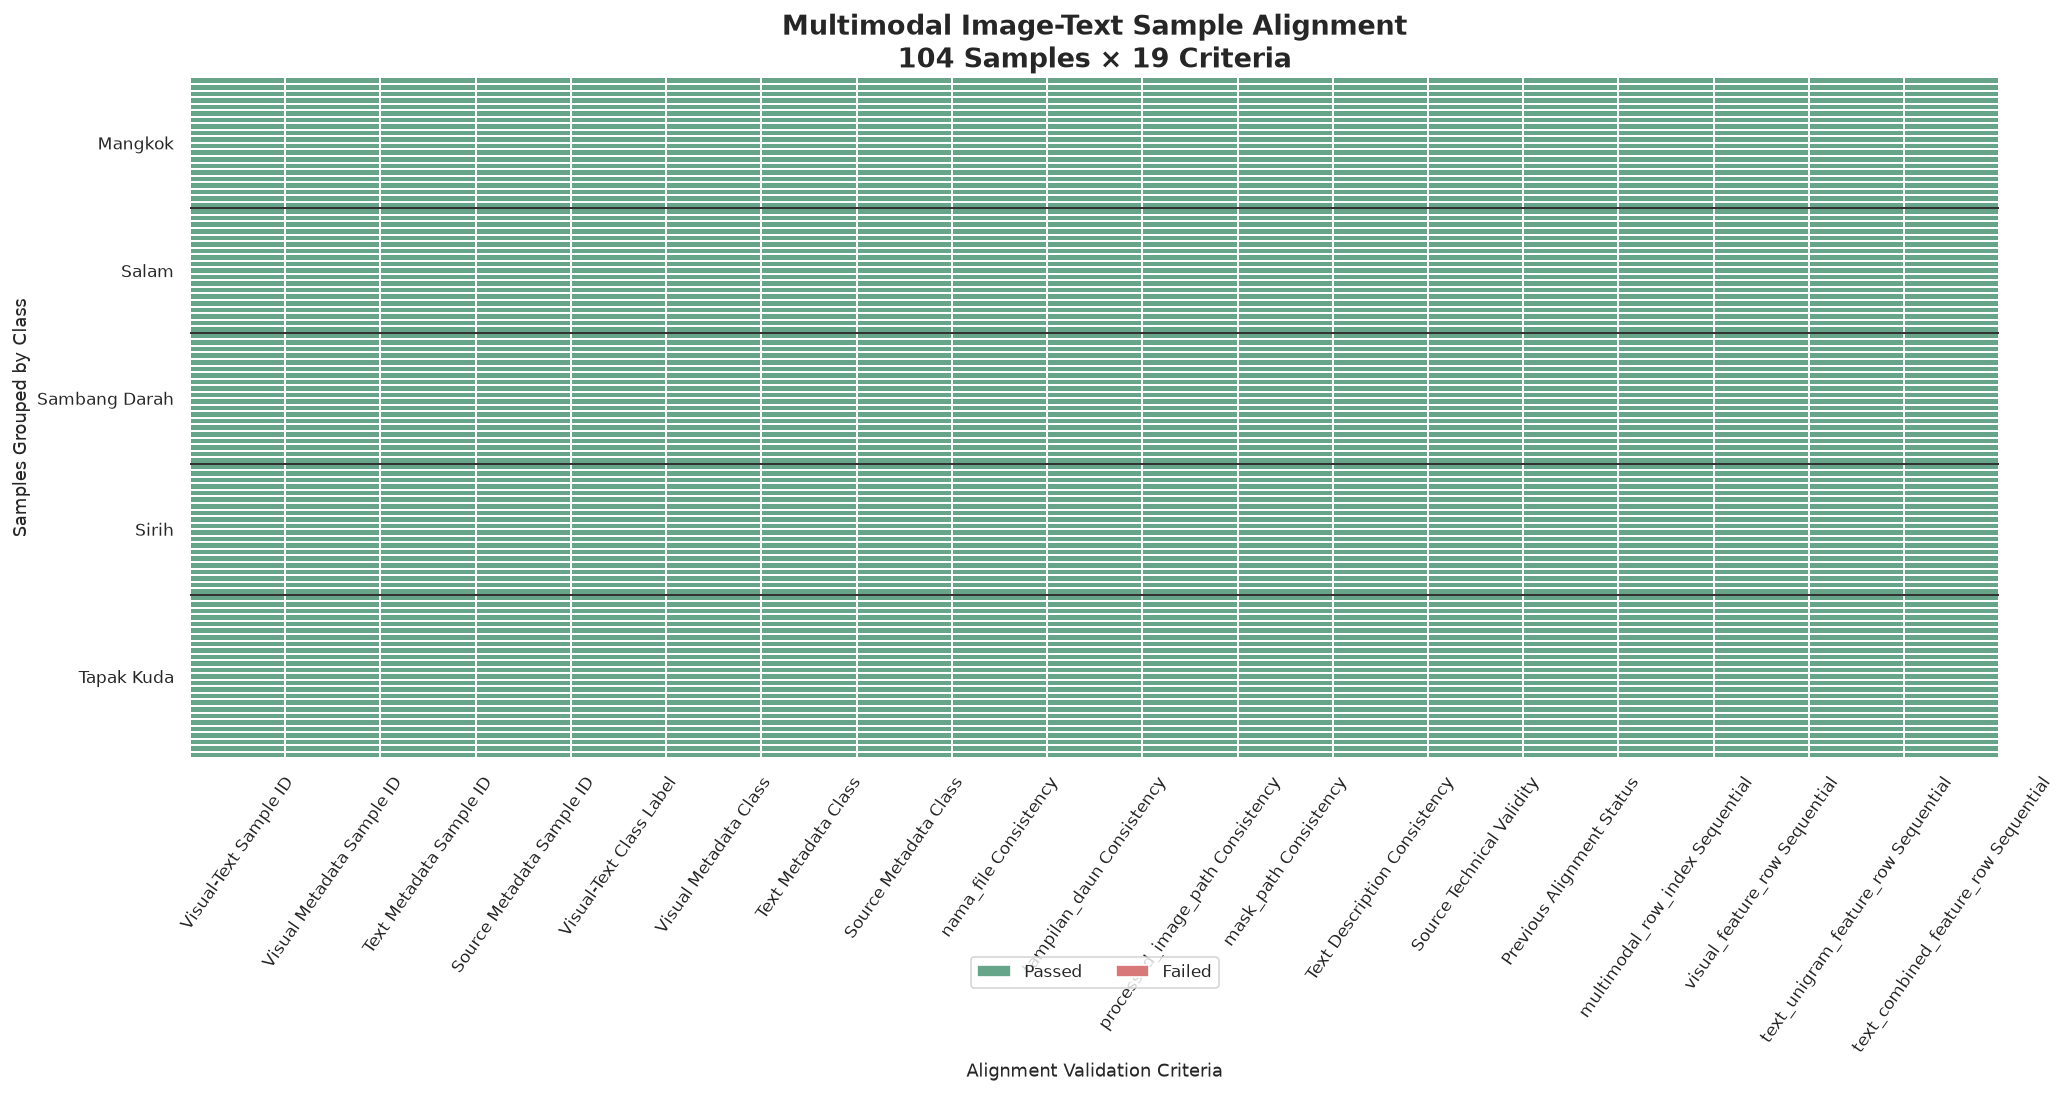

[SAVED] 108_multimodal_dataset_alignment_matrix.png


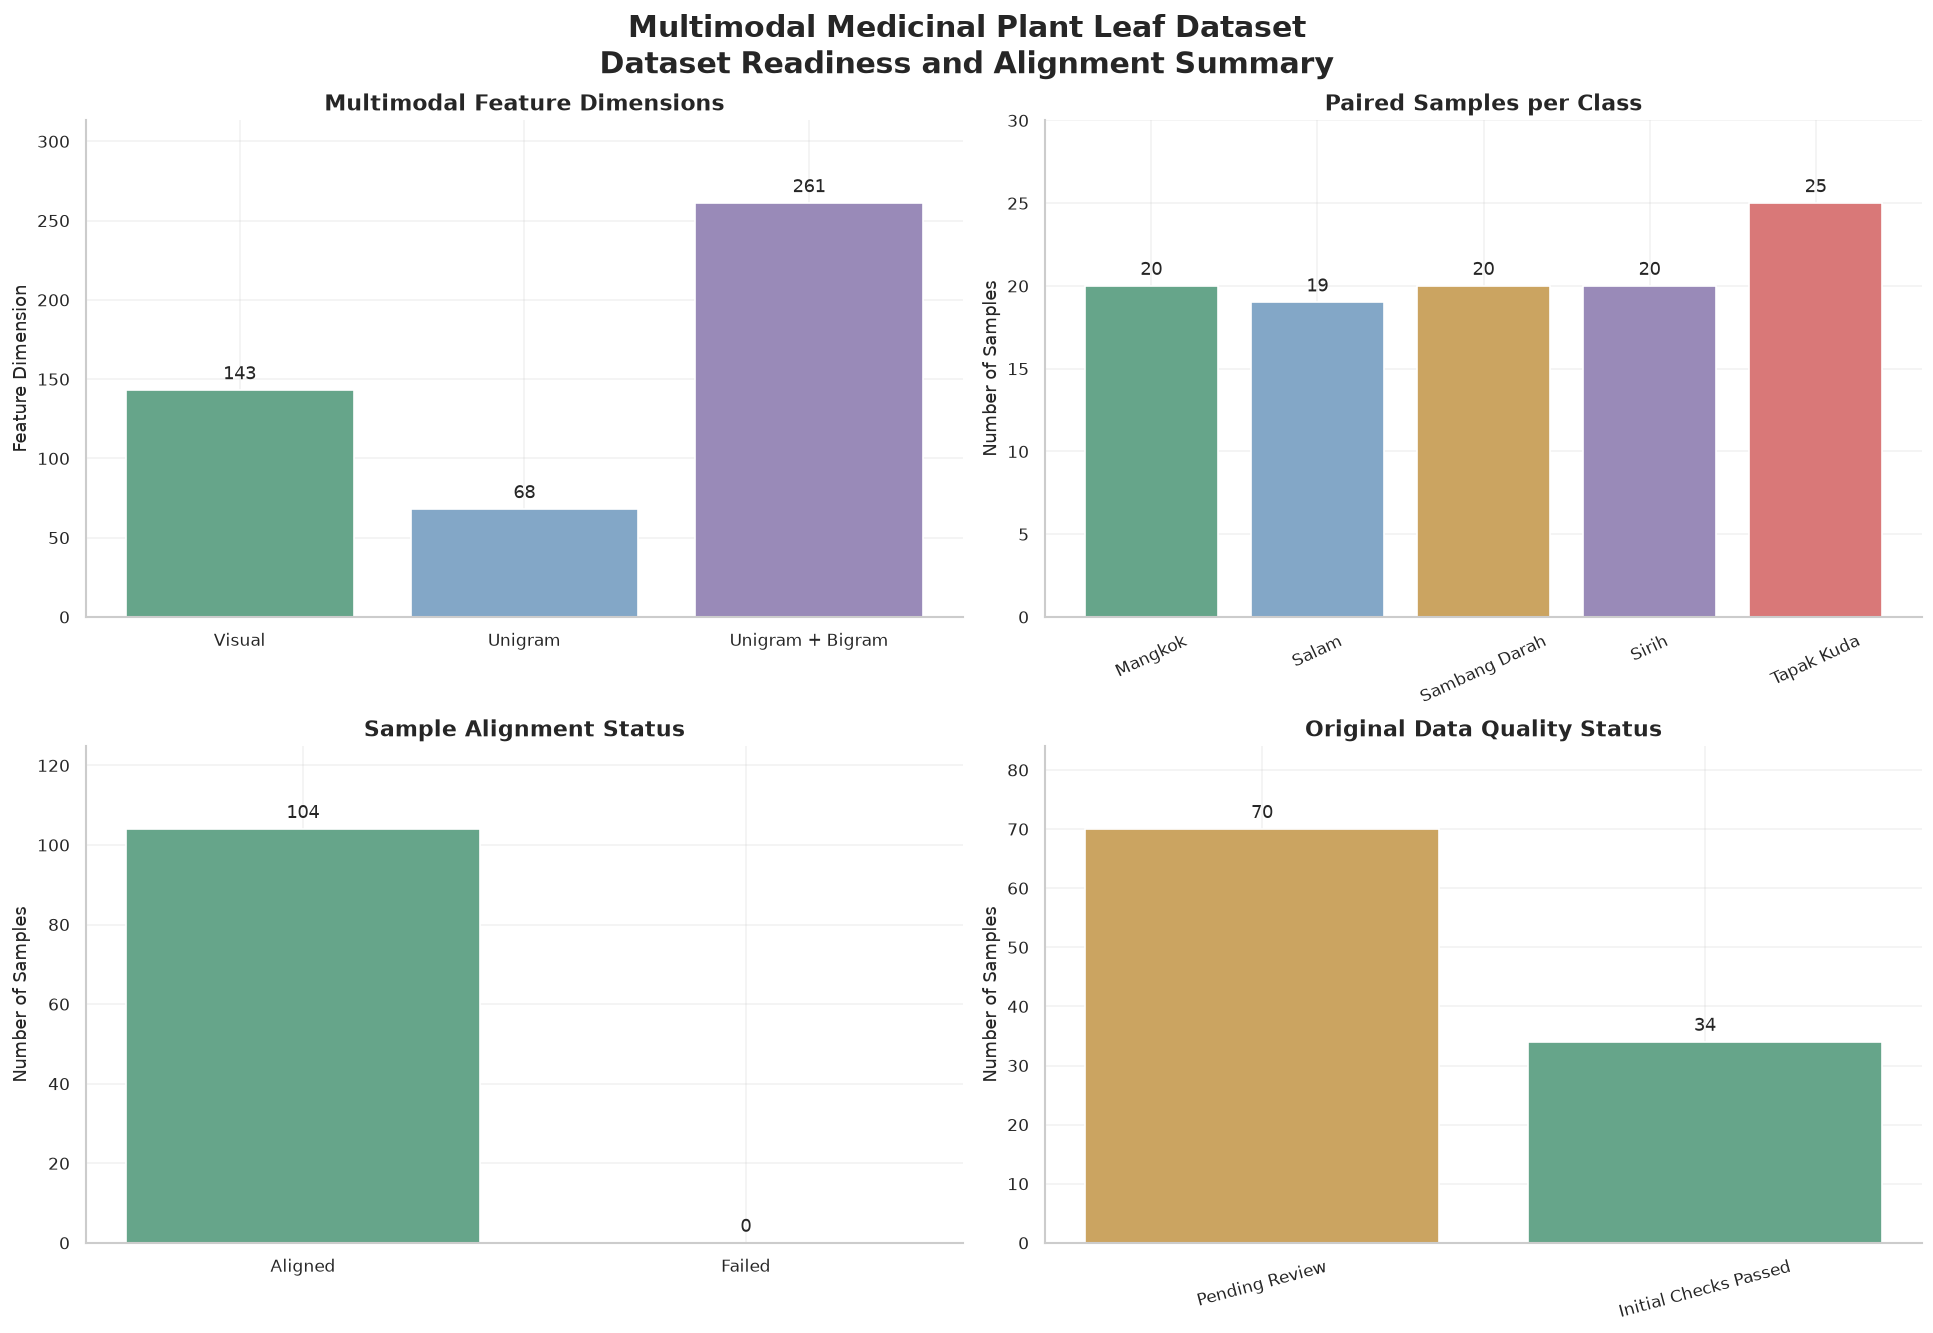

[SAVED] 109_multimodal_dataset_readiness_summary.png

11. FINAL MULTIMODAL DATASET SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Number of samples,104
1,Number of classes,5
2,Visual feature dimension,143
3,Unigram feature dimension,68
4,Combined feature dimension,261
5,Aligned samples,104
6,Failed alignment samples,0
7,Identity sources validated,5
8,Pending manual reviews,70
9,Exact duplicate text groups,8



12. SAVING VALIDATION REPORTS
----------------------------------------------------------------------
[SAVED] 375_multimodal_id_inventory.csv
[SAVED] 376_multimodal_sample_alignment.csv
[SAVED] 377_multimodal_feature_matrix_summary.csv
[SAVED] 378_multimodal_class_distribution.csv
[SAVED] 379_multimodal_quality_review_summary.csv
[SAVED] 380_multimodal_duplicate_descriptions.csv
[SAVED] 381_multimodal_dataset_validation.csv
[SAVED] 382_multimodal_dataset_summary.csv
[SAVED] 383_multimodal_image_path_diagnostics.csv
[SAVED] 384_multimodal_dataset_validation_handoff.json

FINAL MULTIMODAL DATASET VALIDATION SUMMARY

DATASET INFORMATION
----------------------------------------------------------------------
Total samples      : 104
Total classes      : 5
Aligned samples    : 104
Failed alignment   : 0

FEATURE MATRICES
----------------------------------------------------------------------
Visual features    : (104, 143)
Unigram features   : (104, 68)
Combined features  : (104, 261)

QUALIT

In [7]:
# ============================================================
# CELL 6 - MULTIMODAL DATASET VALIDATION
# ============================================================

import json
import hashlib
from pathlib import Path
from collections import Counter
from scipy.sparse import issparse
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

print("MULTIMODAL FUSION - DATASET VALIDATION")
print("=" * 70)

MULTIMODAL_DATASET_VALIDATION_COMPLETED = False
MULTIMODAL_DATASET_READY = False


# ============================================================
# 1. VALIDATE PREVIOUS CELLS
# ============================================================

required_stages = {
    "FUSION_LIBRARIES_IMPORTED":
        FUSION_LIBRARIES_IMPORTED,

    "FUSION_PATH_CONFIGURATION_COMPLETED":
        FUSION_PATH_CONFIGURATION_COMPLETED,

    "VISUAL_FEATURE_LOADING_COMPLETED":
        VISUAL_FEATURE_LOADING_COMPLETED,

    "TEXT_FEATURE_LOADING_COMPLETED":
        TEXT_FEATURE_LOADING_COMPLETED
}

for stage_name, completed in required_stages.items():
    assert completed is True, (
        f"{stage_name} is not completed."
    )

assert visual_loading_validation_df["passed"].all()
assert text_loading_validation_df["passed"].all()

print("[PASS] Previous processing stages validated.")


# ============================================================
# 2. MULTIMODAL DATASET CONFIGURATION
# ============================================================

MULTIMODAL_EXPECTED_SAMPLES = 104

MULTIMODAL_EXPECTED_DIMENSIONS = {
    "Visual": 143,
    "Text - Unigram": 68,
    "Text - Unigram + Bigram": 261
}

MULTIMODAL_EXPECTED_CLASS_COUNTS = {
    "Mangkok": 20,
    "Salam": 19,
    "Sambang Darah": 20,
    "Sirih": 20,
    "Tapak Kuda": 25
}

MULTIMODAL_VALIDATION_TOLERANCE = 1e-10

MULTIMODAL_VALIDATION_SCOPE = (
    "Full-Gallery Multimodal Dataset"
)

multimodal_validation_records = []
multimodal_validation_figures = []


def register_multimodal_check(
    category,
    name,
    condition
):
    multimodal_validation_records.append({
        "category": category,
        "validation_check": name,
        "passed": bool(condition),
        "status": (
            "Passed" if condition else "Failed"
        )
    })


def save_multimodal_validation_figure(
    figure,
    filename
):
    path = FUSION_FIGURES_DIR / filename

    figure.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    multimodal_validation_figures.append(path)

    plt.show()
    plt.close(figure)

    print(f"[SAVED] {filename}")


print("\n1. VALIDATION CONFIGURATION")
print("-" * 70)

print("Expected samples:", MULTIMODAL_EXPECTED_SAMPLES)
print("Expected classes:", len(MULTIMODAL_EXPECTED_CLASS_COUNTS))
print("Tolerance       :", MULTIMODAL_VALIDATION_TOLERANCE)


# ============================================================
# 3. PREPARE MODALITY FEATURE REFERENCES
# ============================================================

# No feature extraction, refitting, or reordering.

multimodal_visual_features = visual_features

multimodal_text_features = {
    "Unigram": tfidf_unigram_features,
    "Unigram + Bigram": tfidf_combined_features
}

multimodal_sample_ids = np.asarray(
    visual_sample_ids,
    dtype=str
)

multimodal_labels = np.asarray(
    visual_labels,
    dtype=str
)

multimodal_n_samples = len(multimodal_sample_ids)

multimodal_class_names = sorted(
    np.unique(multimodal_labels)
)

# Retain both text configurations.

MULTIMODAL_TEXT_CONFIGURATION_ORDER = [
    "Unigram",
    "Unigram + Bigram"
]


# ============================================================
# 4. VALIDATE FEATURE MATRIX DIMENSIONS
# ============================================================

multimodal_feature_sources = {
    "Visual": multimodal_visual_features,
    "Text - Unigram":
        multimodal_text_features["Unigram"],
    "Text - Unigram + Bigram":
        multimodal_text_features["Unigram + Bigram"]
}

multimodal_matrix_records = []

for modality_name, matrix in (
    multimodal_feature_sources.items()
):

    sparse = issparse(matrix)

    matrix_values = (
        matrix.data if sparse else np.asarray(matrix)
    )

    expected_dimension = (
        MULTIMODAL_EXPECTED_DIMENSIONS[modality_name]
    )

    shape_valid = (
        matrix.shape
        == (
            MULTIMODAL_EXPECTED_SAMPLES,
            expected_dimension
        )
    )

    finite_valid = bool(
        np.isfinite(matrix_values).all()
    )

    dtype_valid = (
        matrix.dtype == np.float64
    )

    if sparse:
        nonzero_values = int(
            matrix.count_nonzero()
        )

        row_norms = np.sqrt(
            np.asarray(
                matrix.multiply(matrix).sum(axis=1)
            ).ravel()
        )

        matrix_format = matrix.format.upper()

    else:
        nonzero_values = int(
            np.count_nonzero(matrix)
        )

        row_norms = np.linalg.norm(
            matrix,
            axis=1
        )

        matrix_format = "Dense"

    zero_vector_count = int(
        np.sum(row_norms == 0)
    )

    register_multimodal_check(
        "Feature Matrices",
        f"{modality_name} expected dimensions",
        shape_valid
    )

    register_multimodal_check(
        "Feature Matrices",
        f"{modality_name} finite values",
        finite_valid
    )

    register_multimodal_check(
        "Feature Matrices",
        f"{modality_name} float64 dtype",
        dtype_valid
    )

    if sparse:

        register_multimodal_check(
            "Feature Matrices",
            f"{modality_name} CSR format",
            matrix.format == "csr"
        )

        register_multimodal_check(
            "Feature Matrices",
            f"{modality_name} nonnegative weights",
            np.all(matrix.data >= 0)
        )

        register_multimodal_check(
            "Feature Matrices",
            f"{modality_name} unit L2 row norm",
            np.allclose(
                row_norms,
                1.0,
                atol=MULTIMODAL_VALIDATION_TOLERANCE,
                rtol=0
            )
        )

        register_multimodal_check(
            "Feature Matrices",
            f"{modality_name} nonzero document vectors",
            zero_vector_count == 0
        )

    multimodal_matrix_records.append({
        "modality": modality_name,
        "number_of_samples": matrix.shape[0],
        "feature_dimension": matrix.shape[1],
        "expected_dimension": expected_dimension,
        "matrix_format": matrix_format,
        "dtype": str(matrix.dtype),
        "nonzero_values": nonzero_values,
        "zero_vector_rows": zero_vector_count,
        "minimum_row_norm": float(row_norms.min()),
        "maximum_row_norm": float(row_norms.max()),
        "nan_values": int(
            np.isnan(matrix_values).sum()
        ),
        "infinite_values": int(
            np.isinf(matrix_values).sum()
        ),
        "passed": bool(
            shape_valid and finite_valid and dtype_valid
        )
    })

multimodal_feature_matrix_summary_df = pd.DataFrame(
    multimodal_matrix_records
)

print("\n2. MULTIMODAL FEATURE MATRICES")
print("-" * 70)

display(
    multimodal_feature_matrix_summary_df.round(6)
)

assert multimodal_feature_matrix_summary_df[
    "passed"
].all()


# ============================================================
# 5. VALIDATE SAMPLE ID INVENTORY
# ============================================================

multimodal_id_sources = {
    "Visual Matrix":
        np.asarray(visual_sample_ids, dtype=str),

    "Text Matrix":
        np.asarray(text_sample_ids, dtype=str),

    "Visual Metadata":
        loaded_visual_metadata_df[
            "sample_id"
        ].to_numpy(dtype=str),

    "Text Metadata":
        loaded_text_metadata_df[
            "sample_id"
        ].to_numpy(dtype=str),

    "Processed Metadata":
        loaded_processed_metadata_df[
            "sample_id"
        ].to_numpy(dtype=str)
}

multimodal_id_inventory_records = []

reference_id_set = set(multimodal_sample_ids)

for source_name, ids in multimodal_id_sources.items():

    unique_count = len(np.unique(ids))

    duplicate_count = len(ids) - unique_count

    empty_count = int(
        (np.char.strip(ids) == "").sum()
    )

    invalid_count = int(
        np.isin(
            np.char.lower(np.char.strip(ids)),
            ["nan", "none", "null"]
        ).sum()
    )

    missing_ids = reference_id_set - set(ids)
    extra_ids = set(ids) - reference_id_set

    passed = (
        len(ids) == MULTIMODAL_EXPECTED_SAMPLES
        and duplicate_count == 0
        and empty_count == 0
        and invalid_count == 0
        and not missing_ids
        and not extra_ids
    )

    multimodal_id_inventory_records.append({
        "source": source_name,
        "total_ids": len(ids),
        "unique_ids": unique_count,
        "duplicates": duplicate_count,
        "empty_ids": empty_count,
        "invalid_ids": invalid_count,
        "missing_ids": len(missing_ids),
        "extra_ids": len(extra_ids),
        "passed": passed
    })

    register_multimodal_check(
        "Sample Identity",
        f"{source_name} identity coverage",
        passed
    )

multimodal_id_inventory_df = pd.DataFrame(
    multimodal_id_inventory_records
)

print("\n3. SAMPLE ID INVENTORY")
print("-" * 70)

display(multimodal_id_inventory_df)

assert multimodal_id_inventory_df["passed"].all(), (
    "Missing or duplicate IDs detected."
)


# ============================================================
# 6. ALIGN METADATA TO VISUAL MATRIX ORDER
# ============================================================

# Only metadata DataFrames are indexed.
# Feature matrices are not reordered.

multimodal_source_metadata_df = (
    loaded_processed_metadata_df
    .set_index("sample_id")
    .loc[multimodal_sample_ids]
    .reset_index()
)

multimodal_visual_metadata_df = (
    loaded_visual_metadata_df
    .reset_index(drop=True)
)

multimodal_text_metadata_df = (
    loaded_text_metadata_df
    .reset_index(drop=True)
)

assert len(multimodal_source_metadata_df) == (
    multimodal_n_samples
)

assert len(multimodal_visual_metadata_df) == (
    multimodal_n_samples
)

assert len(multimodal_text_metadata_df) == (
    multimodal_n_samples
)


# ============================================================
# 7. COMPARE SAMPLE ORDER AND CLASS LABELS
# ============================================================

multimodal_sample_alignment_df = pd.DataFrame({
    "row_index": np.arange(multimodal_n_samples),
    "sample_id": multimodal_sample_ids,
    "kelas": multimodal_labels
})

alignment_conditions = {}

alignment_conditions["Visual-Text Sample ID"] = (
    multimodal_sample_ids
    == np.asarray(text_sample_ids, dtype=str)
)

alignment_conditions["Visual Metadata Sample ID"] = (
    multimodal_sample_ids
    == multimodal_visual_metadata_df[
        "sample_id"
    ].to_numpy(dtype=str)
)

alignment_conditions["Text Metadata Sample ID"] = (
    multimodal_sample_ids
    == multimodal_text_metadata_df[
        "sample_id"
    ].to_numpy(dtype=str)
)

alignment_conditions["Source Metadata Sample ID"] = (
    multimodal_sample_ids
    == multimodal_source_metadata_df[
        "sample_id"
    ].to_numpy(dtype=str)
)

alignment_conditions["Visual-Text Class Label"] = (
    multimodal_labels
    == np.asarray(text_labels, dtype=str)
)

alignment_conditions["Visual Metadata Class"] = (
    multimodal_labels
    == multimodal_visual_metadata_df[
        "kelas"
    ].to_numpy(dtype=str)
)

alignment_conditions["Text Metadata Class"] = (
    multimodal_labels
    == multimodal_text_metadata_df[
        "kelas"
    ].to_numpy(dtype=str)
)

alignment_conditions["Source Metadata Class"] = (
    multimodal_labels
    == multimodal_source_metadata_df[
        "kelas"
    ].to_numpy(dtype=str)
)


# ============================================================
# 8. VERIFY SHARED IMAGE-TEXT METADATA
# ============================================================

# Filename and leaf view are important identity checks.

for column in ["nama_file", "tampilan_daun"]:

    assert all(
        column in df.columns
        for df in [
            multimodal_source_metadata_df,
            multimodal_visual_metadata_df,
            multimodal_text_metadata_df
        ]
    ), f"Missing essential metadata column: {column}"

    source_values = (
        multimodal_source_metadata_df[
            column
        ].astype(str).to_numpy()
    )

    visual_values = (
        multimodal_visual_metadata_df[
            column
        ].astype(str).to_numpy()
    )

    text_values = (
        multimodal_text_metadata_df[
            column
        ].astype(str).to_numpy()
    )

    alignment_conditions[
        f"{column} Consistency"
    ] = (
        (source_values == visual_values)
        & (source_values == text_values)
    )

# Check paths only when all three metadata sources
# contain the corresponding column.

for column in [
    "processed_image_path",
    "mask_path"
]:

    if all(
        column in df.columns
        for df in [
            multimodal_source_metadata_df,
            multimodal_visual_metadata_df,
            multimodal_text_metadata_df
        ]
    ):

        source_values = (
            multimodal_source_metadata_df[
                column
            ].astype(str).to_numpy()
        )

        visual_values = (
            multimodal_visual_metadata_df[
                column
            ].astype(str).to_numpy()
        )

        text_values = (
            multimodal_text_metadata_df[
                column
            ].astype(str).to_numpy()
        )

        alignment_conditions[
            f"{column} Consistency"
        ] = (
            (source_values == visual_values)
            & (source_values == text_values)
        )


# ============================================================
# 9. VALIDATE CORPUS AND STORED ALIGNMENT FLAGS
# ============================================================

source_descriptions = (
    multimodal_source_metadata_df[
        "cleaned_description"
    ].astype(str).to_numpy()
)

text_descriptions = (
    multimodal_text_metadata_df[
        "cleaned_description"
    ].astype(str).to_numpy()
)

corpus_descriptions = np.asarray(
    text_corpus,
    dtype=str
)

alignment_conditions["Text Description Consistency"] = (
    (source_descriptions == text_descriptions)
    & (source_descriptions == corpus_descriptions)
)

source_valid_flags = (
    multimodal_source_metadata_df[
        "multimodal_valid"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
    .to_numpy()
)

previous_alignment_flags = (
    multimodal_text_metadata_df[
        "image_text_alignment_valid"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
    .to_numpy()
)

alignment_conditions["Source Technical Validity"] = (
    source_valid_flags
)

alignment_conditions["Previous Alignment Status"] = (
    previous_alignment_flags
)

# Validate stored feature-row indices if available.

expected_row_indices = np.arange(
    multimodal_n_samples
)

for column in [
    "multimodal_row_index",
    "visual_feature_row",
    "text_unigram_feature_row",
    "text_combined_feature_row"
]:

    if column in multimodal_text_metadata_df.columns:

        stored_indices = pd.to_numeric(
            multimodal_text_metadata_df[column],
            errors="coerce"
        ).to_numpy()

        alignment_conditions[
            f"{column} Sequential"
        ] = (
            stored_indices == expected_row_indices
        )


# ============================================================
# 10. CONSOLIDATE SAMPLE-LEVEL CHECKS
# ============================================================

for check_name, conditions in (
    alignment_conditions.items()
):

    multimodal_sample_alignment_df[
        check_name
    ] = conditions

    register_multimodal_check(
        "Sample-Level Alignment",
        check_name,
        np.all(conditions)
    )

sample_check_columns = list(
    alignment_conditions.keys()
)

multimodal_sample_alignment_df[
    "alignment_passed"
] = (
    multimodal_sample_alignment_df[
        sample_check_columns
    ].all(axis=1)
)

multimodal_sample_alignment_df[
    "alignment_status"
] = np.where(
    multimodal_sample_alignment_df[
        "alignment_passed"
    ],
    "Aligned",
    "Alignment Failed"
)

aligned_sample_count = int(
    multimodal_sample_alignment_df[
        "alignment_passed"
    ].sum()
)

failed_sample_count = (
    multimodal_n_samples - aligned_sample_count
)

register_multimodal_check(
    "Overall Alignment",
    "All samples correctly aligned",
    failed_sample_count == 0
)

print("\n4. SAMPLE-LEVEL ALIGNMENT")
print("-" * 70)

print(
    f"Aligned samples : {aligned_sample_count}/"
    f"{multimodal_n_samples}"
)

print("Failed samples  :", failed_sample_count)

display(
    multimodal_sample_alignment_df[[
        "row_index",
        "sample_id",
        "kelas",
        "alignment_status"
    ]].head(10)
)


# ============================================================
# 11. VERIFY VISUAL FEATURE GROUP STRUCTURE
# ============================================================

raw_reconstructed = np.hstack([
    loaded_hsv_features,
    loaded_glcm_features,
    loaded_hu_features
])

visual_reconstruction_difference = float(
    np.max(
        np.abs(
            raw_reconstructed
            - loaded_visual_raw_features
        )
    )
)

register_multimodal_check(
    "Visual Representation",
    "HSV-GLCM-Hu concatenation preserved",
    visual_reconstruction_difference
    <= MULTIMODAL_VALIDATION_TOLERANCE
)

register_multimodal_check(
    "Visual Representation",
    "Normalized visual matrix preserved",
    np.array_equal(
        multimodal_visual_features,
        loaded_visual_normalized_features
    )
)

register_multimodal_check(
    "Visual Representation",
    "Visual feature dimension is 143",
    multimodal_visual_features.shape[1] == 143
)


# ============================================================
# 12. VERIFY TEXT FEATURE CONSISTENCY
# ============================================================

for configuration_name in MULTIMODAL_TEXT_CONFIGURATION_ORDER:

    vectorizer = text_vectorizers[
        configuration_name
    ]

    matrix = multimodal_text_features[
        configuration_name
    ]

    reproduced_matrix = vectorizer.transform(
        text_corpus
    ).tocsr()

    difference = (
        reproduced_matrix - matrix
    ).tocsr()

    difference.eliminate_zeros()

    max_difference = (
        float(np.max(np.abs(difference.data)))
        if difference.nnz
        else 0.0
    )

    register_multimodal_check(
        "Text Representation",
        f"{configuration_name} reference features reproduced",
        max_difference
        <= MULTIMODAL_VALIDATION_TOLERANCE
    )

    register_multimodal_check(
        "Text Representation",
        f"{configuration_name} vocabulary dimension",
        len(vectorizer.get_feature_names_out())
        == matrix.shape[1]
    )


# ============================================================
# 13. VALIDATE CLASS DISTRIBUTION
# ============================================================

multimodal_class_summary_df = (
    pd.Series(
        multimodal_labels,
        name="kelas"
    )
    .value_counts()
    .sort_index()
    .rename_axis("kelas")
    .reset_index(name="number_of_samples")
)

multimodal_class_summary_df[
    "percentage"
] = (
    multimodal_class_summary_df[
        "number_of_samples"
    ]
    / multimodal_n_samples
    * 100
)

multimodal_class_summary_df[
    "aligned_samples"
] = [
    int(
        multimodal_sample_alignment_df.loc[
            multimodal_sample_alignment_df[
                "kelas"
            ].eq(class_name),
            "alignment_passed"
        ].sum()
    )
    for class_name in multimodal_class_summary_df[
        "kelas"
    ]
]

multimodal_class_summary_df[
    "alignment_success_percent"
] = (
    multimodal_class_summary_df[
        "aligned_samples"
    ]
    / multimodal_class_summary_df[
        "number_of_samples"
    ]
    * 100
)

actual_class_counts = dict(zip(
    multimodal_class_summary_df["kelas"],
    multimodal_class_summary_df["number_of_samples"]
))

register_multimodal_check(
    "Class Distribution",
    "Five expected plant classes preserved",
    actual_class_counts
    == MULTIMODAL_EXPECTED_CLASS_COUNTS
)

register_multimodal_check(
    "Class Distribution",
    "Class distribution reconciles with dataset",
    multimodal_class_summary_df[
        "number_of_samples"
    ].sum() == multimodal_n_samples
)

print("\n5. MULTIMODAL CLASS DISTRIBUTION")
print("-" * 70)

display(
    multimodal_class_summary_df.round(4)
)


# ============================================================
# 14. PRESERVE ORIGINAL DATA QUALITY STATUS
# ============================================================

multimodal_quality_metadata_df = (
    multimodal_source_metadata_df[[
        "sample_id",
        "kelas",
        "final_dataset_status",
        "multimodal_valid"
    ]]
    .copy()
)

multimodal_quality_metadata_df[
    "manual_review_pending"
] = (
    multimodal_quality_metadata_df[
        "final_dataset_status"
    ]
    .astype(str)
    .str.contains(
        "pending review",
        case=False,
        regex=False
    )
)

multimodal_quality_review_summary_df = (
    multimodal_quality_metadata_df[
        "final_dataset_status"
    ]
    .value_counts(dropna=False)
    .rename_axis("dataset_status")
    .reset_index(name="number_of_samples")
)

multimodal_quality_review_summary_df[
    "percentage"
] = (
    multimodal_quality_review_summary_df[
        "number_of_samples"
    ]
    / multimodal_n_samples
    * 100
)

manual_review_count = int(
    multimodal_quality_metadata_df[
        "manual_review_pending"
    ].sum()
)

register_multimodal_check(
    "Quality Status",
    "Original review status preserved",
    (
        multimodal_quality_review_summary_df[
            "number_of_samples"
        ].sum()
        == multimodal_n_samples
    )
)

print("\n6. ORIGINAL DATA QUALITY STATUS")
print("-" * 70)

display(
    multimodal_quality_review_summary_df.round(4)
)

print(
    f"[INFO] Pending manual review: "
    f"{manual_review_count} samples"
)


# ============================================================
# 15. DOCUMENT DUPLICATE TEXT DESCRIPTIONS
# ============================================================

# Duplicate descriptions are reported as quality
# diagnostics, not automatically removed.

duplicate_description_records = []

description_groups = (
    multimodal_text_metadata_df
    .groupby("cleaned_description", sort=False)
)

for description, group in description_groups:

    if len(group) < 2:
        continue

    class_counts = Counter(
        group["kelas"].astype(str)
    )

    all_pairs = len(group) * (len(group) - 1) // 2

    within_pairs = sum(
        count * (count - 1) // 2
        for count in class_counts.values()
    )

    cross_pairs = all_pairs - within_pairs

    duplicate_description_records.append({
        "description_sha256": hashlib.sha256(
            str(description).encode("utf-8")
        ).hexdigest(),
        "number_of_samples": len(group),
        "sample_ids": ", ".join(
            group["sample_id"].astype(str)
        ),
        "classes": ", ".join(
            sorted(group["kelas"].astype(str).unique())
        ),
        "within_class_duplicate_pairs": within_pairs,
        "cross_class_duplicate_pairs": cross_pairs
    })

multimodal_duplicate_descriptions_df = pd.DataFrame(
    duplicate_description_records,
    columns=[
        "description_sha256",
        "number_of_samples",
        "sample_ids",
        "classes",
        "within_class_duplicate_pairs",
        "cross_class_duplicate_pairs"
    ]
)

duplicate_pair_count = int(
    multimodal_duplicate_descriptions_df[
        "within_class_duplicate_pairs"
    ].sum()
    +
    multimodal_duplicate_descriptions_df[
        "cross_class_duplicate_pairs"
    ].sum()
)

print("\n7. DUPLICATE TEXT DIAGNOSTICS")
print("-" * 70)

print(
    "Exact duplicate description groups:",
    len(multimodal_duplicate_descriptions_df)
)

print(
    "Exact duplicate description pairs :",
    duplicate_pair_count
)

display(
    multimodal_duplicate_descriptions_df.head(10)
)

print(
    "[INFO] Duplicate descriptions remain available "
    "for exploratory retrieval."
)


# ============================================================
# 16. CREATE ALIGNED MULTIMODAL DATASET METADATA
# ============================================================

multimodal_metadata_df = (
    multimodal_text_metadata_df.copy()
)

multimodal_metadata_df[
    "multimodal_alignment_validated"
] = (
    multimodal_sample_alignment_df[
        "alignment_passed"
    ].to_numpy()
)

multimodal_metadata_df[
    "multimodal_validation_row"
] = np.arange(multimodal_n_samples)

multimodal_metadata_df[
    "manual_review_pending"
] = (
    multimodal_quality_metadata_df[
        "manual_review_pending"
    ].to_numpy()
)

assert np.array_equal(
    multimodal_metadata_df[
        "sample_id"
    ].to_numpy(dtype=str),
    multimodal_sample_ids
)

# This signature identifies the exact row order.
# It will be useful when loading fusion artifacts.

multimodal_alignment_signature = hashlib.sha256(
    json.dumps(
        [
            [sample_id, label]
            for sample_id, label in zip(
                multimodal_sample_ids.tolist(),
                multimodal_labels.tolist()
            )
        ],
        ensure_ascii=False,
        separators=(",", ":")
    ).encode("utf-8")
).hexdigest()

print("\n8. MULTIMODAL METADATA")
print("-" * 70)

print("Metadata shape:", multimodal_metadata_df.shape)

print(
    "Alignment signature:",
    multimodal_alignment_signature
)

display(
    multimodal_metadata_df[[
        "sample_id",
        "kelas",
        "nama_file",
        "tampilan_daun",
        "multimodal_alignment_validated",
        "manual_review_pending"
    ]].head(10)
)


# ============================================================
# 17. OPTIONAL IMAGE PATH AVAILABILITY DIAGNOSTIC
# ============================================================

# Saved feature matrices are sufficient for similarity.
# Image files will be useful in Cell 17 visualization.
# Missing image paths are reported without claiming that
# the feature matrices are invalid.

def resolve_multimodal_image_path(raw_path):

    if pd.isna(raw_path) or not str(raw_path).strip():
        return None

    raw = Path(str(raw_path))

    candidates = (
        [raw]
        if raw.is_absolute()
        else [
            PROJECT_ROOT / raw,
            PROCESSED_DIR / raw,
            DATASET_DIR / raw
        ]
    )

    return next(
        (
            candidate
            for candidate in candidates
            if candidate.is_file()
        ),
        None
    )


image_paths = (
    multimodal_metadata_df[
        "processed_image_path"
    ].tolist()
)

resolved_image_paths = [
    resolve_multimodal_image_path(path)
    for path in image_paths
]

multimodal_image_path_diagnostics_df = pd.DataFrame({
    "sample_id": multimodal_sample_ids,
    "stored_path": image_paths,
    "file_found": [
        path is not None
        for path in resolved_image_paths
    ]
})

image_files_found = int(
    multimodal_image_path_diagnostics_df[
        "file_found"
    ].sum()
)

print("\n9. IMAGE PATH AVAILABILITY")
print("-" * 70)

print(
    f"Resolvable image files: "
    f"{image_files_found}/{multimodal_n_samples}"
)

if image_files_found < multimodal_n_samples:
    print(
        "[WARNING] Some image paths could not be resolved. "
        "This does not invalidate loaded feature matrices, "
        "but may affect Cell 17 visualization."
    )


# ============================================================
# 18. FINAL TECHNICAL VALIDATION
# ============================================================

register_multimodal_check(
    "Overall Dataset",
    "Expected dataset sample count",
    multimodal_n_samples
    == MULTIMODAL_EXPECTED_SAMPLES
)

register_multimodal_check(
    "Overall Dataset",
    "Expected number of classes",
    len(multimodal_class_names) == 5
)

register_multimodal_check(
    "Overall Dataset",
    "All feature matrices have equal row count",
    all(
        matrix.shape[0] == multimodal_n_samples
        for matrix in multimodal_feature_sources.values()
    )
)

register_multimodal_check(
    "Overall Dataset",
    "No failed sample alignment",
    failed_sample_count == 0
)

register_multimodal_check(
    "Overall Dataset",
    "Text vectorizers remain fitted",
    all(
        hasattr(
            text_vectorizers[name],
            "vocabulary_"
        )
        for name in MULTIMODAL_TEXT_CONFIGURATION_ORDER
    )
)

multimodal_validation_df = pd.DataFrame(
    multimodal_validation_records
)

multimodal_validation_total_checks = len(
    multimodal_validation_df
)

multimodal_validation_passed_checks = int(
    multimodal_validation_df["passed"].sum()
)

multimodal_validation_failed_checks = (
    multimodal_validation_total_checks
    - multimodal_validation_passed_checks
)

print("\n10. MULTIMODAL DATASET VALIDATION")
print("-" * 70)

display(multimodal_validation_df)

# Save diagnostics before an assertion can stop execution.

multimodal_validation_df.to_csv(
    METRICS_DIR / "381_multimodal_dataset_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

assert multimodal_validation_df["passed"].all(), (
    multimodal_validation_df.loc[
        ~multimodal_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All required multimodal checks passed.")


# ============================================================
# 19. VISUALIZE SAMPLE-LEVEL ALIGNMENT
# ============================================================

plot_order = np.argsort(
    multimodal_labels,
    kind="stable"
)

plot_labels = multimodal_labels[plot_order]

alignment_plot_matrix = (
    multimodal_sample_alignment_df[
        sample_check_columns
    ]
    .to_numpy(dtype=int)
    [plot_order]
)

class_boundaries = np.flatnonzero(
    plot_labels[1:] != plot_labels[:-1]
) + 1

class_starts = np.r_[0, class_boundaries]
class_ends = np.r_[
    class_boundaries,
    multimodal_n_samples
]

class_centers = (
    class_starts + class_ends
) / 2

fig, ax = plt.subplots(
    figsize=(max(13, len(sample_check_columns) * 0.9), 9),
    constrained_layout=True
)

sns.heatmap(
    alignment_plot_matrix,
    cmap=ListedColormap([
        "#D97878",
        "#66A58A"
    ]),
    vmin=0,
    vmax=1,
    xticklabels=sample_check_columns,
    yticklabels=False,
    cbar=False,
    linewidths=0.2,
    linecolor="white",
    ax=ax
)

for boundary in class_boundaries:
    ax.axhline(
        boundary,
        color="#333333",
        linewidth=1.2
    )

ax.set_yticks(class_centers)
ax.set_yticklabels(
    plot_labels[class_starts],
    rotation=0
)

ax.tick_params(axis="x", labelrotation=55)

ax.set_xlabel("Alignment Validation Criteria")
ax.set_ylabel("Samples Grouped by Class")

ax.set_title(
    "Multimodal Image-Text Sample Alignment\n"
    f"{multimodal_n_samples} Samples × "
    f"{len(sample_check_columns)} Criteria",
    fontsize=16,
    fontweight="bold"
)

ax.legend(
    handles=[
        Patch(
            facecolor="#66A58A",
            label="Passed"
        ),
        Patch(
            facecolor="#D97878",
            label="Failed"
        )
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.28),
    ncol=2
)

save_multimodal_validation_figure(
    fig,
    "108_multimodal_dataset_alignment_matrix.png"
)


# ============================================================
# 20. VISUALIZE MULTIMODAL DATASET SUMMARY
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11),
    constrained_layout=True
)

# A. Feature dimensions.

feature_labels = [
    "Visual",
    "Unigram",
    "Unigram + Bigram"
]

feature_dimensions = [
    multimodal_visual_features.shape[1],
    multimodal_text_features["Unigram"].shape[1],
    multimodal_text_features["Unigram + Bigram"].shape[1]
]

bars = axes[0, 0].bar(
    feature_labels,
    feature_dimensions,
    color=["#66A58A", "#83A7C7", "#998AB8"]
)

axes[0, 0].bar_label(bars, padding=4)
axes[0, 0].set_ylabel("Feature Dimension")
axes[0, 0].set_title("Multimodal Feature Dimensions")
axes[0, 0].margins(y=0.2)

# B. Class distribution.

class_colors = [
    CLASS_COLORS.get(name, "#83A7C7")
    for name in multimodal_class_summary_df["kelas"]
]

bars = axes[0, 1].bar(
    multimodal_class_summary_df["kelas"],
    multimodal_class_summary_df["number_of_samples"],
    color=class_colors
)

axes[0, 1].bar_label(bars, padding=4)
axes[0, 1].tick_params(axis="x", rotation=25)
axes[0, 1].set_ylabel("Number of Samples")
axes[0, 1].set_title("Paired Samples per Class")
axes[0, 1].margins(y=0.2)

# C. Sample alignment status.

bars = axes[1, 0].bar(
    ["Aligned", "Failed"],
    [aligned_sample_count, failed_sample_count],
    color=["#66A58A", "#D97878"]
)

axes[1, 0].bar_label(bars, padding=4)
axes[1, 0].set_ylabel("Number of Samples")
axes[1, 0].set_title("Sample Alignment Status")
axes[1, 0].margins(y=0.2)

# D. Original dataset review status.

review_labels = (
    multimodal_quality_review_summary_df[
        "dataset_status"
    ]
    .astype(str)
    .str.replace(
        "Ready - ",
        "",
        regex=False
    )
)

review_colors = [
    "#CBA461"
    if "pending" in name.lower()
    else "#66A58A"
    for name in review_labels
]

bars = axes[1, 1].bar(
    review_labels,
    multimodal_quality_review_summary_df[
        "number_of_samples"
    ],
    color=review_colors
)

axes[1, 1].bar_label(bars, padding=4)
axes[1, 1].set_ylabel("Number of Samples")
axes[1, 1].set_title("Original Data Quality Status")
axes[1, 1].tick_params(axis="x", rotation=15)
axes[1, 1].margins(y=0.2)

fig.suptitle(
    "Multimodal Medicinal Plant Leaf Dataset\n"
    "Dataset Readiness and Alignment Summary",
    fontsize=18,
    fontweight="bold"
)

save_multimodal_validation_figure(
    fig,
    "109_multimodal_dataset_readiness_summary.png"
)


# ============================================================
# 21. FINAL DATASET SUMMARY
# ============================================================

multimodal_dataset_summary_df = pd.DataFrame([
    ("Number of samples", multimodal_n_samples),
    ("Number of classes", len(multimodal_class_names)),
    ("Visual feature dimension", 143),
    ("Unigram feature dimension", 68),
    ("Combined feature dimension", 261),
    ("Aligned samples", aligned_sample_count),
    ("Failed alignment samples", failed_sample_count),
    ("Identity sources validated",
     len(multimodal_id_inventory_df)),
    ("Pending manual reviews", manual_review_count),
    ("Exact duplicate text groups",
     len(multimodal_duplicate_descriptions_df)),
    ("Exact duplicate text pairs",
     duplicate_pair_count),
    ("Resolvable image paths", image_files_found),
    ("Technical validation checks",
     multimodal_validation_total_checks),
    ("Passed technical checks",
     multimodal_validation_passed_checks),
    ("Failed technical checks",
     multimodal_validation_failed_checks),
    ("Generated figures",
     len(multimodal_validation_figures)),
    ("Sample order modified", False),
    ("Features concatenated across modalities", False),
    ("Feature matrices refitted", False),
    ("Similarity matrices calculated", False),
    ("Fusion weights selected", False),
    ("Independent evaluation completed", False),
    ("Manual quality review still required", True),
    ("Technical dataset validation completed", True)
], columns=["Indicator", "Result"])

print("\n11. FINAL MULTIMODAL DATASET SUMMARY")
print("-" * 70)

display(multimodal_dataset_summary_df)


# ============================================================
# 22. SAVE VALIDATION REPORTS
# ============================================================

multimodal_validation_reports = {
    "375_multimodal_id_inventory.csv":
        multimodal_id_inventory_df,

    "376_multimodal_sample_alignment.csv":
        multimodal_sample_alignment_df,

    "377_multimodal_feature_matrix_summary.csv":
        multimodal_feature_matrix_summary_df,

    "378_multimodal_class_distribution.csv":
        multimodal_class_summary_df,

    "379_multimodal_quality_review_summary.csv":
        multimodal_quality_review_summary_df,

    "380_multimodal_duplicate_descriptions.csv":
        multimodal_duplicate_descriptions_df,

    "381_multimodal_dataset_validation.csv":
        multimodal_validation_df,

    "382_multimodal_dataset_summary.csv":
        multimodal_dataset_summary_df,

    "383_multimodal_image_path_diagnostics.csv":
        multimodal_image_path_diagnostics_df
}

print("\n12. SAVING VALIDATION REPORTS")
print("-" * 70)

for filename, dataframe in (
    multimodal_validation_reports.items()
):

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ============================================================
# 23. SAVE VALIDATION HANDOFF CONFIGURATION
# ============================================================

multimodal_validation_handoff = {
    "notebook": "05_multimodal_fusion.ipynb",
    "stage": "Multimodal Dataset Validation",
    "sample_count": multimodal_n_samples,
    "class_count": len(multimodal_class_names),
    "alignment_signature": multimodal_alignment_signature,
    "visual_feature_dimension": 143,
    "text_feature_dimensions": {
        "Unigram": 68,
        "Unigram + Bigram": 261
    },
    "visual_matching_method": "Euclidean Distance",
    "text_matching_method": "Cosine Similarity",
    "planned_fusion_method": "Score-Level Late Fusion",
    "manual_review_pending": manual_review_count,
    "feature_matrices_reordered": False,
    "independent_evaluation_completed": False,
    "next_stage": "Fusion Configuration"
}

multimodal_validation_handoff_path = (
    METRICS_DIR
    / "384_multimodal_dataset_validation_handoff.json"
)

with open(
    multimodal_validation_handoff_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        multimodal_validation_handoff,
        file,
        ensure_ascii=False,
        indent=4
    )

print(
    f"[SAVED] "
    f"{multimodal_validation_handoff_path.name}"
)


# ============================================================
# 24. FINAL COMPLETION CHECKS
# ============================================================

assert multimodal_validation_df["passed"].all()

assert aligned_sample_count == multimodal_n_samples

assert failed_sample_count == 0

assert multimodal_visual_features.shape == (104, 143)

assert multimodal_text_features[
    "Unigram"
].shape == (104, 68)

assert multimodal_text_features[
    "Unigram + Bigram"
].shape == (104, 261)

assert np.array_equal(
    multimodal_sample_ids,
    text_sample_ids
)

assert np.array_equal(
    multimodal_labels,
    text_labels
)

assert len(multimodal_validation_figures) == 2

assert all(
    path.is_file() and path.stat().st_size > 0
    for path in multimodal_validation_figures
)

assert all(
    (METRICS_DIR / filename).is_file()
    for filename in multimodal_validation_reports
)

assert multimodal_validation_handoff_path.is_file()

MULTIMODAL_DATASET_VALIDATION_COMPLETED = True
MULTIMODAL_DATASET_READY = True


# ============================================================
# 25. PRINT FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL MULTIMODAL DATASET VALIDATION SUMMARY")
print("=" * 70)

print("\nDATASET INFORMATION")
print("-" * 70)
print("Total samples      :", multimodal_n_samples)
print("Total classes      :", len(multimodal_class_names))
print("Aligned samples    :", aligned_sample_count)
print("Failed alignment   :", failed_sample_count)

print("\nFEATURE MATRICES")
print("-" * 70)
print("Visual features    :", multimodal_visual_features.shape)
print(
    "Unigram features   :",
    multimodal_text_features["Unigram"].shape
)
print(
    "Combined features  :",
    multimodal_text_features["Unigram + Bigram"].shape
)

print("\nQUALITY DIAGNOSTICS")
print("-" * 70)
print("Pending manual review :", manual_review_count)
print("Duplicate text pairs  :", duplicate_pair_count)
print(
    "Resolvable image paths:",
    f"{image_files_found}/{multimodal_n_samples}"
)

print("\nVALIDATION RESULTS")
print("-" * 70)
print(
    "Technical checks :",
    f"{multimodal_validation_passed_checks}/"
    f"{multimodal_validation_total_checks}"
)
print(
    "Failed checks    :",
    multimodal_validation_failed_checks
)
print(
    "Generated reports:",
    len(multimodal_validation_reports)
)
print(
    "Generated figures:",
    len(multimodal_validation_figures)
)
print("Handoff JSON     : 1")

print("\n[PASS] All modality feature matrices validated.")
print("[PASS] Sample IDs and row order validated.")
print("[PASS] Class labels and metadata aligned.")
print("[PASS] Text corpus consistency validated.")
print("[PASS] Visual feature group structure preserved.")
print("[PASS] TF-IDF vectorizer consistency validated.")
print("[PASS] Original quality flags preserved.")
print("[PASS] Validation reports generated.")

print("\n[INFO] No samples or features were removed.")
print("[INFO] No matrix reordering was performed.")
print("[INFO] No similarity matrices were calculated.")
print("[INFO] Manual data-quality review remains pending.")

print("\n" + "=" * 70)
print("MULTIMODAL DATASET VALIDATION COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nNext cell: Cell 7 - Fusion Configuration")

MULTIMODAL FUSION - FUSION CONFIGURATION
[PASS] Multimodal dataset validated.

1. MAIN FUSION CONFIGURATION
----------------------------------------------------------------------
Fusion method          : Score-Level Late Fusion
Fusion strategy        : Weighted Sum
Visual distance        : euclidean
Visual score conversion: inverse_distance
Visual distance scale  : 1.0
Text similarity        : cosine
Default visual weight  : 0.5
Default text weight    : 0.5
Top-K values           : [1, 3, 5, 10]

2. MAIN RETRIEVAL SCENARIOS
----------------------------------------------------------------------


,scenario_id,scenario_name,retrieval_method,text_configuration,visual_weight,text_weight,weight_sum,weights_valid
0,C01,Image Only,Image Only,NaN,1.0,0.0,1.0,True
1,C02,Text Only - Unigram,Text Only,Unigram,0.0,1.0,1.0,True
2,C03,Text Only - Unigram + Bigram,Text Only,Unigram + Bigram,0.0,1.0,1.0,True
3,C04,Multimodal - Unigram,Multimodal,Unigram,0.5,0.5,1.0,True
4,C05,Multimodal - Unigram + Bigram,Multimodal,Unigram + Bigram,0.5,0.5,1.0,True



3. FUSION WEIGHT GRID
----------------------------------------------------------------------


,configuration,visual_weight,text_weight,weight_sum,retrieval_mode,unique_method_key,is_balanced
0,Unigram,0.0,1.0,1.0,Text Only,text_only::Unigram,False
1,Unigram,0.1,0.9,1.0,Multimodal,multimodal::Unigram::0.1,False
2,Unigram,0.2,0.8,1.0,Multimodal,multimodal::Unigram::0.2,False
3,Unigram,0.3,0.7,1.0,Multimodal,multimodal::Unigram::0.3,False
4,Unigram,0.4,0.6,1.0,Multimodal,multimodal::Unigram::0.4,False
5,Unigram,0.5,0.5,1.0,Multimodal,multimodal::Unigram::0.5,True
6,Unigram,0.6,0.4,1.0,Multimodal,multimodal::Unigram::0.6,False
7,Unigram,0.7,0.3,1.0,Multimodal,multimodal::Unigram::0.7,False
8,Unigram,0.8,0.2,1.0,Multimodal,multimodal::Unigram::0.8,False
9,Unigram,0.9,0.1,1.0,Multimodal,multimodal::Unigram::0.9,False


Total configuration-weight combinations: 22
Unique retrieval methods: 21

4. MATHEMATICAL SANITY TESTS
----------------------------------------------------------------------


,validation_check,passed,status
0,Zero distance produces similarity one,True,Passed
1,Inverse distance formula reproduced,True,Passed
2,"Converted scores bounded in [0,1]",True,Passed
3,Similarity decreases with increasing distance,True,Passed
4,Balanced fusion formula reproduced,True,Passed
5,Alpha zero reproduces text scores,True,Passed
6,Alpha one reproduces image scores,True,Passed
7,Image-only fallback preserved,True,Passed
8,Text-only fallback preserved,True,Passed
9,Balanced fusion effective weights valid,True,Passed



5. FUSION CONFIGURATION VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Dataset,Multimodal dataset contains 104 samples,True,Passed
1,Dataset,All samples aligned,True,Passed
2,Dataset,Alignment signature available,True,Passed
3,Similarity,Euclidean distance configured,True,Passed
4,Similarity,Cosine similarity configured,True,Passed
5,Similarity,Positive visual distance scale,True,Passed
6,Fusion,Weighted score-level late fusion configured,True,Passed
7,Fusion,Default weights sum to one,True,Passed
8,Fusion,Eleven fusion weights configured,True,Passed
9,Fusion,Fusion weights span zero to one,True,Passed


[PASS] All fusion configuration checks passed.


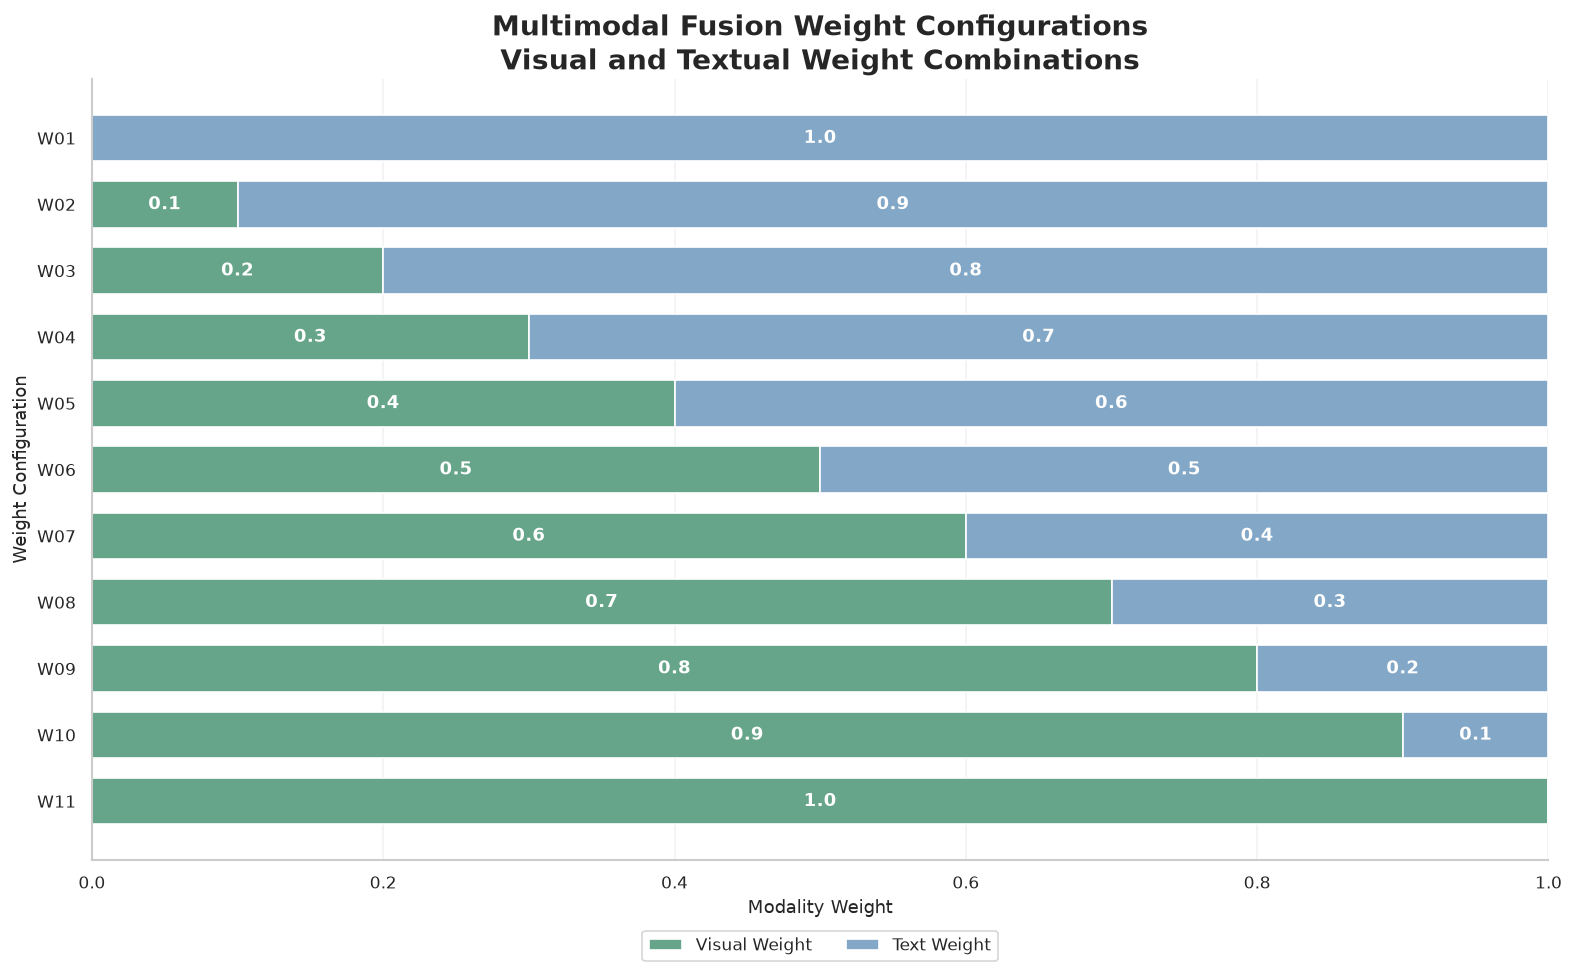

[SAVED] 110_fusion_weight_configurations.png


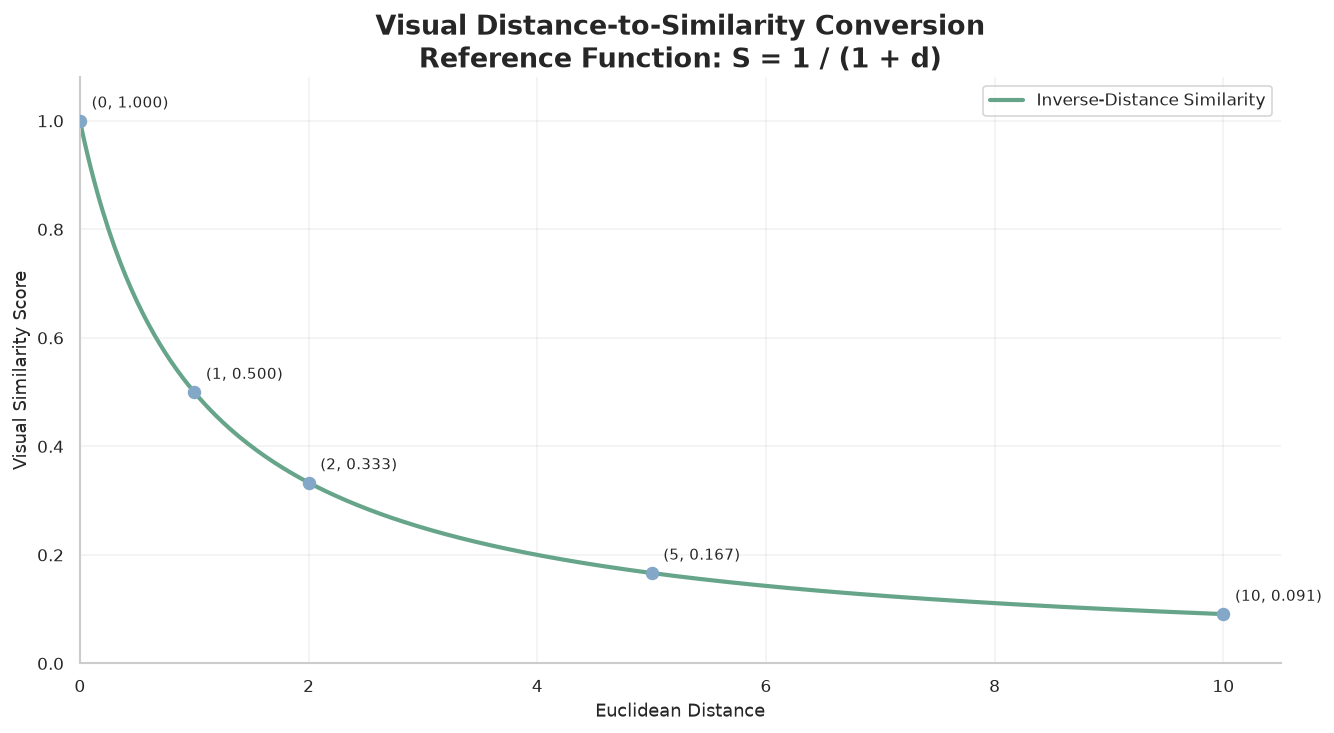

[SAVED] 111_visual_distance_similarity_reference.png

6. FUSION CONFIGURATION SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Dataset samples,104
1,Dataset classes,5
2,Visual feature dimension,143
3,Unigram feature dimension,68
4,Combined feature dimension,261
5,Fusion method,Score-Level Late Fusion
6,Fusion strategy,Weighted Sum
7,Visual distance method,euclidean
8,Visual similarity conversion,inverse_distance
9,Visual distance scale,1.0



7. SAVING CONFIGURATION REPORTS
----------------------------------------------------------------------
[SAVED] 385_fusion_weight_grid.csv
[SAVED] 386_fusion_scenario_definitions.csv
[SAVED] 387_fusion_configuration_validation.csv
[SAVED] 388_fusion_configuration_summary.csv
[SAVED] 389_fusion_preliminary_configuration.json

FINAL MULTIMODAL FUSION CONFIGURATION SUMMARY

DATASET INFORMATION
----------------------------------------------------------------------
Total samples           : 104
Total classes           : 5
Visual feature dimension: 143

SIMILARITY CONFIGURATION
----------------------------------------------------------------------
Visual matching     : euclidean
Visual conversion   : inverse_distance
Text matching       : cosine

FUSION CONFIGURATION
----------------------------------------------------------------------
Fusion method       : Score-Level Late Fusion
Fusion strategy     : Weighted Sum
Default visual weight: 0.5
Default text weight : 0.5
Weight values       : 1

In [8]:
# ============================================================
# CELL 7 - FUSION CONFIGURATION
# ============================================================

import json
from datetime import datetime, timezone

print("MULTIMODAL FUSION - FUSION CONFIGURATION")
print("=" * 70)

FUSION_CONFIGURATION_COMPLETED = False
FUSION_CONFIG_READY = False


# ============================================================
# 1. VALIDATE PREVIOUS STAGES
# ============================================================

required_fusion_stages = {
    "FUSION_LIBRARIES_IMPORTED":
        FUSION_LIBRARIES_IMPORTED,

    "FUSION_PATH_CONFIGURATION_COMPLETED":
        FUSION_PATH_CONFIGURATION_COMPLETED,

    "VISUAL_FEATURE_LOADING_COMPLETED":
        VISUAL_FEATURE_LOADING_COMPLETED,

    "TEXT_FEATURE_LOADING_COMPLETED":
        TEXT_FEATURE_LOADING_COMPLETED,

    "MULTIMODAL_DATASET_VALIDATION_COMPLETED":
        MULTIMODAL_DATASET_VALIDATION_COMPLETED,

    "MULTIMODAL_DATASET_READY":
        MULTIMODAL_DATASET_READY
}

for stage_name, completed in required_fusion_stages.items():

    assert completed is True, (
        f"{stage_name} is not completed."
    )

assert multimodal_validation_df["passed"].all()

assert multimodal_visual_features.shape == (104, 143)

assert multimodal_text_features[
    "Unigram"
].shape == (104, 68)

assert multimodal_text_features[
    "Unigram + Bigram"
].shape == (104, 261)

assert np.array_equal(
    multimodal_sample_ids,
    text_sample_ids
)

assert np.array_equal(
    multimodal_labels,
    text_labels
)

print("[PASS] Multimodal dataset validated.")


# ============================================================
# 2. MAIN FUSION CONFIGURATION
# ============================================================

FUSION_METHOD = "Score-Level Late Fusion"

FUSION_STRATEGY = "Weighted Sum"

FUSION_VISUAL_DISTANCE_METHOD = "euclidean"

FUSION_TEXT_SIMILARITY_METHOD = "cosine"

FUSION_VISUAL_SIMILARITY_METHOD = "inverse_distance"

# The conversion below implements:
#
# S_image = 1 / (1 + d / scale)
#
# With scale = 1.0:
#
# S_image = 1 / (1 + d)

FUSION_VISUAL_DISTANCE_SCALE = 1.0

FUSION_DEFAULT_VISUAL_WEIGHT = 0.5

FUSION_DEFAULT_TEXT_WEIGHT = (
    1.0 - FUSION_DEFAULT_VISUAL_WEIGHT
)

FUSION_ALPHA_GRID = np.round(
    np.linspace(0.0, 1.0, 11),
    decimals=10
)

FUSION_TOP_K_VALUES = [1, 3, 5, 10]

FUSION_TEXT_CONFIGURATIONS = [
    "Unigram",
    "Unigram + Bigram"
]

# Provisional configuration for development examples.
# NOT a final experimentally selected configuration.

FUSION_DEMO_TEXT_CONFIGURATION = "Unigram"

FUSION_SCORE_MIN = 0.0

FUSION_SCORE_MAX = 1.0

FUSION_NUMERICAL_TOLERANCE = 1e-10

FUSION_EXCLUDE_SELF_MATCH = True

FUSION_TIE_BREAKING_METHOD = (
    "similarity_descending_then_sample_id_ascending"
)

FUSION_MISSING_MODALITY_POLICY = (
    "use_available_modality"
)

FUSION_ALL_MODALITIES_MISSING_POLICY = (
    "reject_query"
)

FUSION_EVALUATION_FIT_POLICY = (
    "reference_only"
)

FUSION_CONFIGURATION_SCOPE = (
    "Full-Gallery Exploratory Development"
)

fusion_configuration_checks = []
fusion_configuration_figures = []


def register_fusion_config_check(
    category,
    name,
    condition
):

    fusion_configuration_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(condition),
        "status": (
            "Passed" if condition else "Failed"
        )
    })


print("\n1. MAIN FUSION CONFIGURATION")
print("-" * 70)

print("Fusion method          :", FUSION_METHOD)
print("Fusion strategy        :", FUSION_STRATEGY)
print("Visual distance        :", FUSION_VISUAL_DISTANCE_METHOD)
print("Visual score conversion:", FUSION_VISUAL_SIMILARITY_METHOD)
print("Visual distance scale  :", FUSION_VISUAL_DISTANCE_SCALE)
print("Text similarity        :", FUSION_TEXT_SIMILARITY_METHOD)
print("Default visual weight  :", FUSION_DEFAULT_VISUAL_WEIGHT)
print("Default text weight    :", FUSION_DEFAULT_TEXT_WEIGHT)
print("Top-K values           :", FUSION_TOP_K_VALUES)


# ============================================================
# 3. DEFINE VISUAL DISTANCE-TO-SIMILARITY FUNCTION
# ============================================================

def convert_visual_distance_to_similarity(
    distances,
    scale=FUSION_VISUAL_DISTANCE_SCALE
):
    """
    Convert nonnegative Euclidean distances to
    similarity scores using inverse distance.

        similarity = 1 / (1 + distance / scale)

    This is a monotonic conversion, not an
    empirically calibrated similarity probability.
    """

    distance_array = np.asarray(
        distances,
        dtype=np.float64
    )

    if distance_array.size == 0:
        raise ValueError(
            "Distance array cannot be empty."
        )

    if (
        not np.isfinite(scale)
        or scale <= 0
    ):
        raise ValueError(
            "Distance scale must be positive and finite."
        )

    if not np.isfinite(distance_array).all():
        raise ValueError(
            "Distances contain NaN or infinity."
        )

    if np.any(
        distance_array < -FUSION_NUMERICAL_TOLERANCE
    ):
        raise ValueError(
            "Euclidean distances cannot be negative."
        )

    # Handle very small floating-point negative values.

    distance_array = np.maximum(
        distance_array,
        0.0
    )

    similarity = 1.0 / (
        1.0 + distance_array / scale
    )

    return similarity


# ============================================================
# 4. DEFINE WEIGHTED SCORE FUSION FUNCTION
# ============================================================

def fuse_modality_scores(
    image_scores=None,
    text_scores=None,
    visual_weight=FUSION_DEFAULT_VISUAL_WEIGHT
):
    """
    Combine similarity scores using weighted sum.

    Supports:
    - Image and text available
    - Image only
    - Text only

    All-OOV and empty text queries must be detected
    before calling this function. Such queries must
    pass text_scores=None, not an arbitrary zero array.

    Returns:
        fused_scores, effective_weights
    """

    if (
        not np.isfinite(visual_weight)
        or not 0.0 <= visual_weight <= 1.0
    ):
        raise ValueError(
            "Visual weight must be between 0 and 1."
        )

    if image_scores is None and text_scores is None:
        raise ValueError(
            "At least one modality must be available."
        )

    def validate_scores(scores, modality):

        if scores is None:
            return None

        array = np.asarray(
            scores,
            dtype=np.float64
        )

        if array.size == 0:
            raise ValueError(
                f"{modality} score array is empty."
            )

        if not np.isfinite(array).all():
            raise ValueError(
                f"{modality} scores contain invalid values."
            )

        if (
            np.any(
                array < -FUSION_NUMERICAL_TOLERANCE
            )
            or np.any(
                array > 1.0 + FUSION_NUMERICAL_TOLERANCE
            )
        ):
            raise ValueError(
                f"{modality} similarity scores "
                "must lie within [0, 1]."
            )

        return np.clip(
            array,
            0.0,
            1.0
        )

    image_array = validate_scores(
        image_scores,
        "Image"
    )

    text_array = validate_scores(
        text_scores,
        "Text"
    )

    # Case 1: Text is unavailable.

    if text_array is None:

        return image_array.copy(), {
            "effective_visual_weight": 1.0,
            "effective_text_weight": 0.0,
            "mode": "Image Only"
        }

    # Case 2: Image is unavailable.

    if image_array is None:

        return text_array.copy(), {
            "effective_visual_weight": 0.0,
            "effective_text_weight": 1.0,
            "mode": "Text Only"
        }

    # Case 3: Both modalities are available.

    if image_array.shape != text_array.shape:
        raise ValueError(
            "Image and text score arrays "
            "must have identical shapes."
        )

    text_weight = 1.0 - visual_weight

    fused_scores = (
        visual_weight * image_array
        +
        text_weight * text_array
    )

    return fused_scores, {
        "effective_visual_weight": float(
            visual_weight
        ),
        "effective_text_weight": float(
            text_weight
        ),
        "mode": "Multimodal"
    }


# ============================================================
# 5. DEFINE MAIN RETRIEVAL SCENARIOS
# ============================================================

fusion_scenario_records = [

    {
        "scenario_id": "C01",
        "scenario_name": "Image Only",
        "retrieval_method": "Image Only",
        "text_configuration": None,
        "visual_weight": 1.0,
        "text_weight": 0.0
    },

    {
        "scenario_id": "C02",
        "scenario_name": "Text Only - Unigram",
        "retrieval_method": "Text Only",
        "text_configuration": "Unigram",
        "visual_weight": 0.0,
        "text_weight": 1.0
    },

    {
        "scenario_id": "C03",
        "scenario_name": "Text Only - Unigram + Bigram",
        "retrieval_method": "Text Only",
        "text_configuration": "Unigram + Bigram",
        "visual_weight": 0.0,
        "text_weight": 1.0
    },

    {
        "scenario_id": "C04",
        "scenario_name": "Multimodal - Unigram",
        "retrieval_method": "Multimodal",
        "text_configuration": "Unigram",
        "visual_weight": 0.5,
        "text_weight": 0.5
    },

    {
        "scenario_id": "C05",
        "scenario_name": "Multimodal - Unigram + Bigram",
        "retrieval_method": "Multimodal",
        "text_configuration": "Unigram + Bigram",
        "visual_weight": 0.5,
        "text_weight": 0.5
    }
]

fusion_scenario_df = pd.DataFrame(
    fusion_scenario_records
)

fusion_scenario_df[
    "weight_sum"
] = (
    fusion_scenario_df["visual_weight"]
    +
    fusion_scenario_df["text_weight"]
)

fusion_scenario_df[
    "weights_valid"
] = np.isclose(
    fusion_scenario_df["weight_sum"],
    1.0,
    atol=FUSION_NUMERICAL_TOLERANCE
)

print("\n2. MAIN RETRIEVAL SCENARIOS")
print("-" * 70)

display(fusion_scenario_df)


# ============================================================
# 6. CREATE FUSION WEIGHT GRID
# ============================================================

fusion_weight_grid_records = []

for configuration_name in FUSION_TEXT_CONFIGURATIONS:

    for visual_weight in FUSION_ALPHA_GRID:

        visual_weight = float(
            visual_weight
        )

        text_weight = float(
            1.0 - visual_weight
        )

        if visual_weight == 1.0:

            retrieval_mode = "Image Only"

            # Image Only is the same method regardless
            # of the unused TF-IDF configuration.

            unique_method_key = "image_only"

        elif visual_weight == 0.0:

            retrieval_mode = "Text Only"

            unique_method_key = (
                f"text_only::{configuration_name}"
            )

        else:

            retrieval_mode = "Multimodal"

            unique_method_key = (
                f"multimodal::{configuration_name}::"
                f"{visual_weight:.1f}"
            )

        fusion_weight_grid_records.append({

            "configuration": configuration_name,

            "visual_weight": visual_weight,

            "text_weight": text_weight,

            "weight_sum": (
                visual_weight + text_weight
            ),

            "retrieval_mode": retrieval_mode,

            "unique_method_key": unique_method_key,

            "is_balanced": np.isclose(
                visual_weight,
                0.5
            )
        })


fusion_weight_grid_df = pd.DataFrame(
    fusion_weight_grid_records
)

fusion_grid_total_records = len(
    fusion_weight_grid_df
)

fusion_grid_unique_methods = (
    fusion_weight_grid_df[
        "unique_method_key"
    ].nunique()
)

print("\n3. FUSION WEIGHT GRID")
print("-" * 70)

display(fusion_weight_grid_df)

print(
    "Total configuration-weight combinations:",
    fusion_grid_total_records
)

print(
    "Unique retrieval methods:",
    fusion_grid_unique_methods
)


# ============================================================
# 7. VALIDATE CONFIGURATION STRUCTURE
# ============================================================

register_fusion_config_check(
    "Dataset",
    "Multimodal dataset contains 104 samples",
    multimodal_n_samples == 104
)

register_fusion_config_check(
    "Dataset",
    "All samples aligned",
    multimodal_sample_alignment_df[
        "alignment_passed"
    ].all()
)

register_fusion_config_check(
    "Dataset",
    "Alignment signature available",
    isinstance(
        multimodal_alignment_signature,
        str
    )
    and len(multimodal_alignment_signature) == 64
)

register_fusion_config_check(
    "Similarity",
    "Euclidean distance configured",
    FUSION_VISUAL_DISTANCE_METHOD == "euclidean"
)

register_fusion_config_check(
    "Similarity",
    "Cosine similarity configured",
    FUSION_TEXT_SIMILARITY_METHOD == "cosine"
)

register_fusion_config_check(
    "Similarity",
    "Positive visual distance scale",
    np.isfinite(FUSION_VISUAL_DISTANCE_SCALE)
    and FUSION_VISUAL_DISTANCE_SCALE > 0
)

register_fusion_config_check(
    "Fusion",
    "Weighted score-level late fusion configured",
    FUSION_METHOD == "Score-Level Late Fusion"
    and FUSION_STRATEGY == "Weighted Sum"
)

register_fusion_config_check(
    "Fusion",
    "Default weights sum to one",
    np.isclose(
        FUSION_DEFAULT_VISUAL_WEIGHT
        + FUSION_DEFAULT_TEXT_WEIGHT,
        1.0,
        atol=FUSION_NUMERICAL_TOLERANCE
    )
)

register_fusion_config_check(
    "Fusion",
    "Eleven fusion weights configured",
    len(FUSION_ALPHA_GRID) == 11
)

register_fusion_config_check(
    "Fusion",
    "Fusion weights span zero to one",
    np.isclose(FUSION_ALPHA_GRID[0], 0.0)
    and np.isclose(FUSION_ALPHA_GRID[-1], 1.0)
)

register_fusion_config_check(
    "Fusion",
    "Fusion weights use step 0.1",
    np.allclose(
        np.diff(FUSION_ALPHA_GRID),
        0.1,
        atol=FUSION_NUMERICAL_TOLERANCE
    )
)

register_fusion_config_check(
    "Fusion",
    "All weight combinations sum to one",
    np.allclose(
        fusion_weight_grid_df["weight_sum"],
        1.0,
        atol=FUSION_NUMERICAL_TOLERANCE
    )
)

register_fusion_config_check(
    "Fusion",
    "Two TF-IDF configurations retained",
    set(FUSION_TEXT_CONFIGURATIONS)
    == {"Unigram", "Unigram + Bigram"}
)

register_fusion_config_check(
    "Scenarios",
    "Five primary retrieval scenarios",
    len(fusion_scenario_df) == 5
)

register_fusion_config_check(
    "Scenarios",
    "Scenario identifiers unique",
    fusion_scenario_df["scenario_id"].is_unique
)

register_fusion_config_check(
    "Scenarios",
    "Scenario names unique",
    fusion_scenario_df["scenario_name"].is_unique
)

register_fusion_config_check(
    "Scenarios",
    "All scenario weights valid",
    fusion_scenario_df["weights_valid"].all()
)

register_fusion_config_check(
    "Scenarios",
    "22 configuration-weight records",
    fusion_grid_total_records == 22
)

register_fusion_config_check(
    "Scenarios",
    "21 unique retrieval methods",
    fusion_grid_unique_methods == 21
)

register_fusion_config_check(
    "Retrieval",
    "Top-K values valid for 104 samples",
    all(
        1 <= k < multimodal_n_samples
        for k in FUSION_TOP_K_VALUES
    )
)

register_fusion_config_check(
    "Retrieval",
    "Self-match exclusion enabled",
    FUSION_EXCLUDE_SELF_MATCH
)

register_fusion_config_check(
    "Retrieval",
    "Deterministic tie-breaking configured",
    FUSION_TIE_BREAKING_METHOD
    ==
    "similarity_descending_then_sample_id_ascending"
)

register_fusion_config_check(
    "Missing Modalities",
    "Single-modality fallback configured",
    FUSION_MISSING_MODALITY_POLICY
    == "use_available_modality"
)

register_fusion_config_check(
    "Evaluation Protection",
    "Reference-only fitting required",
    FUSION_EVALUATION_FIT_POLICY
    == "reference_only"
)


# ============================================================
# 8. MATHEMATICAL SANITY TESTS
# ============================================================

def expects_value_error(function):
    try:
        function()
        return False
    except ValueError:
        return True


test_distances = np.array(
    [0.0, 0.5, 1.0, 2.0, 10.0],
    dtype=np.float64
)

test_converted_scores = (
    convert_visual_distance_to_similarity(
        test_distances
    )
)

expected_converted_scores = (
    1.0 / (1.0 + test_distances)
)

test_image_scores = np.array(
    [0.8, 0.6, 0.3]
)

test_text_scores = np.array(
    [0.2, 0.4, 0.9]
)

test_balanced_scores, test_balanced_weights = (
    fuse_modality_scores(
        test_image_scores,
        test_text_scores,
        visual_weight=0.5
    )
)

test_image_only, test_image_only_weights = (
    fuse_modality_scores(
        image_scores=test_image_scores,
        text_scores=None,
        visual_weight=0.5
    )
)

test_text_only, test_text_only_weights = (
    fuse_modality_scores(
        image_scores=None,
        text_scores=test_text_scores,
        visual_weight=0.5
    )
)

test_alpha_zero, _ = fuse_modality_scores(
    test_image_scores,
    test_text_scores,
    visual_weight=0.0
)

test_alpha_one, _ = fuse_modality_scores(
    test_image_scores,
    test_text_scores,
    visual_weight=1.0
)

# Deterministic tie-breaking example.

test_rank_scores = np.array(
    [0.7, 0.9, 0.9, 0.6]
)

test_rank_ids = np.array(
    ["B", "C", "A", "D"]
)

test_rank_order = np.lexsort((
    test_rank_ids,
    -test_rank_scores
))

test_ranked_ids = (
    test_rank_ids[test_rank_order]
    .tolist()
)


fusion_math_test_cases = [

    (
        "Zero distance produces similarity one",
        np.isclose(test_converted_scores[0], 1.0)
    ),

    (
        "Inverse distance formula reproduced",
        np.allclose(
            test_converted_scores,
            expected_converted_scores
        )
    ),

    (
        "Converted scores bounded in [0,1]",
        np.all(
            (test_converted_scores >= 0)
            &
            (test_converted_scores <= 1)
        )
    ),

    (
        "Similarity decreases with increasing distance",
        np.all(np.diff(test_converted_scores) < 0)
    ),

    (
        "Balanced fusion formula reproduced",
        np.allclose(
            test_balanced_scores,
            0.5 * test_image_scores
            + 0.5 * test_text_scores
        )
    ),

    (
        "Alpha zero reproduces text scores",
        np.allclose(
            test_alpha_zero,
            test_text_scores
        )
    ),

    (
        "Alpha one reproduces image scores",
        np.allclose(
            test_alpha_one,
            test_image_scores
        )
    ),

    (
        "Image-only fallback preserved",
        np.array_equal(
            test_image_only,
            test_image_scores
        )
        and test_image_only_weights[
            "effective_visual_weight"
        ] == 1.0
    ),

    (
        "Text-only fallback preserved",
        np.array_equal(
            test_text_only,
            test_text_scores
        )
        and test_text_only_weights[
            "effective_text_weight"
        ] == 1.0
    ),

    (
        "Balanced fusion effective weights valid",
        np.isclose(
            test_balanced_weights[
                "effective_visual_weight"
            ]
            +
            test_balanced_weights[
                "effective_text_weight"
            ],
            1.0
        )
    ),

    (
        "Reject negative Euclidean distance",
        expects_value_error(
            lambda:
            convert_visual_distance_to_similarity(
                [-1.0]
            )
        )
    ),

    (
        "Reject NaN Euclidean distance",
        expects_value_error(
            lambda:
            convert_visual_distance_to_similarity(
                [np.nan]
            )
        )
    ),

    (
        "Reject invalid fusion weight",
        expects_value_error(
            lambda:
            fuse_modality_scores(
                test_image_scores,
                test_text_scores,
                visual_weight=1.5
            )
        )
    ),

    (
        "Reject mismatched modality shapes",
        expects_value_error(
            lambda:
            fuse_modality_scores(
                [0.5, 0.6],
                [0.7],
                visual_weight=0.5
            )
        )
    ),

    (
        "Reject missing image and text scores",
        expects_value_error(
            lambda:
            fuse_modality_scores(
                None,
                None
            )
        )
    ),

    (
        "Reject out-of-range similarity",
        expects_value_error(
            lambda:
            fuse_modality_scores(
                [1.5],
                [0.4]
            )
        )
    ),

    (
        "Deterministic ranking resolves ties by sample ID",
        test_ranked_ids == [
            "A", "C", "B", "D"
        ]
    )
]


fusion_math_validation_df = pd.DataFrame(
    fusion_math_test_cases,
    columns=[
        "validation_check",
        "passed"
    ]
)

fusion_math_validation_df["status"] = np.where(
    fusion_math_validation_df["passed"],
    "Passed",
    "Failed"
)

for row in fusion_math_validation_df.itertuples():

    register_fusion_config_check(
        "Mathematical Sanity Tests",
        row.validation_check,
        row.passed
    )

print("\n4. MATHEMATICAL SANITY TESTS")
print("-" * 70)

display(fusion_math_validation_df)


# ============================================================
# 9. CREATE REPRODUCIBLE CONFIGURATION DICTIONARY
# ============================================================

fusion_configuration = {

    "schema_version": "1.0.0",

    "notebook": "05_multimodal_fusion.ipynb",

    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "scope": FUSION_CONFIGURATION_SCOPE,

    "dataset": {
        "number_of_samples": int(
            multimodal_n_samples
        ),
        "number_of_classes": int(
            len(multimodal_class_names)
        ),
        "alignment_signature":
            multimodal_alignment_signature,
        "sample_order_preserved": True
    },

    "features": {
        "visual_dimension": int(
            multimodal_visual_features.shape[1]
        ),
        "text_dimensions": {
            configuration_name: int(
                multimodal_text_features[
                    configuration_name
                ].shape[1]
            )
            for configuration_name
            in FUSION_TEXT_CONFIGURATIONS
        },
        "modalities_concatenated": False
    },

    "visual_matching": {
        "distance_method":
            FUSION_VISUAL_DISTANCE_METHOD,
        "similarity_conversion":
            FUSION_VISUAL_SIMILARITY_METHOD,
        "distance_scale":
            FUSION_VISUAL_DISTANCE_SCALE
    },

    "text_matching": {
        "similarity_method":
            FUSION_TEXT_SIMILARITY_METHOD,
        "configurations":
            FUSION_TEXT_CONFIGURATIONS
    },

    "fusion": {
        "method": FUSION_METHOD,
        "strategy": FUSION_STRATEGY,
        "default_visual_weight":
            FUSION_DEFAULT_VISUAL_WEIGHT,
        "default_text_weight":
            FUSION_DEFAULT_TEXT_WEIGHT,
        "weight_grid":
            FUSION_ALPHA_GRID.tolist(),
        "weight_optimization_completed": False,
        "final_weight_selected": False,
        "final_text_configuration_selected": False,
        "demo_text_configuration":
            FUSION_DEMO_TEXT_CONFIGURATION
    },

    "retrieval": {
        "top_k_values": FUSION_TOP_K_VALUES,
        "self_match_excluded":
            FUSION_EXCLUDE_SELF_MATCH,
        "tie_breaking":
            FUSION_TIE_BREAKING_METHOD
    },

    "missing_modality_handling": {
        "single_modality_policy":
            FUSION_MISSING_MODALITY_POLICY,
        "all_modalities_missing":
            FUSION_ALL_MODALITIES_MISSING_POLICY,
        "all_oov_text_is_unavailable": True
    },

    "evaluation_protection": {
        "fitting_policy":
            FUSION_EVALUATION_FIT_POLICY,
        "independent_evaluation_completed": False,
        "full_gallery_results_are_exploratory": True
    },

    "numerical_tolerance":
        FUSION_NUMERICAL_TOLERANCE
}


# ============================================================
# 10. FINAL CONFIGURATION VALIDATION
# ============================================================

fusion_configuration_validation_df = pd.DataFrame(
    fusion_configuration_checks
)

fusion_configuration_total_checks = len(
    fusion_configuration_validation_df
)

fusion_configuration_passed_checks = int(
    fusion_configuration_validation_df[
        "passed"
    ].sum()
)

fusion_configuration_failed_checks = (
    fusion_configuration_total_checks
    - fusion_configuration_passed_checks
)

print("\n5. FUSION CONFIGURATION VALIDATION")
print("-" * 70)

display(fusion_configuration_validation_df)

# Preserve diagnostics if a check fails.

fusion_configuration_validation_df.to_csv(
    METRICS_DIR / "387_fusion_configuration_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

assert fusion_configuration_validation_df[
    "passed"
].all(), (
    fusion_configuration_validation_df.loc[
        ~fusion_configuration_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All fusion configuration checks passed.")


# ============================================================
# 11. VISUALIZATION - FUSION WEIGHT GRID
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, 8),
    constrained_layout=True
)

weight_positions = np.arange(
    len(FUSION_ALPHA_GRID)
)

visual_weights = FUSION_ALPHA_GRID

text_weights = (
    1.0 - visual_weights
)

ax.barh(
    weight_positions,
    visual_weights,
    color="#66A58A",
    height=0.7,
    label="Visual Weight"
)

ax.barh(
    weight_positions,
    text_weights,
    left=visual_weights,
    color="#83A7C7",
    height=0.7,
    label="Text Weight"
)

for index, (visual_w, text_w) in enumerate(
    zip(visual_weights, text_weights)
):

    if visual_w > 0.05:
        ax.text(
            visual_w / 2,
            index,
            f"{visual_w:.1f}",
            ha="center",
            va="center",
            color="white",
            fontweight="bold"
        )

    if text_w > 0.05:
        ax.text(
            visual_w + text_w / 2,
            index,
            f"{text_w:.1f}",
            ha="center",
            va="center",
            color="white",
            fontweight="bold"
        )

ax.set_yticks(weight_positions)

ax.set_yticklabels([
    f"W{i + 1:02d}"
    for i in range(len(FUSION_ALPHA_GRID))
])

ax.invert_yaxis()

ax.set_xlim(0, 1.0)

ax.set_xlabel("Modality Weight")

ax.set_ylabel("Weight Configuration")

ax.set_title(
    "Multimodal Fusion Weight Configurations\n"
    "Visual and Textual Weight Combinations",
    fontsize=17,
    fontweight="bold"
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=2
)

figure_path = (
    FUSION_FIGURES_DIR
    / "110_fusion_weight_configurations.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

fusion_configuration_figures.append(
    figure_path
)

plt.show()
plt.close(fig)

print(f"[SAVED] {figure_path.name}")


# ============================================================
# 12. VISUALIZATION - DISTANCE CONVERSION
# ============================================================

# Synthetic distance values only.
# The actual visual distance distribution
# will be calculated in Cell 8 and Cell 9.

reference_distances = np.linspace(
    0.0,
    10.0,
    401
)

reference_similarities = (
    convert_visual_distance_to_similarity(
        reference_distances
    )
)

fig, ax = plt.subplots(
    figsize=(11, 6),
    constrained_layout=True
)

ax.plot(
    reference_distances,
    reference_similarities,
    color="#66A58A",
    linewidth=2.5,
    label="Inverse-Distance Similarity"
)

for distance in [0, 1, 2, 5, 10]:

    similarity = float(
        convert_visual_distance_to_similarity(
            [distance]
        )[0]
    )

    ax.scatter(
        distance,
        similarity,
        color="#83A7C7",
        s=50,
        zorder=3
    )

    ax.annotate(
        f"({distance}, {similarity:.3f})",
        (distance, similarity),
        xytext=(7, 8),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlim(0, 10.5)
ax.set_ylim(0, 1.08)

ax.set_xlabel("Euclidean Distance")
ax.set_ylabel("Visual Similarity Score")

ax.set_title(
    "Visual Distance-to-Similarity Conversion\n"
    "Reference Function: S = 1 / (1 + d)",
    fontsize=16,
    fontweight="bold"
)

ax.legend()

figure_path = (
    FUSION_FIGURES_DIR
    / "111_visual_distance_similarity_reference.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

fusion_configuration_figures.append(
    figure_path
)

plt.show()
plt.close(fig)

print(f"[SAVED] {figure_path.name}")


# ============================================================
# 13. CREATE FINAL CONFIGURATION SUMMARY
# ============================================================

fusion_configuration_summary_df = pd.DataFrame([

    ("Dataset samples", multimodal_n_samples),

    ("Dataset classes", len(multimodal_class_names)),

    (
        "Visual feature dimension",
        multimodal_visual_features.shape[1]
    ),

    (
        "Unigram feature dimension",
        multimodal_text_features[
            "Unigram"
        ].shape[1]
    ),

    (
        "Combined feature dimension",
        multimodal_text_features[
            "Unigram + Bigram"
        ].shape[1]
    ),

    ("Fusion method", FUSION_METHOD),

    ("Fusion strategy", FUSION_STRATEGY),

    (
        "Visual distance method",
        FUSION_VISUAL_DISTANCE_METHOD
    ),

    (
        "Visual similarity conversion",
        FUSION_VISUAL_SIMILARITY_METHOD
    ),

    (
        "Visual distance scale",
        FUSION_VISUAL_DISTANCE_SCALE
    ),

    (
        "Text similarity method",
        FUSION_TEXT_SIMILARITY_METHOD
    ),

    (
        "Default visual weight",
        FUSION_DEFAULT_VISUAL_WEIGHT
    ),

    (
        "Default text weight",
        FUSION_DEFAULT_TEXT_WEIGHT
    ),

    ("Weight configurations", len(FUSION_ALPHA_GRID)),

    ("Primary scenarios", len(fusion_scenario_df)),

    (
        "Configuration-weight combinations",
        fusion_grid_total_records
    ),

    (
        "Unique retrieval methods",
        fusion_grid_unique_methods
    ),

    ("Top-K values", str(FUSION_TOP_K_VALUES)),

    ("Self-match exclusion", True),

    (
        "Tie-breaking method",
        FUSION_TIE_BREAKING_METHOD
    ),

    (
        "Missing modality policy",
        FUSION_MISSING_MODALITY_POLICY
    ),

    (
        "Validation checks",
        fusion_configuration_total_checks
    ),

    (
        "Validation checks passed",
        fusion_configuration_passed_checks
    ),

    (
        "Validation checks failed",
        fusion_configuration_failed_checks
    ),

    (
        "Generated figures",
        len(fusion_configuration_figures)
    ),

    ("Score matrices calculated", False),

    ("Fusion weights optimized", False),

    ("Final text configuration selected", False),

    ("Independent retrieval evaluation completed", False),

    ("Dataset samples modified", False),

    ("Feature matrices modified", False),

    ("Fusion configuration completed", True)

], columns=["Indicator", "Result"])

print("\n6. FUSION CONFIGURATION SUMMARY")
print("-" * 70)

display(fusion_configuration_summary_df)


# ============================================================
# 14. SAVE FUSION CONFIGURATION REPORTS
# ============================================================

fusion_configuration_reports = {

    "385_fusion_weight_grid.csv":
        fusion_weight_grid_df,

    "386_fusion_scenario_definitions.csv":
        fusion_scenario_df,

    "387_fusion_configuration_validation.csv":
        fusion_configuration_validation_df,

    "388_fusion_configuration_summary.csv":
        fusion_configuration_summary_df
}

print("\n7. SAVING CONFIGURATION REPORTS")
print("-" * 70)

for filename, dataframe in (
    fusion_configuration_reports.items()
):

    output_path = METRICS_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


FUSION_PRELIMINARY_CONFIG_PATH = (
    METRICS_DIR
    / "389_fusion_preliminary_configuration.json"
)

with open(
    FUSION_PRELIMINARY_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        fusion_configuration,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )

print(
    f"[SAVED] "
    f"{FUSION_PRELIMINARY_CONFIG_PATH.name}"
)


# ============================================================
# 15. FINAL COMPLETION CHECKS
# ============================================================

assert fusion_configuration_validation_df[
    "passed"
].all()

assert fusion_math_validation_df[
    "passed"
].all()

assert fusion_configuration_failed_checks == 0

assert len(fusion_scenario_df) == 5

assert len(FUSION_ALPHA_GRID) == 11

assert len(fusion_weight_grid_df) == 22

assert fusion_grid_unique_methods == 21

assert len(fusion_configuration_figures) == 2

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in fusion_configuration_figures
)

assert all(
    (METRICS_DIR / filename).is_file()
    and (METRICS_DIR / filename).stat().st_size > 0
    for filename in fusion_configuration_reports
)

assert FUSION_PRELIMINARY_CONFIG_PATH.is_file()

with open(
    FUSION_PRELIMINARY_CONFIG_PATH,
    "r",
    encoding="utf-8"
) as file:

    reloaded_fusion_configuration = json.load(
        file
    )

assert (
    reloaded_fusion_configuration
    == fusion_configuration
)

FUSION_CONFIGURATION_COMPLETED = True
FUSION_CONFIG_READY = True


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)

print("FINAL MULTIMODAL FUSION CONFIGURATION SUMMARY")

print("=" * 70)

print("\nDATASET INFORMATION")
print("-" * 70)

print("Total samples           :", multimodal_n_samples)
print("Total classes           :", len(multimodal_class_names))
print("Visual feature dimension:", multimodal_visual_features.shape[1])

print("\nSIMILARITY CONFIGURATION")
print("-" * 70)

print("Visual matching     :", FUSION_VISUAL_DISTANCE_METHOD)
print("Visual conversion   :", FUSION_VISUAL_SIMILARITY_METHOD)
print("Text matching       :", FUSION_TEXT_SIMILARITY_METHOD)

print("\nFUSION CONFIGURATION")
print("-" * 70)

print("Fusion method       :", FUSION_METHOD)
print("Fusion strategy     :", FUSION_STRATEGY)
print("Default visual weight:", FUSION_DEFAULT_VISUAL_WEIGHT)
print("Default text weight :", FUSION_DEFAULT_TEXT_WEIGHT)
print("Weight values       :", len(FUSION_ALPHA_GRID))
print("Primary scenarios   :", len(fusion_scenario_df))
print("Unique methods      :", fusion_grid_unique_methods)
print("Top-K values        :", FUSION_TOP_K_VALUES)

print("\nVALIDATION RESULTS")
print("-" * 70)

print(
    "Technical checks    :",
    f"{fusion_configuration_passed_checks}/"
    f"{fusion_configuration_total_checks}"
)

print(
    "Failed checks       :",
    fusion_configuration_failed_checks
)

print(
    "Mathematical tests  :",
    f"{fusion_math_validation_df['passed'].sum()}/"
    f"{len(fusion_math_validation_df)}"
)

print(
    "Generated CSV files :",
    len(fusion_configuration_reports)
)

print(
    "Generated JSON files:",
    1
)

print(
    "Generated figures   :",
    len(fusion_configuration_figures)
)

print("\n[PASS] Similarity methods configured.")
print("[PASS] Visual score conversion defined.")
print("[PASS] Weighted fusion function defined.")
print("[PASS] Modality fallback behavior validated.")
print("[PASS] Fusion scenarios defined.")
print("[PASS] Fusion weight grid created.")
print("[PASS] Ranking tie-breaking configured.")
print("[PASS] Mathematical sanity tests completed.")
print("[PASS] Configuration reports saved.")

print("\n[INFO] Default weight is provisional.")
print("[INFO] No best fusion weight has been selected.")
print("[INFO] No similarity matrices were calculated.")
print("[INFO] No feature matrices were modified.")
print("[INFO] Independent retrieval evaluation is pending.")

print("\n" + "=" * 70)

print("FUSION CONFIGURATION COMPLETED SUCCESSFULLY")

print("=" * 70)

print("\nNext cell: Cell 8 - Euclidean Distance Calculation")

MULTIMODAL FUSION - LOAD TEXT FEATURE ARTIFACTS
[PASS] Previous cells validated.

1. TEXT ARTIFACT LOCATIONS
----------------------------------------------------------------------
Text feature directory: D:\Project\Multimodal_Leaf_Retrieval\dataset\features\text
Expected payload files : 16
Manifest              : text_feature_artifact_manifest.csv
[PASS] Text artifact manifest loaded.

2. TEXT ARTIFACT INTEGRITY
----------------------------------------------------------------------
[PASS] tfidf_unigram_features.npz
[PASS] tfidf_unigram_vectorizer.joblib
[PASS] tfidf_unigram_feature_names.npy
[PASS] tfidf_unigram_idf_weights.npy
[PASS] tfidf_unigram_vocabulary.csv
[PASS] tfidf_unigram_bigram_features.npz
[PASS] tfidf_unigram_bigram_vectorizer.joblib
[PASS] tfidf_unigram_bigram_feature_names.npy
[PASS] tfidf_unigram_bigram_idf_weights.npy
[PASS] tfidf_unigram_bigram_vocabulary.csv
[PASS] text_sample_ids.npy
[PASS] text_class_labels.npy
[PASS] multimodal_feature_metadata.csv
[PASS] text_c

,row_index,sample_id,kelas,visual_id_match,visual_label_match,metadata_id_match,metadata_label_match,corpus_match,alignment_flag,passed
0,0,leaf_165d2f32c7fda707,Mangkok,True,True,True,True,True,True,True
1,1,leaf_8473270c3702f48b,Mangkok,True,True,True,True,True,True,True
2,2,leaf_8f425d66b1e193b9,Mangkok,True,True,True,True,True,True,True
3,3,leaf_0ebc8f4f3ee9c8d5,Mangkok,True,True,True,True,True,True,True
4,4,leaf_b0c5f55e42499cae,Mangkok,True,True,True,True,True,True,True
5,5,leaf_de9e3e4ed5d89dfc,Mangkok,True,True,True,True,True,True,True
6,6,leaf_23b789945271fb92,Mangkok,True,True,True,True,True,True,True
7,7,leaf_84de0dc731018607,Mangkok,True,True,True,True,True,True,True



5. LOADING TF-IDF CONFIGURATIONS
----------------------------------------------------------------------

Configuration: Unigram
Matrix shape : (104, 68)
Nonzero      : 2086
Unigram      : 68
Bigram       : 0
Reproduction difference: 1.665e-16

Configuration: Unigram + Bigram
Matrix shape : (104, 261)
Nonzero      : 4166
Unigram      : 68
Bigram       : 193
Reproduction difference: 1.110e-16

6. LOADED TEXT MATRIX SUMMARY
----------------------------------------------------------------------


C:\Users\ronn7\AppData\Local\Temp\ipykernel_22184\2737530108.py:532: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  vocabulary_df = pd.read_csv(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_22184\2737530108.py:532: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  vocabulary_df = pd.read_csv(


,configuration,samples,feature_dimension,unigram_features,bigram_features,nonzero_values,zero_values,sparsity_percent,minimum_l2_norm,maximum_l2_norm,reproduction_max_difference,matrix_file_kib,vectorizer_file_kib
0,Unigram,104,68,68,0,2086,4986,70.503394,1.0,1.0,0.0,10.820312,1.419922
1,Unigram + Bigram,104,261,68,193,4166,22978,84.652225,1.0,1.0,0.0,17.756836,3.093750



7. MAIN TEXT FEATURE VARIABLES
----------------------------------------------------------------------
Unigram features : (104, 68)
Combined features: (104, 261)
Text sample IDs  : (104,)
Text labels      : (104,)

8. CLASS DISTRIBUTION
----------------------------------------------------------------------


,kelas,number_of_samples,percentage
0,Mangkok,20,19.2308
1,Salam,19,18.2692
2,Sambang Darah,20,19.2308
3,Sirih,20,19.2308
4,Tapak Kuda,25,24.0385



9. TEXT FEATURE LOADING VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Manifest,Manifest covers all expected text artifacts,True,Passed
1,Artifact Integrity,tfidf_unigram_features.npz integrity,True,Passed
2,Artifact Integrity,tfidf_unigram_vectorizer.joblib integrity,True,Passed
3,Artifact Integrity,tfidf_unigram_feature_names.npy integrity,True,Passed
4,Artifact Integrity,tfidf_unigram_idf_weights.npy integrity,True,Passed
5,Artifact Integrity,tfidf_unigram_vocabulary.csv integrity,True,Passed
6,Artifact Integrity,tfidf_unigram_bigram_features.npz integrity,True,Passed
7,Artifact Integrity,tfidf_unigram_bigram_vectorizer.joblib integrity,True,Passed
8,Artifact Integrity,tfidf_unigram_bigram_feature_names.npy integrity,True,Passed
9,Artifact Integrity,tfidf_unigram_bigram_idf_weights.npy integrity,True,Passed


[PASS] All text loading checks passed.


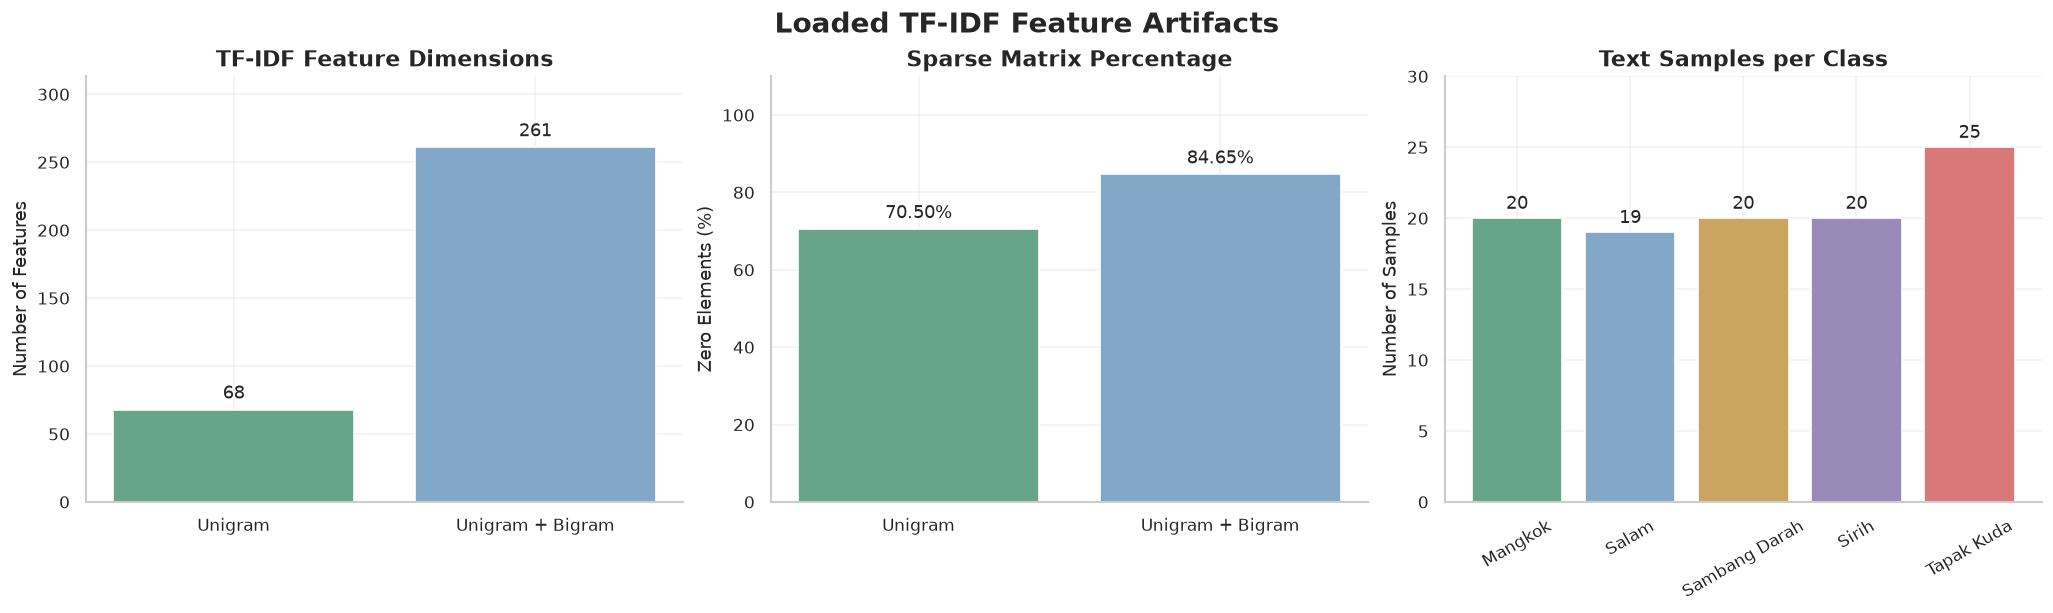

[SAVED] 106_loaded_text_feature_summary.png


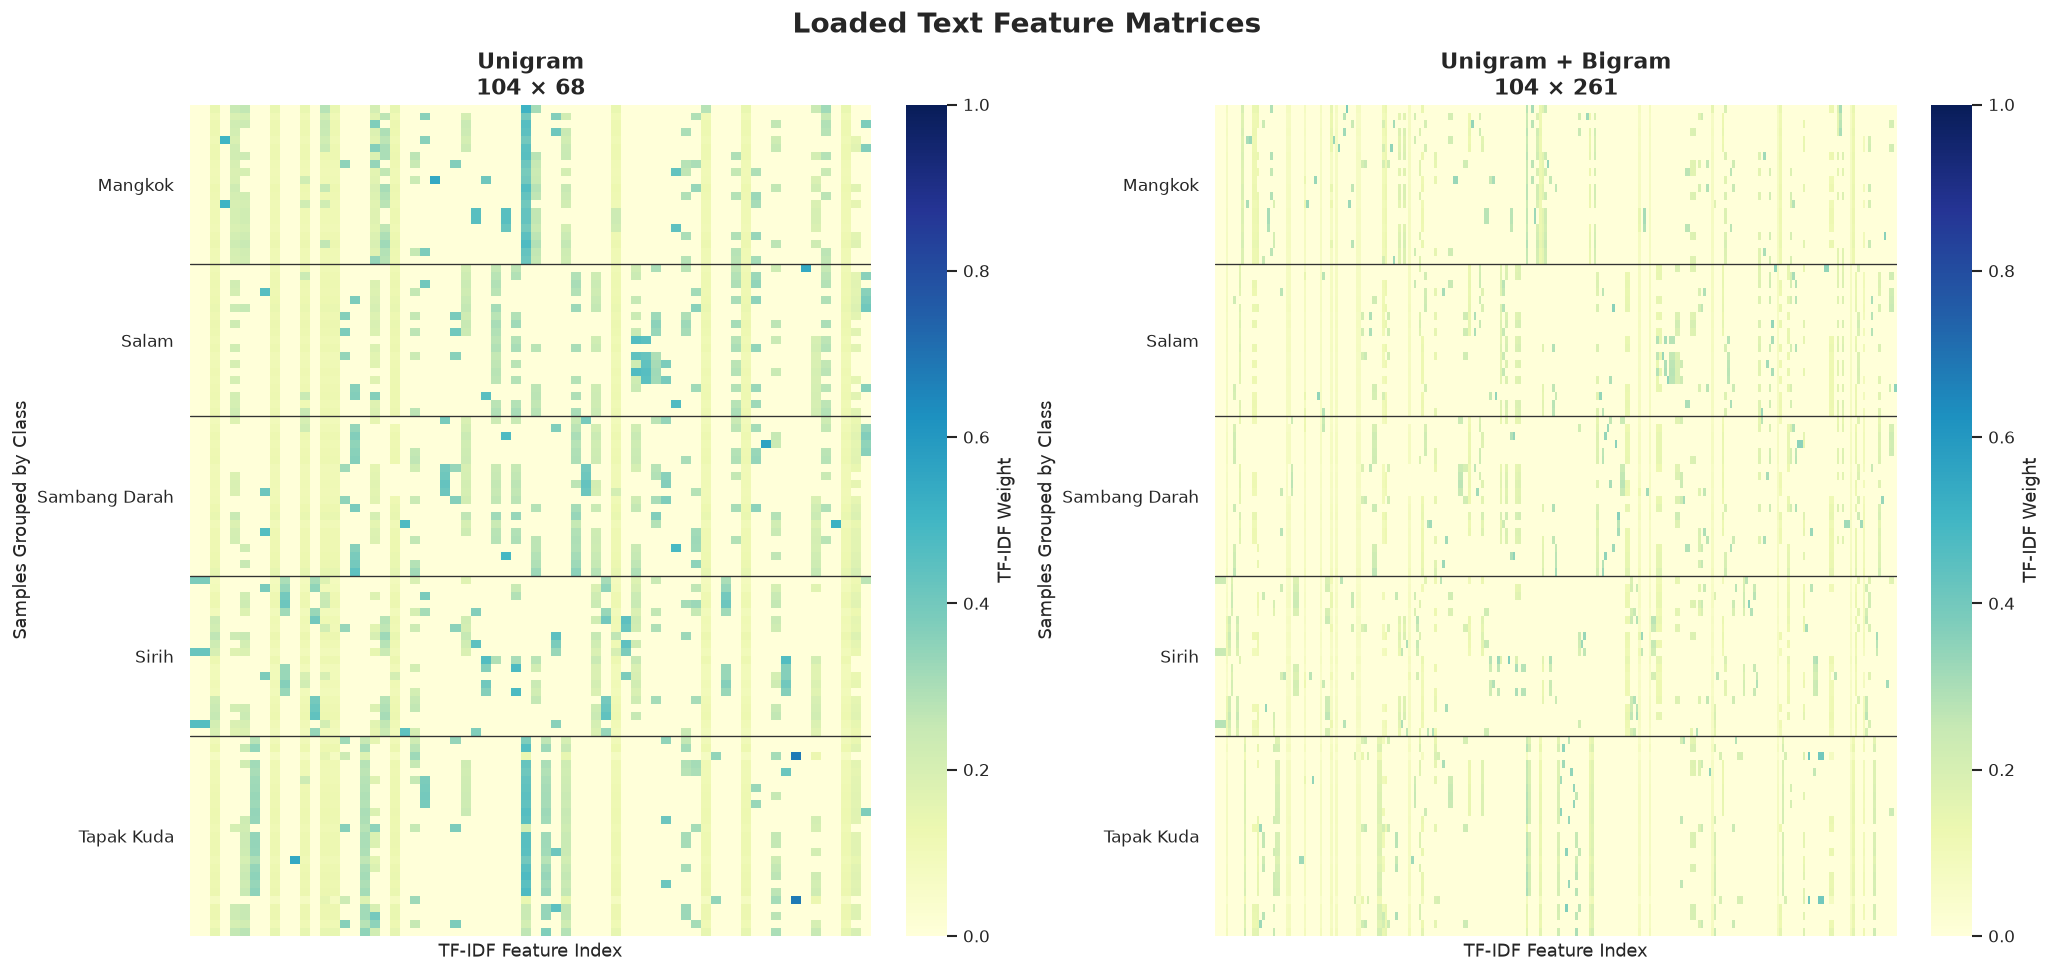

[SAVED] 107_loaded_text_feature_matrices.png

10. TEXT LOADING SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Total samples,104
1,Total classes,5
2,TF-IDF configurations,2
3,Unigram matrix shape,"(104, 68)"
4,Combined matrix shape,"(104, 261)"
5,Verified payload artifacts,16
6,Aligned samples,104
7,Validation checks,80
8,Passed checks,80
9,Failed checks,0



11. SAVING TEXT LOADING REPORTS
----------------------------------------------------------------------
[SAVED] 368_text_artifact_integrity.csv
[SAVED] 369_loaded_text_matrix_summary.csv
[SAVED] 370_text_vocabulary_integrity.csv
[SAVED] 371_text_visual_identity_alignment.csv
[SAVED] 372_text_loading_validation.csv
[SAVED] 373_loaded_text_class_distribution.csv
[SAVED] 374_text_loading_summary.csv

FINAL TEXT FEATURE LOADING SUMMARY

DATASET INFORMATION
----------------------------------------------------------------------
Text samples      : 104
Visual samples    : 104
Aligned samples   : 104
Plant classes     : 5

TEXT FEATURE MATRICES
----------------------------------------------------------------------
Unigram features  : (104, 68)
Combined features : (104, 261)

ARTIFACT INFORMATION
----------------------------------------------------------------------
Verified payloads : 16/16
Loaded vectorizers: 2

VALIDATION
----------------------------------------------------------------------

MULTIMODAL FUSION - EUCLIDEAN DISTANCE CALCULATION
[PASS] Previous processing stages validated.

1. DISTANCE CALCULATION CONFIGURATION
----------------------------------------------------------------------
Distance method       : euclidean
Expected samples      : 104
Expected features     : 143
Numerical tolerance   : 1e-10
Cross-check tolerance : 1e-06
Triangle tests        : 5000
Analysis scope        : Full-Gallery Exploratory Development

2. INPUT VISUAL FEATURES
----------------------------------------------------------------------
Feature matrix: (104, 143)
Sample IDs    : (104,)
Class labels  : (104,)
[PASS] Visual feature input ready.

3. PAIRWISE EUCLIDEAN DISTANCE CALCULATION
----------------------------------------------------------------------
Distance matrix shape: (104, 104)
Calculation time: 5.6182 ms
Distance matrix dtype: float64


,leaf_165d2f32c7fda707,leaf_8473270c3702f48b,leaf_8f425d66b1e193b9,leaf_0ebc8f4f3ee9c8d5,leaf_b0c5f55e42499cae
leaf_165d2f32c7fda707,0.000000,2.428759,2.502255,2.243289,2.390537
leaf_8473270c3702f48b,2.428759,0.000000,0.503673,0.627318,0.638484
leaf_8f425d66b1e193b9,2.502255,0.503673,0.000000,0.588122,0.650970
leaf_0ebc8f4f3ee9c8d5,2.243289,0.627318,0.588122,0.000000,0.664264
leaf_b0c5f55e42499cae,2.390537,0.638484,0.650970,0.664264,0.000000



4. INDEPENDENT IMPLEMENTATION CROSS-CHECK
----------------------------------------------------------------------
SciPy calculation time  : 5.6182 ms
Sklearn calculation time: 36.6941 ms
Maximum difference      : 2.665e-15

5. BASIC MATRIX VALIDATION
----------------------------------------------------------------------
Maximum diagonal error: 0.000e+00
Maximum symmetry error: 0.000e+00
Minimum distance: 0.000000
Maximum distance: 5.366333

6. UNIQUE SAMPLE PAIR INVENTORY
----------------------------------------------------------------------
Total unique pairs : 5356
Within-class pairs: 1041
Cross-class pairs : 4315
Near-zero distance pairs: 0

7. MANUAL DISTANCE VERIFICATION
----------------------------------------------------------------------


,pair_label,manual_euclidean_distance,scipy_euclidean_distance,manual_absolute_error
0,Within - Mangkok,2.428759,2.428759,0.0
1,Within - Salam,2.494229,2.494229,0.0
2,Within - Sambang Darah,2.222246,2.222246,0.0
3,Within - Sirih,1.039870,1.039870,0.0
4,Within - Tapak Kuda,1.358410,1.358410,0.0
5,Cross - Mangkok / Salam,3.417659,3.417659,0.0
6,Cross - Salam / Sambang Darah,2.333851,2.333851,0.0
7,Cross - Sambang Darah / Sirih,1.973050,1.973050,0.0
8,Cross - Sirih / Tapak Kuda,1.883283,1.883283,0.0
9,Cross - Tapak Kuda / Mangkok,2.547943,2.547943,0.0


Maximum manual calculation error: 4.441e-16
Maximum group decomposition error: 8.882e-16

8. TRIANGLE INEQUALITY VALIDATION
----------------------------------------------------------------------
Random index triples tested: 5000
Maximum triangle inequality violation: 0.000e+00
Triangle inequality: Passed

9. ROW ORDER INVARIANCE
----------------------------------------------------------------------
Maximum permutation difference: 0.000e+00

10. NEAREST NEIGHBOR PREVIEW
----------------------------------------------------------------------


,query_sample_id,query_class,rank,retrieved_sample_id,retrieved_class,euclidean_distance,self_match_excluded
0,leaf_165d2f32c7fda707,Mangkok,1,leaf_a6da65cb0493ceef,Mangkok,1.231581,True
1,leaf_165d2f32c7fda707,Mangkok,2,leaf_ac5e952a9ae56c36,Sambang Darah,1.253823,True
2,leaf_165d2f32c7fda707,Mangkok,3,leaf_4de65b11758965f6,Mangkok,1.408892,True
3,leaf_165d2f32c7fda707,Mangkok,4,leaf_12439b9ebf0eb8d3,Mangkok,1.438785,True
4,leaf_165d2f32c7fda707,Mangkok,5,leaf_c9d8d87fbc748d16,Mangkok,1.465237,True
5,leaf_c29e2560b188fb2c,Salam,1,leaf_22bf36f7b3abd78c,Tapak Kuda,1.770577,True
6,leaf_c29e2560b188fb2c,Salam,2,leaf_1ebaf9512209a61f,Salam,1.836590,True
7,leaf_c29e2560b188fb2c,Salam,3,leaf_68b0c81b496519cd,Salam,1.861226,True
8,leaf_c29e2560b188fb2c,Salam,4,leaf_8f8d177305fb06f2,Tapak Kuda,1.870957,True
9,leaf_c29e2560b188fb2c,Salam,5,leaf_0a8999109a734f1d,Salam,2.095505,True



11. DISTANCE MATRIX SUMMARY
----------------------------------------------------------------------


,0
distance_method,Euclidean
feature_source,visual_features_normalized.npy
number_of_samples,104
feature_dimension,143
matrix_rows,104
matrix_columns,104
matrix_dtype,float64
total_matrix_entries,10816
unique_off_diagonal_pairs,5356
within_class_pairs,1041



12. EUCLIDEAN DISTANCE VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Input Data,Normalized visual matrix dimensions valid,True,Passed
1,Input Data,Visual matrix contains finite values,True,Passed
2,Input Data,Visual sample IDs unique,True,Passed
3,Input Data,Sample ID and label order preserved,True,Passed
4,Cross-Implementation,SciPy and sklearn Euclidean distances consistent,True,Passed
5,Distance Matrix,Distance matrix shape is 104 x 104,True,Passed
6,Distance Matrix,Distance matrix uses float64,True,Passed
7,Distance Matrix,All distance values finite,True,Passed
8,Distance Matrix,All Euclidean distances nonnegative,True,Passed
9,Distance Matrix,Diagonal distances equal zero,True,Passed


[PASS] All Euclidean distance checks passed.


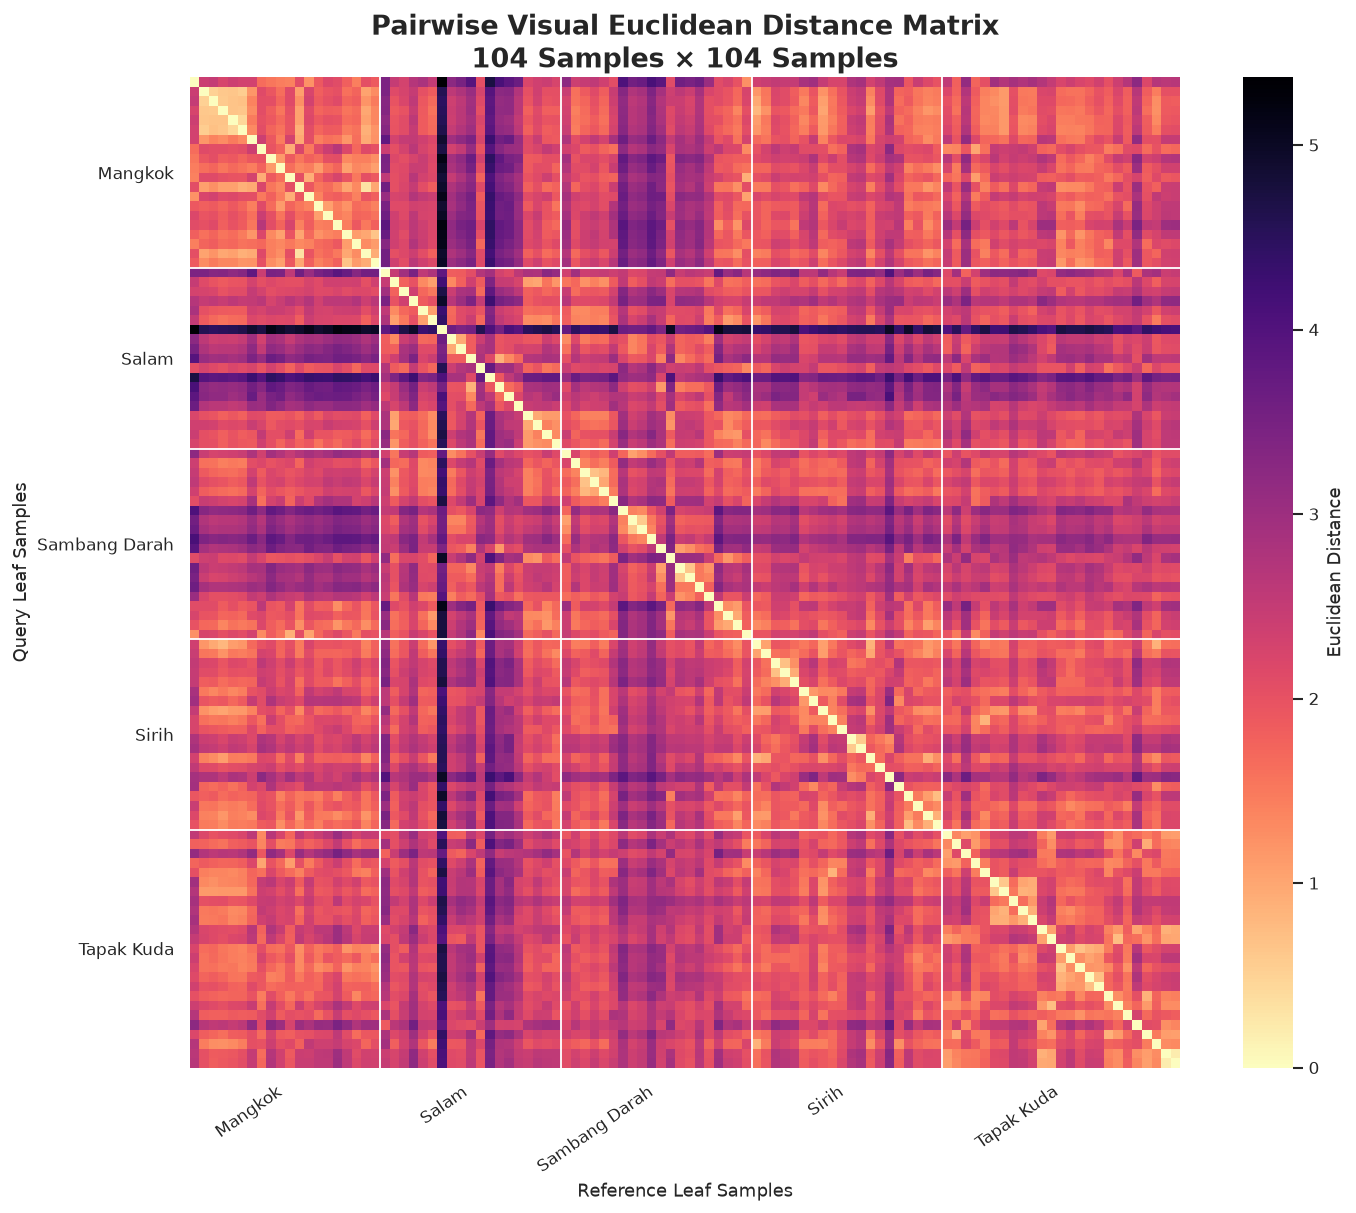

[SAVED] 112_visual_euclidean_distance_matrix.png


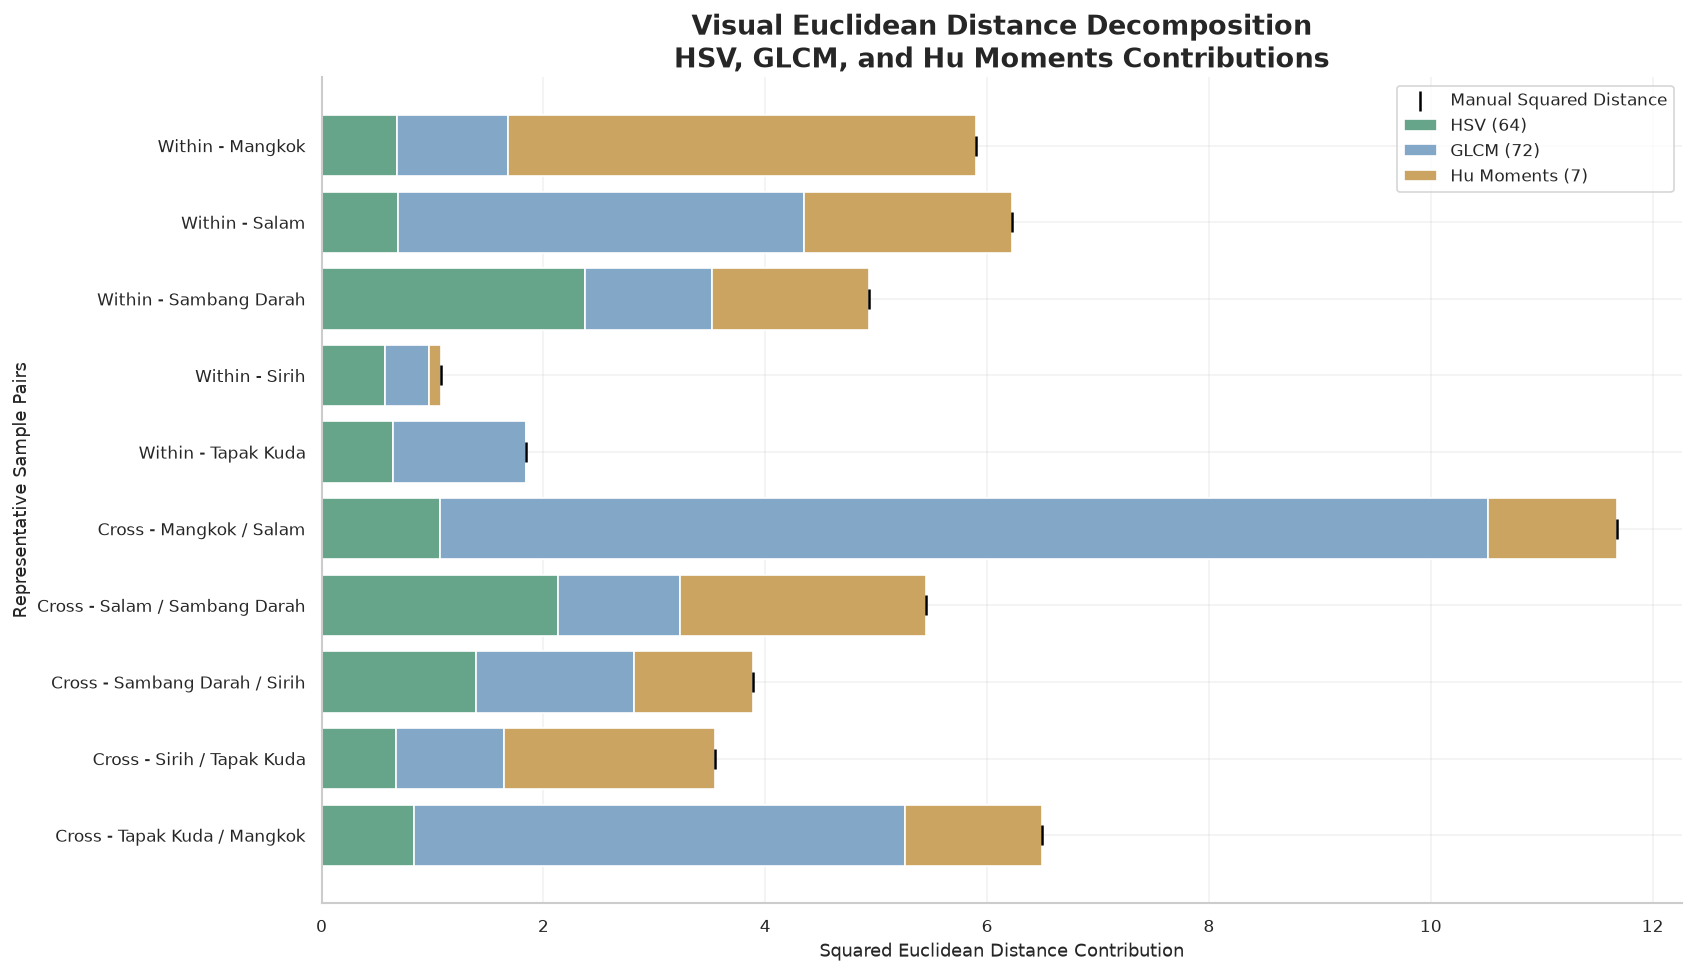

[SAVED] 113_visual_euclidean_distance_decomposition.png

13. FINAL CELL SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Input visual matrix,"(104, 143)"
1,Distance matrix,"(104, 104)"
2,Unique sample pairs,5356
3,Within-class pairs,1041
4,Cross-class pairs,4315
5,Near-zero off-diagonal pairs,0
6,Maximum symmetry error,0.0
7,Maximum diagonal error,0.0
8,Maximum manual error,0.0
9,Maximum sklearn cross-check error,0.0



14. SAVING EUCLIDEAN DISTANCE REPORTS
----------------------------------------------------------------------
[SAVED] 390_visual_euclidean_distance_summary.csv
[SAVED] 391_visual_euclidean_distance_validation.csv
[SAVED] 392_visual_euclidean_manual_pairs.csv
[SAVED] 393_visual_euclidean_group_contributions.csv
[SAVED] 394_visual_euclidean_neighbor_preview.csv
[SAVED] 395_visual_euclidean_pair_inventory.csv
[SAVED] 396_visual_euclidean_cell_summary.csv

FINAL VISUAL EUCLIDEAN DISTANCE SUMMARY

DATASET INFORMATION
----------------------------------------------------------------------
Total samples       : 104
Visual dimensions   : 143
Distance matrix     : (104, 104)

SAMPLE PAIRS
----------------------------------------------------------------------
Unique pairs        : 5356
Within-class pairs  : 1041
Cross-class pairs   : 4315

DISTANCE MATRIX PROPERTIES
----------------------------------------------------------------------
Minimum pair distance : 0.208826
Maximum pair distance : 5.36

In [10]:
# ============================================================
# CELL 8 - EUCLIDEAN DISTANCE CALCULATION
# ============================================================

print("MULTIMODAL FUSION - EUCLIDEAN DISTANCE CALCULATION")
print("=" * 70)

VISUAL_DISTANCE_CALCULATION_COMPLETED = False
VISUAL_EUCLIDEAN_DISTANCE_COMPLETED = False


# ============================================================
# 1. VALIDATE PREVIOUS STAGES
# ============================================================

required_stages = [
    "FUSION_LIBRARIES_IMPORTED",
    "FUSION_PATH_CONFIGURATION_COMPLETED",
    "VISUAL_FEATURE_LOADING_COMPLETED",
    "TEXT_FEATURE_LOADING_COMPLETED",
    "MULTIMODAL_DATASET_VALIDATION_COMPLETED",
    "FUSION_CONFIGURATION_COMPLETED"
]

for stage in required_stages:
    assert globals().get(stage, False), (
        f"{stage} is not completed."
    )

assert multimodal_validation_df["passed"].all()
assert fusion_configuration_validation_df["passed"].all()

assert FUSION_VISUAL_DISTANCE_METHOD == "euclidean"

print("[PASS] Previous processing stages validated.")


# ============================================================
# 2. DISTANCE CALCULATION CONFIGURATION
# ============================================================

VISUAL_DISTANCE_EXPECTED_SAMPLES = 104
VISUAL_DISTANCE_EXPECTED_DIMENSION = 143

VISUAL_DISTANCE_TOLERANCE = 1e-10

# sklearn's norm-expansion formula may produce small
# round-off differences for very close vectors.
# This tolerance is used only for cross-implementation
# comparison, not for changing stored distances.

VISUAL_DISTANCE_CROSSCHECK_TOLERANCE = 1e-6

VISUAL_DISTANCE_TRIANGLE_TESTS = 5000

VISUAL_DISTANCE_NEIGHBOR_PREVIEW_K = 5

VISUAL_DISTANCE_RANDOM_STATE = 42

VISUAL_DISTANCE_SCOPE = (
    "Full-Gallery Exploratory Development"
)

visual_distance_validation_records = []
visual_distance_figure_paths = []


def register_visual_distance_check(
    category,
    name,
    passed
):
    visual_distance_validation_records.append({
        "category": category,
        "validation_check": name,
        "passed": bool(passed),
        "status": "Passed" if passed else "Failed"
    })


def save_visual_distance_figure(fig, filename):

    output_path = FUSION_FIGURES_DIR / filename

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    visual_distance_figure_paths.append(output_path)

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


print("\n1. DISTANCE CALCULATION CONFIGURATION")
print("-" * 70)

print("Distance method       :", FUSION_VISUAL_DISTANCE_METHOD)
print("Expected samples      :", VISUAL_DISTANCE_EXPECTED_SAMPLES)
print("Expected features     :", VISUAL_DISTANCE_EXPECTED_DIMENSION)
print("Numerical tolerance   :", VISUAL_DISTANCE_TOLERANCE)
print("Cross-check tolerance :", VISUAL_DISTANCE_CROSSCHECK_TOLERANCE)
print("Triangle tests        :", VISUAL_DISTANCE_TRIANGLE_TESTS)
print("Analysis scope        :", VISUAL_DISTANCE_SCOPE)


# ============================================================
# 3. PREPARE VISUAL FEATURE MATRIX
# ============================================================

# Use the main normalized visual representation.
# Do not standardize, refit, or reorder features.

visual_distance_features = np.asarray(
    multimodal_visual_features,
    dtype=np.float64
)

visual_distance_sample_ids = np.asarray(
    multimodal_sample_ids,
    dtype=str
)

visual_distance_labels = np.asarray(
    multimodal_labels,
    dtype=str
)

visual_distance_n_samples = (
    visual_distance_features.shape[0]
)

assert visual_distance_features.shape == (104, 143)

assert np.isfinite(
    visual_distance_features
).all()

assert np.array_equal(
    visual_distance_sample_ids,
    visual_sample_ids
)

assert np.array_equal(
    visual_distance_labels,
    visual_labels
)

assert len(np.unique(
    visual_distance_sample_ids
)) == visual_distance_n_samples

register_visual_distance_check(
    "Input Data",
    "Normalized visual matrix dimensions valid",
    visual_distance_features.shape == (104, 143)
)

register_visual_distance_check(
    "Input Data",
    "Visual matrix contains finite values",
    np.isfinite(visual_distance_features).all()
)

register_visual_distance_check(
    "Input Data",
    "Visual sample IDs unique",
    len(np.unique(visual_distance_sample_ids))
    == visual_distance_n_samples
)

register_visual_distance_check(
    "Input Data",
    "Sample ID and label order preserved",
    np.array_equal(
        visual_distance_sample_ids,
        multimodal_sample_ids
    )
    and np.array_equal(
        visual_distance_labels,
        multimodal_labels
    )
)

print("\n2. INPUT VISUAL FEATURES")
print("-" * 70)

print("Feature matrix:", visual_distance_features.shape)
print("Sample IDs    :", visual_distance_sample_ids.shape)
print("Class labels  :", visual_distance_labels.shape)

print("[PASS] Visual feature input ready.")


# ============================================================
# 4. CALCULATE PAIRWISE EUCLIDEAN DISTANCES
# ============================================================

# Main calculation uses scipy.spatial.distance.cdist.
#
# D[i, j] = sqrt(sum_k((X[i,k] - X[j,k]) ** 2))
#
# scipy cdist computes distances directly and avoids
# some cancellation issues from norm-expansion formulas.

visual_distance_start_time = time.perf_counter()

visual_euclidean_distance_matrix = cdist(
    visual_distance_features,
    visual_distance_features,
    metric="euclidean"
)

visual_distance_calculation_time_ms = (
    time.perf_counter()
    - visual_distance_start_time
) * 1000

# Reusable aliases for subsequent cells.

visual_distance_matrix = (
    visual_euclidean_distance_matrix
)

visual_pairwise_distance_matrix = (
    visual_euclidean_distance_matrix
)

print("\n3. PAIRWISE EUCLIDEAN DISTANCE CALCULATION")
print("-" * 70)

print(
    "Distance matrix shape:",
    visual_euclidean_distance_matrix.shape
)

print(
    "Calculation time:",
    f"{visual_distance_calculation_time_ms:.4f} ms"
)

print(
    "Distance matrix dtype:",
    visual_euclidean_distance_matrix.dtype
)

display(
    pd.DataFrame(
        visual_euclidean_distance_matrix[:5, :5],
        index=visual_distance_sample_ids[:5],
        columns=visual_distance_sample_ids[:5]
    ).round(6)
)


# ============================================================
# 5. CALCULATE SKLEARN REFERENCE DISTANCES
# ============================================================

# Independent implementation used as a cross-check.
# This matrix is not used as the main output.

sklearn_distance_start_time = time.perf_counter()

visual_euclidean_sklearn_reference = (
    euclidean_distances(
        visual_distance_features,
        visual_distance_features
    )
)

visual_sklearn_calculation_time_ms = (
    time.perf_counter()
    - sklearn_distance_start_time
) * 1000

visual_distance_crosscheck_difference = float(
    np.max(
        np.abs(
            visual_euclidean_distance_matrix
            - visual_euclidean_sklearn_reference
        )
    )
)

register_visual_distance_check(
    "Cross-Implementation",
    "SciPy and sklearn Euclidean distances consistent",
    visual_distance_crosscheck_difference
    <= VISUAL_DISTANCE_CROSSCHECK_TOLERANCE
)

print("\n4. INDEPENDENT IMPLEMENTATION CROSS-CHECK")
print("-" * 70)

print(
    "SciPy calculation time  :",
    f"{visual_distance_calculation_time_ms:.4f} ms"
)

print(
    "Sklearn calculation time:",
    f"{visual_sklearn_calculation_time_ms:.4f} ms"
)

print(
    "Maximum difference      :",
    f"{visual_distance_crosscheck_difference:.3e}"
)


# ============================================================
# 6. VALIDATE BASIC DISTANCE MATRIX PROPERTIES
# ============================================================

distance_matrix = visual_euclidean_distance_matrix

distance_diagonal = np.diag(distance_matrix)

distance_symmetry_error = float(
    np.max(
        np.abs(
            distance_matrix - distance_matrix.T
        )
    )
)

distance_diagonal_error = float(
    np.max(
        np.abs(distance_diagonal)
    )
)

distance_minimum = float(
    distance_matrix.min()
)

distance_maximum = float(
    distance_matrix.max()
)

basic_distance_checks = {

    "Distance matrix shape is 104 x 104":
        distance_matrix.shape == (104, 104),

    "Distance matrix uses float64":
        distance_matrix.dtype == np.float64,

    "All distance values finite":
        np.isfinite(distance_matrix).all(),

    "All Euclidean distances nonnegative":
        np.all(
            distance_matrix
            >= -VISUAL_DISTANCE_TOLERANCE
        ),

    "Diagonal distances equal zero":
        distance_diagonal_error
        <= VISUAL_DISTANCE_TOLERANCE,

    "Distance matrix is symmetric":
        distance_symmetry_error
        <= VISUAL_DISTANCE_TOLERANCE,

    "Maximum distance is positive":
        distance_maximum > 0,

    "Minimum distance is zero":
        np.isclose(
            distance_minimum,
            0.0,
            atol=VISUAL_DISTANCE_TOLERANCE
        )
}

for check_name, passed in basic_distance_checks.items():

    register_visual_distance_check(
        "Distance Matrix",
        check_name,
        passed
    )

print("\n5. BASIC MATRIX VALIDATION")
print("-" * 70)

print(
    "Maximum diagonal error:",
    f"{distance_diagonal_error:.3e}"
)

print(
    "Maximum symmetry error:",
    f"{distance_symmetry_error:.3e}"
)

print(
    "Minimum distance:",
    f"{distance_minimum:.6f}"
)

print(
    "Maximum distance:",
    f"{distance_maximum:.6f}"
)


# ============================================================
# 7. ANALYZE UNIQUE SAMPLE PAIRS
# ============================================================

# Exclude diagonal entries.
# Use only the upper triangle to prevent double counting.

visual_pair_i, visual_pair_j = np.triu_indices(
    visual_distance_n_samples,
    k=1
)

visual_unique_pair_distances = distance_matrix[
    visual_pair_i,
    visual_pair_j
]

visual_same_class_pair_mask = (
    visual_distance_labels[visual_pair_i]
    == visual_distance_labels[visual_pair_j]
)

visual_unique_pair_count = len(
    visual_unique_pair_distances
)

visual_within_class_pair_count = int(
    visual_same_class_pair_mask.sum()
)

visual_cross_class_pair_count = int(
    (~visual_same_class_pair_mask).sum()
)

expected_unique_pairs = (
    visual_distance_n_samples
    * (visual_distance_n_samples - 1)
    // 2
)

class_sample_counts = Counter(
    visual_distance_labels
)

expected_within_pairs = sum(
    count * (count - 1) // 2
    for count in class_sample_counts.values()
)

expected_cross_pairs = (
    expected_unique_pairs - expected_within_pairs
)

register_visual_distance_check(
    "Pair Inventory",
    "Unique pair count correct",
    visual_unique_pair_count == expected_unique_pairs
)

register_visual_distance_check(
    "Pair Inventory",
    "Within-class pair count correct",
    visual_within_class_pair_count
    == expected_within_pairs
)

register_visual_distance_check(
    "Pair Inventory",
    "Cross-class pair count correct",
    visual_cross_class_pair_count
    == expected_cross_pairs
)

register_visual_distance_check(
    "Pair Inventory",
    "Within and cross-class counts reconcile",
    visual_within_class_pair_count
    + visual_cross_class_pair_count
    == visual_unique_pair_count
)

visual_zero_distance_pair_count = int(
    np.sum(
        visual_unique_pair_distances
        <= VISUAL_DISTANCE_TOLERANCE
    )
)

print("\n6. UNIQUE SAMPLE PAIR INVENTORY")
print("-" * 70)

print(
    "Total unique pairs :",
    visual_unique_pair_count
)

print(
    "Within-class pairs:",
    visual_within_class_pair_count
)

print(
    "Cross-class pairs :",
    visual_cross_class_pair_count
)

print(
    "Near-zero distance pairs:",
    visual_zero_distance_pair_count
)


# ============================================================
# 8. VERIFY EUCLIDEAN DISTANCE MANUALLY
# ============================================================

# Select one within-class pair from each class
# and one cross-class pair from each neighboring
# pair of class names.
#
# These are diagnostic examples, not evaluation queries.

visual_unique_classes = sorted(
    np.unique(visual_distance_labels)
)

visual_representative_indices = {
    class_name: np.flatnonzero(
        visual_distance_labels == class_name
    )
    for class_name in visual_unique_classes
}

visual_selected_pairs = []

# Five within-class examples.

for class_name in visual_unique_classes:

    indices = visual_representative_indices[
        class_name
    ]

    assert len(indices) >= 2

    visual_selected_pairs.append({
        "pair_type": "Within Class",
        "pair_label": f"Within - {class_name}",
        "index_i": int(indices[0]),
        "index_j": int(indices[1])
    })

# Five cross-class examples.

for class_index, class_name in enumerate(
    visual_unique_classes
):

    next_class = visual_unique_classes[
        (class_index + 1)
        % len(visual_unique_classes)
    ]

    index_i = int(
        visual_representative_indices[
            class_name
        ][0]
    )

    index_j = int(
        visual_representative_indices[
            next_class
        ][0]
    )

    visual_selected_pairs.append({
        "pair_type": "Cross Class",
        "pair_label": (
            f"Cross - {class_name} / {next_class}"
        ),
        "index_i": index_i,
        "index_j": index_j
    })


visual_manual_pair_records = []
visual_group_contribution_records = []

for pair in visual_selected_pairs:

    i = pair["index_i"]
    j = pair["index_j"]

    feature_difference = (
        visual_distance_features[i]
        - visual_distance_features[j]
    )

    # Explicit calculation from the 143 feature values.

    manual_squared_distance = float(
        np.sum(
            feature_difference ** 2,
            dtype=np.float64
        )
    )

    manual_distance = float(
        np.sqrt(manual_squared_distance)
    )

    scipy_distance = float(
        distance_matrix[i, j]
    )

    sklearn_distance = float(
        visual_euclidean_sklearn_reference[i, j]
    )

    absolute_error = abs(
        manual_distance - scipy_distance
    )

    visual_manual_pair_records.append({
        "pair_type": pair["pair_type"],
        "pair_label": pair["pair_label"],
        "row_i": i,
        "row_j": j,
        "sample_id_i": visual_distance_sample_ids[i],
        "sample_id_j": visual_distance_sample_ids[j],
        "class_i": visual_distance_labels[i],
        "class_j": visual_distance_labels[j],
        "manual_squared_distance":
            manual_squared_distance,
        "manual_euclidean_distance":
            manual_distance,
        "scipy_euclidean_distance":
            scipy_distance,
        "sklearn_euclidean_distance":
            sklearn_distance,
        "manual_absolute_error":
            absolute_error
    })

    # Decompose squared Euclidean distance into
    # HSV, GLCM, and Hu Moments contributions.

    group_squared_distances = {}

    for group_name in VISUAL_FEATURE_GROUP_ORDER:

        group_slice = VISUAL_FEATURE_GROUP_SLICES[
            group_name
        ]

        group_difference = feature_difference[
            group_slice
        ]

        group_squared_distances[group_name] = float(
            np.sum(
                group_difference ** 2,
                dtype=np.float64
            )
        )

    summed_group_distance = sum(
        group_squared_distances.values()
    )

    visual_group_contribution_records.append({
        "pair_type": pair["pair_type"],
        "pair_label": pair["pair_label"],
        "sample_id_i": visual_distance_sample_ids[i],
        "sample_id_j": visual_distance_sample_ids[j],
        "hsv_squared_distance":
            group_squared_distances["HSV"],
        "glcm_squared_distance":
            group_squared_distances["GLCM"],
        "hu_squared_distance":
            group_squared_distances["Hu Moments"],
        "summed_group_squared_distance":
            summed_group_distance,
        "manual_squared_distance":
            manual_squared_distance,
        "decomposition_absolute_error":
            abs(
                summed_group_distance
                - manual_squared_distance
            )
    })


visual_euclidean_manual_pairs_df = pd.DataFrame(
    visual_manual_pair_records
)

visual_euclidean_group_contributions_df = pd.DataFrame(
    visual_group_contribution_records
)

manual_maximum_error = float(
    visual_euclidean_manual_pairs_df[
        "manual_absolute_error"
    ].max()
)

group_maximum_error = float(
    visual_euclidean_group_contributions_df[
        "decomposition_absolute_error"
    ].max()
)

register_visual_distance_check(
    "Manual Verification",
    "Ten representative sample pairs checked",
    len(visual_euclidean_manual_pairs_df) == 10
)

register_visual_distance_check(
    "Manual Verification",
    "Manual Euclidean calculation consistent",
    manual_maximum_error
    <= VISUAL_DISTANCE_TOLERANCE
)

register_visual_distance_check(
    "Manual Verification",
    "HSV-GLCM-Hu squared-distance decomposition valid",
    group_maximum_error
    <= VISUAL_DISTANCE_TOLERANCE
)

print("\n7. MANUAL DISTANCE VERIFICATION")
print("-" * 70)

display(
    visual_euclidean_manual_pairs_df[[
        "pair_label",
        "manual_euclidean_distance",
        "scipy_euclidean_distance",
        "manual_absolute_error"
    ]].round(10)
)

print(
    "Maximum manual calculation error:",
    f"{manual_maximum_error:.3e}"
)

print(
    "Maximum group decomposition error:",
    f"{group_maximum_error:.3e}"
)


# ============================================================
# 9. VERIFY TRIANGLE INEQUALITY
# ============================================================

# Euclidean distance must satisfy:
#
# d(i, j) <= d(i, k) + d(k, j)
#
# Test 5000 deterministic random index triples.

visual_distance_rng = np.random.default_rng(
    VISUAL_DISTANCE_RANDOM_STATE
)

triangle_indices = visual_distance_rng.integers(
    low=0,
    high=visual_distance_n_samples,
    size=(VISUAL_DISTANCE_TRIANGLE_TESTS, 3)
)

triangle_i = triangle_indices[:, 0]
triangle_j = triangle_indices[:, 1]
triangle_k = triangle_indices[:, 2]

triangle_left = distance_matrix[
    triangle_i,
    triangle_j
]

triangle_right = (
    distance_matrix[triangle_i, triangle_k]
    +
    distance_matrix[triangle_k, triangle_j]
)

triangle_violation = (
    triangle_left - triangle_right
)

triangle_max_violation = float(
    np.maximum(
        triangle_violation,
        0.0
    ).max()
)

triangle_passed = bool(
    np.all(
        triangle_left
        <= triangle_right
        + VISUAL_DISTANCE_TOLERANCE
    )
)

register_visual_distance_check(
    "Metric Properties",
    "Sampled triangle inequality satisfied",
    triangle_passed
)

print("\n8. TRIANGLE INEQUALITY VALIDATION")
print("-" * 70)

print(
    "Random index triples tested:",
    VISUAL_DISTANCE_TRIANGLE_TESTS
)

print(
    "Maximum triangle inequality violation:",
    f"{triangle_max_violation:.3e}"
)

print(
    "Triangle inequality:",
    "Passed" if triangle_passed else "Failed"
)


# ============================================================
# 10. VERIFY SAMPLE ORDER INVARIANCE
# ============================================================

# Reorder a diagnostic COPY of features.
# Reversing the permutation must reproduce the
# original pairwise distance matrix.
#
# This does not modify the original dataset.

permutation = visual_distance_rng.permutation(
    visual_distance_n_samples
)

permuted_features = visual_distance_features[
    permutation
]

permuted_distance_matrix = cdist(
    permuted_features,
    permuted_features,
    metric="euclidean"
)

expected_permuted_distances = distance_matrix[
    np.ix_(permutation, permutation)
]

permutation_maximum_error = float(
    np.max(
        np.abs(
            permuted_distance_matrix
            - expected_permuted_distances
        )
    )
)

register_visual_distance_check(
    "Metric Properties",
    "Pairwise distances invariant under simultaneous reordering",
    permutation_maximum_error
    <= VISUAL_DISTANCE_TOLERANCE
)

print("\n9. ROW ORDER INVARIANCE")
print("-" * 70)

print(
    "Maximum permutation difference:",
    f"{permutation_maximum_error:.3e}"
)


# ============================================================
# 11. PREVIEW NEAREST VISUAL NEIGHBORS
# ============================================================

# This is a technical ranking preview.
# Retrieval evaluation is not performed here.

visual_neighbor_preview_records = []

for query_class in visual_unique_classes:

    query_index = int(
        visual_representative_indices[
            query_class
        ][0]
    )

    candidate_indices = np.arange(
        visual_distance_n_samples
    )

    if FUSION_EXCLUDE_SELF_MATCH:

        candidate_indices = candidate_indices[
            candidate_indices != query_index
        ]

    # Ascending distance; ties resolved by sample ID.

    candidate_order = np.lexsort((
        visual_distance_sample_ids[
            candidate_indices
        ],
        distance_matrix[
            query_index,
            candidate_indices
        ]
    ))

    ranked_candidates = candidate_indices[
        candidate_order
    ]

    for rank, retrieved_index in enumerate(
        ranked_candidates[
            :VISUAL_DISTANCE_NEIGHBOR_PREVIEW_K
        ],
        start=1
    ):

        visual_neighbor_preview_records.append({
            "query_sample_id":
                visual_distance_sample_ids[query_index],
            "query_class":
                visual_distance_labels[query_index],
            "rank": rank,
            "retrieved_sample_id":
                visual_distance_sample_ids[retrieved_index],
            "retrieved_class":
                visual_distance_labels[retrieved_index],
            "euclidean_distance": float(
                distance_matrix[
                    query_index,
                    retrieved_index
                ]
            ),
            "self_match_excluded": (
                query_index != retrieved_index
            )
        })


visual_euclidean_neighbor_preview_df = pd.DataFrame(
    visual_neighbor_preview_records
)

neighbor_preview_valid = (
    len(visual_euclidean_neighbor_preview_df)
    ==
    len(visual_unique_classes)
    * VISUAL_DISTANCE_NEIGHBOR_PREVIEW_K
)

neighbor_self_exclusion_valid = (
    visual_euclidean_neighbor_preview_df[
        "self_match_excluded"
    ].all()
)

neighbor_ranking_valid = all(

    np.all(
        np.diff(
            group.sort_values("rank")[
                "euclidean_distance"
            ].to_numpy()
        )
        >= -VISUAL_DISTANCE_TOLERANCE
    )

    for _, group in (
        visual_euclidean_neighbor_preview_df
        .groupby("query_sample_id")
    )
)

neighbor_duplicate_valid = (
    ~visual_euclidean_neighbor_preview_df.duplicated(
        subset=[
            "query_sample_id",
            "retrieved_sample_id"
        ]
    )
).all()

register_visual_distance_check(
    "Neighbor Preview",
    "Five neighbors generated for each representative class",
    neighbor_preview_valid
)

register_visual_distance_check(
    "Neighbor Preview",
    "Self-matches excluded",
    neighbor_self_exclusion_valid
)

register_visual_distance_check(
    "Neighbor Preview",
    "Neighbors sorted by ascending distance",
    neighbor_ranking_valid
)

register_visual_distance_check(
    "Neighbor Preview",
    "No repeated retrieved sample per query",
    neighbor_duplicate_valid
)

print("\n10. NEAREST NEIGHBOR PREVIEW")
print("-" * 70)

display(
    visual_euclidean_neighbor_preview_df.round(6)
)


# ============================================================
# 12. CREATE DISTANCE MATRIX SUMMARY
# ============================================================

visual_euclidean_distance_summary_df = pd.DataFrame([{

    "distance_method": "Euclidean",

    "feature_source": (
        "visual_features_normalized.npy"
    ),

    "number_of_samples":
        visual_distance_n_samples,

    "feature_dimension":
        visual_distance_features.shape[1],

    "matrix_rows":
        distance_matrix.shape[0],

    "matrix_columns":
        distance_matrix.shape[1],

    "matrix_dtype":
        str(distance_matrix.dtype),

    "total_matrix_entries":
        int(distance_matrix.size),

    "unique_off_diagonal_pairs":
        visual_unique_pair_count,

    "within_class_pairs":
        visual_within_class_pair_count,

    "cross_class_pairs":
        visual_cross_class_pair_count,

    "minimum_distance":
        float(visual_unique_pair_distances.min()),

    "maximum_distance":
        float(visual_unique_pair_distances.max()),

    "mean_distance":
        float(visual_unique_pair_distances.mean()),

    "median_distance":
        float(np.median(
            visual_unique_pair_distances
        )),

    "std_distance":
        float(visual_unique_pair_distances.std()),

    "zero_distance_off_diagonal_pairs":
        visual_zero_distance_pair_count,

    "maximum_diagonal_error":
        distance_diagonal_error,

    "maximum_symmetry_error":
        distance_symmetry_error,

    "maximum_manual_error":
        manual_maximum_error,

    "maximum_cross_implementation_difference":
        visual_distance_crosscheck_difference,

    "maximum_triangle_violation":
        triangle_max_violation,

    "maximum_group_decomposition_error":
        group_maximum_error,

    "calculation_time_ms":
        visual_distance_calculation_time_ms,

    "sklearn_crosscheck_time_ms":
        visual_sklearn_calculation_time_ms,

    "self_match_excluded_from_pair_statistics":
        True,

    "visual_similarity_conversion_applied":
        False,

    "multimodal_fusion_applied":
        False,

    "independent_evaluation_completed":
        False,

    "analysis_scope":
        VISUAL_DISTANCE_SCOPE

}])

visual_euclidean_pair_inventory_df = pd.DataFrame([

    {
        "pair_type": "Within Class",
        "number_of_pairs":
            visual_within_class_pair_count
    },

    {
        "pair_type": "Cross Class",
        "number_of_pairs":
            visual_cross_class_pair_count
    }

])

print("\n11. DISTANCE MATRIX SUMMARY")
print("-" * 70)

display(
    visual_euclidean_distance_summary_df.T
)


# ============================================================
# 13. FINAL VALIDATION
# ============================================================

visual_euclidean_distance_validation_df = pd.DataFrame(
    visual_distance_validation_records
)

visual_distance_total_checks = len(
    visual_euclidean_distance_validation_df
)

visual_distance_passed_checks = int(
    visual_euclidean_distance_validation_df[
        "passed"
    ].sum()
)

visual_distance_failed_checks = (
    visual_distance_total_checks
    - visual_distance_passed_checks
)

print("\n12. EUCLIDEAN DISTANCE VALIDATION")
print("-" * 70)

display(
    visual_euclidean_distance_validation_df
)

# Save diagnostic validation before assertions.

visual_euclidean_distance_validation_df.to_csv(
    METRICS_DIR
    / "391_visual_euclidean_distance_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

assert visual_euclidean_distance_validation_df[
    "passed"
].all(), (
    visual_euclidean_distance_validation_df.loc[
        ~visual_euclidean_distance_validation_df[
            "passed"
        ]
    ].to_string(index=False)
)

print("[PASS] All Euclidean distance checks passed.")


# ============================================================
# 14. VISUALIZATION - EUCLIDEAN DISTANCE MATRIX
# ============================================================

# Sort samples by class ONLY for visualization.
# The actual distance matrix remains unchanged.

visual_distance_plot_order = np.argsort(
    visual_distance_labels,
    kind="stable"
)

visual_distance_plot_labels = (
    visual_distance_labels[
        visual_distance_plot_order
    ]
)

visual_distance_plot_matrix = distance_matrix[
    np.ix_(
        visual_distance_plot_order,
        visual_distance_plot_order
    )
]

class_boundaries = np.flatnonzero(
    visual_distance_plot_labels[1:]
    != visual_distance_plot_labels[:-1]
) + 1

class_starts = np.r_[0, class_boundaries]

class_ends = np.r_[
    class_boundaries,
    visual_distance_n_samples
]

class_centers = (
    class_starts + class_ends
) / 2

fig, ax = plt.subplots(
    figsize=(12, 10),
    constrained_layout=True
)

sns.heatmap(
    visual_distance_plot_matrix,
    cmap=DISTANCE_CMAP,
    vmin=0,
    xticklabels=False,
    yticklabels=False,
    square=True,
    cbar_kws={
        "label": "Euclidean Distance"
    },
    ax=ax
)

for boundary in class_boundaries:

    ax.axhline(
        boundary,
        color="white",
        linewidth=1.1
    )

    ax.axvline(
        boundary,
        color="white",
        linewidth=1.1
    )

ax.set_xticks(class_centers)
ax.set_yticks(class_centers)

ax.set_xticklabels(
    visual_distance_plot_labels[class_starts],
    rotation=35,
    ha="right"
)

ax.set_yticklabels(
    visual_distance_plot_labels[class_starts],
    rotation=0
)

ax.set_xlabel("Reference Leaf Samples")
ax.set_ylabel("Query Leaf Samples")

ax.set_title(
    "Pairwise Visual Euclidean Distance Matrix\n"
    "104 Samples × 104 Samples",
    fontsize=16,
    fontweight="bold"
)

save_visual_distance_figure(
    fig,
    "112_visual_euclidean_distance_matrix.png"
)


# ============================================================
# 15. VISUALIZATION - DISTANCE DECOMPOSITION
# ============================================================

# The bars represent squared Euclidean distance.
# Contributions are computed from normalized features.
#
# They do NOT represent predictive importance.

contribution_df = (
    visual_euclidean_group_contributions_df
    .copy()
)

pair_positions = np.arange(
    len(contribution_df)
)

hsv_values = contribution_df[
    "hsv_squared_distance"
].to_numpy()

glcm_values = contribution_df[
    "glcm_squared_distance"
].to_numpy()

hu_values = contribution_df[
    "hu_squared_distance"
].to_numpy()

fig, ax = plt.subplots(
    figsize=(14, 8),
    constrained_layout=True
)

ax.barh(
    pair_positions,
    hsv_values,
    color=FEATURE_GROUP_COLORS["HSV"],
    label="HSV (64)"
)

ax.barh(
    pair_positions,
    glcm_values,
    left=hsv_values,
    color=FEATURE_GROUP_COLORS["GLCM"],
    label="GLCM (72)"
)

ax.barh(
    pair_positions,
    hu_values,
    left=hsv_values + glcm_values,
    color=FEATURE_GROUP_COLORS["Hu Moments"],
    label="Hu Moments (7)"
)

# Manual squared distance should equal the stacked total.

ax.scatter(
    contribution_df[
        "manual_squared_distance"
    ],
    pair_positions,
    marker="|",
    s=140,
    color="black",
    label="Manual Squared Distance",
    zorder=4
)

ax.set_yticks(pair_positions)

ax.set_yticklabels(
    contribution_df["pair_label"]
)

ax.invert_yaxis()

ax.set_xlabel(
    "Squared Euclidean Distance Contribution"
)

ax.set_ylabel(
    "Representative Sample Pairs"
)

ax.set_title(
    "Visual Euclidean Distance Decomposition\n"
    "HSV, GLCM, and Hu Moments Contributions",
    fontsize=16,
    fontweight="bold"
)

ax.legend()

save_visual_distance_figure(
    fig,
    "113_visual_euclidean_distance_decomposition.png"
)


# ============================================================
# 16. CREATE FINAL CELL SUMMARY
# ============================================================

visual_distance_cell_summary_df = pd.DataFrame([

    ("Input visual matrix",
     str(visual_distance_features.shape)),

    ("Distance matrix",
     str(distance_matrix.shape)),

    ("Unique sample pairs",
     visual_unique_pair_count),

    ("Within-class pairs",
     visual_within_class_pair_count),

    ("Cross-class pairs",
     visual_cross_class_pair_count),

    ("Near-zero off-diagonal pairs",
     visual_zero_distance_pair_count),

    ("Maximum symmetry error",
     distance_symmetry_error),

    ("Maximum diagonal error",
     distance_diagonal_error),

    ("Maximum manual error",
     manual_maximum_error),

    ("Maximum sklearn cross-check error",
     visual_distance_crosscheck_difference),

    ("Maximum group decomposition error",
     group_maximum_error),

    ("Maximum triangle inequality violation",
     triangle_max_violation),

    ("Total validation checks",
     visual_distance_total_checks),

    ("Validation checks passed",
     visual_distance_passed_checks),

    ("Validation checks failed",
     visual_distance_failed_checks),

    ("Generated figures",
     len(visual_distance_figure_paths)),

    ("Visual feature order modified", False),

    ("Visual normalizer refitted", False),

    ("Distance-to-similarity applied", False),

    ("Fusion weights applied", False),

    ("Independent evaluation completed", False),

    ("Analysis scope", VISUAL_DISTANCE_SCOPE)

], columns=["Indicator", "Result"])

print("\n13. FINAL CELL SUMMARY")
print("-" * 70)

display(
    visual_distance_cell_summary_df
)


# ============================================================
# 17. SAVE EUCLIDEAN DISTANCE REPORTS
# ============================================================

visual_distance_reports = {

    "390_visual_euclidean_distance_summary.csv":
        visual_euclidean_distance_summary_df,

    "391_visual_euclidean_distance_validation.csv":
        visual_euclidean_distance_validation_df,

    "392_visual_euclidean_manual_pairs.csv":
        visual_euclidean_manual_pairs_df,

    "393_visual_euclidean_group_contributions.csv":
        visual_euclidean_group_contributions_df,

    "394_visual_euclidean_neighbor_preview.csv":
        visual_euclidean_neighbor_preview_df,

    "395_visual_euclidean_pair_inventory.csv":
        visual_euclidean_pair_inventory_df,

    "396_visual_euclidean_cell_summary.csv":
        visual_distance_cell_summary_df
}

print("\n14. SAVING EUCLIDEAN DISTANCE REPORTS")
print("-" * 70)

for filename, dataframe in (
    visual_distance_reports.items()
):

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ============================================================
# 18. FINAL COMPLETION CHECKS
# ============================================================

assert visual_euclidean_distance_validation_df[
    "passed"
].all()

assert visual_distance_failed_checks == 0

assert distance_matrix.shape == (104, 104)

assert np.isfinite(distance_matrix).all()

assert visual_unique_pair_count == 5356

assert visual_within_class_pair_count == 1041

assert visual_cross_class_pair_count == 4315

assert len(visual_distance_figure_paths) == 2

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in visual_distance_figure_paths
)

assert all(
    (METRICS_DIR / filename).is_file()
    and (METRICS_DIR / filename).stat().st_size > 0
    for filename in visual_distance_reports
)

VISUAL_DISTANCE_CALCULATION_COMPLETED = True
VISUAL_EUCLIDEAN_DISTANCE_COMPLETED = True


# ============================================================
# 19. PRINT FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)

print("FINAL VISUAL EUCLIDEAN DISTANCE SUMMARY")

print("=" * 70)

print("\nDATASET INFORMATION")
print("-" * 70)

print("Total samples       :", visual_distance_n_samples)
print("Visual dimensions   :", visual_distance_features.shape[1])
print("Distance matrix     :", distance_matrix.shape)

print("\nSAMPLE PAIRS")
print("-" * 70)

print("Unique pairs        :", visual_unique_pair_count)
print("Within-class pairs  :", visual_within_class_pair_count)
print("Cross-class pairs   :", visual_cross_class_pair_count)

print("\nDISTANCE MATRIX PROPERTIES")
print("-" * 70)

print(
    "Minimum pair distance :",
    f"{visual_unique_pair_distances.min():.6f}"
)

print(
    "Maximum pair distance :",
    f"{visual_unique_pair_distances.max():.6f}"
)

print(
    "Maximum symmetry error:",
    f"{distance_symmetry_error:.3e}"
)

print(
    "Maximum diagonal error:",
    f"{distance_diagonal_error:.3e}"
)

print(
    "Maximum manual error  :",
    f"{manual_maximum_error:.3e}"
)

print(
    "Maximum crosscheck error:",
    f"{visual_distance_crosscheck_difference:.3e}"
)

print("\nVALIDATION RESULTS")
print("-" * 70)

print(
    "Technical checks :",
    f"{visual_distance_passed_checks}/"
    f"{visual_distance_total_checks}"
)

print("Failed checks    :", visual_distance_failed_checks)
print("Generated reports:", len(visual_distance_reports))
print("Generated figures:", len(visual_distance_figure_paths))

print("\n[PASS] Visual Euclidean distances calculated.")
print("[PASS] Matrix shape and numerical values validated.")
print("[PASS] Symmetry and zero diagonal validated.")
print("[PASS] SciPy and sklearn results cross-checked.")
print("[PASS] Manual sample pair calculations verified.")
print("[PASS] Feature group decomposition verified.")
print("[PASS] Sampled triangle inequality validated.")
print("[PASS] Self-excluded nearest neighbors generated.")
print("[PASS] Reports and visualizations saved.")

print("\n[INFO] No visual features were modified.")
print("[INFO] Distance-to-similarity conversion is pending.")
print("[INFO] No multimodal score fusion performed.")
print("[INFO] Independent retrieval evaluation is pending.")

print("\n" + "=" * 70)

print("EUCLIDEAN DISTANCE CALCULATION COMPLETED SUCCESSFULLY")

print("=" * 70)

print("\nNext cell: Cell 9 - Visual Distance Analysis")

MULTIMODAL FUSION - VISUAL DISTANCE ANALYSIS
[PASS] Previous stages validated.

1. ANALYSIS CONFIGURATION
----------------------------------------------------------------------
Samples : 104
Pairs   : 5356
Scope   : Full-Gallery Exploratory Distance Analysis
Self-matches excluded: True

2. DISTANCE PAIR INVENTORY
----------------------------------------------------------------------
Total unique pairs : 5356
Within-class pairs: 1041
Cross-class pairs : 4315

3. GLOBAL DISTANCE DISTRIBUTIONS
----------------------------------------------------------------------


,group,number_of_pairs,minimum_distance,maximum_distance,mean_distance,median_distance,std_distance,q10_distance,q25_distance,q75_distance,q90_distance,zero_distance_pairs
0,All Unique Pairs,5356,0.208826,5.366333,2.300267,2.206678,0.664102,1.555359,1.871644,2.633547,3.159432,0
1,Within Class,1041,0.208826,4.964796,1.990486,1.924080,0.677157,1.191676,1.550984,2.354215,2.832232,0
2,Cross Class,4315,0.815054,5.366333,2.375002,2.279091,0.638803,1.677084,1.949336,2.690322,3.200626,0


Within-class mean : 1.990486
Cross-class mean  : 2.375002
Cross-minus-within gap: 0.384516
[OBSERVATION] Mean within-class distance is smaller than mean cross-class distance.

4. DISTRIBUTION SEPARATION DIAGNOSTICS
----------------------------------------------------------------------


,0
within_class_mean,1.990486
cross_class_mean,2.375002
cross_minus_within_mean_gap,0.384516
standardized_mean_separation,0.58414
within_class_median,1.92408
cross_class_median,2.279091
within_q75,2.354215
cross_q25,1.949336
central_50_percent_ranges_overlap,True
pairwise_separation_rate,0.673152



5. CLASS-PAIR DISTANCE ANALYSIS
----------------------------------------------------------------------


,class_i,class_j,pair_type,number_of_pairs,mean_distance,median_distance,minimum_distance
0,Mangkok,Mangkok,Within Class,190,1.602013,1.652334,0.330510
1,Mangkok,Salam,Cross Class,380,2.791846,2.507368,1.557338
2,Mangkok,Sambang Darah,Cross Class,400,2.539304,2.446699,0.888446
3,Mangkok,Sirih,Cross Class,400,2.005489,2.007143,0.815054
4,Mangkok,Tapak Kuda,Cross Class,500,2.049060,2.017929,1.008482
5,Salam,Salam,Within Class,171,2.487993,2.414859,0.875555
6,Salam,Sambang Darah,Cross Class,380,2.404108,2.354346,1.150257
7,Salam,Sirih,Cross Class,380,2.598742,2.476116,1.182617
8,Salam,Tapak Kuda,Cross Class,475,2.605777,2.485903,1.481149
9,Sambang Darah,Sambang Darah,Within Class,190,2.256762,2.262835,0.595688


... (5 outputs left out)

,rank,sample_id_i,sample_id_j,class_i,class_j,euclidean_distance,different_classes,self_match_excluded
0,1,leaf_0ebc8f4f3ee9c8d5,leaf_1d4f34320b1b8b8d,Mangkok,Sirih,0.815054,True,True
1,2,leaf_9dad4bfe9db99263,leaf_549670d83912aed7,Sirih,Tapak Kuda,0.855009,True,True
2,3,leaf_1d4f34320b1b8b8d,leaf_5fafb790c4773c55,Sirih,Tapak Kuda,0.862332,True,True
3,4,leaf_4de65b11758965f6,leaf_ac5e952a9ae56c36,Mangkok,Sambang Darah,0.888446,True,True
4,5,leaf_8f425d66b1e193b9,leaf_1d4f34320b1b8b8d,Mangkok,Sirih,0.978837,True,True
5,6,leaf_84de0dc731018607,leaf_8129d1a748a118de,Mangkok,Tapak Kuda,1.008482,True,True
6,7,leaf_0ebc8f4f3ee9c8d5,leaf_347efec2afc78e44,Mangkok,Sirih,1.024138,True,True
7,8,leaf_a6da65cb0493ceef,leaf_ac5e952a9ae56c36,Mangkok,Sambang Darah,1.034358,True,True
8,9,leaf_8f425d66b1e193b9,leaf_347efec2afc78e44,Mangkok,Sirih,1.070804,True,True
9,10,leaf_6e53ecd8713a9128,leaf_338b7ee25be7d52d,Sambang Darah,Sirih,1.087331,True,True



8. VISUAL DISTANCE ANALYSIS VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Input Integrity,Distance matrix shape valid,True,Passed
1,Input Integrity,Distance matrix finite and nonnegative,True,Passed
2,Input Integrity,Diagonal distances zero,True,Passed
3,Input Integrity,Distance matrix symmetric,True,Passed
4,Input Integrity,Previous unique-pair distances preserved,True,Passed
5,Input Integrity,Previous pair class masks preserved,True,Passed
6,Distribution Analysis,Empirical separation rate within valid bounds,True,Passed
7,Distribution Analysis,Global pair distributions reconcile,True,Passed
8,Distribution Analysis,Global distance means finite,True,Passed
9,Class Pair Analysis,Five within-class combinations,True,Passed


[PASS] All distance analysis checks passed.


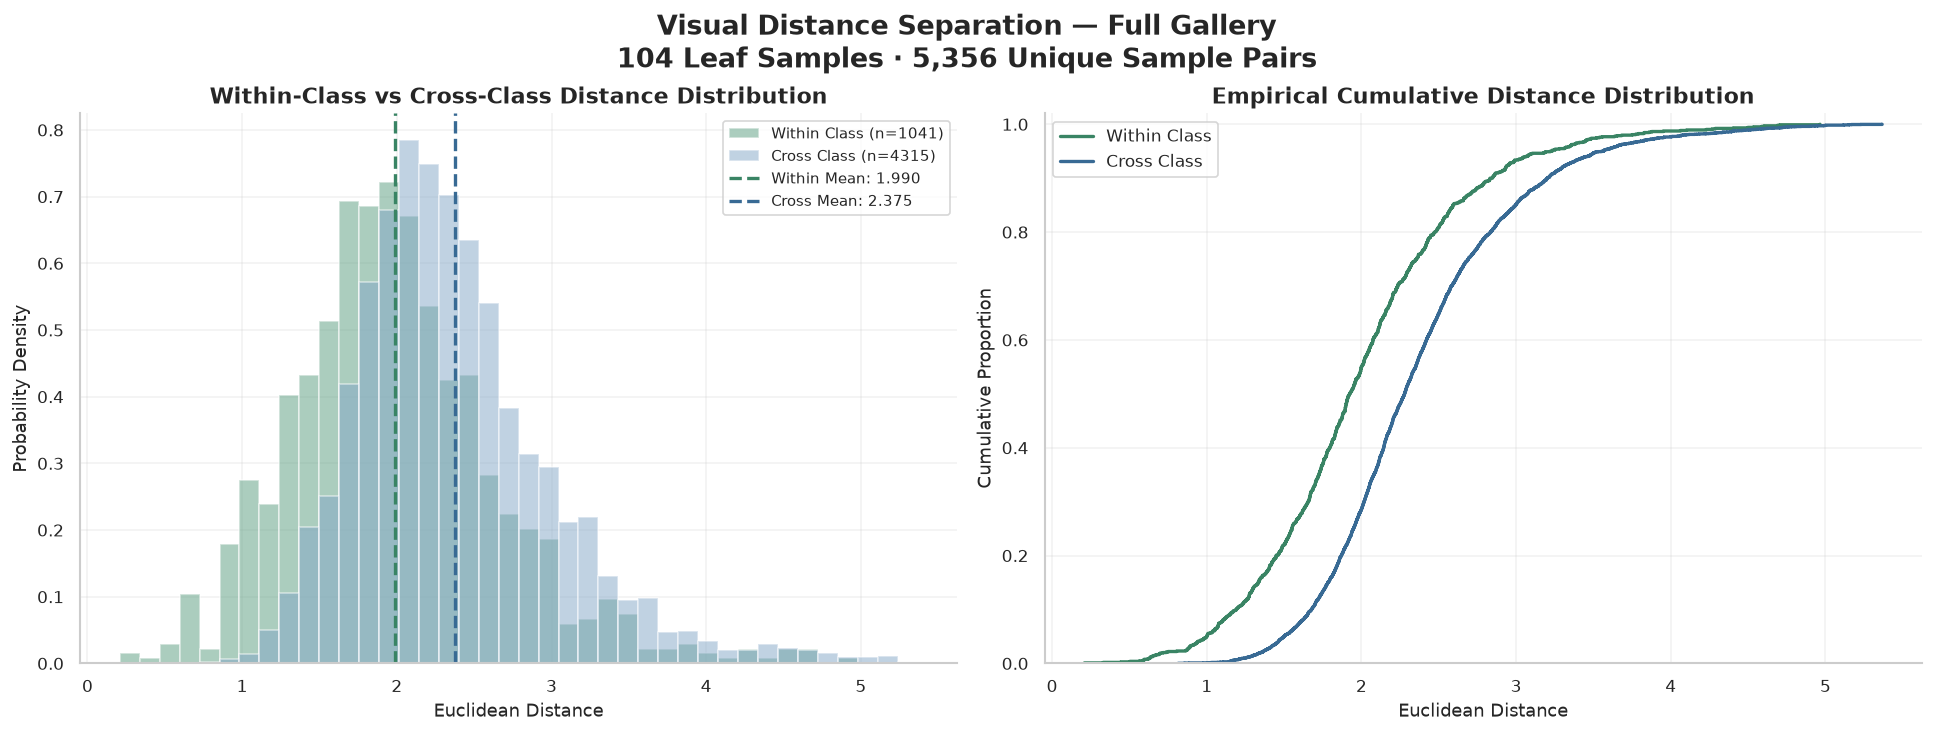

[SAVED] 114_visual_distance_within_cross_distributions.png


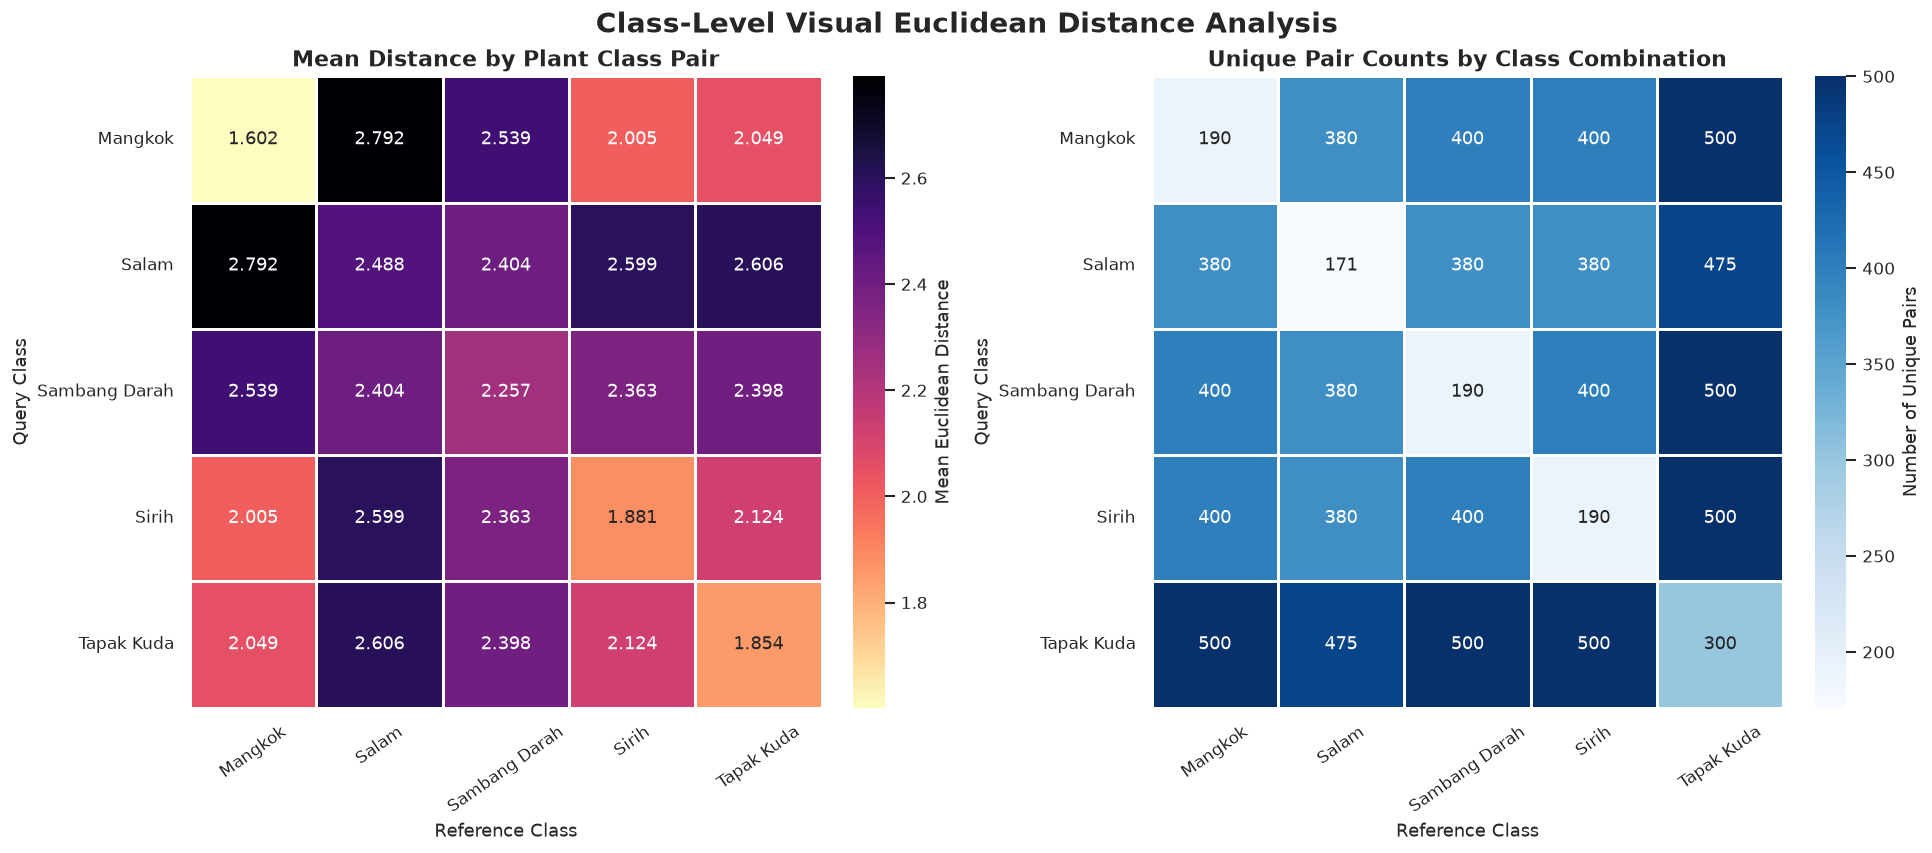

[SAVED] 115_visual_distance_class_pair_heatmaps.png


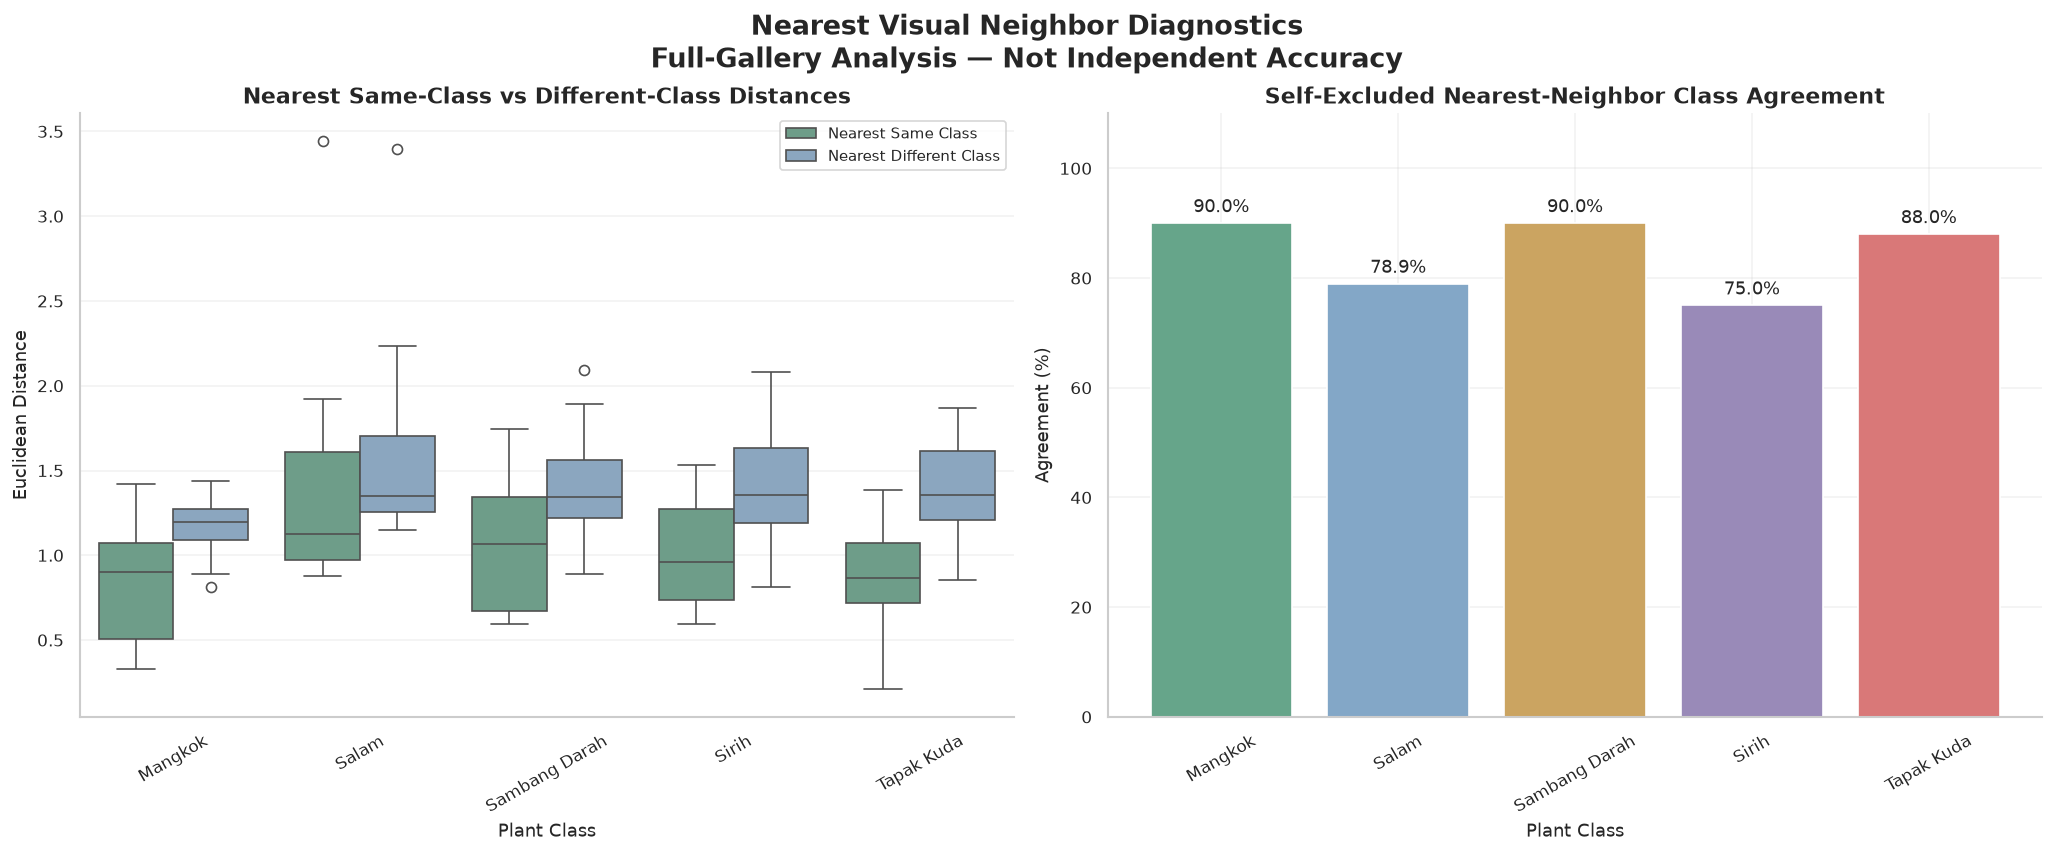

[SAVED] 116_visual_distance_nearest_neighbor_diagnostics.png


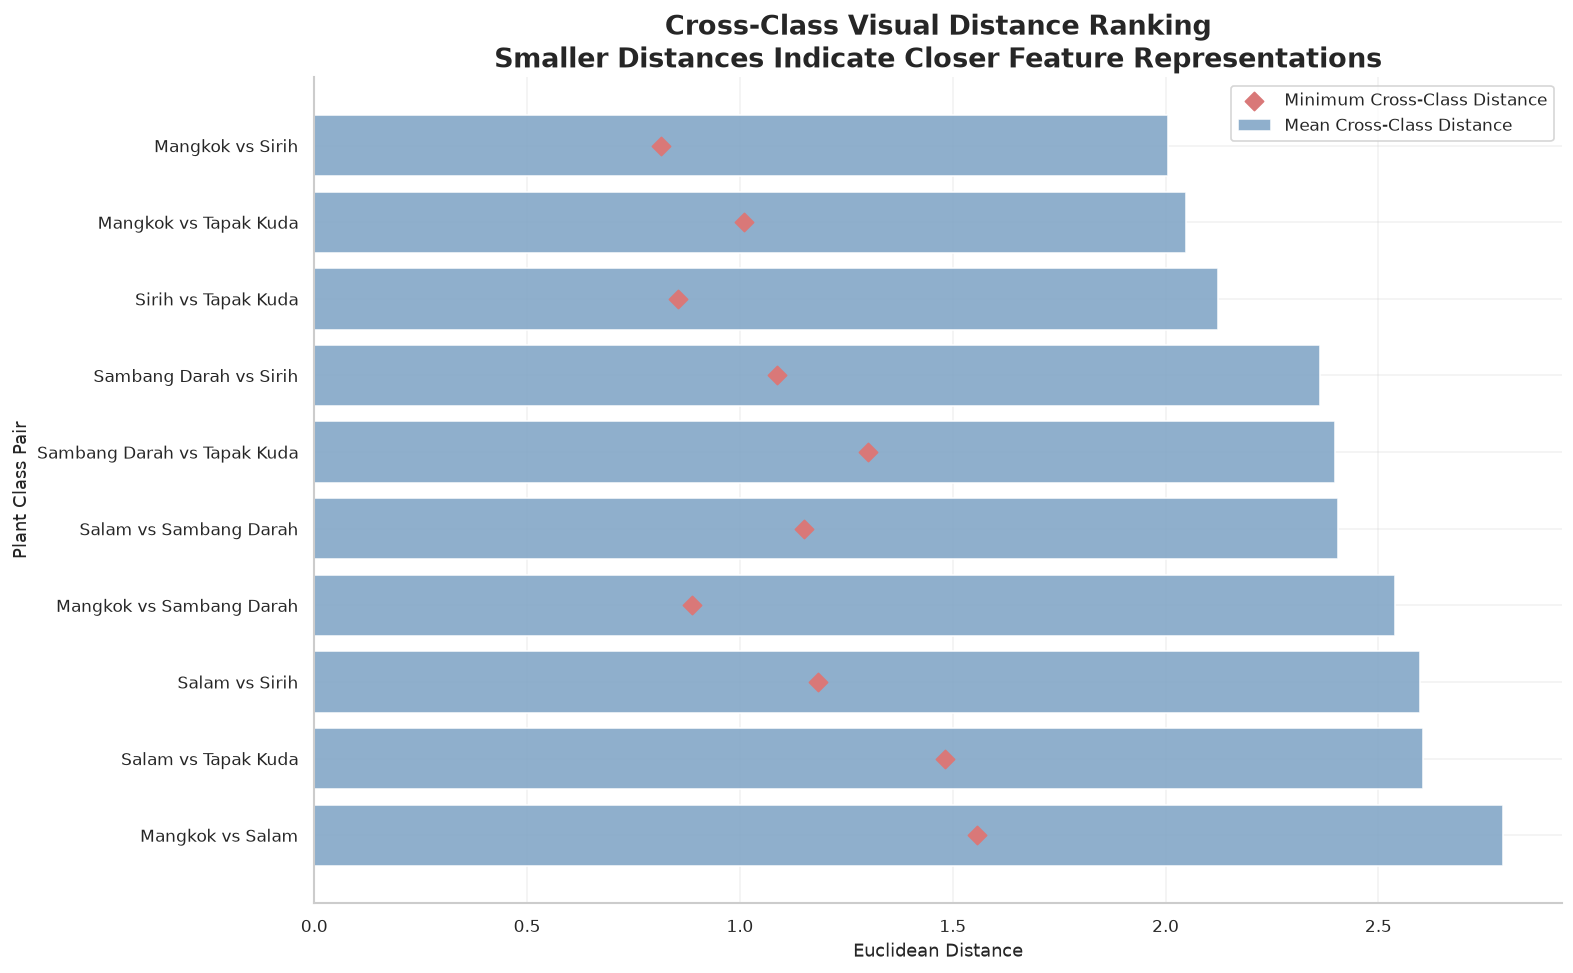

[SAVED] 117_visual_distance_cross_class_ranking.png

9. FINAL VISUAL DISTANCE ANALYSIS SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Input distance matrix,"(104, 104)"
1,Samples,104
2,Classes,5
3,Unique sample pairs,5356
4,Within-class pairs,1041
5,Cross-class pairs,4315
6,Mean within-class distance,1.990486
7,Mean cross-class distance,2.375002
8,Cross-minus-within mean gap,0.384516
9,Standardized mean separation,0.58414



10. SAVING DISTANCE ANALYSIS REPORTS
----------------------------------------------------------------------
[SAVED] 397_visual_distance_distribution_summary.csv
[SAVED] 398_visual_distance_class_pair_summary.csv
[SAVED] 399_visual_distance_class_mean_matrix.csv
[SAVED] 400_visual_distance_class_count_matrix.csv
[SAVED] 401_visual_distance_separation_diagnostics.csv
[SAVED] 402_visual_distance_per_query_neighbors.csv
[SAVED] 403_visual_distance_nearest_class_summary.csv
[SAVED] 404_visual_distance_closest_cross_class_pairs.csv
[SAVED] 405_visual_distance_analysis_validation.csv
[SAVED] 406_visual_distance_analysis_summary.csv

FINAL VISUAL DISTANCE ANALYSIS SUMMARY

PAIR STATISTICS
----------------------------------------------------------------------
Unique pairs       : 5356
Within-class pairs : 1041
Cross-class pairs  : 4315

DISTANCE SEPARATION
----------------------------------------------------------------------
Within-class mean : 1.990486
Cross-class mean  : 2.375002
Mean dista

In [11]:
# ============================================================
# CELL 9 - VISUAL DISTANCE ANALYSIS
# ============================================================

print("MULTIMODAL FUSION - VISUAL DISTANCE ANALYSIS")
print("=" * 70)

VISUAL_DISTANCE_ANALYSIS_COMPLETED = False


# ============================================================
# 1. VALIDATE PREVIOUS STAGES
# ============================================================

required_stages = [
    "FUSION_LIBRARIES_IMPORTED",
    "FUSION_PATH_CONFIGURATION_COMPLETED",
    "VISUAL_FEATURE_LOADING_COMPLETED",
    "TEXT_FEATURE_LOADING_COMPLETED",
    "MULTIMODAL_DATASET_VALIDATION_COMPLETED",
    "FUSION_CONFIGURATION_COMPLETED",
    "VISUAL_DISTANCE_CALCULATION_COMPLETED"
]

for stage in required_stages:
    assert globals().get(stage, False), (
        f"{stage} has not been completed."
    )

assert visual_euclidean_distance_validation_df[
    "passed"
].all()

assert np.array_equal(
    visual_distance_sample_ids,
    multimodal_sample_ids
)

assert np.array_equal(
    visual_distance_labels,
    multimodal_labels
)

print("[PASS] Previous stages validated.")


# ============================================================
# 2. ANALYSIS CONFIGURATION
# ============================================================

VISUAL_ANALYSIS_TOLERANCE = 1e-10
VISUAL_ANALYSIS_EXPECTED_SAMPLES = 104
VISUAL_ANALYSIS_EXPECTED_PAIRS = 5356

VISUAL_ANALYSIS_HISTOGRAM_BINS = 40
VISUAL_ANALYSIS_CLOSEST_PAIRS = 15

VISUAL_ANALYSIS_SCOPE = (
    "Full-Gallery Exploratory Distance Analysis"
)

visual_analysis_checks = []
visual_analysis_figure_paths = []


def register_visual_analysis_check(
    category,
    name,
    condition
):
    visual_analysis_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(condition),
        "status": (
            "Passed" if condition else "Failed"
        )
    })


def save_visual_analysis_figure(fig, filename):

    output_path = FUSION_FIGURES_DIR / filename

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    visual_analysis_figure_paths.append(output_path)

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


def describe_visual_distances(values, group_name):

    values = np.asarray(
        values,
        dtype=np.float64
    )

    assert values.ndim == 1
    assert values.size > 0
    assert np.isfinite(values).all()

    return {
        "group": group_name,
        "number_of_pairs": int(values.size),
        "minimum_distance": float(values.min()),
        "maximum_distance": float(values.max()),
        "mean_distance": float(values.mean()),
        "median_distance": float(np.median(values)),
        "std_distance": float(values.std(ddof=0)),
        "q10_distance": float(np.quantile(values, 0.10)),
        "q25_distance": float(np.quantile(values, 0.25)),
        "q75_distance": float(np.quantile(values, 0.75)),
        "q90_distance": float(np.quantile(values, 0.90)),
        "zero_distance_pairs": int(
            (values <= VISUAL_ANALYSIS_TOLERANCE).sum()
        )
    }


print("\n1. ANALYSIS CONFIGURATION")
print("-" * 70)

print("Samples :", VISUAL_ANALYSIS_EXPECTED_SAMPLES)
print("Pairs   :", VISUAL_ANALYSIS_EXPECTED_PAIRS)
print("Scope   :", VISUAL_ANALYSIS_SCOPE)
print("Self-matches excluded: True")


# ============================================================
# 3. PREPARE DISTANCE MATRIX AND PAIR INDICES
# ============================================================

# Reuse the distance matrix calculated in Cell 8.
# Do not recalculate the feature representation.

visual_analysis_distance_matrix = np.asarray(
    visual_euclidean_distance_matrix,
    dtype=np.float64
)

visual_analysis_sample_ids = np.asarray(
    visual_distance_sample_ids,
    dtype=str
)

visual_analysis_labels = np.asarray(
    visual_distance_labels,
    dtype=str
)

visual_analysis_n_samples = len(
    visual_analysis_sample_ids
)

assert visual_analysis_distance_matrix.shape == (
    104, 104
)

assert visual_analysis_n_samples == 104

assert np.isfinite(
    visual_analysis_distance_matrix
).all()

assert np.allclose(
    visual_analysis_distance_matrix,
    visual_analysis_distance_matrix.T,
    atol=VISUAL_ANALYSIS_TOLERANCE,
    rtol=0
)

assert np.allclose(
    np.diag(visual_analysis_distance_matrix),
    0.0,
    atol=VISUAL_ANALYSIS_TOLERANCE,
    rtol=0
)

# Unique unordered pairs, excluding the diagonal.

analysis_pair_i, analysis_pair_j = np.triu_indices(
    visual_analysis_n_samples,
    k=1
)

analysis_pair_distances = (
    visual_analysis_distance_matrix[
        analysis_pair_i,
        analysis_pair_j
    ]
)

analysis_within_mask = (
    visual_analysis_labels[analysis_pair_i]
    == visual_analysis_labels[analysis_pair_j]
)

analysis_within_distances = (
    analysis_pair_distances[
        analysis_within_mask
    ]
)

analysis_cross_distances = (
    analysis_pair_distances[
        ~analysis_within_mask
    ]
)

register_visual_analysis_check(
    "Input Integrity",
    "Distance matrix shape valid",
    visual_analysis_distance_matrix.shape == (104, 104)
)

register_visual_analysis_check(
    "Input Integrity",
    "Distance matrix finite and nonnegative",
    np.isfinite(visual_analysis_distance_matrix).all()
    and np.all(
        visual_analysis_distance_matrix
        >= -VISUAL_ANALYSIS_TOLERANCE
    )
)

register_visual_analysis_check(
    "Input Integrity",
    "Diagonal distances zero",
    np.allclose(
        np.diag(visual_analysis_distance_matrix),
        0.0,
        atol=VISUAL_ANALYSIS_TOLERANCE,
        rtol=0
    )
)

register_visual_analysis_check(
    "Input Integrity",
    "Distance matrix symmetric",
    np.allclose(
        visual_analysis_distance_matrix,
        visual_analysis_distance_matrix.T,
        atol=VISUAL_ANALYSIS_TOLERANCE,
        rtol=0
    )
)

register_visual_analysis_check(
    "Input Integrity",
    "Previous unique-pair distances preserved",
    np.array_equal(
        analysis_pair_distances,
        visual_unique_pair_distances
    )
)

register_visual_analysis_check(
    "Input Integrity",
    "Previous pair class masks preserved",
    np.array_equal(
        analysis_within_mask,
        visual_same_class_pair_mask
    )
)

assert len(analysis_pair_distances) == 5356
assert len(analysis_within_distances) == 1041
assert len(analysis_cross_distances) == 4315

print("\n2. DISTANCE PAIR INVENTORY")
print("-" * 70)

print("Total unique pairs :", len(analysis_pair_distances))
print("Within-class pairs:", len(analysis_within_distances))
print("Cross-class pairs :", len(analysis_cross_distances))


# ============================================================
# 4. GLOBAL DISTANCE DISTRIBUTION SUMMARY
# ============================================================

visual_distance_distribution_summary_df = pd.DataFrame([
    describe_visual_distances(
        analysis_pair_distances,
        "All Unique Pairs"
    ),
    describe_visual_distances(
        analysis_within_distances,
        "Within Class"
    ),
    describe_visual_distances(
        analysis_cross_distances,
        "Cross Class"
    )
])

within_mean = float(
    analysis_within_distances.mean()
)

cross_mean = float(
    analysis_cross_distances.mean()
)

within_std = float(
    analysis_within_distances.std(ddof=0)
)

cross_std = float(
    analysis_cross_distances.std(ddof=0)
)

# A positive gap indicates that cross-class pairs
# have a larger average distance.

visual_distance_mean_gap = (
    cross_mean - within_mean
)

pooled_descriptive_std = np.sqrt(
    (
        within_std ** 2
        + cross_std ** 2
    ) / 2
)

visual_distance_standardized_separation = (
    visual_distance_mean_gap / pooled_descriptive_std
    if pooled_descriptive_std > 0
    else np.nan
)

print("\n3. GLOBAL DISTANCE DISTRIBUTIONS")
print("-" * 70)

display(
    visual_distance_distribution_summary_df.round(6)
)

print(f"Within-class mean : {within_mean:.6f}")
print(f"Cross-class mean  : {cross_mean:.6f}")
print(
    "Cross-minus-within gap:",
    f"{visual_distance_mean_gap:.6f}"
)

if visual_distance_mean_gap > 0:
    print(
        "[OBSERVATION] Mean within-class distance "
        "is smaller than mean cross-class distance."
    )
elif visual_distance_mean_gap < 0:
    print(
        "[OBSERVATION] Mean within-class distance "
        "is larger than mean cross-class distance."
    )
else:
    print(
        "[OBSERVATION] Both distance means are equal."
    )


# ============================================================
# 5. EMPIRICAL DISTRIBUTION SEPARATION
# ============================================================

# Evaluate empirical pairwise separation:
#
# P(D_within < D_cross)
# + 0.5 * P(D_within == D_cross)
#
# This compares distances from the full gallery.
# It is a descriptive measure, not independent AUC.
#
# Use searchsorted instead of a large broadcast matrix.

sorted_cross_distances = np.sort(
    analysis_cross_distances
)

left_positions = np.searchsorted(
    sorted_cross_distances,
    analysis_within_distances,
    side="left"
)

right_positions = np.searchsorted(
    sorted_cross_distances,
    analysis_within_distances,
    side="right"
)

# Cross-class distances strictly greater than
# each within-class distance.

strictly_greater_counts = (
    len(sorted_cross_distances) - right_positions
)

# Exact numerical ties receive half credit.

tie_counts = (
    right_positions - left_positions
)

possible_pair_comparisons = (
    len(analysis_within_distances)
    * len(analysis_cross_distances)
)

visual_distance_pairwise_separation_rate = float(
    (
        strictly_greater_counts.sum()
        + 0.5 * tie_counts.sum()
    )
    / possible_pair_comparisons
)

cross_median = float(
    np.median(analysis_cross_distances)
)

within_median = float(
    np.median(analysis_within_distances)
)

within_below_cross_median_percent = float(
    100 * np.mean(
        analysis_within_distances < cross_median
    )
)

cross_above_within_median_percent = float(
    100 * np.mean(
        analysis_cross_distances > within_median
    )
)

within_q75 = float(
    np.quantile(analysis_within_distances, 0.75)
)

cross_q25 = float(
    np.quantile(analysis_cross_distances, 0.25)
)

# Overlapping central 50% ranges indicate that
# the two distributions are not cleanly separated.

central_ranges_overlap = bool(
    within_q75 >= cross_q25
    and np.quantile(
        analysis_within_distances, 0.25
    ) <= np.quantile(
        analysis_cross_distances, 0.75
    )
)

visual_distance_separation_diagnostics_df = pd.DataFrame([{
    "within_class_mean": within_mean,
    "cross_class_mean": cross_mean,
    "cross_minus_within_mean_gap":
        visual_distance_mean_gap,
    "standardized_mean_separation":
        visual_distance_standardized_separation,
    "within_class_median": within_median,
    "cross_class_median": cross_median,
    "within_q75": within_q75,
    "cross_q25": cross_q25,
    "central_50_percent_ranges_overlap":
        central_ranges_overlap,
    "pairwise_separation_rate":
        visual_distance_pairwise_separation_rate,
    "pairwise_separation_percent":
        visual_distance_pairwise_separation_rate * 100,
    "within_below_cross_median_percent":
        within_below_cross_median_percent,
    "cross_above_within_median_percent":
        cross_above_within_median_percent,
    "unique_pair_comparisons":
        int(possible_pair_comparisons),
    "independent_evaluation": False
}])

register_visual_analysis_check(
    "Distribution Analysis",
    "Empirical separation rate within valid bounds",
    0 <= visual_distance_pairwise_separation_rate <= 1
)

register_visual_analysis_check(
    "Distribution Analysis",
    "Global pair distributions reconcile",
    len(analysis_within_distances)
    + len(analysis_cross_distances)
    == len(analysis_pair_distances)
)

register_visual_analysis_check(
    "Distribution Analysis",
    "Global distance means finite",
    np.isfinite([within_mean, cross_mean]).all()
)

print("\n4. DISTRIBUTION SEPARATION DIAGNOSTICS")
print("-" * 70)

display(
    visual_distance_separation_diagnostics_df.T
)


# ============================================================
# 6. ANALYZE DISTANCES FOR EACH CLASS PAIR
# ============================================================

visual_analysis_classes = sorted(
    np.unique(visual_analysis_labels)
)

visual_analysis_n_classes = len(
    visual_analysis_classes
)

visual_class_pair_records = []

visual_class_mean_distance_matrix = np.zeros(
    (
        visual_analysis_n_classes,
        visual_analysis_n_classes
    ),
    dtype=np.float64
)

visual_class_median_distance_matrix = np.zeros_like(
    visual_class_mean_distance_matrix
)

visual_class_pair_count_matrix = np.zeros(
    visual_class_mean_distance_matrix.shape,
    dtype=np.int64
)

for class_i_index, class_i in enumerate(
    visual_analysis_classes
):

    for class_j_index in range(
        class_i_index,
        visual_analysis_n_classes
    ):

        class_j = visual_analysis_classes[
            class_j_index
        ]

        if class_i == class_j:

            pair_mask = (
                (visual_analysis_labels[analysis_pair_i] == class_i)
                &
                (visual_analysis_labels[analysis_pair_j] == class_i)
            )

            pair_type = "Within Class"

        else:

            pair_mask = (
                (
                    (visual_analysis_labels[analysis_pair_i] == class_i)
                    &
                    (visual_analysis_labels[analysis_pair_j] == class_j)
                )
                |
                (
                    (visual_analysis_labels[analysis_pair_i] == class_j)
                    &
                    (visual_analysis_labels[analysis_pair_j] == class_i)
                )
            )

            pair_type = "Cross Class"

        class_pair_distances = (
            analysis_pair_distances[pair_mask]
        )

        assert class_pair_distances.size > 0

        count_i = int(
            (visual_analysis_labels == class_i).sum()
        )

        count_j = int(
            (visual_analysis_labels == class_j).sum()
        )

        expected_pairs = (
            count_i * (count_i - 1) // 2
            if class_i == class_j
            else count_i * count_j
        )

        assert len(class_pair_distances) == expected_pairs

        mean_value = float(
            class_pair_distances.mean()
        )

        median_value = float(
            np.median(class_pair_distances)
        )

        visual_class_pair_records.append({
            "class_i": class_i,
            "class_j": class_j,
            "pair_type": pair_type,
            "number_of_pairs": len(class_pair_distances),
            "expected_pairs": expected_pairs,
            "minimum_distance": float(
                class_pair_distances.min()
            ),
            "maximum_distance": float(
                class_pair_distances.max()
            ),
            "mean_distance": mean_value,
            "median_distance": median_value,
            "std_distance": float(
                class_pair_distances.std(ddof=0)
            ),
            "q25_distance": float(
                np.quantile(class_pair_distances, 0.25)
            ),
            "q75_distance": float(
                np.quantile(class_pair_distances, 0.75)
            ),
            "near_zero_pairs": int(
                (
                    class_pair_distances
                    <= VISUAL_ANALYSIS_TOLERANCE
                ).sum()
            )
        })

        visual_class_mean_distance_matrix[
            class_i_index,
            class_j_index
        ] = mean_value

        visual_class_mean_distance_matrix[
            class_j_index,
            class_i_index
        ] = mean_value

        visual_class_median_distance_matrix[
            class_i_index,
            class_j_index
        ] = median_value

        visual_class_median_distance_matrix[
            class_j_index,
            class_i_index
        ] = median_value

        visual_class_pair_count_matrix[
            class_i_index,
            class_j_index
        ] = len(class_pair_distances)

        visual_class_pair_count_matrix[
            class_j_index,
            class_i_index
        ] = len(class_pair_distances)


visual_distance_class_pair_summary_df = pd.DataFrame(
    visual_class_pair_records
)

visual_distance_class_mean_matrix_df = pd.DataFrame(
    visual_class_mean_distance_matrix,
    index=visual_analysis_classes,
    columns=visual_analysis_classes
)

visual_distance_class_median_matrix_df = pd.DataFrame(
    visual_class_median_distance_matrix,
    index=visual_analysis_classes,
    columns=visual_analysis_classes
)

visual_distance_class_count_matrix_df = pd.DataFrame(
    visual_class_pair_count_matrix,
    index=visual_analysis_classes,
    columns=visual_analysis_classes
)

within_class_pair_total = int(
    visual_distance_class_pair_summary_df.loc[
        visual_distance_class_pair_summary_df[
            "pair_type"
        ].eq("Within Class"),
        "number_of_pairs"
    ].sum()
)

cross_class_pair_total = int(
    visual_distance_class_pair_summary_df.loc[
        visual_distance_class_pair_summary_df[
            "pair_type"
        ].eq("Cross Class"),
        "number_of_pairs"
    ].sum()
)

register_visual_analysis_check(
    "Class Pair Analysis",
    "Five within-class combinations",
    (
        visual_distance_class_pair_summary_df[
            "pair_type"
        ] == "Within Class"
    ).sum() == 5
)

register_visual_analysis_check(
    "Class Pair Analysis",
    "Ten cross-class combinations",
    (
        visual_distance_class_pair_summary_df[
            "pair_type"
        ] == "Cross Class"
    ).sum() == 10
)

register_visual_analysis_check(
    "Class Pair Analysis",
    "Class-pair counts reconcile",
    within_class_pair_total == 1041
    and cross_class_pair_total == 4315
)

register_visual_analysis_check(
    "Class Pair Analysis",
    "Class mean matrix symmetric",
    np.allclose(
        visual_class_mean_distance_matrix,
        visual_class_mean_distance_matrix.T,
        atol=VISUAL_ANALYSIS_TOLERANCE,
        rtol=0
    )
)

register_visual_analysis_check(
    "Class Pair Analysis",
    "Class median matrix symmetric",
    np.allclose(
        visual_class_median_distance_matrix,
        visual_class_median_distance_matrix.T,
        atol=VISUAL_ANALYSIS_TOLERANCE,
        rtol=0
    )
)

register_visual_analysis_check(
    "Class Pair Analysis",
    "Class-pair distance statistics finite",
    np.isfinite(
        visual_distance_class_pair_summary_df[
            [
                "minimum_distance",
                "maximum_distance",
                "mean_distance",
                "median_distance"
            ]
        ].to_numpy()
    ).all()
)

print("\n5. CLASS-PAIR DISTANCE ANALYSIS")
print("-" * 70)

display(
    visual_distance_class_pair_summary_df[
        [
            "class_i",
            "class_j",
            "pair_type",
            "number_of_pairs",
            "mean_distance",
            "median_distance",
            "minimum_distance"
        ]
    ].round(6)
)

print("\nClass Mean Distance Matrix")

display(
    visual_distance_class_mean_matrix_df.round(4)
)


# ============================================================
# 7. PER-QUERY NEAREST-NEIGHBOR DIAGNOSTICS
# ============================================================

# For every sample, locate:
#
# 1. Nearest overall non-self sample
# 2. Nearest same-class non-self sample
# 3. Nearest different-class sample
#
# This is a full-gallery descriptive diagnostic.
# It is not independent retrieval evaluation.

visual_nearest_neighbor_records = []

for query_index in range(visual_analysis_n_samples):

    query_id = visual_analysis_sample_ids[
        query_index
    ]

    query_class = visual_analysis_labels[
        query_index
    ]

    candidate_indices = np.arange(
        visual_analysis_n_samples
    )

    candidate_indices = candidate_indices[
        candidate_indices != query_index
    ]

    candidate_distances = (
        visual_analysis_distance_matrix[
            query_index,
            candidate_indices
        ]
    )

    candidate_order = np.lexsort((
        visual_analysis_sample_ids[
            candidate_indices
        ],
        candidate_distances
    ))

    ranked_candidates = candidate_indices[
        candidate_order
    ]

    nearest_overall_index = int(
        ranked_candidates[0]
    )

    same_class_candidates = candidate_indices[
        visual_analysis_labels[candidate_indices]
        == query_class
    ]

    different_class_candidates = candidate_indices[
        visual_analysis_labels[candidate_indices]
        != query_class
    ]

    assert len(same_class_candidates) > 0
    assert len(different_class_candidates) > 0

    same_order = np.lexsort((
        visual_analysis_sample_ids[
            same_class_candidates
        ],
        visual_analysis_distance_matrix[
            query_index,
            same_class_candidates
        ]
    ))

    different_order = np.lexsort((
        visual_analysis_sample_ids[
            different_class_candidates
        ],
        visual_analysis_distance_matrix[
            query_index,
            different_class_candidates
        ]
    ))

    nearest_same_index = int(
        same_class_candidates[same_order[0]]
    )

    nearest_different_index = int(
        different_class_candidates[different_order[0]]
    )

    nearest_overall_distance = float(
        visual_analysis_distance_matrix[
            query_index,
            nearest_overall_index
        ]
    )

    nearest_same_distance = float(
        visual_analysis_distance_matrix[
            query_index,
            nearest_same_index
        ]
    )

    nearest_different_distance = float(
        visual_analysis_distance_matrix[
            query_index,
            nearest_different_index
        ]
    )

    # Positive margin: same-class nearest neighbor
    # lies closer than the nearest different-class
    # sample.

    nearest_distance_margin = (
        nearest_different_distance
        - nearest_same_distance
    )

    nearest_agrees = (
        visual_analysis_labels[
            nearest_overall_index
        ] == query_class
    )

    visual_nearest_neighbor_records.append({
        "query_index": query_index,
        "query_sample_id": query_id,
        "query_class": query_class,
        "nearest_sample_id":
            visual_analysis_sample_ids[
                nearest_overall_index
            ],
        "nearest_sample_class":
            visual_analysis_labels[
                nearest_overall_index
            ],
        "nearest_distance":
            nearest_overall_distance,
        "nearest_same_class_sample_id":
            visual_analysis_sample_ids[
                nearest_same_index
            ],
        "nearest_same_class_distance":
            nearest_same_distance,
        "nearest_different_class_sample_id":
            visual_analysis_sample_ids[
                nearest_different_index
            ],
        "nearest_different_class":
            visual_analysis_labels[
                nearest_different_index
            ],
        "nearest_different_class_distance":
            nearest_different_distance,
        "distance_margin_different_minus_same":
            nearest_distance_margin,
        "nearest_neighbor_same_class":
            bool(nearest_agrees),
        "strict_positive_margin":
            bool(
                nearest_distance_margin
                > VISUAL_ANALYSIS_TOLERANCE
            ),
        "self_match_excluded":
            bool(
                nearest_overall_index != query_index
            )
    })


visual_distance_per_query_neighbors_df = pd.DataFrame(
    visual_nearest_neighbor_records
)

visual_distance_nearest_class_summary_df = (
    visual_distance_per_query_neighbors_df
    .groupby("query_class", sort=True)
    .agg(
        number_of_queries=(
            "query_sample_id", "count"
        ),
        nearest_same_class_count=(
            "nearest_neighbor_same_class", "sum"
        ),
        nearest_neighbor_same_class_rate=(
            "nearest_neighbor_same_class", "mean"
        ),
        mean_nearest_distance=(
            "nearest_distance", "mean"
        ),
        mean_nearest_same_distance=(
            "nearest_same_class_distance", "mean"
        ),
        mean_nearest_different_distance=(
            "nearest_different_class_distance", "mean"
        ),
        mean_distance_margin=(
            "distance_margin_different_minus_same", "mean"
        ),
        median_distance_margin=(
            "distance_margin_different_minus_same", "median"
        )
    )
    .reset_index()
)

visual_distance_nearest_class_summary_df[
    "nearest_neighbor_same_class_rate_percent"
] = (
    visual_distance_nearest_class_summary_df[
        "nearest_neighbor_same_class_rate"
    ] * 100
)

visual_nearest_class_agreement_percent = float(
    100
    * visual_distance_per_query_neighbors_df[
        "nearest_neighbor_same_class"
    ].mean()
)

visual_positive_margin_count = int(
    visual_distance_per_query_neighbors_df[
        "strict_positive_margin"
    ].sum()
)

register_visual_analysis_check(
    "Nearest Neighbors",
    "One diagnostic row per sample",
    len(visual_distance_per_query_neighbors_df)
    == visual_analysis_n_samples
)

register_visual_analysis_check(
    "Nearest Neighbors",
    "All self-matches excluded",
    visual_distance_per_query_neighbors_df[
        "self_match_excluded"
    ].all()
)

register_visual_analysis_check(
    "Nearest Neighbors",
    "All nearest distances finite",
    np.isfinite(
        visual_distance_per_query_neighbors_df[
            [
                "nearest_distance",
                "nearest_same_class_distance",
                "nearest_different_class_distance",
                "distance_margin_different_minus_same"
            ]
        ].to_numpy()
    ).all()
)

register_visual_analysis_check(
    "Nearest Neighbors",
    "Class query counts reconcile",
    visual_distance_nearest_class_summary_df[
        "number_of_queries"
    ].sum() == visual_analysis_n_samples
)

register_visual_analysis_check(
    "Nearest Neighbors",
    "Global nearest class agreement in valid range",
    0 <= visual_nearest_class_agreement_percent <= 100
)

print("\n6. PER-QUERY NEAREST NEIGHBOR ANALYSIS")
print("-" * 70)

print(
    "Overall nearest-neighbor class agreement:",
    f"{visual_nearest_class_agreement_percent:.2f}%"
)

print(
    "Samples with strictly positive distance margin:",
    visual_positive_margin_count
)

display(
    visual_distance_nearest_class_summary_df[
        [
            "query_class",
            "number_of_queries",
            "nearest_neighbor_same_class_rate_percent",
            "mean_nearest_same_distance",
            "mean_nearest_different_distance",
            "mean_distance_margin"
        ]
    ].round(6)
)


# ============================================================
# 8. IDENTIFY CLOSEST CROSS-CLASS SAMPLE PAIRS
# ============================================================

cross_pair_i = analysis_pair_i[
    ~analysis_within_mask
]

cross_pair_j = analysis_pair_j[
    ~analysis_within_mask
]

cross_pair_distances = analysis_pair_distances[
    ~analysis_within_mask
]

# Sort by distance ascending.
# Resolve exact distance ties deterministically
# with both sample IDs.

cross_pair_order = np.lexsort((
    visual_analysis_sample_ids[cross_pair_j],
    visual_analysis_sample_ids[cross_pair_i],
    cross_pair_distances
))

closest_cross_order = cross_pair_order[
    :VISUAL_ANALYSIS_CLOSEST_PAIRS
]

visual_closest_cross_class_records = []

for rank, pair_position in enumerate(
    closest_cross_order,
    start=1
):

    i = int(cross_pair_i[pair_position])
    j = int(cross_pair_j[pair_position])

    visual_closest_cross_class_records.append({
        "rank": rank,
        "sample_id_i": visual_analysis_sample_ids[i],
        "sample_id_j": visual_analysis_sample_ids[j],
        "class_i": visual_analysis_labels[i],
        "class_j": visual_analysis_labels[j],
        "euclidean_distance": float(
            visual_analysis_distance_matrix[i, j]
        ),
        "different_classes": bool(
            visual_analysis_labels[i]
            != visual_analysis_labels[j]
        ),
        "self_match_excluded": bool(i != j)
    })


visual_distance_closest_cross_class_df = pd.DataFrame(
    visual_closest_cross_class_records
)

register_visual_analysis_check(
    "Closest Cross-Class Pairs",
    "Expected number of closest cross-class pairs",
    len(visual_distance_closest_cross_class_df)
    == VISUAL_ANALYSIS_CLOSEST_PAIRS
)

register_visual_analysis_check(
    "Closest Cross-Class Pairs",
    "All selected pairs are cross-class",
    visual_distance_closest_cross_class_df[
        "different_classes"
    ].all()
)

register_visual_analysis_check(
    "Closest Cross-Class Pairs",
    "Closest cross-class pairs sorted ascending",
    np.all(
        np.diff(
            visual_distance_closest_cross_class_df[
                "euclidean_distance"
            ].to_numpy()
        ) >= -VISUAL_ANALYSIS_TOLERANCE
    )
)

register_visual_analysis_check(
    "Closest Cross-Class Pairs",
    "No repeated closest-pair records",
    not visual_distance_closest_cross_class_df[
        ["sample_id_i", "sample_id_j"]
    ].duplicated().any()
)

print("\n7. CLOSEST CROSS-CLASS SAMPLE PAIRS")
print("-" * 70)

display(
    visual_distance_closest_cross_class_df.round(6)
)


# ============================================================
# 9. FINAL ANALYSIS VALIDATION
# ============================================================

visual_distance_analysis_validation_df = pd.DataFrame(
    visual_analysis_checks
)

visual_analysis_total_checks = len(
    visual_distance_analysis_validation_df
)

visual_analysis_passed_checks = int(
    visual_distance_analysis_validation_df[
        "passed"
    ].sum()
)

visual_analysis_failed_checks = (
    visual_analysis_total_checks
    - visual_analysis_passed_checks
)

print("\n8. VISUAL DISTANCE ANALYSIS VALIDATION")
print("-" * 70)

display(
    visual_distance_analysis_validation_df
)

# Save validation diagnostics before asserting.

visual_distance_analysis_validation_df.to_csv(
    METRICS_DIR / "405_visual_distance_analysis_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

assert visual_distance_analysis_validation_df[
    "passed"
].all(), (
    visual_distance_analysis_validation_df.loc[
        ~visual_distance_analysis_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All distance analysis checks passed.")


# ============================================================
# 10. FIGURE 114 - WITHIN VS CROSS DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    constrained_layout=True
)

plot_bins = np.histogram_bin_edges(
    analysis_pair_distances,
    bins=VISUAL_ANALYSIS_HISTOGRAM_BINS
)

# A. Normalized distance histograms.

axes[0].hist(
    analysis_within_distances,
    bins=plot_bins,
    density=True,
    color="#66A58A",
    alpha=0.55,
    label=f"Within Class (n={len(analysis_within_distances)})"
)

axes[0].hist(
    analysis_cross_distances,
    bins=plot_bins,
    density=True,
    color="#83A7C7",
    alpha=0.50,
    label=f"Cross Class (n={len(analysis_cross_distances)})"
)

axes[0].axvline(
    within_mean,
    color="#398464",
    linestyle="--",
    linewidth=2,
    label=f"Within Mean: {within_mean:.3f}"
)

axes[0].axvline(
    cross_mean,
    color="#386A94",
    linestyle="--",
    linewidth=2,
    label=f"Cross Mean: {cross_mean:.3f}"
)

axes[0].set_title(
    "Within-Class vs Cross-Class Distance Distribution"
)

axes[0].set_xlabel("Euclidean Distance")
axes[0].set_ylabel("Probability Density")
axes[0].legend(fontsize=9)


# B. Empirical cumulative distribution.

def plot_distance_ecdf(ax, values, label, color):

    ordered = np.sort(values)

    cumulative = (
        np.arange(1, len(ordered) + 1)
        / len(ordered)
    )

    ax.step(
        ordered,
        cumulative,
        where="post",
        color=color,
        linewidth=2,
        label=label
    )


plot_distance_ecdf(
    axes[1],
    analysis_within_distances,
    "Within Class",
    "#398464"
)

plot_distance_ecdf(
    axes[1],
    analysis_cross_distances,
    "Cross Class",
    "#386A94"
)

axes[1].set_title(
    "Empirical Cumulative Distance Distribution"
)

axes[1].set_xlabel("Euclidean Distance")
axes[1].set_ylabel("Cumulative Proportion")
axes[1].set_ylim(0, 1.02)
axes[1].legend()

fig.suptitle(
    "Visual Distance Separation — Full Gallery\n"
    "104 Leaf Samples · 5,356 Unique Sample Pairs",
    fontsize=16,
    fontweight="bold"
)

save_visual_analysis_figure(
    fig,
    "114_visual_distance_within_cross_distributions.png"
)


# ============================================================
# 11. FIGURE 115 - CLASS-PAIR DISTANCE HEATMAPS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    constrained_layout=True
)

sns.heatmap(
    visual_distance_class_mean_matrix_df,
    annot=True,
    fmt=".3f",
    cmap=DISTANCE_CMAP,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Mean Euclidean Distance"},
    ax=axes[0]
)

axes[0].set_title(
    "Mean Distance by Plant Class Pair"
)

axes[0].set_xlabel("Reference Class")
axes[0].set_ylabel("Query Class")

sns.heatmap(
    visual_distance_class_count_matrix_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Number of Unique Pairs"},
    ax=axes[1]
)

axes[1].set_title(
    "Unique Pair Counts by Class Combination"
)

axes[1].set_xlabel("Reference Class")
axes[1].set_ylabel("Query Class")

for ax in axes:
    ax.tick_params(axis="x", rotation=35)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle(
    "Class-Level Visual Euclidean Distance Analysis",
    fontsize=17,
    fontweight="bold"
)

save_visual_analysis_figure(
    fig,
    "115_visual_distance_class_pair_heatmaps.png"
)


# ============================================================
# 12. FIGURE 116 - NEAREST NEIGHBOR DIAGNOSTICS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7),
    constrained_layout=True
)

# A. Compare nearest same/different-class distances.

neighbor_plot_df = (
    visual_distance_per_query_neighbors_df[
        [
            "query_class",
            "nearest_same_class_distance",
            "nearest_different_class_distance"
        ]
    ]
    .melt(
        id_vars="query_class",
        var_name="neighbor_type",
        value_name="euclidean_distance"
    )
)

neighbor_plot_df["neighbor_type"] = (
    neighbor_plot_df["neighbor_type"].map({
        "nearest_same_class_distance":
            "Nearest Same Class",
        "nearest_different_class_distance":
            "Nearest Different Class"
    })
)

sns.boxplot(
    data=neighbor_plot_df,
    x="query_class",
    y="euclidean_distance",
    hue="neighbor_type",
    order=visual_analysis_classes,
    palette={
        "Nearest Same Class": "#66A58A",
        "Nearest Different Class": "#83A7C7"
    },
    showfliers=True,
    ax=axes[0]
)

axes[0].set_title(
    "Nearest Same-Class vs Different-Class Distances"
)

axes[0].set_xlabel("Plant Class")
axes[0].set_ylabel("Euclidean Distance")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title=None, fontsize=9)


# B. Nearest-neighbor class agreement by class.

class_agreement_values = (
    visual_distance_nearest_class_summary_df[
        "nearest_neighbor_same_class_rate_percent"
    ]
)

class_agreement_names = (
    visual_distance_nearest_class_summary_df[
        "query_class"
    ]
)

bars = axes[1].bar(
    class_agreement_names,
    class_agreement_values,
    color=[
        CLASS_COLORS.get(name, "#83A7C7")
        for name in class_agreement_names
    ]
)

axes[1].bar_label(
    bars,
    fmt="%.1f%%",
    padding=4
)

axes[1].set_ylim(0, 110)
axes[1].set_title(
    "Self-Excluded Nearest-Neighbor Class Agreement"
)

axes[1].set_xlabel("Plant Class")
axes[1].set_ylabel("Agreement (%)")
axes[1].tick_params(axis="x", rotation=30)

fig.suptitle(
    "Nearest Visual Neighbor Diagnostics\n"
    "Full-Gallery Analysis — Not Independent Accuracy",
    fontsize=16,
    fontweight="bold"
)

save_visual_analysis_figure(
    fig,
    "116_visual_distance_nearest_neighbor_diagnostics.png"
)


# ============================================================
# 13. FIGURE 117 - CROSS-CLASS DISTANCE RANKING
# ============================================================

# Show the ten cross-class combinations sorted by
# their mean Euclidean distance (smallest first).

cross_class_plot_df = (
    visual_distance_class_pair_summary_df.loc[
        visual_distance_class_pair_summary_df[
            "pair_type"
        ].eq("Cross Class")
    ]
    .sort_values(
        ["mean_distance", "class_i", "class_j"],
        ascending=[True, True, True]
    )
    .reset_index(drop=True)
    .copy()
)

cross_class_plot_df["class_pair"] = (
    cross_class_plot_df["class_i"]
    + " vs "
    + cross_class_plot_df["class_j"]
)

fig, ax = plt.subplots(
    figsize=(13, 8),
    constrained_layout=True
)

positions = np.arange(
    len(cross_class_plot_df)
)

bars = ax.barh(
    positions,
    cross_class_plot_df["mean_distance"],
    color="#83A7C7",
    alpha=0.9,
    label="Mean Cross-Class Distance"
)

ax.scatter(
    cross_class_plot_df["minimum_distance"],
    positions,
    color="#D97878",
    marker="D",
    s=60,
    zorder=4,
    label="Minimum Cross-Class Distance"
)

ax.set_yticks(positions)
ax.set_yticklabels(
    cross_class_plot_df["class_pair"]
)

ax.invert_yaxis()

ax.set_xlabel("Euclidean Distance")
ax.set_ylabel("Plant Class Pair")

ax.set_title(
    "Cross-Class Visual Distance Ranking\n"
    "Smaller Distances Indicate Closer Feature Representations",
    fontsize=16,
    fontweight="bold"
)

ax.legend()

save_visual_analysis_figure(
    fig,
    "117_visual_distance_cross_class_ranking.png"
)


# ============================================================
# 14. FINAL ANALYSIS SUMMARY
# ============================================================

visual_distance_analysis_summary_df = pd.DataFrame([
    ("Input distance matrix",
     str(visual_analysis_distance_matrix.shape)),

    ("Samples",
     visual_analysis_n_samples),

    ("Classes",
     visual_analysis_n_classes),

    ("Unique sample pairs",
     len(analysis_pair_distances)),

    ("Within-class pairs",
     len(analysis_within_distances)),

    ("Cross-class pairs",
     len(analysis_cross_distances)),

    ("Mean within-class distance",
     within_mean),

    ("Mean cross-class distance",
     cross_mean),

    ("Cross-minus-within mean gap",
     visual_distance_mean_gap),

    ("Standardized mean separation",
     visual_distance_standardized_separation),

    ("Empirical pairwise separation rate",
     visual_distance_pairwise_separation_rate),

    ("Central distance ranges overlap",
     central_ranges_overlap),

    ("Class-pair combinations",
     len(visual_distance_class_pair_summary_df)),

    ("Nearest-neighbor diagnostic queries",
     len(visual_distance_per_query_neighbors_df)),

    ("Nearest-neighbor class agreement percent",
     visual_nearest_class_agreement_percent),

    ("Positive distance margins",
     visual_positive_margin_count),

    ("Closest cross-class pairs reported",
     len(visual_distance_closest_cross_class_df)),

    ("Technical validation checks",
     visual_analysis_total_checks),

    ("Passed validation checks",
     visual_analysis_passed_checks),

    ("Failed validation checks",
     visual_analysis_failed_checks),

    ("Generated figures",
     len(visual_analysis_figure_paths)),

    ("Original distance matrix modified",
     False),

    ("Self-matches included in statistics",
     False),

    ("Distance-to-similarity conversion applied",
     False),

    ("Multimodal fusion completed",
     False),

    ("Independent retrieval evaluation completed",
     False),

    ("Analysis scope",
     VISUAL_ANALYSIS_SCOPE)

], columns=["Indicator", "Result"])

print("\n9. FINAL VISUAL DISTANCE ANALYSIS SUMMARY")
print("-" * 70)

display(
    visual_distance_analysis_summary_df
)


# ============================================================
# 15. SAVE ANALYSIS REPORTS
# ============================================================

visual_distance_analysis_reports = {
    "397_visual_distance_distribution_summary.csv":
        visual_distance_distribution_summary_df,

    "398_visual_distance_class_pair_summary.csv":
        visual_distance_class_pair_summary_df,

    "399_visual_distance_class_mean_matrix.csv":
        visual_distance_class_mean_matrix_df,

    "400_visual_distance_class_count_matrix.csv":
        visual_distance_class_count_matrix_df,

    "401_visual_distance_separation_diagnostics.csv":
        visual_distance_separation_diagnostics_df,

    "402_visual_distance_per_query_neighbors.csv":
        visual_distance_per_query_neighbors_df,

    "403_visual_distance_nearest_class_summary.csv":
        visual_distance_nearest_class_summary_df,

    "404_visual_distance_closest_cross_class_pairs.csv":
        visual_distance_closest_cross_class_df,

    "405_visual_distance_analysis_validation.csv":
        visual_distance_analysis_validation_df,

    "406_visual_distance_analysis_summary.csv":
        visual_distance_analysis_summary_df
}

print("\n10. SAVING DISTANCE ANALYSIS REPORTS")
print("-" * 70)

for filename, dataframe in (
    visual_distance_analysis_reports.items()
):

    output_path = METRICS_DIR / filename

    dataframe.to_csv(
        output_path,
        index=True if filename.startswith(
            ("399_", "400_")
        ) else False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ============================================================
# 16. FINAL COMPLETION CHECKS
# ============================================================

assert visual_distance_analysis_validation_df[
    "passed"
].all()

assert visual_analysis_failed_checks == 0

assert len(visual_distance_class_pair_summary_df) == 15

assert len(visual_distance_per_query_neighbors_df) == 104

assert len(visual_distance_closest_cross_class_df) == 15

assert len(analysis_within_distances) == 1041

assert len(analysis_cross_distances) == 4315

assert len(visual_analysis_figure_paths) == 4

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in visual_analysis_figure_paths
)

assert all(
    (METRICS_DIR / filename).is_file()
    and (METRICS_DIR / filename).stat().st_size > 0
    for filename in visual_distance_analysis_reports
)

VISUAL_DISTANCE_ANALYSIS_COMPLETED = True


# ============================================================
# 17. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("FINAL VISUAL DISTANCE ANALYSIS SUMMARY")
print("=" * 70)

print("\nPAIR STATISTICS")
print("-" * 70)

print("Unique pairs       :", len(analysis_pair_distances))
print("Within-class pairs :", len(analysis_within_distances))
print("Cross-class pairs  :", len(analysis_cross_distances))

print("\nDISTANCE SEPARATION")
print("-" * 70)

print(
    "Within-class mean :",
    f"{within_mean:.6f}"
)

print(
    "Cross-class mean  :",
    f"{cross_mean:.6f}"
)

print(
    "Mean distance gap :",
    f"{visual_distance_mean_gap:.6f}"
)

print(
    "Pairwise separation rate:",
    f"{visual_distance_pairwise_separation_rate * 100:.2f}%"
)

print("\nNEAREST NEIGHBOR DIAGNOSTICS")
print("-" * 70)

print(
    "Self-excluded nearest-neighbor agreement:",
    f"{visual_nearest_class_agreement_percent:.2f}%"
)

print(
    "Positive-distance-margin samples:",
    f"{visual_positive_margin_count}/104"
)

print("\nVALIDATION RESULTS")
print("-" * 70)

print(
    "Technical checks:",
    f"{visual_analysis_passed_checks}/"
    f"{visual_analysis_total_checks}"
)

print("Failed checks    :", visual_analysis_failed_checks)

print(
    "Generated reports:",
    len(visual_distance_analysis_reports)
)

print(
    "Generated figures:",
    len(visual_analysis_figure_paths)
)

print("\n[PASS] Within/cross distance distributions analyzed.")
print("[PASS] Class-pair distance statistics calculated.")
print("[PASS] Distance separation diagnostics calculated.")
print("[PASS] Per-query nearest neighbors analyzed.")
print("[PASS] Closest cross-class pairs identified.")
print("[PASS] Four visualizations generated.")
print("[PASS] Analysis reports saved.")

print("\n[INFO] All results are full-gallery exploratory diagnostics.")
print("[INFO] No independent retrieval accuracy is claimed.")
print("[INFO] Original feature and distance matrices unchanged.")
print("[INFO] No similarity conversion or fusion performed.")

print("\n" + "=" * 70)
print("VISUAL DISTANCE ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nNext cell: Cell 10 - Visual Distance-to-Similarity Conversion")

MULTIMODAL FUSION - VISUAL SIMILARITY CONVERSION
[PASS] All previous stages validated.

1. CONVERSION CONFIGURATION
----------------------------------------------------------------------
Method     : inverse_distance
Scale      : 1.0
Tolerance  : 1e-10
Top-K check: 10
Scope      : Full-Gallery Exploratory Development

2. VISUAL SIMILARITY MATRIX
----------------------------------------------------------------------
Matrix shape: (104, 104)
Matrix dtype: float64
Minimum score: 0.15707630087495056
Maximum score: 1.0
Conversion time: 0.1343 ms


,leaf_165d2f32c7fda707,leaf_8473270c3702f48b,leaf_8f425d66b1e193b9,leaf_0ebc8f4f3ee9c8d5,leaf_b0c5f55e42499cae
leaf_165d2f32c7fda707,1.000000,0.291651,0.285530,0.308329,0.294939
leaf_8473270c3702f48b,0.291651,1.000000,0.665038,0.614508,0.610320
leaf_8f425d66b1e193b9,0.285530,0.665038,1.000000,0.629675,0.605704
leaf_0ebc8f4f3ee9c8d5,0.308329,0.614508,0.629675,1.000000,0.600866
leaf_b0c5f55e42499cae,0.294939,0.610320,0.605704,0.600866,1.000000



3. CONVERSION FORMULA VERIFICATION
----------------------------------------------------------------------
Formula maximum error: 0.000e+00
Distance reconstruction maximum error: 8.882e-16

4. SIMILARITY MATRIX VALIDATION
----------------------------------------------------------------------
Maximum symmetry error: 0.000e+00
Maximum diagonal error: 0.000e+00

5. MONOTONICITY VERIFICATION
----------------------------------------------------------------------
Maximum monotonicity violation: 0.000e+00
Spearman correlation: -1.00000000

6. SIMILARITY PAIR INVENTORY
----------------------------------------------------------------------
Unique pairs : 5356
Within class : 1041
Cross class  : 4315

7. VISUAL SIMILARITY DISTRIBUTION
----------------------------------------------------------------------


,pair_group,number_of_pairs,minimum_similarity,maximum_similarity,mean_similarity,median_similarity,std_similarity,q10_similarity,q25_similarity,q75_similarity,q90_similarity
0,All Unique Pairs,5356,0.157076,0.827249,0.315008,0.311849,0.063091,0.240417,0.275213,0.348233,0.391334
1,Within Class,1041,0.167650,0.827249,0.351734,0.341988,0.081812,0.260945,0.298132,0.392006,0.456272
2,Cross Class,4315,0.157076,0.550948,0.306148,0.304963,0.054056,0.238060,0.270979,0.339059,0.373541


Within-class mean: 0.351734
Cross-class mean: 0.306148
Within-minus-cross mean gap: 0.045586
[OBSERVATION] Within-class similarity is higher on average.

8. CLASS-PAIR SIMILARITY ANALYSIS
----------------------------------------------------------------------


,class_i,class_j,pair_type,number_of_pairs,mean_distance,mean_similarity,median_similarity,std_similarity,minimum_similarity,maximum_similarity
0,Mangkok,Mangkok,Within Class,190,1.602013,0.399054,0.377027,0.084917,0.272195,0.751591
1,Mangkok,Salam,Cross Class,380,2.791846,0.275625,0.285114,0.054714,0.157076,0.391032
2,Mangkok,Sambang Darah,Cross Class,400,2.539304,0.292510,0.290133,0.055786,0.195716,0.529536
3,Mangkok,Sirih,Cross Class,400,2.005489,0.339951,0.332542,0.051272,0.236389,0.550948
4,Mangkok,Tapak Kuda,Cross Class,500,2.049060,0.335695,0.331353,0.051301,0.222152,0.497888
5,Salam,Salam,Within Class,171,2.487993,0.305916,0.292838,0.078567,0.167650,0.533176
6,Salam,Sambang Darah,Cross Class,380,2.404108,0.306643,0.298121,0.062268,0.162531,0.465061
7,Salam,Sirih,Cross Class,380,2.598742,0.288851,0.287678,0.054418,0.166652,0.458166
8,Salam,Tapak Kuda,Cross Class,475,2.605777,0.284767,0.286870,0.043642,0.174330,0.403039
9,Sambang Darah,Sambang Darah,Within Class,190,2.256762,0.321762,0.306490,0.074890,0.205056,0.626689


... (4 outputs left out)

,sample_id_i,sample_id_j,class_i,class_j,pair_type,euclidean_distance,visual_similarity,similarity_rank
5355,leaf_055c97f32cf57da5,leaf_41f02313a5460236,Tapak Kuda,Tapak Kuda,Within Class,0.208826,0.827249,1
1084,leaf_8f09fd62c7391c0d,leaf_de455d31a4df8c43,Mangkok,Mangkok,Within Class,0.330510,0.751591,2
406,leaf_b0c5f55e42499cae,leaf_de9e3e4ed5d89dfc,Mangkok,Mangkok,Within Class,0.445272,0.691911,3
103,leaf_8473270c3702f48b,leaf_8f425d66b1e193b9,Mangkok,Mangkok,Within Class,0.503673,0.665038,4
106,leaf_8473270c3702f48b,leaf_de9e3e4ed5d89dfc,Mangkok,Mangkok,Within Class,0.565749,0.638672,5
205,leaf_8f425d66b1e193b9,leaf_0ebc8f4f3ee9c8d5,Mangkok,Mangkok,Within Class,0.588122,0.629675,6
4761,leaf_1b922f2bd904d1fc,leaf_6397705392627f3c,Sirih,Sirih,Within Class,0.593957,0.627370,7
3703,leaf_62ef0ed49ad4e2d3,leaf_ce6b898792146850,Sambang Darah,Sambang Darah,Within Class,0.595688,0.626689,8
5166,leaf_655b2ffd3499bbea,leaf_43ae297ca838aebb,Tapak Kuda,Tapak Kuda,Within Class,0.618748,0.617761,9
104,leaf_8473270c3702f48b,leaf_0ebc8f4f3ee9c8d5,Mangkok,Mangkok,Within Class,0.627318,0.614508,10



11. CONVERSION VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Input Integrity,Input distance matrix dimensions valid,True,Passed
1,Input Integrity,Input sample IDs preserved,True,Passed
2,Input Integrity,Input class labels preserved,True,Passed
3,Input Integrity,Distance matrix unchanged from Cell 9,True,Passed
4,Formula Verification,Inverse-distance formula reproduced,True,Passed
5,Formula Verification,Original distance matrix recovered,True,Passed
6,Similarity Matrix,Similarity matrix shape is 104 x 104,True,Passed
7,Similarity Matrix,Similarity matrix uses float64,True,Passed
8,Similarity Matrix,All similarity scores finite,True,Passed
9,Similarity Matrix,All similarity scores strictly positive,True,Passed


[PASS] All similarity conversion checks passed.


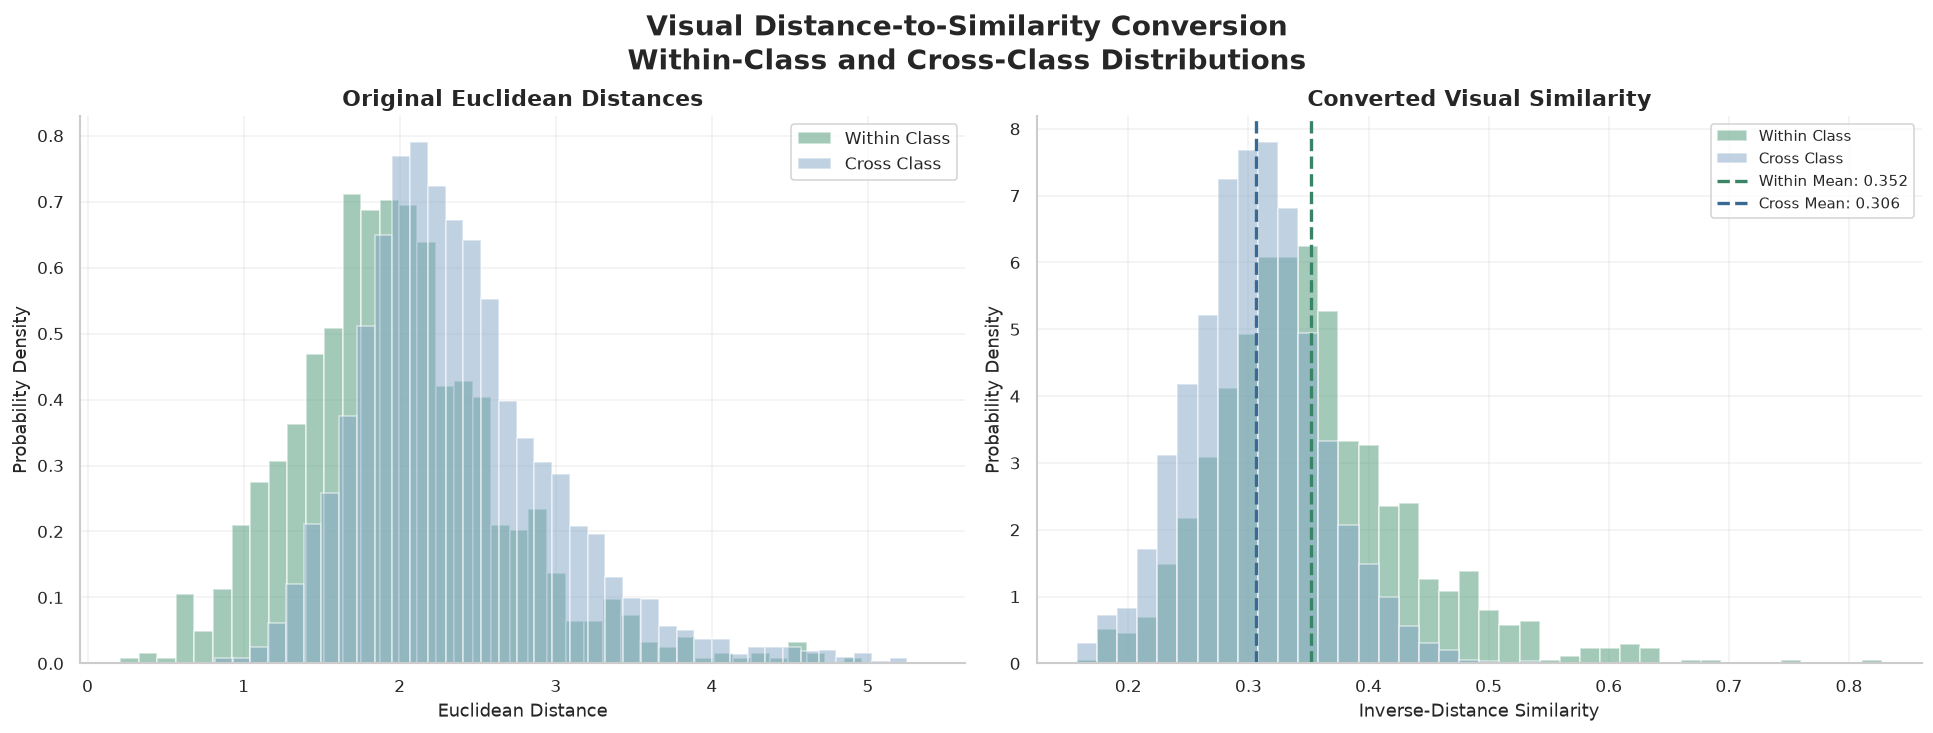

[SAVED] 118_visual_distance_similarity_distributions.png


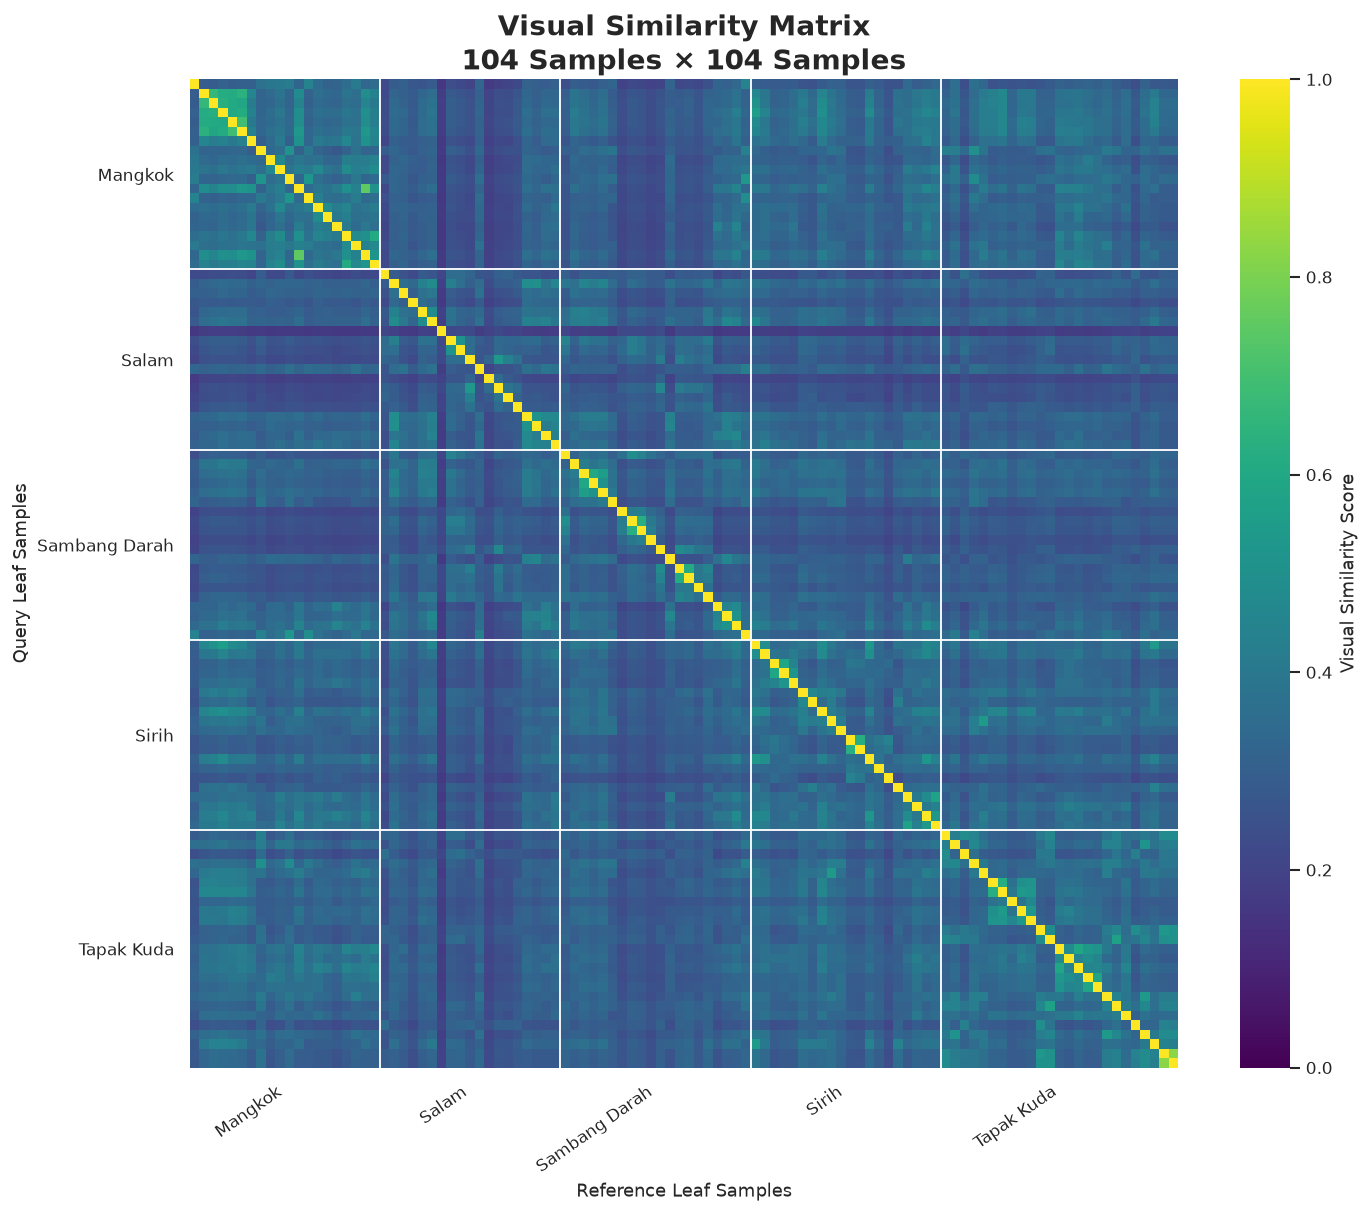

[SAVED] 119_visual_similarity_matrix.png


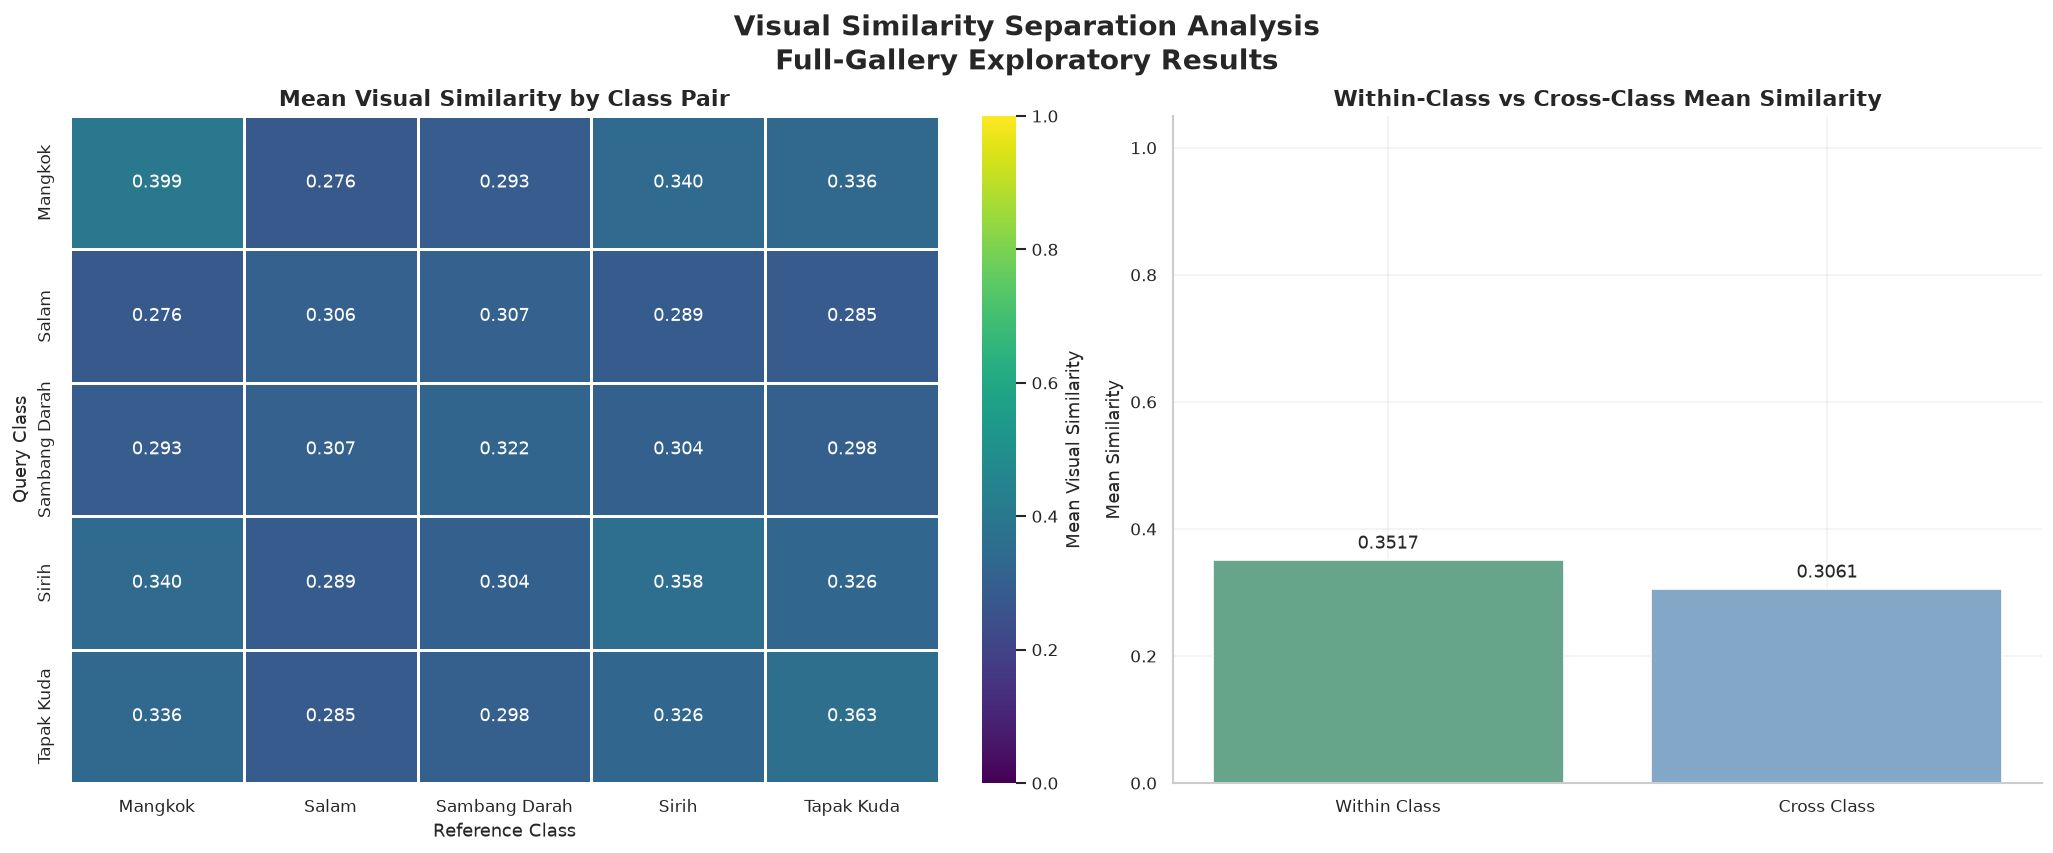

[SAVED] 120_visual_similarity_class_pair_analysis.png

12. VISUAL SIMILARITY CONVERSION SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Input distance matrix,"(104, 104)"
1,Output similarity matrix,"(104, 104)"
2,Conversion method,inverse_distance
3,Distance scale,1.0
4,Total unique pairs,5356
5,Within-class pairs,1041
6,Cross-class pairs,4315
7,Minimum off-diagonal similarity,0.157076
8,Maximum off-diagonal similarity,0.827249
9,Mean within-class similarity,0.351734



13. SAVING CONVERSION REPORTS
----------------------------------------------------------------------
[SAVED] 407_visual_similarity_distribution_summary.csv
[SAVED] 408_visual_similarity_class_pair_summary.csv
[SAVED] 409_visual_similarity_class_mean_matrix.csv
[SAVED] 410_visual_similarity_pairwise_scores.csv
[SAVED] 411_visual_similarity_ranking_consistency.csv
[SAVED] 412_visual_similarity_conversion_validation.csv
[SAVED] 413_visual_similarity_conversion_summary.csv
[SAVED] 414_visual_similarity_conversion_config.json

FINAL VISUAL SIMILARITY CONVERSION SUMMARY

MATRIX INFORMATION
----------------------------------------------------------------------
Input distance matrix : (104, 104)
Output similarity matrix: (104, 104)
Conversion method     : inverse_distance
Distance scale        : 1.0

SIMILARITY STATISTICS
----------------------------------------------------------------------
Minimum pair similarity: 0.157076
Maximum pair similarity: 0.827249
Within-class mean     : 0.351734
C

In [12]:
# ============================================================
# CELL 10 - VISUAL DISTANCE-TO-SIMILARITY CONVERSION
# ============================================================

print("MULTIMODAL FUSION - VISUAL SIMILARITY CONVERSION")
print("=" * 70)

VISUAL_DISTANCE_TO_SIMILARITY_COMPLETED = False
VISUAL_SIMILARITY_CONVERSION_COMPLETED = False


# ============================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ============================================================

required_stages = [
    "FUSION_LIBRARIES_IMPORTED",
    "FUSION_PATH_CONFIGURATION_COMPLETED",
    "VISUAL_FEATURE_LOADING_COMPLETED",
    "TEXT_FEATURE_LOADING_COMPLETED",
    "MULTIMODAL_DATASET_VALIDATION_COMPLETED",
    "FUSION_CONFIGURATION_COMPLETED",
    "VISUAL_DISTANCE_CALCULATION_COMPLETED",
    "VISUAL_DISTANCE_ANALYSIS_COMPLETED"
]

for stage in required_stages:
    assert globals().get(stage, False), (
        f"{stage} has not been completed."
    )

assert visual_euclidean_distance_validation_df[
    "passed"
].all()

assert visual_distance_analysis_validation_df[
    "passed"
].all()

assert FUSION_VISUAL_SIMILARITY_METHOD == "inverse_distance"
assert np.isclose(FUSION_VISUAL_DISTANCE_SCALE, 1.0)

print("[PASS] All previous stages validated.")


# ============================================================
# 2. CONVERSION CONFIGURATION
# ============================================================

VISUAL_SIMILARITY_EXPECTED_SAMPLES = 104
VISUAL_SIMILARITY_TOLERANCE = 1e-10

VISUAL_SIMILARITY_SCALE = float(
    FUSION_VISUAL_DISTANCE_SCALE
)

VISUAL_SIMILARITY_TOP_K = 10

VISUAL_SIMILARITY_SCOPE = (
    "Full-Gallery Exploratory Development"
)

visual_similarity_validation_records = []
visual_similarity_figure_paths = []


def register_visual_similarity_check(
    category,
    name,
    passed
):
    visual_similarity_validation_records.append({
        "category": category,
        "validation_check": name,
        "passed": bool(passed),
        "status": "Passed" if passed else "Failed"
    })


def save_visual_similarity_figure(
    figure,
    filename
):
    path = FUSION_FIGURES_DIR / filename

    figure.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    visual_similarity_figure_paths.append(path)

    plt.show()
    plt.close(figure)

    print(f"[SAVED] {filename}")


def describe_similarity(values, group_name):

    values = np.asarray(
        values,
        dtype=np.float64
    )

    assert values.ndim == 1
    assert values.size > 0
    assert np.isfinite(values).all()

    return {
        "pair_group": group_name,
        "number_of_pairs": int(len(values)),
        "minimum_similarity": float(values.min()),
        "maximum_similarity": float(values.max()),
        "mean_similarity": float(values.mean()),
        "median_similarity": float(np.median(values)),
        "std_similarity": float(values.std(ddof=0)),
        "q10_similarity": float(np.quantile(values, 0.10)),
        "q25_similarity": float(np.quantile(values, 0.25)),
        "q75_similarity": float(np.quantile(values, 0.75)),
        "q90_similarity": float(np.quantile(values, 0.90))
    }


print("\n1. CONVERSION CONFIGURATION")
print("-" * 70)

print("Method     :", FUSION_VISUAL_SIMILARITY_METHOD)
print("Scale      :", VISUAL_SIMILARITY_SCALE)
print("Tolerance  :", VISUAL_SIMILARITY_TOLERANCE)
print("Top-K check:", VISUAL_SIMILARITY_TOP_K)
print("Scope      :", VISUAL_SIMILARITY_SCOPE)


# ============================================================
# 3. PREPARE INPUT DISTANCE MATRIX
# ============================================================

# Reuse the exact matrix computed in Cell 8.
# No feature normalization or distance refitting.

visual_similarity_input_distances = np.asarray(
    visual_euclidean_distance_matrix,
    dtype=np.float64
)

visual_similarity_sample_ids = np.asarray(
    visual_analysis_sample_ids,
    dtype=str
)

visual_similarity_labels = np.asarray(
    visual_analysis_labels,
    dtype=str
)

visual_similarity_n_samples = len(
    visual_similarity_sample_ids
)

assert visual_similarity_input_distances.shape == (
    VISUAL_SIMILARITY_EXPECTED_SAMPLES,
    VISUAL_SIMILARITY_EXPECTED_SAMPLES
)

assert np.isfinite(
    visual_similarity_input_distances
).all()

assert np.all(
    visual_similarity_input_distances
    >= -VISUAL_SIMILARITY_TOLERANCE
)

assert np.array_equal(
    visual_similarity_sample_ids,
    multimodal_sample_ids
)

assert np.array_equal(
    visual_similarity_labels,
    multimodal_labels
)

register_visual_similarity_check(
    "Input Integrity",
    "Input distance matrix dimensions valid",
    visual_similarity_input_distances.shape == (104, 104)
)

register_visual_similarity_check(
    "Input Integrity",
    "Input sample IDs preserved",
    np.array_equal(
        visual_similarity_sample_ids,
        visual_distance_sample_ids
    )
)

register_visual_similarity_check(
    "Input Integrity",
    "Input class labels preserved",
    np.array_equal(
        visual_similarity_labels,
        visual_distance_labels
    )
)

register_visual_similarity_check(
    "Input Integrity",
    "Distance matrix unchanged from Cell 9",
    np.array_equal(
        visual_similarity_input_distances,
        visual_analysis_distance_matrix
    )
)


# ============================================================
# 4. CONVERT EUCLIDEAN DISTANCE TO SIMILARITY
# ============================================================

# Cell 7 function:
#
# S_image = 1 / (1 + distance / scale)
#
# For scale=1:
# S_image = 1 / (1 + distance)

conversion_start_time = time.perf_counter()

visual_similarity_matrix = (
    convert_visual_distance_to_similarity(
        visual_similarity_input_distances,
        scale=VISUAL_SIMILARITY_SCALE
    )
)

conversion_time_ms = (
    time.perf_counter() - conversion_start_time
) * 1000

# Reusable aliases for Cells 12, 13, and 15.

visual_inverse_distance_similarity_matrix = (
    visual_similarity_matrix
)

visual_similarity_scores = (
    visual_similarity_matrix
)

print("\n2. VISUAL SIMILARITY MATRIX")
print("-" * 70)

print("Matrix shape:", visual_similarity_matrix.shape)
print("Matrix dtype:", visual_similarity_matrix.dtype)
print("Minimum score:", visual_similarity_matrix.min())
print("Maximum score:", visual_similarity_matrix.max())
print("Conversion time:", f"{conversion_time_ms:.4f} ms")

display(
    pd.DataFrame(
        visual_similarity_matrix[:5, :5],
        index=visual_similarity_sample_ids[:5],
        columns=visual_similarity_sample_ids[:5]
    ).round(6)
)


# ============================================================
# 5. VERIFY CONVERSION FORMULA
# ============================================================

# Independent vectorized calculation.

reference_similarity_matrix = 1.0 / (
    1.0
    + visual_similarity_input_distances
    / VISUAL_SIMILARITY_SCALE
)

conversion_formula_error = float(
    np.max(
        np.abs(
            visual_similarity_matrix
            - reference_similarity_matrix
        )
    )
)

# Recover the original distances using the inverse:
#
# distance = scale * (1 / similarity - 1)

reconstructed_distances = (
    VISUAL_SIMILARITY_SCALE
    * (
        1.0 / visual_similarity_matrix
        - 1.0
    )
)

distance_reconstruction_error = float(
    np.max(
        np.abs(
            reconstructed_distances
            - visual_similarity_input_distances
        )
    )
)

register_visual_similarity_check(
    "Formula Verification",
    "Inverse-distance formula reproduced",
    conversion_formula_error
    <= VISUAL_SIMILARITY_TOLERANCE
)

register_visual_similarity_check(
    "Formula Verification",
    "Original distance matrix recovered",
    distance_reconstruction_error
    <= VISUAL_SIMILARITY_TOLERANCE
)

print("\n3. CONVERSION FORMULA VERIFICATION")
print("-" * 70)

print(
    "Formula maximum error:",
    f"{conversion_formula_error:.3e}"
)

print(
    "Distance reconstruction maximum error:",
    f"{distance_reconstruction_error:.3e}"
)


# ============================================================
# 6. VALIDATE SIMILARITY MATRIX PROPERTIES
# ============================================================

similarity_diagonal = np.diag(
    visual_similarity_matrix
)

similarity_symmetry_error = float(
    np.max(
        np.abs(
            visual_similarity_matrix
            - visual_similarity_matrix.T
        )
    )
)

similarity_diagonal_error = float(
    np.max(
        np.abs(similarity_diagonal - 1.0)
    )
)

similarity_basic_checks = {

    "Similarity matrix shape is 104 x 104":
        visual_similarity_matrix.shape == (104, 104),

    "Similarity matrix uses float64":
        visual_similarity_matrix.dtype == np.float64,

    "All similarity scores finite":
        np.isfinite(visual_similarity_matrix).all(),

    "All similarity scores strictly positive":
        np.all(visual_similarity_matrix > 0),

    "All similarity scores at most one":
        np.all(
            visual_similarity_matrix
            <= 1.0 + VISUAL_SIMILARITY_TOLERANCE
        ),

    "Similarity matrix symmetric":
        similarity_symmetry_error
        <= VISUAL_SIMILARITY_TOLERANCE,

    "Diagonal similarity equals one":
        similarity_diagonal_error
        <= VISUAL_SIMILARITY_TOLERANCE,

    "Zero-distance elements map to similarity one":
        np.allclose(
            visual_similarity_matrix[
                visual_similarity_input_distances == 0
            ],
            1.0,
            atol=VISUAL_SIMILARITY_TOLERANCE,
            rtol=0
        )
}

for check_name, passed in similarity_basic_checks.items():

    register_visual_similarity_check(
        "Similarity Matrix",
        check_name,
        passed
    )

print("\n4. SIMILARITY MATRIX VALIDATION")
print("-" * 70)

print(
    "Maximum symmetry error:",
    f"{similarity_symmetry_error:.3e}"
)

print(
    "Maximum diagonal error:",
    f"{similarity_diagonal_error:.3e}"
)


# ============================================================
# 7. VERIFY MONOTONICITY
# ============================================================

# A smaller distance must produce an equal or larger
# similarity score.

upper_i, upper_j = np.triu_indices(
    visual_similarity_n_samples,
    k=1
)

pair_distances = visual_similarity_input_distances[
    upper_i,
    upper_j
]

visual_similarity_pair_scores = visual_similarity_matrix[
    upper_i,
    upper_j
]

distance_sort_order = np.argsort(
    pair_distances,
    kind="stable"
)

ordered_pair_scores = visual_similarity_pair_scores[
    distance_sort_order
]

monotonicity_max_violation = float(
    max(
        0.0,
        np.max(
            np.diff(ordered_pair_scores)
        )
    )
)

monotonicity_passed = (
    monotonicity_max_violation
    <= VISUAL_SIMILARITY_TOLERANCE
)

register_visual_similarity_check(
    "Monotonicity",
    "Similarity nonincreasing with distance",
    monotonicity_passed
)

# Full-gallery pairwise correlation is descriptive.
# Spearman should be approximately -1 under a
# strictly monotonic inverse-distance mapping.

spearman_result = spearmanr(
    pair_distances,
    visual_similarity_pair_scores
)

visual_distance_similarity_spearman = float(
    spearman_result.statistic
)

register_visual_similarity_check(
    "Monotonicity",
    "Distance-similarity Spearman approximately -1",
    np.isclose(
        visual_distance_similarity_spearman,
        -1.0,
        atol=1e-8,
        rtol=0
    )
)

print("\n5. MONOTONICITY VERIFICATION")
print("-" * 70)

print(
    "Maximum monotonicity violation:",
    f"{monotonicity_max_violation:.3e}"
)

print(
    "Spearman correlation:",
    f"{visual_distance_similarity_spearman:.8f}"
)


# ============================================================
# 8. VALIDATE UNIQUE PAIR COUNTS
# ============================================================

visual_similarity_same_class_mask = (
    visual_similarity_labels[upper_i]
    == visual_similarity_labels[upper_j]
)

visual_similarity_within_scores = (
    visual_similarity_pair_scores[
        visual_similarity_same_class_mask
    ]
)

visual_similarity_cross_scores = (
    visual_similarity_pair_scores[
        ~visual_similarity_same_class_mask
    ]
)

visual_similarity_n_pairs = len(
    visual_similarity_pair_scores
)

visual_similarity_n_within = len(
    visual_similarity_within_scores
)

visual_similarity_n_cross = len(
    visual_similarity_cross_scores
)

register_visual_similarity_check(
    "Pair Inventory",
    "Unique pair count is 5356",
    visual_similarity_n_pairs == 5356
)

register_visual_similarity_check(
    "Pair Inventory",
    "Within-class pair count is 1041",
    visual_similarity_n_within == 1041
)

register_visual_similarity_check(
    "Pair Inventory",
    "Cross-class pair count is 4315",
    visual_similarity_n_cross == 4315
)

register_visual_similarity_check(
    "Pair Inventory",
    "Class pair mask preserved from Cell 9",
    np.array_equal(
        visual_similarity_same_class_mask,
        analysis_within_mask
    )
)

print("\n6. SIMILARITY PAIR INVENTORY")
print("-" * 70)

print("Unique pairs :", visual_similarity_n_pairs)
print("Within class :", visual_similarity_n_within)
print("Cross class  :", visual_similarity_n_cross)


# ============================================================
# 9. ANALYZE VISUAL SIMILARITY DISTRIBUTIONS
# ============================================================

visual_similarity_distribution_summary_df = pd.DataFrame([
    describe_similarity(
        visual_similarity_pair_scores,
        "All Unique Pairs"
    ),
    describe_similarity(
        visual_similarity_within_scores,
        "Within Class"
    ),
    describe_similarity(
        visual_similarity_cross_scores,
        "Cross Class"
    )
])

visual_similarity_within_mean = float(
    visual_similarity_within_scores.mean()
)

visual_similarity_cross_mean = float(
    visual_similarity_cross_scores.mean()
)

visual_similarity_mean_gap = (
    visual_similarity_within_mean
    - visual_similarity_cross_mean
)

register_visual_similarity_check(
    "Distribution",
    "Within and cross score counts reconcile",
    visual_similarity_n_within
    + visual_similarity_n_cross
    == visual_similarity_n_pairs
)

register_visual_similarity_check(
    "Distribution",
    "Mean similarity scores finite",
    np.isfinite([
        visual_similarity_within_mean,
        visual_similarity_cross_mean,
        visual_similarity_mean_gap
    ]).all()
)

print("\n7. VISUAL SIMILARITY DISTRIBUTION")
print("-" * 70)

display(
    visual_similarity_distribution_summary_df.round(6)
)

print(
    "Within-class mean:",
    f"{visual_similarity_within_mean:.6f}"
)

print(
    "Cross-class mean:",
    f"{visual_similarity_cross_mean:.6f}"
)

print(
    "Within-minus-cross mean gap:",
    f"{visual_similarity_mean_gap:.6f}"
)

if visual_similarity_mean_gap > 0:

    print(
        "[OBSERVATION] Within-class similarity "
        "is higher on average."
    )

elif visual_similarity_mean_gap < 0:

    print(
        "[OBSERVATION] Cross-class similarity "
        "is higher on average."
    )

else:

    print(
        "[OBSERVATION] Mean similarities are equal."
    )


# ============================================================
# 10. ANALYZE SIMILARITY BY CLASS PAIR
# ============================================================

visual_similarity_class_pair_records = []

class_names = sorted(
    np.unique(visual_similarity_labels)
)

n_classes = len(class_names)

visual_similarity_class_mean_matrix = np.zeros(
    (n_classes, n_classes),
    dtype=np.float64
)

for class_i_index, class_i in enumerate(class_names):

    for class_j_index in range(
        class_i_index,
        n_classes
    ):

        class_j = class_names[class_j_index]

        if class_i == class_j:

            mask = (
                (visual_similarity_labels[upper_i] == class_i)
                &
                (visual_similarity_labels[upper_j] == class_i)
            )

            pair_type = "Within Class"

        else:

            mask = (
                (
                    (visual_similarity_labels[upper_i] == class_i)
                    &
                    (visual_similarity_labels[upper_j] == class_j)
                )
                |
                (
                    (visual_similarity_labels[upper_i] == class_j)
                    &
                    (visual_similarity_labels[upper_j] == class_i)
                )
            )

            pair_type = "Cross Class"

        selected_distances = pair_distances[mask]
        selected_scores = visual_similarity_pair_scores[mask]

        assert selected_scores.size > 0

        mean_similarity = float(
            selected_scores.mean()
        )

        # Important:
        # mean(1 / (1 + d)) is generally NOT equal
        # to 1 / (1 + mean(d)).
        #
        # Always calculate similarity statistics
        # from individual converted scores.

        visual_similarity_class_pair_records.append({
            "class_i": class_i,
            "class_j": class_j,
            "pair_type": pair_type,
            "number_of_pairs": len(selected_scores),
            "mean_distance": float(
                selected_distances.mean()
            ),
            "mean_similarity": mean_similarity,
            "median_similarity": float(
                np.median(selected_scores)
            ),
            "std_similarity": float(
                selected_scores.std(ddof=0)
            ),
            "minimum_similarity": float(
                selected_scores.min()
            ),
            "maximum_similarity": float(
                selected_scores.max()
            )
        })

        visual_similarity_class_mean_matrix[
            class_i_index,
            class_j_index
        ] = mean_similarity

        visual_similarity_class_mean_matrix[
            class_j_index,
            class_i_index
        ] = mean_similarity


visual_similarity_class_pair_summary_df = pd.DataFrame(
    visual_similarity_class_pair_records
)

visual_similarity_class_mean_df = pd.DataFrame(
    visual_similarity_class_mean_matrix,
    index=class_names,
    columns=class_names
)

within_class_total = int(
    visual_similarity_class_pair_summary_df.loc[
        visual_similarity_class_pair_summary_df[
            "pair_type"
        ].eq("Within Class"),
        "number_of_pairs"
    ].sum()
)

cross_class_total = int(
    visual_similarity_class_pair_summary_df.loc[
        visual_similarity_class_pair_summary_df[
            "pair_type"
        ].eq("Cross Class"),
        "number_of_pairs"
    ].sum()
)

register_visual_similarity_check(
    "Class Pair Analysis",
    "Five within-class and ten cross-class combinations",
    (
        visual_similarity_class_pair_summary_df[
            "pair_type"
        ].eq("Within Class").sum() == 5
    )
    and
    (
        visual_similarity_class_pair_summary_df[
            "pair_type"
        ].eq("Cross Class").sum() == 10
    )
)

register_visual_similarity_check(
    "Class Pair Analysis",
    "Class-pair counts reconcile",
    within_class_total == 1041
    and cross_class_total == 4315
)

register_visual_similarity_check(
    "Class Pair Analysis",
    "Class-mean similarity matrix symmetric",
    np.allclose(
        visual_similarity_class_mean_matrix,
        visual_similarity_class_mean_matrix.T,
        atol=VISUAL_SIMILARITY_TOLERANCE,
        rtol=0
    )
)

print("\n8. CLASS-PAIR SIMILARITY ANALYSIS")
print("-" * 70)

display(
    visual_similarity_class_pair_summary_df.round(6)
)

display(
    visual_similarity_class_mean_df.round(4)
)


# ============================================================
# 11. VALIDATE RETRIEVAL RANKING CONSISTENCY
# ============================================================

# A strictly decreasing conversion preserves ranking:
#
# Distance ascending
# must match
# Similarity descending.
#
# Self-matches are excluded.
# Ties are resolved by sample_id.

visual_similarity_ranking_records = []

for query_index in range(visual_similarity_n_samples):

    candidates = np.arange(
        visual_similarity_n_samples
    )

    candidates = candidates[
        candidates != query_index
    ]

    candidate_ids = (
        visual_similarity_sample_ids[candidates]
    )

    query_distances = (
        visual_similarity_input_distances[
            query_index, candidates
        ]
    )

    query_similarities = (
        visual_similarity_matrix[
            query_index, candidates
        ]
    )

    distance_order = np.lexsort((
        candidate_ids,
        query_distances
    ))

    similarity_order = np.lexsort((
        candidate_ids,
        -query_similarities
    ))

    distance_ranked_indices = candidates[
        distance_order
    ]

    similarity_ranked_indices = candidates[
        similarity_order
    ]

    # Exact index ordering is informative, but
    # small floating-point ties may alter the order
    # of numerically indistinguishable candidates.

    exact_rank_match = np.array_equal(
        distance_ranked_indices,
        similarity_ranked_indices
    )

    ranked_distance_difference = float(
        np.max(
            np.abs(
                visual_similarity_input_distances[
                    query_index, distance_ranked_indices
                ]
                -
                visual_similarity_input_distances[
                    query_index, similarity_ranked_indices
                ]
            )
        )
    )

    ranking_equivalent = (
        ranked_distance_difference
        <= VISUAL_SIMILARITY_TOLERANCE
    )

    top_k_distance = distance_ranked_indices[
        :VISUAL_SIMILARITY_TOP_K
    ]

    top_k_similarity = similarity_ranked_indices[
        :VISUAL_SIMILARITY_TOP_K
    ]

    top_k_equivalent = np.allclose(
        visual_similarity_input_distances[
            query_index, top_k_distance
        ],
        visual_similarity_input_distances[
            query_index, top_k_similarity
        ],
        atol=VISUAL_SIMILARITY_TOLERANCE,
        rtol=0
    )

    visual_similarity_ranking_records.append({
        "query_index": query_index,
        "query_sample_id":
            visual_similarity_sample_ids[query_index],
        "query_class":
            visual_similarity_labels[query_index],
        "candidate_count": len(candidates),
        "exact_rank_match": exact_rank_match,
        "rank_equivalent_within_tolerance":
            ranking_equivalent,
        "top10_equivalent_within_tolerance":
            bool(top_k_equivalent),
        "maximum_ranked_distance_difference":
            ranked_distance_difference,
        "distance_nearest_sample_id":
            visual_similarity_sample_ids[
                distance_ranked_indices[0]
            ],
        "similarity_nearest_sample_id":
            visual_similarity_sample_ids[
                similarity_ranked_indices[0]
            ],
        "self_match_excluded": bool(
            query_index not in similarity_ranked_indices
        )
    })


visual_similarity_ranking_consistency_df = pd.DataFrame(
    visual_similarity_ranking_records
)

visual_similarity_exact_rank_matches = int(
    visual_similarity_ranking_consistency_df[
        "exact_rank_match"
    ].sum()
)

visual_similarity_tolerant_rank_matches = int(
    visual_similarity_ranking_consistency_df[
        "rank_equivalent_within_tolerance"
    ].sum()
)

register_visual_similarity_check(
    "Ranking Consistency",
    "All 104 queries analyzed",
    len(visual_similarity_ranking_consistency_df) == 104
)

register_visual_similarity_check(
    "Ranking Consistency",
    "All full rankings equivalent within tolerance",
    visual_similarity_ranking_consistency_df[
        "rank_equivalent_within_tolerance"
    ].all()
)

register_visual_similarity_check(
    "Ranking Consistency",
    "All Top-10 rankings equivalent within tolerance",
    visual_similarity_ranking_consistency_df[
        "top10_equivalent_within_tolerance"
    ].all()
)

register_visual_similarity_check(
    "Ranking Consistency",
    "Self-matches excluded from all rankings",
    visual_similarity_ranking_consistency_df[
        "self_match_excluded"
    ].all()
)

print("\n9. RETRIEVAL RANKING CONSISTENCY")
print("-" * 70)

print(
    "Exact ranking matches:",
    f"{visual_similarity_exact_rank_matches}/104"
)

print(
    "Ranking equivalent within tolerance:",
    f"{visual_similarity_tolerant_rank_matches}/104"
)

display(
    visual_similarity_ranking_consistency_df.head(10)
)


# ============================================================
# 12. CREATE PAIRWISE INSPECTION REPORT
# ============================================================

visual_similarity_pairwise_df = pd.DataFrame({
    "sample_id_i": visual_similarity_sample_ids[upper_i],
    "sample_id_j": visual_similarity_sample_ids[upper_j],
    "class_i": visual_similarity_labels[upper_i],
    "class_j": visual_similarity_labels[upper_j],
    "pair_type": np.where(
        visual_similarity_same_class_mask,
        "Within Class",
        "Cross Class"
    ),
    "euclidean_distance": pair_distances,
    "visual_similarity": visual_similarity_pair_scores
})

visual_similarity_pairwise_df[
    "similarity_rank"
] = (
    visual_similarity_pairwise_df[
        "visual_similarity"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

print("\n10. PAIRWISE SIMILARITY PREVIEW")
print("-" * 70)

display(
    visual_similarity_pairwise_df.sort_values(
        [
            "visual_similarity",
            "sample_id_i",
            "sample_id_j"
        ],
        ascending=[False, True, True]
    ).head(10).round(6)
)


# ============================================================
# 13. FINAL TECHNICAL VALIDATION
# ============================================================

visual_similarity_conversion_validation_df = pd.DataFrame(
    visual_similarity_validation_records
)

visual_similarity_total_checks = len(
    visual_similarity_conversion_validation_df
)

visual_similarity_passed_checks = int(
    visual_similarity_conversion_validation_df[
        "passed"
    ].sum()
)

visual_similarity_failed_checks = (
    visual_similarity_total_checks
    - visual_similarity_passed_checks
)

print("\n11. CONVERSION VALIDATION")
print("-" * 70)

display(
    visual_similarity_conversion_validation_df
)

# Preserve diagnostics before stopping on a failure.

visual_similarity_conversion_validation_df.to_csv(
    METRICS_DIR
    / "412_visual_similarity_conversion_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

assert visual_similarity_conversion_validation_df[
    "passed"
].all(), (
    visual_similarity_conversion_validation_df.loc[
        ~visual_similarity_conversion_validation_df[
            "passed"
        ]
    ].to_string(index=False)
)

print("[PASS] All similarity conversion checks passed.")


# ============================================================
# 14. FIGURE 118 - DISTANCE VS SIMILARITY DISTRIBUTION
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    constrained_layout=True
)

# A. Original distance distributions.

axes[0].hist(
    analysis_within_distances,
    bins=40,
    density=True,
    color="#66A58A",
    alpha=0.6,
    label="Within Class"
)

axes[0].hist(
    analysis_cross_distances,
    bins=40,
    density=True,
    color="#83A7C7",
    alpha=0.5,
    label="Cross Class"
)

axes[0].set_title("Original Euclidean Distances")
axes[0].set_xlabel("Euclidean Distance")
axes[0].set_ylabel("Probability Density")
axes[0].legend()


# B. Converted similarity distributions.

similarity_bins = np.linspace(
    float(visual_similarity_pair_scores.min()),
    float(visual_similarity_pair_scores.max()),
    41
)

axes[1].hist(
    visual_similarity_within_scores,
    bins=similarity_bins,
    density=True,
    color="#66A58A",
    alpha=0.6,
    label="Within Class"
)

axes[1].hist(
    visual_similarity_cross_scores,
    bins=similarity_bins,
    density=True,
    color="#83A7C7",
    alpha=0.5,
    label="Cross Class"
)

axes[1].axvline(
    visual_similarity_within_mean,
    color="#398464",
    linestyle="--",
    linewidth=2,
    label=f"Within Mean: {visual_similarity_within_mean:.3f}"
)

axes[1].axvline(
    visual_similarity_cross_mean,
    color="#386A94",
    linestyle="--",
    linewidth=2,
    label=f"Cross Mean: {visual_similarity_cross_mean:.3f}"
)

axes[1].set_title("Converted Visual Similarity")
axes[1].set_xlabel("Inverse-Distance Similarity")
axes[1].set_ylabel("Probability Density")
axes[1].legend(fontsize=9)

fig.suptitle(
    "Visual Distance-to-Similarity Conversion\n"
    "Within-Class and Cross-Class Distributions",
    fontsize=17,
    fontweight="bold"
)

save_visual_similarity_figure(
    fig,
    "118_visual_distance_similarity_distributions.png"
)


# ============================================================
# 15. FIGURE 119 - VISUAL SIMILARITY MATRIX
# ============================================================

# Sorting is performed only for plotting.
# The original matrix order is unchanged.

plot_order = np.argsort(
    visual_similarity_labels,
    kind="stable"
)

plot_labels = visual_similarity_labels[
    plot_order
]

plot_similarity_matrix = visual_similarity_matrix[
    np.ix_(plot_order, plot_order)
]

class_boundaries = np.flatnonzero(
    plot_labels[1:] != plot_labels[:-1]
) + 1

class_starts = np.r_[0, class_boundaries]
class_ends = np.r_[
    class_boundaries,
    visual_similarity_n_samples
]

class_centers = (
    class_starts + class_ends
) / 2

fig, ax = plt.subplots(
    figsize=(12, 10),
    constrained_layout=True
)

sns.heatmap(
    plot_similarity_matrix,
    cmap=SIMILARITY_CMAP,
    vmin=0,
    vmax=1,
    square=True,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={
        "label": "Visual Similarity Score"
    },
    ax=ax
)

for boundary in class_boundaries:

    ax.axvline(
        boundary,
        color="white",
        linewidth=1.1
    )

    ax.axhline(
        boundary,
        color="white",
        linewidth=1.1
    )

ax.set_xticks(class_centers)
ax.set_yticks(class_centers)

ax.set_xticklabels(
    plot_labels[class_starts],
    rotation=35,
    ha="right"
)

ax.set_yticklabels(
    plot_labels[class_starts],
    rotation=0
)

ax.set_xlabel("Reference Leaf Samples")
ax.set_ylabel("Query Leaf Samples")

ax.set_title(
    "Visual Similarity Matrix\n"
    "104 Samples × 104 Samples",
    fontsize=17,
    fontweight="bold"
)

save_visual_similarity_figure(
    fig,
    "119_visual_similarity_matrix.png"
)


# ============================================================
# 16. FIGURE 120 - CLASS-PAIR SIMILARITY ANALYSIS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7),
    constrained_layout=True
)

sns.heatmap(
    visual_similarity_class_mean_df,
    annot=True,
    fmt=".3f",
    cmap=SIMILARITY_CMAP,
    vmin=0,
    vmax=1,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={
        "label": "Mean Visual Similarity"
    },
    ax=axes[0]
)

axes[0].set_title(
    "Mean Visual Similarity by Class Pair"
)

axes[0].set_xlabel("Reference Class")
axes[0].set_ylabel("Query Class")


# Mean similarities of unique within/cross pairs.

bars = axes[1].bar(
    ["Within Class", "Cross Class"],
    [
        visual_similarity_within_mean,
        visual_similarity_cross_mean
    ],
    color=["#66A58A", "#83A7C7"]
)

axes[1].bar_label(
    bars,
    fmt="%.4f",
    padding=4
)

axes[1].set_ylim(0, 1.05)

axes[1].set_ylabel("Mean Similarity")

axes[1].set_title(
    "Within-Class vs Cross-Class Mean Similarity"
)

fig.suptitle(
    "Visual Similarity Separation Analysis\n"
    "Full-Gallery Exploratory Results",
    fontsize=17,
    fontweight="bold"
)

save_visual_similarity_figure(
    fig,
    "120_visual_similarity_class_pair_analysis.png"
)


# ============================================================
# 17. CREATE FINAL CONVERSION SUMMARY
# ============================================================

visual_similarity_conversion_summary_df = pd.DataFrame([
    ("Input distance matrix",
     str(visual_similarity_input_distances.shape)),

    ("Output similarity matrix",
     str(visual_similarity_matrix.shape)),

    ("Conversion method",
     FUSION_VISUAL_SIMILARITY_METHOD),

    ("Distance scale",
     VISUAL_SIMILARITY_SCALE),

    ("Total unique pairs",
     visual_similarity_n_pairs),

    ("Within-class pairs",
     visual_similarity_n_within),

    ("Cross-class pairs",
     visual_similarity_n_cross),

    ("Minimum off-diagonal similarity",
     float(visual_similarity_pair_scores.min())),

    ("Maximum off-diagonal similarity",
     float(visual_similarity_pair_scores.max())),

    ("Mean within-class similarity",
     visual_similarity_within_mean),

    ("Mean cross-class similarity",
     visual_similarity_cross_mean),

    ("Within-minus-cross similarity gap",
     visual_similarity_mean_gap),

    ("Maximum formula error",
     conversion_formula_error),

    ("Maximum distance reconstruction error",
     distance_reconstruction_error),

    ("Maximum symmetry error",
     similarity_symmetry_error),

    ("Maximum diagonal error",
     similarity_diagonal_error),

    ("Distance-similarity Spearman",
     visual_distance_similarity_spearman),

    ("Exact ranking matches",
     visual_similarity_exact_rank_matches),

    ("Ranking matches within tolerance",
     visual_similarity_tolerant_rank_matches),

    ("Total validation checks",
     visual_similarity_total_checks),

    ("Validation checks passed",
     visual_similarity_passed_checks),

    ("Validation checks failed",
     visual_similarity_failed_checks),

    ("Conversion time milliseconds",
     conversion_time_ms),

    ("Generated figures",
     len(visual_similarity_figure_paths)),

    ("Input distance matrix modified", False),

    ("Visual normalizer refitted", False),

    ("Text similarity calculated", False),

    ("Multimodal fusion applied", False),

    ("Final fusion weight selected", False),

    ("Independent evaluation completed", False),

    ("Analysis scope",
     VISUAL_SIMILARITY_SCOPE)

], columns=["Indicator", "Result"])

print("\n12. VISUAL SIMILARITY CONVERSION SUMMARY")
print("-" * 70)

display(
    visual_similarity_conversion_summary_df
)


# ============================================================
# 18. SAVE FINAL REPORTS
# ============================================================

visual_similarity_reports = {
    "407_visual_similarity_distribution_summary.csv":
        visual_similarity_distribution_summary_df,

    "408_visual_similarity_class_pair_summary.csv":
        visual_similarity_class_pair_summary_df,

    "409_visual_similarity_class_mean_matrix.csv":
        visual_similarity_class_mean_df,

    "410_visual_similarity_pairwise_scores.csv":
        visual_similarity_pairwise_df,

    "411_visual_similarity_ranking_consistency.csv":
        visual_similarity_ranking_consistency_df,

    "412_visual_similarity_conversion_validation.csv":
        visual_similarity_conversion_validation_df,

    "413_visual_similarity_conversion_summary.csv":
        visual_similarity_conversion_summary_df
}

print("\n13. SAVING CONVERSION REPORTS")
print("-" * 70)

for filename, dataframe in visual_similarity_reports.items():

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=filename.startswith("409_"),
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ============================================================
# 19. SAVE CONVERSION CONFIGURATION
# ============================================================

visual_similarity_conversion_config = {
    "notebook": "05_multimodal_fusion.ipynb",
    "cell": 10,
    "method": "inverse_distance",
    "formula": "1 / (1 + distance / scale)",
    "distance_method": "euclidean",
    "distance_scale": VISUAL_SIMILARITY_SCALE,
    "sample_count": visual_similarity_n_samples,
    "matrix_shape": list(
        visual_similarity_matrix.shape
    ),
    "sample_alignment_signature":
        multimodal_alignment_signature,
    "score_minimum_theoretical": 0.0,
    "score_minimum_inclusive": False,
    "score_maximum_theoretical": 1.0,
    "self_matches_excluded_from_analysis": True,
    "self_matches_preserved_on_matrix_diagonal": True,
    "ranking_preserved_by_monotonic_conversion": True,
    "parameters_fitted_from_gallery": False,
    "score_calibration_completed": False,
    "fusion_weight_selected": False,
    "independent_evaluation_completed": False,
    "analysis_scope": VISUAL_SIMILARITY_SCOPE
}

VISUAL_SIMILARITY_CONVERSION_CONFIG_PATH = (
    METRICS_DIR
    / "414_visual_similarity_conversion_config.json"
)

with open(
    VISUAL_SIMILARITY_CONVERSION_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        visual_similarity_conversion_config,
        file,
        indent=4,
        ensure_ascii=False,
        allow_nan=False
    )

print(
    "[SAVED]",
    VISUAL_SIMILARITY_CONVERSION_CONFIG_PATH.name
)


# ============================================================
# 20. FINAL COMPLETION CHECKS
# ============================================================

assert visual_similarity_conversion_validation_df[
    "passed"
].all()

assert visual_similarity_failed_checks == 0

assert visual_similarity_matrix.shape == (104, 104)

assert np.isfinite(visual_similarity_matrix).all()

assert np.allclose(
    np.diag(visual_similarity_matrix),
    1.0,
    atol=VISUAL_SIMILARITY_TOLERANCE
)

assert visual_similarity_n_pairs == 5356
assert visual_similarity_n_within == 1041
assert visual_similarity_n_cross == 4315

assert visual_similarity_tolerant_rank_matches == 104

assert len(visual_similarity_figure_paths) == 3

assert all(
    path.is_file() and path.stat().st_size > 0
    for path in visual_similarity_figure_paths
)

assert all(
    (METRICS_DIR / filename).is_file()
    and (METRICS_DIR / filename).stat().st_size > 0
    for filename in visual_similarity_reports
)

assert VISUAL_SIMILARITY_CONVERSION_CONFIG_PATH.is_file()

VISUAL_DISTANCE_TO_SIMILARITY_COMPLETED = True
VISUAL_SIMILARITY_CONVERSION_COMPLETED = True


# ============================================================
# 21. PRINT FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)

print("FINAL VISUAL SIMILARITY CONVERSION SUMMARY")

print("=" * 70)

print("\nMATRIX INFORMATION")
print("-" * 70)

print(
    "Input distance matrix :",
    visual_similarity_input_distances.shape
)

print(
    "Output similarity matrix:",
    visual_similarity_matrix.shape
)

print(
    "Conversion method     :",
    FUSION_VISUAL_SIMILARITY_METHOD
)

print(
    "Distance scale        :",
    VISUAL_SIMILARITY_SCALE
)

print("\nSIMILARITY STATISTICS")
print("-" * 70)

print(
    "Minimum pair similarity:",
    f"{visual_similarity_pair_scores.min():.6f}"
)

print(
    "Maximum pair similarity:",
    f"{visual_similarity_pair_scores.max():.6f}"
)

print(
    "Within-class mean     :",
    f"{visual_similarity_within_mean:.6f}"
)

print(
    "Cross-class mean      :",
    f"{visual_similarity_cross_mean:.6f}"
)

print(
    "Mean similarity gap   :",
    f"{visual_similarity_mean_gap:.6f}"
)

print("\nMATHEMATICAL VALIDATION")
print("-" * 70)

print(
    "Maximum formula error   :",
    f"{conversion_formula_error:.3e}"
)

print(
    "Distance recovery error :",
    f"{distance_reconstruction_error:.3e}"
)

print(
    "Spearman correlation    :",
    f"{visual_distance_similarity_spearman:.8f}"
)

print(
    "Ranking consistency     :",
    f"{visual_similarity_tolerant_rank_matches}/104"
)

print("\nVALIDATION RESULTS")
print("-" * 70)

print(
    "Technical checks :",
    f"{visual_similarity_passed_checks}/"
    f"{visual_similarity_total_checks}"
)

print(
    "Failed checks    :",
    visual_similarity_failed_checks
)

print(
    "Generated reports:",
    len(visual_similarity_reports)
)

print(
    "Generated figures:",
    len(visual_similarity_figure_paths)
)

print("\n[PASS] Visual similarity matrix generated.")
print("[PASS] Inverse-distance formula verified.")
print("[PASS] Symmetry and diagonal validated.")
print("[PASS] Monotonicity verified.")
print("[PASS] Ranking consistency verified.")
print("[PASS] Within/cross similarity analyzed.")
print("[PASS] Class-pair similarity analyzed.")
print("[PASS] Reports and visualizations saved.")

print("\n[INFO] Similarity values are not probabilities.")
print("[INFO] No visual normalizer was refitted.")
print("[INFO] No final fusion weight was selected.")
print("[INFO] Independent retrieval evaluation is pending.")

print("\n" + "=" * 70)

print("VISUAL SIMILARITY CONVERSION COMPLETED SUCCESSFULLY")

print("=" * 70)

print("\nNext cell: Cell 11 - Text Cosine Similarity Calculation")

MULTIMODAL FUSION - TEXT COSINE SIMILARITY
[PASS] Previous stages validated.

1. TEXT SIMILARITY CONFIGURATION
----------------------------------------------------------------------
Similarity method : cosine
Samples           : 104
Configurations    : ['Unigram', 'Unigram + Bigram']
Tolerance         : 1e-10
Scope             : Full-Gallery Exploratory Text Similarity

2. SAMPLE AND PAIR INVENTORY
----------------------------------------------------------------------
Samples           : 104
Classes           : 5
Unique pairs      : 5356
Within-class pairs: 1041
Cross-class pairs : 4315

CONFIGURATION: Unigram

MATRIX RESULTS
----------------------------------------------------------------------
TF-IDF shape  : (104, 68)
Cosine shape  : (104, 104)
Within mean  : 0.539059
Cross mean   : 0.303897
Mean gap     : 0.235161
Sparse check : 9.992e-16
Manual check : 2.776e-16
NN agreement : 87.50%

CONFIGURATION: Unigram + Bigram

MATRIX RESULTS
-------------------------------------------------

,configuration,input_matrix_shape,similarity_matrix_shape,input_feature_dimension,input_nonzero_values,input_sparsity_percent,similarity_minimum_off_diagonal,similarity_maximum_off_diagonal,similarity_within_mean,similarity_cross_mean,similarity_mean_gap,maximum_symmetry_error,maximum_diagonal_error,maximum_sparse_crosscheck_error,maximum_manual_error,nearest_neighbor_class_agreement_percent,sklearn_calculation_time_ms,sparse_product_time_ms,self_matches_excluded_from_statistics,independent_evaluation_completed
0,Unigram,"(104, 68)","(104, 104)",68,2086,70.503394,0.079567,1.0,0.539059,0.303897,0.235161,0.0,0.0,0.0,0.0,87.500000,0.7621,0.4172,True,False
1,Unigram + Bigram,"(104, 261)","(104, 104)",261,4166,84.652225,0.040643,1.0,0.423666,0.188609,0.235057,0.0,0.0,0.0,0.0,91.346154,0.6599,0.4030,True,False



5. WITHIN-CLASS VS CROSS-CLASS DISTRIBUTION
----------------------------------------------------------------------


,configuration,pair_group,number_of_pairs,minimum_similarity,maximum_similarity,mean_similarity,median_similarity,std_similarity,q10_similarity,q25_similarity,q75_similarity,q90_similarity
0,Unigram,All Unique Pairs,5356,0.079567,1.000000,0.349604,0.304541,0.170322,0.176836,0.221903,0.439726,0.596721
1,Unigram,Within Class,1041,0.114713,1.000000,0.539059,0.537946,0.199742,0.266689,0.375048,0.701987,0.795664
2,Unigram,Cross Class,4315,0.079567,0.940002,0.303897,0.277468,0.125038,0.168747,0.208231,0.375677,0.478832
3,Unigram + Bigram,All Unique Pairs,5356,0.040643,1.000000,0.234295,0.191822,0.155136,0.091927,0.127062,0.283976,0.449323
4,Unigram + Bigram,Within Class,1041,0.062217,1.000000,0.423666,0.412454,0.200130,0.180621,0.264131,0.573429,0.684041
5,Unigram + Bigram,Cross Class,4315,0.040643,0.867398,0.188609,0.170404,0.097324,0.087720,0.115789,0.235230,0.310322



6. TEXT CONFIGURATION COMPARISON
----------------------------------------------------------------------


,configuration,input_feature_dimension,input_sparsity_percent,similarity_within_mean,similarity_cross_mean,similarity_mean_gap,nearest_neighbor_class_agreement_percent
0,Unigram,68,70.503394,0.539059,0.303897,0.235161,87.500000
1,Unigram + Bigram,261,84.652225,0.423666,0.188609,0.235057,91.346154


[INFO] Similarity gaps and nearest-neighbor agreement are exploratory diagnostics.
[INFO] No final text configuration selected.

7. TEXT COSINE SIMILARITY VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Sample Alignment,Text and visual sample IDs identical,True,Passed
1,Sample Alignment,Text and visual labels identical,True,Passed
2,Pair Inventory,5356 unique non-self pairs,True,Passed
3,Pair Inventory,1041 within-class and 4315 cross-class pairs,True,Passed
4,Unigram,TF-IDF matrix shape correct,True,Passed
5,Unigram,All TF-IDF vectors L2-normalized,True,Passed
6,Unigram,Cosine matrix shape 104 x 104,True,Passed
7,Unigram,All cosine values finite,True,Passed
8,Unigram,Cosine values between zero and one,True,Passed
9,Unigram,Similarity matrix symmetric,True,Passed


[PASS] All text similarity checks passed.


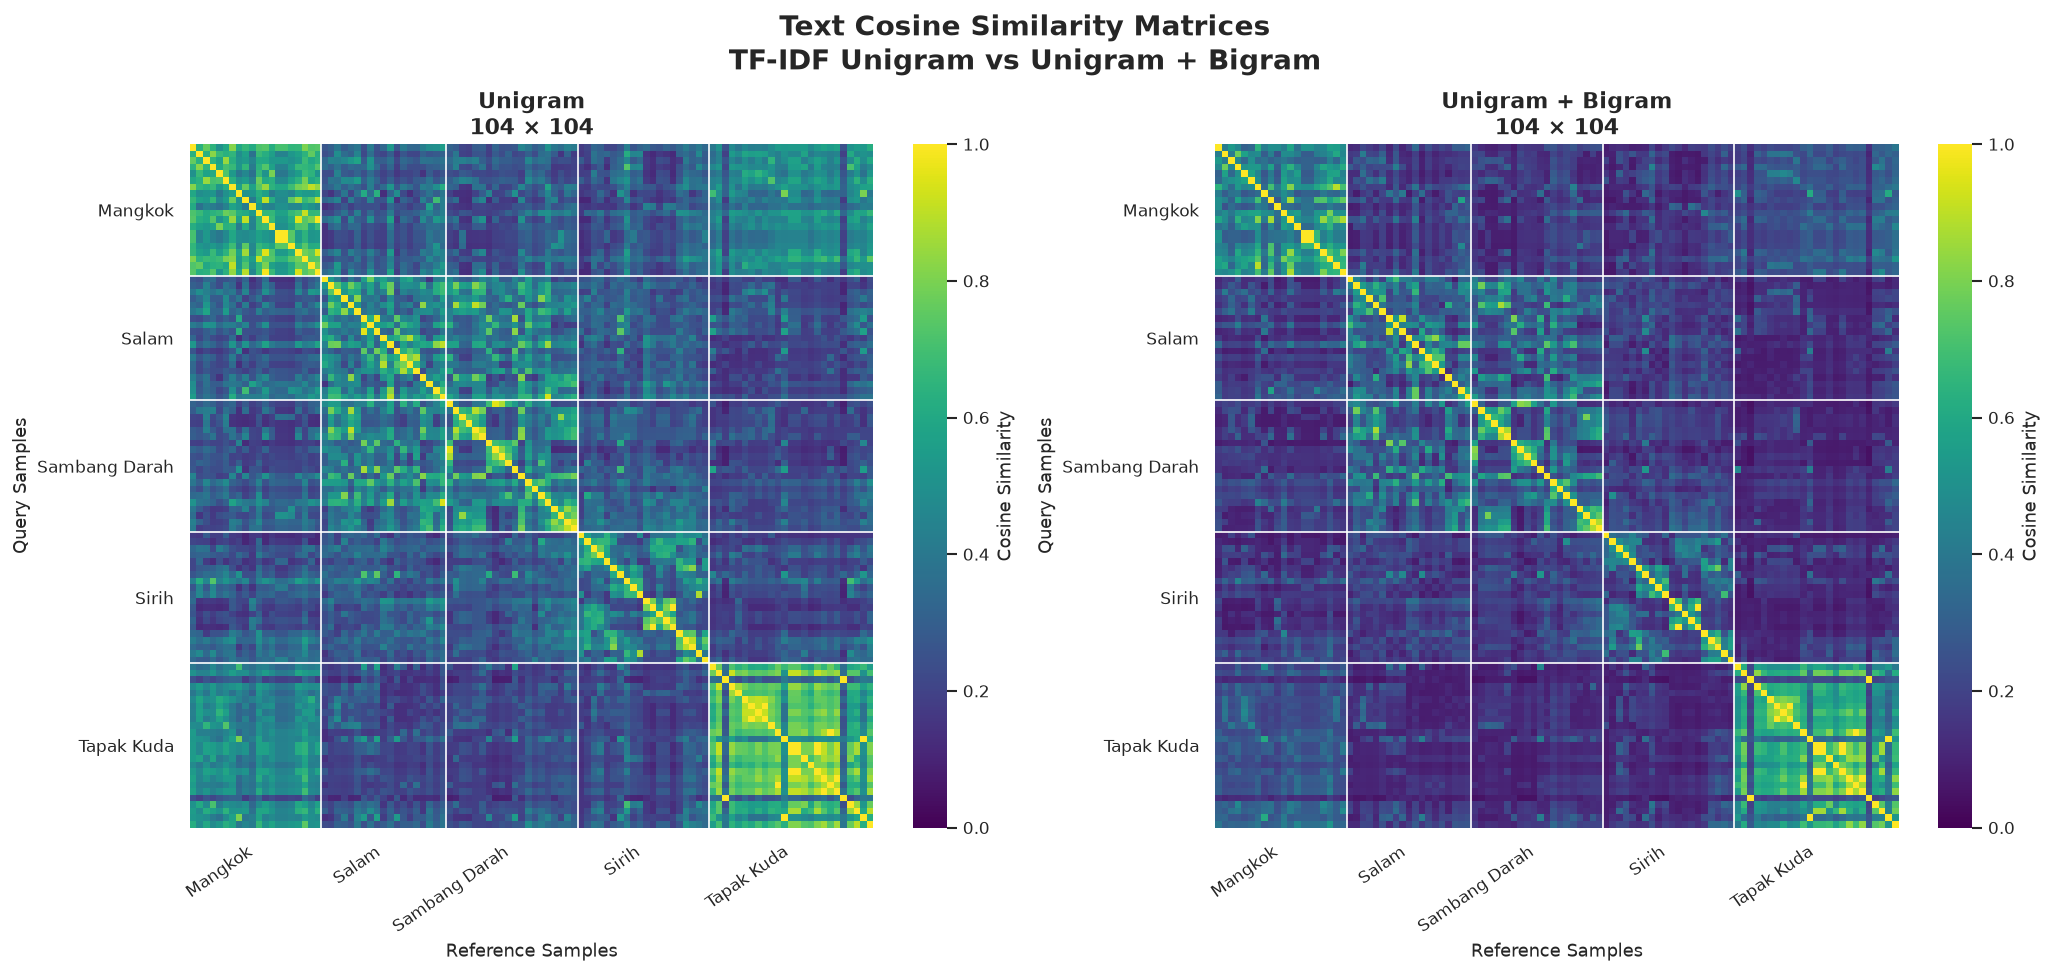

[SAVED] 121_text_cosine_similarity_matrices.png


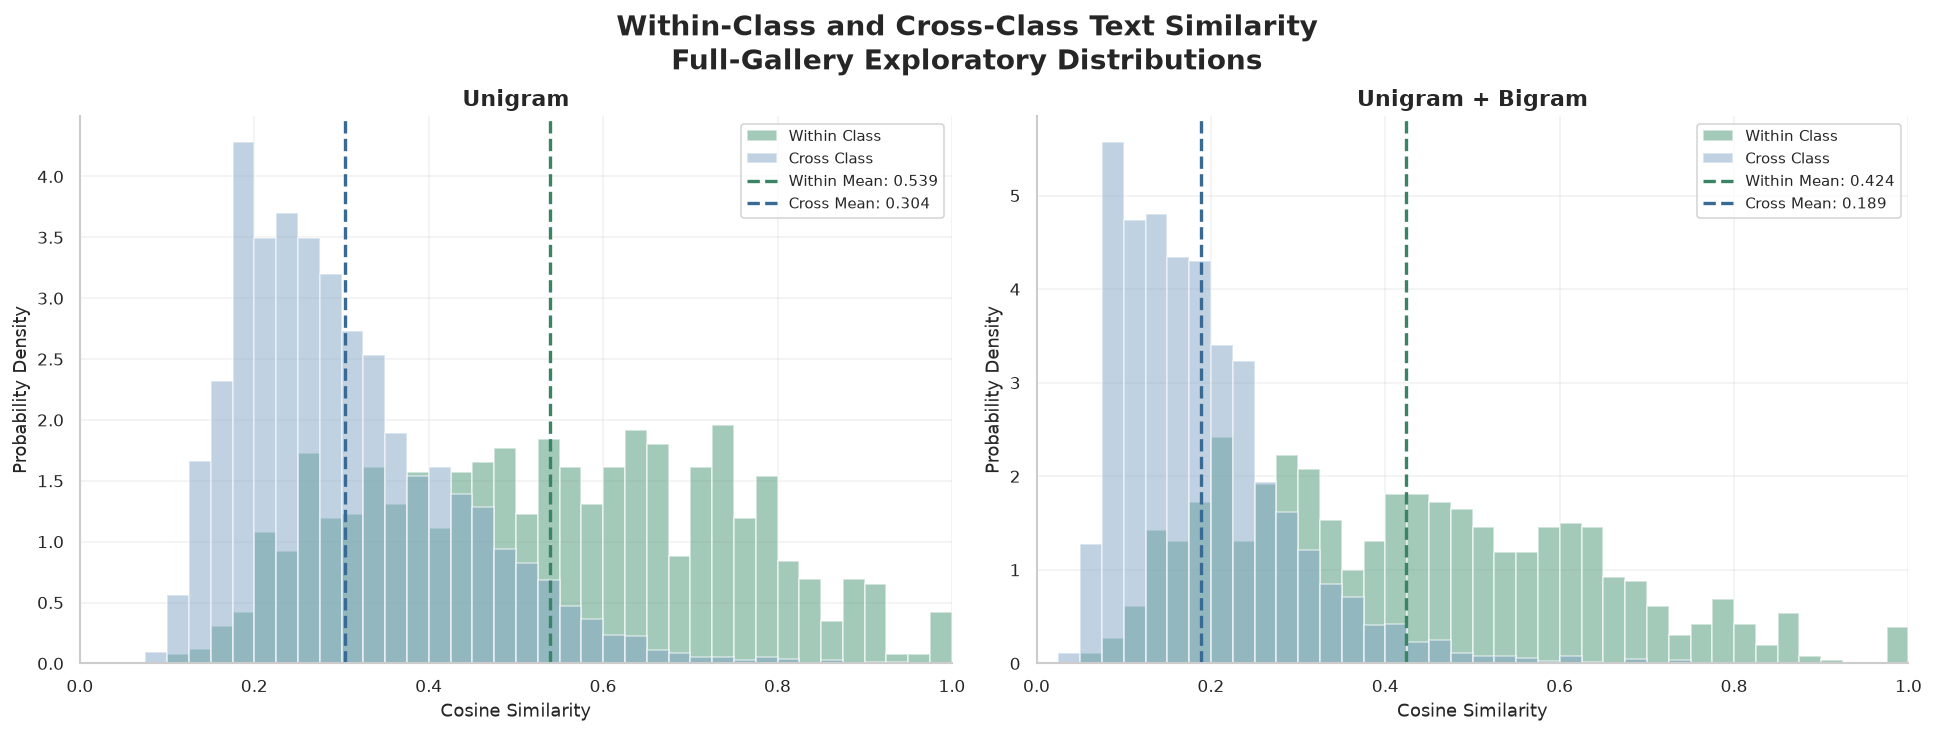

[SAVED] 122_text_cosine_within_cross_distributions.png


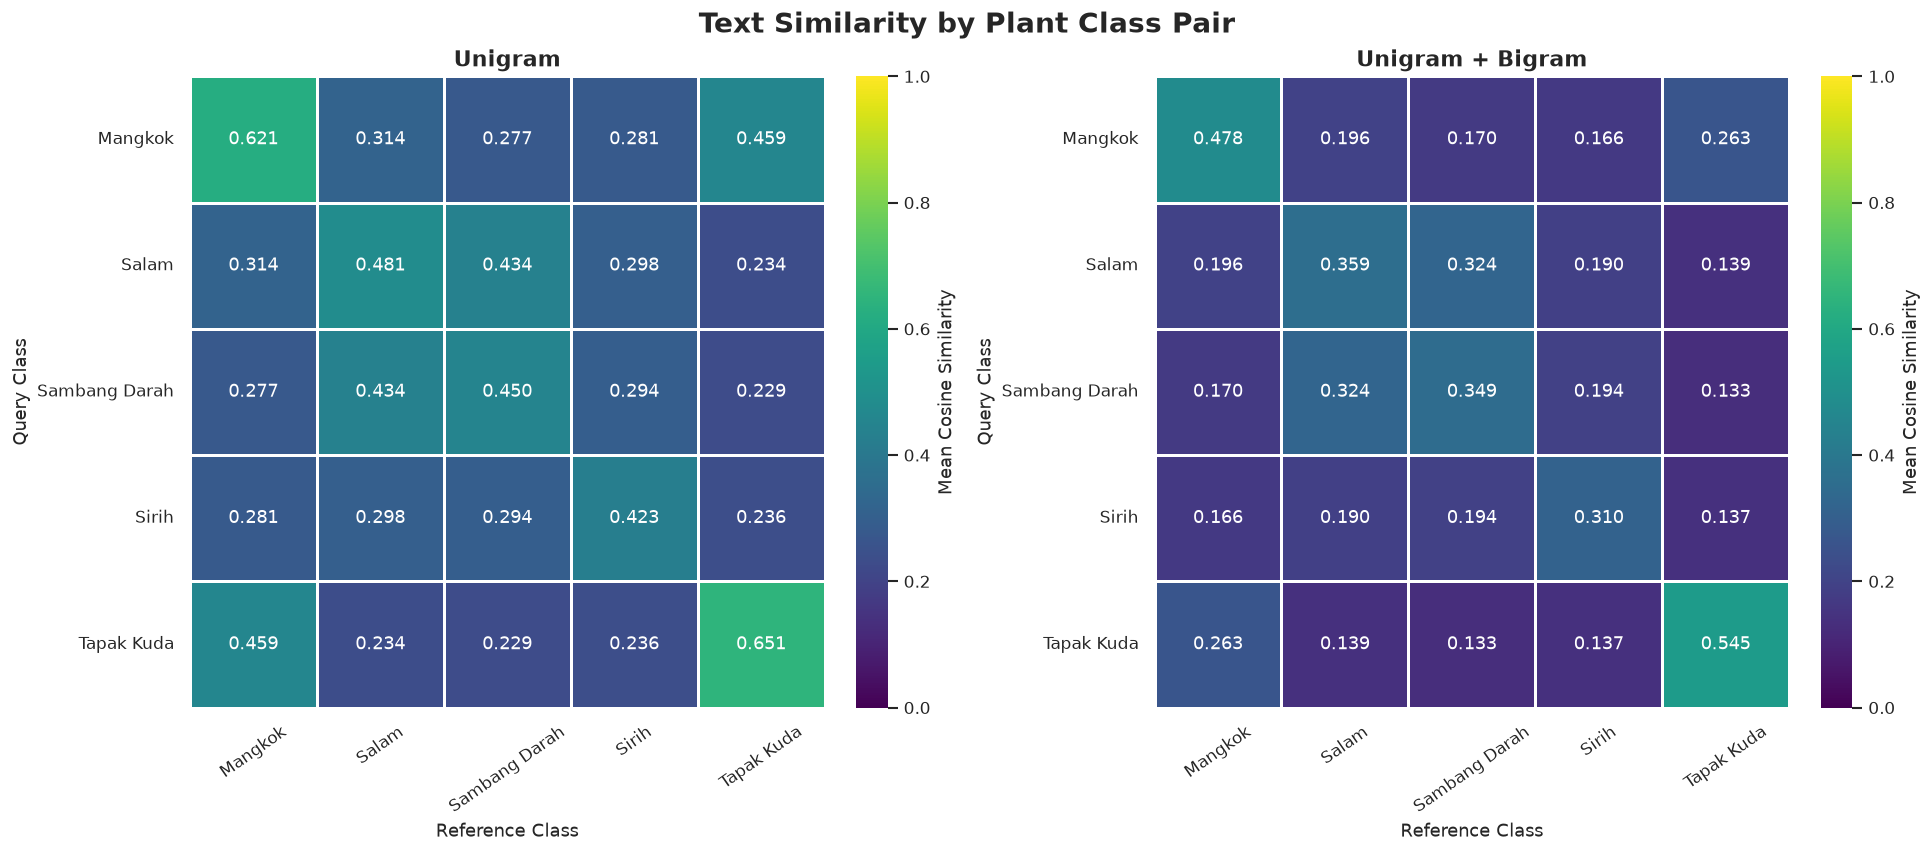

[SAVED] 123_text_cosine_class_pair_heatmaps.png


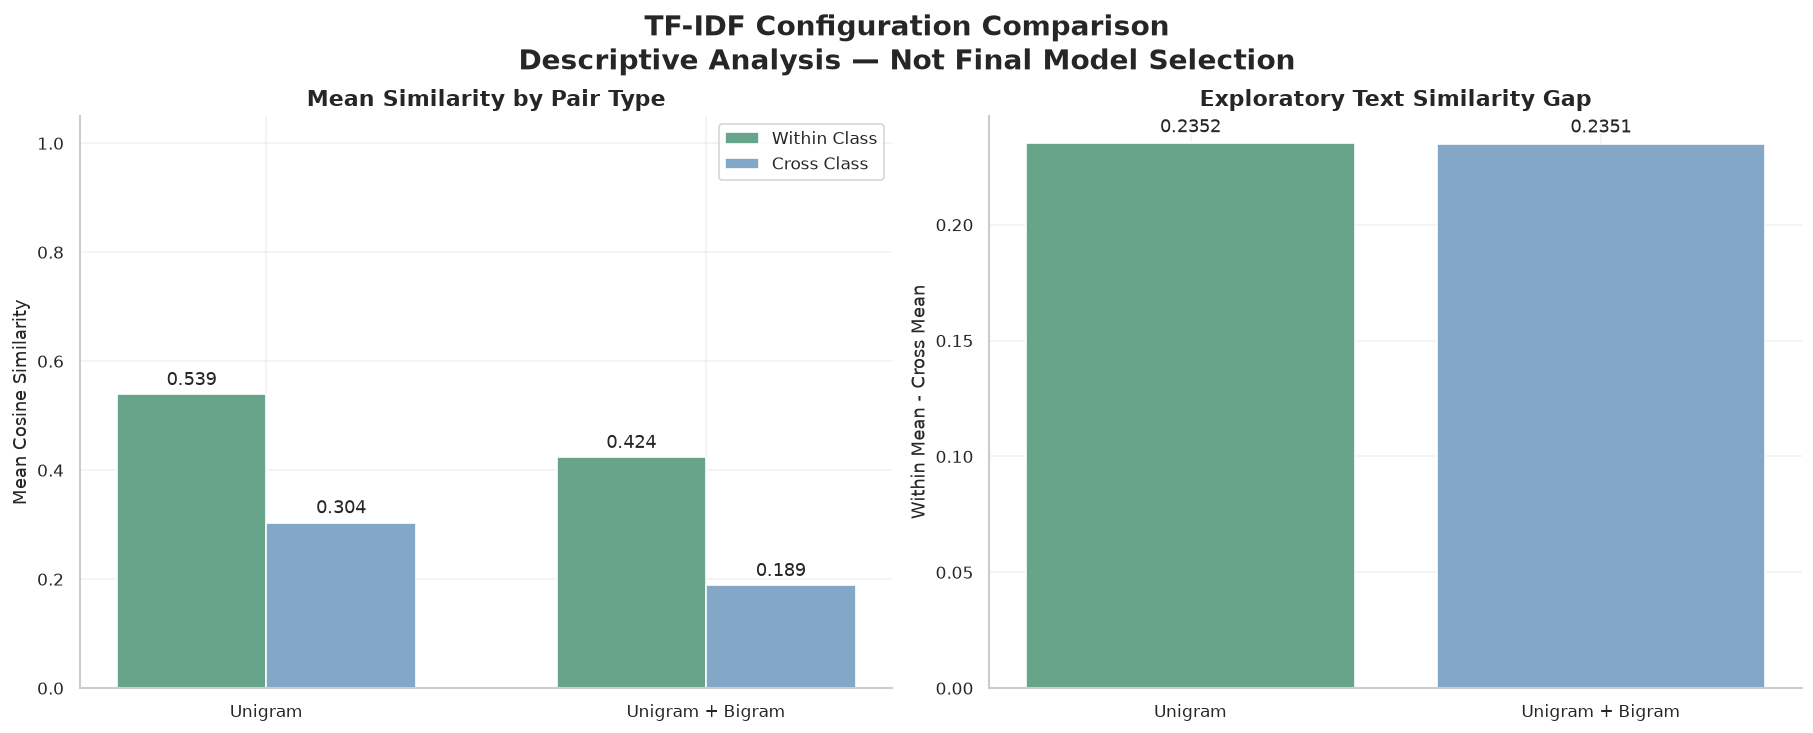

[SAVED] 124_text_cosine_configuration_comparison.png

8. TEXT COSINE SIMILARITY SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Number of samples,104
1,Number of classes,5
2,Text configurations,2
3,Unigram input shape,"(104, 68)"
4,Combined input shape,"(104, 261)"
5,Unigram cosine shape,"(104, 104)"
6,Combined cosine shape,"(104, 104)"
7,Unique pairs per configuration,5356
8,Within-class pairs per configuration,1041
9,Cross-class pairs per configuration,4315



9. SAVING TEXT COSINE SIMILARITY REPORTS
----------------------------------------------------------------------
[SAVED] 415_text_cosine_matrix_summary.csv
[SAVED] 416_text_cosine_distribution_summary.csv
[SAVED] 417_text_cosine_class_pair_summary.csv
[SAVED] 418_text_cosine_class_mean_matrices.csv
[SAVED] 419_text_cosine_manual_verification.csv
[SAVED] 420_text_cosine_nearest_neighbor_diagnostics.csv
[SAVED] 421_text_cosine_pairwise_scores.csv
[SAVED] 422_text_cosine_similarity_validation.csv
[SAVED] 423_text_cosine_similarity_summary.csv
[SAVED] 424_text_cosine_similarity_handoff.json

FINAL TEXT COSINE SIMILARITY SUMMARY

TEXT FEATURE MATRICES
----------------------------------------------------------------------
Unigram TF-IDF  : (104, 68)
Combined TF-IDF : (104, 261)

SIMILARITY MATRICES
----------------------------------------------------------------------
Unigram cosine  : (104, 104)
Combined cosine : (104, 104)

PAIR STATISTICS
--------------------------------------------------

,configuration,input_feature_dimension,input_sparsity_percent,similarity_within_mean,similarity_cross_mean,similarity_mean_gap,nearest_neighbor_class_agreement_percent
0,Unigram,68,70.503394,0.539059,0.303897,0.235161,87.500000
1,Unigram + Bigram,261,84.652225,0.423666,0.188609,0.235057,91.346154



VALIDATION RESULTS
----------------------------------------------------------------------
Technical checks: 36/36
Failed checks    : 0
Generated reports: 9
Generated figures: 4
Configuration JSON: 1

[PASS] Unigram cosine similarity calculated.
[PASS] Unigram + Bigram cosine similarity calculated.
[PASS] Sparse dot-product cross-check completed.
[PASS] Manual cosine calculations verified.
[PASS] Matrix symmetry and diagonal validated.
[PASS] Class-pair similarities analyzed.
[PASS] Self-excluded neighbor diagnostics completed.
[PASS] Reports and figures saved.

[INFO] Similarity scores are not probabilities.
[INFO] No vectorizers were refitted.
[INFO] No final text configuration selected.
[INFO] No multimodal fusion performed.
[INFO] Independent evaluation remains pending.

TEXT COSINE SIMILARITY CALCULATION COMPLETED SUCCESSFULLY

Next cell: Cell 12 - Cross-Modality Score Distribution Analysis


In [13]:
# ============================================================
# CELL 11 - TEXT COSINE SIMILARITY CALCULATION
# ============================================================

print("MULTIMODAL FUSION - TEXT COSINE SIMILARITY")
print("=" * 70)

TEXT_COSINE_SIMILARITY_COMPLETED = False
TEXT_SIMILARITY_CALCULATION_COMPLETED = False


# ============================================================
# 1. VALIDATE PREVIOUS STAGES
# ============================================================

required_stages = {
    "FUSION_LIBRARIES_IMPORTED": FUSION_LIBRARIES_IMPORTED,
    "FUSION_PATH_CONFIGURATION_COMPLETED":
        FUSION_PATH_CONFIGURATION_COMPLETED,
    "VISUAL_FEATURE_LOADING_COMPLETED":
        VISUAL_FEATURE_LOADING_COMPLETED,
    "TEXT_FEATURE_LOADING_COMPLETED":
        TEXT_FEATURE_LOADING_COMPLETED,
    "MULTIMODAL_DATASET_VALIDATION_COMPLETED":
        MULTIMODAL_DATASET_VALIDATION_COMPLETED,
    "FUSION_CONFIGURATION_COMPLETED":
        FUSION_CONFIGURATION_COMPLETED,
    "VISUAL_DISTANCE_CALCULATION_COMPLETED":
        VISUAL_DISTANCE_CALCULATION_COMPLETED,
    "VISUAL_DISTANCE_ANALYSIS_COMPLETED":
        VISUAL_DISTANCE_ANALYSIS_COMPLETED,
    "VISUAL_SIMILARITY_CONVERSION_COMPLETED":
        VISUAL_SIMILARITY_CONVERSION_COMPLETED
}

for stage_name, completed in required_stages.items():
    assert completed is True, (
        f"Run the previous cell: {stage_name}"
    )

assert text_loading_validation_df["passed"].all()
assert multimodal_validation_df["passed"].all()

assert FUSION_TEXT_SIMILARITY_METHOD == "cosine"

assert np.array_equal(
    text_sample_ids,
    multimodal_sample_ids
)

assert np.array_equal(
    text_labels,
    multimodal_labels
)

assert visual_similarity_matrix.shape == (104, 104)

print("[PASS] Previous stages validated.")


# ============================================================
# 2. CONFIGURATION
# ============================================================

TEXT_COSINE_EXPECTED_SAMPLES = 104

TEXT_COSINE_EXPECTED_DIMENSIONS = {
    "Unigram": 68,
    "Unigram + Bigram": 261
}

TEXT_COSINE_CONFIGURATIONS = [
    "Unigram",
    "Unigram + Bigram"
]

TEXT_COSINE_TOLERANCE = 1e-10
TEXT_COSINE_TOP_K_PREVIEW = 5

TEXT_COSINE_SCOPE = (
    "Full-Gallery Exploratory Text Similarity"
)

text_cosine_validation_records = []
text_cosine_figure_paths = []


def register_text_cosine_check(category, name, passed):
    text_cosine_validation_records.append({
        "category": category,
        "validation_check": name,
        "passed": bool(passed),
        "status": "Passed" if passed else "Failed"
    })


def describe_text_cosine_scores(scores, config, group):
    values = np.asarray(scores, dtype=np.float64)

    assert values.ndim == 1
    assert values.size > 0
    assert np.isfinite(values).all()

    return {
        "configuration": config,
        "pair_group": group,
        "number_of_pairs": int(values.size),
        "minimum_similarity": float(values.min()),
        "maximum_similarity": float(values.max()),
        "mean_similarity": float(values.mean()),
        "median_similarity": float(np.median(values)),
        "std_similarity": float(values.std(ddof=0)),
        "q10_similarity": float(np.quantile(values, 0.10)),
        "q25_similarity": float(np.quantile(values, 0.25)),
        "q75_similarity": float(np.quantile(values, 0.75)),
        "q90_similarity": float(np.quantile(values, 0.90))
    }


def save_text_cosine_figure(fig, filename):
    path = FUSION_FIGURES_DIR / filename

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    text_cosine_figure_paths.append(path)

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


print("\n1. TEXT SIMILARITY CONFIGURATION")
print("-" * 70)

print("Similarity method :", FUSION_TEXT_SIMILARITY_METHOD)
print("Samples           :", TEXT_COSINE_EXPECTED_SAMPLES)
print("Configurations    :", TEXT_COSINE_CONFIGURATIONS)
print("Tolerance         :", TEXT_COSINE_TOLERANCE)
print("Scope             :", TEXT_COSINE_SCOPE)


# ============================================================
# 3. PREPARE SAMPLE IDENTITIES AND PAIRS
# ============================================================

text_cosine_sample_ids = np.asarray(
    text_sample_ids,
    dtype=str
)

text_cosine_labels = np.asarray(
    text_labels,
    dtype=str
)

text_cosine_n_samples = len(
    text_cosine_sample_ids
)

assert text_cosine_n_samples == 104

assert len(np.unique(
    text_cosine_sample_ids
)) == text_cosine_n_samples

text_cosine_pair_i, text_cosine_pair_j = (
    np.triu_indices(
        text_cosine_n_samples,
        k=1
    )
)

text_cosine_within_mask = (
    text_cosine_labels[text_cosine_pair_i]
    ==
    text_cosine_labels[text_cosine_pair_j]
)

text_cosine_within_count = int(
    text_cosine_within_mask.sum()
)

text_cosine_cross_count = int(
    (~text_cosine_within_mask).sum()
)

assert len(text_cosine_pair_i) == 5356
assert text_cosine_within_count == 1041
assert text_cosine_cross_count == 4315

register_text_cosine_check(
    "Sample Alignment",
    "Text and visual sample IDs identical",
    np.array_equal(
        text_cosine_sample_ids,
        visual_similarity_sample_ids
    )
)

register_text_cosine_check(
    "Sample Alignment",
    "Text and visual labels identical",
    np.array_equal(
        text_cosine_labels,
        visual_similarity_labels
    )
)

register_text_cosine_check(
    "Pair Inventory",
    "5356 unique non-self pairs",
    len(text_cosine_pair_i) == 5356
)

register_text_cosine_check(
    "Pair Inventory",
    "1041 within-class and 4315 cross-class pairs",
    text_cosine_within_count == 1041
    and text_cosine_cross_count == 4315
)

text_cosine_classes = sorted(
    np.unique(text_cosine_labels)
)

text_cosine_class_indices = {
    class_name: np.flatnonzero(
        text_cosine_labels == class_name
    )
    for class_name in text_cosine_classes
}

print("\n2. SAMPLE AND PAIR INVENTORY")
print("-" * 70)

print("Samples           :", text_cosine_n_samples)
print("Classes           :", len(text_cosine_classes))
print("Unique pairs      :", len(text_cosine_pair_i))
print("Within-class pairs:", text_cosine_within_count)
print("Cross-class pairs :", text_cosine_cross_count)


# ============================================================
# 4. PREPARE MANUAL VERIFICATION PAIRS
# ============================================================

# Five within-class examples and five cross-class
# examples. Pairs are selected deterministically.

text_cosine_manual_pair_indices = []

for class_name in text_cosine_classes:
    indices = text_cosine_class_indices[class_name]

    assert len(indices) >= 2

    text_cosine_manual_pair_indices.append((
        "Within Class",
        int(indices[0]),
        int(indices[1])
    ))

for class_position, class_name in enumerate(
    text_cosine_classes
):
    next_class = text_cosine_classes[
        (class_position + 1)
        % len(text_cosine_classes)
    ]

    text_cosine_manual_pair_indices.append((
        "Cross Class",
        int(text_cosine_class_indices[class_name][0]),
        int(text_cosine_class_indices[next_class][0])
    ))

assert len(text_cosine_manual_pair_indices) == 10


# ============================================================
# 5. INITIALIZE OUTPUT COLLECTIONS
# ============================================================

text_cosine_similarity_matrices = {}

text_cosine_matrix_summary_records = []
text_cosine_distribution_records = []
text_cosine_class_pair_records = []
text_cosine_class_mean_records = []

text_cosine_manual_records = []
text_cosine_neighbor_records = []
text_cosine_preview_records = []

text_cosine_pairwise_frames = []

text_cosine_class_mean_matrices = {}


# ============================================================
# 6. CALCULATE COSINE SIMILARITY
# ============================================================

for configuration_name in TEXT_COSINE_CONFIGURATIONS:

    print("\n" + "=" * 70)
    print(f"CONFIGURATION: {configuration_name}")
    print("=" * 70)

    matrix = text_feature_matrices[
        configuration_name
    ]

    vectorizer = text_vectorizers[
        configuration_name
    ]

    expected_dimension = (
        TEXT_COSINE_EXPECTED_DIMENSIONS[
            configuration_name
        ]
    )

    # ----------------------------------------------
    # A. Validate the loaded TF-IDF matrix
    # ----------------------------------------------

    assert issparse(matrix)
    assert matrix.format == "csr"

    assert matrix.shape == (
        TEXT_COSINE_EXPECTED_SAMPLES,
        expected_dimension
    )

    assert matrix.dtype == np.float64

    assert np.isfinite(matrix.data).all()
    assert np.all(matrix.data >= 0)

    row_norms = np.sqrt(
        np.asarray(
            matrix.multiply(matrix).sum(axis=1)
        ).ravel()
    )

    assert np.allclose(
        row_norms,
        1.0,
        atol=TEXT_COSINE_TOLERANCE,
        rtol=0
    )

    register_text_cosine_check(
        configuration_name,
        "TF-IDF matrix shape correct",
        matrix.shape
        == (104, expected_dimension)
    )

    register_text_cosine_check(
        configuration_name,
        "All TF-IDF vectors L2-normalized",
        np.allclose(
            row_norms,
            1.0,
            atol=TEXT_COSINE_TOLERANCE,
            rtol=0
        )
    )

    # ----------------------------------------------
    # B. Calculate cosine similarity with sklearn
    # ----------------------------------------------

    start_time = time.perf_counter()

    raw_similarity = cosine_similarity(
        matrix,
        matrix,
        dense_output=True
    )

    calculation_time_ms = (
        time.perf_counter() - start_time
    ) * 1000

    # Only correct insignificant floating-point
    # overshoots outside [0,1].

    assert np.isfinite(raw_similarity).all()

    assert raw_similarity.min() >= (
        -TEXT_COSINE_TOLERANCE
    )

    assert raw_similarity.max() <= (
        1.0 + TEXT_COSINE_TOLERANCE
    )

    similarity = np.clip(
        raw_similarity,
        0.0,
        1.0
    ).astype(np.float64, copy=False)

    text_cosine_similarity_matrices[
        configuration_name
    ] = similarity

    # ----------------------------------------------
    # C. Sparse matrix multiplication cross-check
    # ----------------------------------------------

    # Because TF-IDF rows are L2-normalized:
    #
    # cosine(X_i, X_j) = X_i dot X_j
    #
    # Therefore:
    # S = X @ X.T

    sparse_product_start = time.perf_counter()

    sparse_reference = (
        matrix @ matrix.T
    ).toarray()

    sparse_product_time_ms = (
        time.perf_counter() - sparse_product_start
    ) * 1000

    sparse_crosscheck_error = float(
        np.max(
            np.abs(
                similarity - sparse_reference
            )
        )
    )

    # ----------------------------------------------
    # D. Validate similarity matrix properties
    # ----------------------------------------------

    symmetry_error = float(
        np.max(
            np.abs(
                similarity - similarity.T
            )
        )
    )

    diagonal_error = float(
        np.max(
            np.abs(
                np.diag(similarity) - 1.0
            )
        )
    )

    matrix_checks = {
        "Cosine matrix shape 104 x 104":
            similarity.shape == (104, 104),

        "All cosine values finite":
            np.isfinite(similarity).all(),

        "Cosine values between zero and one":
            np.all(
                (similarity >= 0)
                & (similarity <= 1)
            ),

        "Similarity matrix symmetric":
            symmetry_error <= TEXT_COSINE_TOLERANCE,

        "Diagonal similarity equals one":
            diagonal_error <= TEXT_COSINE_TOLERANCE,

        "Sparse dot-product result consistent":
            sparse_crosscheck_error
            <= TEXT_COSINE_TOLERANCE,

        "Vectorizer vocabulary matches feature dimension":
            len(vectorizer.get_feature_names_out())
            == expected_dimension
    }

    for name, passed in matrix_checks.items():
        register_text_cosine_check(
            configuration_name,
            name,
            passed
        )

    assert all(matrix_checks.values()), (
        f"Cosine matrix validation failed: "
        f"{configuration_name}"
    )

    # ----------------------------------------------
    # E. Summarize unique pair similarities
    # ----------------------------------------------

    pair_scores = similarity[
        text_cosine_pair_i,
        text_cosine_pair_j
    ]

    within_scores = pair_scores[
        text_cosine_within_mask
    ]

    cross_scores = pair_scores[
        ~text_cosine_within_mask
    ]

    for group_name, scores in [
        ("All Unique Pairs", pair_scores),
        ("Within Class", within_scores),
        ("Cross Class", cross_scores)
    ]:
        text_cosine_distribution_records.append(
            describe_text_cosine_scores(
                scores,
                configuration_name,
                group_name
            )
        )

    within_mean = float(within_scores.mean())
    cross_mean = float(cross_scores.mean())

    # Exploratory separation, not retrieval accuracy.

    mean_gap = within_mean - cross_mean

    # Save all 5356 unique pairs for traceability.

    text_cosine_pairwise_frames.append(
        pd.DataFrame({
            "configuration": configuration_name,
            "sample_id_i":
                text_cosine_sample_ids[text_cosine_pair_i],
            "sample_id_j":
                text_cosine_sample_ids[text_cosine_pair_j],
            "class_i":
                text_cosine_labels[text_cosine_pair_i],
            "class_j":
                text_cosine_labels[text_cosine_pair_j],
            "pair_type": np.where(
                text_cosine_within_mask,
                "Within Class",
                "Cross Class"
            ),
            "cosine_similarity": pair_scores
        })
    )

    # ----------------------------------------------
    # F. Verify 10 pairs manually
    # ----------------------------------------------

    manual_errors = []

    for pair_type, i, j in (
        text_cosine_manual_pair_indices
    ):

        row_i = matrix.getrow(i)
        row_j = matrix.getrow(j)

        dot_product = float(
            row_i.multiply(row_j).sum()
        )

        norm_i = float(
            np.sqrt(
                row_i.multiply(row_i).sum()
            )
        )

        norm_j = float(
            np.sqrt(
                row_j.multiply(row_j).sum()
            )
        )

        manual_cosine = (
            dot_product / (norm_i * norm_j)
        )

        calculated_cosine = float(
            similarity[i, j]
        )

        absolute_error = abs(
            manual_cosine - calculated_cosine
        )

        manual_errors.append(absolute_error)

        text_cosine_manual_records.append({
            "configuration": configuration_name,
            "pair_type": pair_type,
            "sample_id_i":
                text_cosine_sample_ids[i],
            "sample_id_j":
                text_cosine_sample_ids[j],
            "class_i": text_cosine_labels[i],
            "class_j": text_cosine_labels[j],
            "dot_product": dot_product,
            "norm_i": norm_i,
            "norm_j": norm_j,
            "manual_cosine": manual_cosine,
            "sklearn_cosine": calculated_cosine,
            "absolute_error": absolute_error
        })

    maximum_manual_error = float(
        max(manual_errors)
    )

    register_text_cosine_check(
        configuration_name,
        "Ten manual cosine calculations consistent",
        maximum_manual_error
        <= TEXT_COSINE_TOLERANCE
    )

    # ----------------------------------------------
    # G. Calculate class-pair similarity statistics
    # ----------------------------------------------

    n_classes = len(text_cosine_classes)

    class_mean_matrix = np.zeros(
        (n_classes, n_classes),
        dtype=np.float64
    )

    within_pair_total = 0
    cross_pair_total = 0

    for class_i_index, class_i in enumerate(
        text_cosine_classes
    ):

        for class_j_index in range(
            class_i_index,
            n_classes
        ):

            class_j = text_cosine_classes[
                class_j_index
            ]

            label_i = text_cosine_labels[
                text_cosine_pair_i
            ]

            label_j = text_cosine_labels[
                text_cosine_pair_j
            ]

            if class_i == class_j:

                selected_mask = (
                    (label_i == class_i)
                    & (label_j == class_i)
                )

                pair_type = "Within Class"

            else:

                selected_mask = (
                    (
                        (label_i == class_i)
                        & (label_j == class_j)
                    )
                    |
                    (
                        (label_i == class_j)
                        & (label_j == class_i)
                    )
                )

                pair_type = "Cross Class"

            selected_scores = pair_scores[
                selected_mask
            ]

            assert selected_scores.size > 0

            if pair_type == "Within Class":
                within_pair_total += len(selected_scores)
            else:
                cross_pair_total += len(selected_scores)

            class_mean = float(
                selected_scores.mean()
            )

            text_cosine_class_pair_records.append({
                "configuration": configuration_name,
                "class_i": class_i,
                "class_j": class_j,
                "pair_type": pair_type,
                "number_of_pairs":
                    int(selected_scores.size),
                "minimum_similarity": float(
                    selected_scores.min()
                ),
                "maximum_similarity": float(
                    selected_scores.max()
                ),
                "mean_similarity": class_mean,
                "median_similarity": float(
                    np.median(selected_scores)
                ),
                "std_similarity": float(
                    selected_scores.std(ddof=0)
                )
            })

            class_mean_matrix[
                class_i_index,
                class_j_index
            ] = class_mean

            class_mean_matrix[
                class_j_index,
                class_i_index
            ] = class_mean

    assert within_pair_total == 1041
    assert cross_pair_total == 4315

    text_cosine_class_mean_matrices[
        configuration_name
    ] = pd.DataFrame(
        class_mean_matrix,
        index=text_cosine_classes,
        columns=text_cosine_classes
    )

    # Save symmetric class-mean matrix as long data.

    for i, class_i in enumerate(text_cosine_classes):
        for j, class_j in enumerate(text_cosine_classes):

            text_cosine_class_mean_records.append({
                "configuration": configuration_name,
                "class_i": class_i,
                "class_j": class_j,
                "mean_similarity":
                    float(class_mean_matrix[i, j])
            })

    register_text_cosine_check(
        configuration_name,
        "Class-pair counts reconcile",
        within_pair_total == 1041
        and cross_pair_total == 4315
    )

    register_text_cosine_check(
        configuration_name,
        "Class-mean matrix symmetric",
        np.allclose(
            class_mean_matrix,
            class_mean_matrix.T,
            atol=TEXT_COSINE_TOLERANCE,
            rtol=0
        )
    )

    # ----------------------------------------------
    # H. Self-excluded nearest-neighbor diagnostics
    # ----------------------------------------------

    nearest_class_matches = []

    for query_index in range(
        text_cosine_n_samples
    ):

        candidates = np.arange(
            text_cosine_n_samples
        )

        candidates = candidates[
            candidates != query_index
        ]

        scores = similarity[
            query_index,
            candidates
        ]

        # Primary sort: higher similarity first.
        # Secondary sort: sample_id ascending.

        candidate_order = np.lexsort((
            text_cosine_sample_ids[candidates],
            -scores
        ))

        ranked_indices = candidates[
            candidate_order
        ]

        nearest_index = int(
            ranked_indices[0]
        )

        same_class = bool(
            text_cosine_labels[nearest_index]
            == text_cosine_labels[query_index]
        )

        nearest_class_matches.append(
            same_class
        )

        text_cosine_neighbor_records.append({
            "configuration": configuration_name,
            "query_sample_id":
                text_cosine_sample_ids[query_index],
            "query_class":
                text_cosine_labels[query_index],
            "nearest_sample_id":
                text_cosine_sample_ids[nearest_index],
            "nearest_class":
                text_cosine_labels[nearest_index],
            "cosine_similarity": float(
                similarity[
                    query_index,
                    nearest_index
                ]
            ),
            "nearest_same_class": same_class,
            "self_match_excluded":
                nearest_index != query_index
        })

    nearest_agreement_percent = float(
        100 * np.mean(nearest_class_matches)
    )

    # ----------------------------------------------
    # I. Representative Top-5 ranking previews
    # ----------------------------------------------

    for class_name in text_cosine_classes:

        query_index = int(
            text_cosine_class_indices[
                class_name
            ][0]
        )

        candidates = np.arange(
            text_cosine_n_samples
        )

        candidates = candidates[
            candidates != query_index
        ]

        candidate_order = np.lexsort((
            text_cosine_sample_ids[candidates],
            -similarity[query_index, candidates]
        ))

        selected_indices = candidates[
            candidate_order
        ][:TEXT_COSINE_TOP_K_PREVIEW]

        for rank, reference_index in enumerate(
            selected_indices,
            start=1
        ):

            text_cosine_preview_records.append({
                "configuration": configuration_name,
                "query_sample_id":
                    text_cosine_sample_ids[query_index],
                "query_class":
                    text_cosine_labels[query_index],
                "rank": rank,
                "reference_sample_id":
                    text_cosine_sample_ids[reference_index],
                "reference_class":
                    text_cosine_labels[reference_index],
                "cosine_similarity": float(
                    similarity[
                        query_index,
                        reference_index
                    ]
                ),
                "same_class": bool(
                    text_cosine_labels[reference_index]
                    == text_cosine_labels[query_index]
                )
            })

    # ----------------------------------------------
    # J. Store matrix summary
    # ----------------------------------------------

    total_entries = int(
        matrix.shape[0] * matrix.shape[1]
    )

    actual_nnz = int(
        matrix.count_nonzero()
    )

    text_cosine_matrix_summary_records.append({
        "configuration": configuration_name,
        "input_matrix_shape": str(matrix.shape),
        "similarity_matrix_shape":
            str(similarity.shape),
        "input_feature_dimension":
            matrix.shape[1],
        "input_nonzero_values": actual_nnz,
        "input_sparsity_percent": float(
            100 * (1 - actual_nnz / total_entries)
        ),
        "similarity_minimum_off_diagonal":
            float(pair_scores.min()),
        "similarity_maximum_off_diagonal":
            float(pair_scores.max()),
        "similarity_within_mean": within_mean,
        "similarity_cross_mean": cross_mean,
        "similarity_mean_gap": mean_gap,
        "maximum_symmetry_error": symmetry_error,
        "maximum_diagonal_error": diagonal_error,
        "maximum_sparse_crosscheck_error":
            sparse_crosscheck_error,
        "maximum_manual_error":
            maximum_manual_error,
        "nearest_neighbor_class_agreement_percent":
            nearest_agreement_percent,
        "sklearn_calculation_time_ms":
            calculation_time_ms,
        "sparse_product_time_ms":
            sparse_product_time_ms,
        "self_matches_excluded_from_statistics":
            True,
        "independent_evaluation_completed":
            False
    })

    print("\nMATRIX RESULTS")
    print("-" * 70)
    print("TF-IDF shape  :", matrix.shape)
    print("Cosine shape  :", similarity.shape)
    print("Within mean  :", f"{within_mean:.6f}")
    print("Cross mean   :", f"{cross_mean:.6f}")
    print("Mean gap     :", f"{mean_gap:.6f}")
    print(
        "Sparse check :",
        f"{sparse_crosscheck_error:.3e}"
    )
    print(
        "Manual check :",
        f"{maximum_manual_error:.3e}"
    )
    print(
        "NN agreement :",
        f"{nearest_agreement_percent:.2f}%"
    )


# ============================================================
# 7. CREATE REUSABLE MATRIX ALIASES
# ============================================================

text_unigram_cosine_similarity_matrix = (
    text_cosine_similarity_matrices["Unigram"]
)

text_combined_cosine_similarity_matrix = (
    text_cosine_similarity_matrices[
        "Unigram + Bigram"
    ]
)

text_unigram_similarity_matrix = (
    text_unigram_cosine_similarity_matrix
)

text_combined_similarity_matrix = (
    text_combined_cosine_similarity_matrix
)

text_similarity_matrices = (
    text_cosine_similarity_matrices
)

assert text_unigram_similarity_matrix.shape == (104, 104)
assert text_combined_similarity_matrix.shape == (104, 104)

print("\n3. MAIN TEXT SIMILARITY VARIABLES")
print("-" * 70)

print(
    "Unigram similarity:",
    text_unigram_similarity_matrix.shape
)

print(
    "Combined similarity:",
    text_combined_similarity_matrix.shape
)


# ============================================================
# 8. CONSOLIDATE RESULTS
# ============================================================

text_cosine_matrix_summary_df = pd.DataFrame(
    text_cosine_matrix_summary_records
)

text_cosine_distribution_summary_df = pd.DataFrame(
    text_cosine_distribution_records
)

text_cosine_class_pair_summary_df = pd.DataFrame(
    text_cosine_class_pair_records
)

text_cosine_class_mean_long_df = pd.DataFrame(
    text_cosine_class_mean_records
)

text_cosine_manual_verification_df = pd.DataFrame(
    text_cosine_manual_records
)

text_cosine_nearest_neighbor_df = pd.DataFrame(
    text_cosine_neighbor_records
)

text_cosine_ranking_preview_df = pd.DataFrame(
    text_cosine_preview_records
)

text_cosine_pairwise_scores_df = pd.concat(
    text_cosine_pairwise_frames,
    ignore_index=True
)

print("\n4. MATRIX SUMMARY")
print("-" * 70)

display(
    text_cosine_matrix_summary_df.round(6)
)

print("\n5. WITHIN-CLASS VS CROSS-CLASS DISTRIBUTION")
print("-" * 70)

display(
    text_cosine_distribution_summary_df.round(6)
)


# ============================================================
# 9. COMPARE TEXT CONFIGURATIONS
# ============================================================

text_cosine_configuration_comparison_df = (
    text_cosine_matrix_summary_df[
        [
            "configuration",
            "input_feature_dimension",
            "input_sparsity_percent",
            "similarity_within_mean",
            "similarity_cross_mean",
            "similarity_mean_gap",
            "nearest_neighbor_class_agreement_percent"
        ]
    ]
    .copy()
)

# No winner is selected from these diagnostics.
# Final selection requires independent validation.

print("\n6. TEXT CONFIGURATION COMPARISON")
print("-" * 70)

display(
    text_cosine_configuration_comparison_df.round(6)
)

print(
    "[INFO] Similarity gaps and nearest-neighbor "
    "agreement are exploratory diagnostics."
)

print(
    "[INFO] No final text configuration selected."
)


# ============================================================
# 10. OVERALL TECHNICAL VALIDATION
# ============================================================

register_text_cosine_check(
    "Overall",
    "Two cosine similarity matrices generated",
    len(text_cosine_similarity_matrices) == 2
)

register_text_cosine_check(
    "Overall",
    "Both matrices have shape 104 x 104",
    all(
        value.shape == (104, 104)
        for value in text_cosine_similarity_matrices.values()
    )
)

register_text_cosine_check(
    "Overall",
    "Both matrices use the original sample order",
    np.array_equal(
        text_cosine_sample_ids,
        multimodal_sample_ids
    )
)

register_text_cosine_check(
    "Overall",
    "30 class-pair records generated",
    len(text_cosine_class_pair_summary_df) == 30
)

register_text_cosine_check(
    "Overall",
    "20 manual pair verification records generated",
    len(text_cosine_manual_verification_df) == 20
)

register_text_cosine_check(
    "Overall",
    "208 self-excluded nearest-neighbor records",
    len(text_cosine_nearest_neighbor_df) == 208
    and text_cosine_nearest_neighbor_df[
        "self_match_excluded"
    ].all()
)

register_text_cosine_check(
    "Overall",
    "50 representative ranking preview records",
    len(text_cosine_ranking_preview_df) == 50
)

register_text_cosine_check(
    "Overall",
    "10712 unique-pair similarity records",
    len(text_cosine_pairwise_scores_df)
    == 2 * 5356
)

text_cosine_similarity_validation_df = pd.DataFrame(
    text_cosine_validation_records
)

text_cosine_validation_total_checks = len(
    text_cosine_similarity_validation_df
)

text_cosine_validation_passed_checks = int(
    text_cosine_similarity_validation_df[
        "passed"
    ].sum()
)

text_cosine_validation_failed_checks = (
    text_cosine_validation_total_checks
    - text_cosine_validation_passed_checks
)

print("\n7. TEXT COSINE SIMILARITY VALIDATION")
print("-" * 70)

display(text_cosine_similarity_validation_df)

# Preserve diagnostics before stopping on a failure.

text_cosine_similarity_validation_df.to_csv(
    METRICS_DIR
    / "422_text_cosine_similarity_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

assert text_cosine_similarity_validation_df[
    "passed"
].all(), (
    text_cosine_similarity_validation_df.loc[
        ~text_cosine_similarity_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All text similarity checks passed.")


# ============================================================
# 11. FIGURE 121 - TEXT COSINE SIMILARITY MATRICES
# ============================================================

# Sorting is used only for visualization.
# Original matrices are not reordered.

plot_order = np.argsort(
    text_cosine_labels,
    kind="stable"
)

plot_labels = text_cosine_labels[
    plot_order
]

class_boundaries = np.flatnonzero(
    plot_labels[1:] != plot_labels[:-1]
) + 1

class_starts = np.r_[
    0,
    class_boundaries
]

class_ends = np.r_[
    class_boundaries,
    text_cosine_n_samples
]

class_centers = (
    class_starts + class_ends
) / 2

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 8),
    constrained_layout=True
)

for ax, configuration_name in zip(
    axes,
    TEXT_COSINE_CONFIGURATIONS
):

    matrix = text_cosine_similarity_matrices[
        configuration_name
    ]

    plot_matrix = matrix[
        np.ix_(
            plot_order,
            plot_order
        )
    ]

    sns.heatmap(
        plot_matrix,
        cmap=SIMILARITY_CMAP,
        vmin=0,
        vmax=1,
        square=True,
        xticklabels=False,
        yticklabels=False,
        cbar_kws={
            "label": "Cosine Similarity"
        },
        ax=ax
    )

    for boundary in class_boundaries:
        ax.axhline(
            boundary,
            color="white",
            linewidth=1.0
        )
        ax.axvline(
            boundary,
            color="white",
            linewidth=1.0
        )

    ax.set_xticks(class_centers)
    ax.set_yticks(class_centers)

    ax.set_xticklabels(
        plot_labels[class_starts],
        rotation=35,
        ha="right"
    )

    ax.set_yticklabels(
        plot_labels[class_starts],
        rotation=0
    )

    ax.set_title(
        f"{configuration_name}\n"
        f"{matrix.shape[0]} × {matrix.shape[1]}"
    )

    ax.set_xlabel("Reference Samples")
    ax.set_ylabel("Query Samples")

fig.suptitle(
    "Text Cosine Similarity Matrices\n"
    "TF-IDF Unigram vs Unigram + Bigram",
    fontsize=17,
    fontweight="bold"
)

save_text_cosine_figure(
    fig,
    "121_text_cosine_similarity_matrices.png"
)


# ============================================================
# 12. FIGURE 122 - SCORE DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    constrained_layout=True
)

bins = np.linspace(0, 1, 41)

for ax, configuration_name in zip(
    axes,
    TEXT_COSINE_CONFIGURATIONS
):

    matrix = text_cosine_similarity_matrices[
        configuration_name
    ]

    pair_scores = matrix[
        text_cosine_pair_i,
        text_cosine_pair_j
    ]

    within_scores = pair_scores[
        text_cosine_within_mask
    ]

    cross_scores = pair_scores[
        ~text_cosine_within_mask
    ]

    ax.hist(
        within_scores,
        bins=bins,
        density=True,
        alpha=0.6,
        color="#66A58A",
        label="Within Class"
    )

    ax.hist(
        cross_scores,
        bins=bins,
        density=True,
        alpha=0.5,
        color="#83A7C7",
        label="Cross Class"
    )

    ax.axvline(
        within_scores.mean(),
        color="#398464",
        linestyle="--",
        linewidth=2,
        label=f"Within Mean: {within_scores.mean():.3f}"
    )

    ax.axvline(
        cross_scores.mean(),
        color="#386A94",
        linestyle="--",
        linewidth=2,
        label=f"Cross Mean: {cross_scores.mean():.3f}"
    )

    ax.set_title(configuration_name)
    ax.set_xlabel("Cosine Similarity")
    ax.set_ylabel("Probability Density")
    ax.set_xlim(0, 1)
    ax.legend(fontsize=9)

fig.suptitle(
    "Within-Class and Cross-Class Text Similarity\n"
    "Full-Gallery Exploratory Distributions",
    fontsize=17,
    fontweight="bold"
)

save_text_cosine_figure(
    fig,
    "122_text_cosine_within_cross_distributions.png"
)


# ============================================================
# 13. FIGURE 123 - CLASS-PAIR SIMILARITY
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    constrained_layout=True
)

for ax, configuration_name in zip(
    axes,
    TEXT_COSINE_CONFIGURATIONS
):

    class_matrix = text_cosine_class_mean_matrices[
        configuration_name
    ]

    sns.heatmap(
        class_matrix,
        annot=True,
        fmt=".3f",
        cmap=SIMILARITY_CMAP,
        vmin=0,
        vmax=1,
        linewidths=0.8,
        linecolor="white",
        cbar_kws={
            "label": "Mean Cosine Similarity"
        },
        ax=ax
    )

    ax.set_title(configuration_name)
    ax.set_xlabel("Reference Class")
    ax.set_ylabel("Query Class")
    ax.tick_params(axis="x", rotation=35)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle(
    "Text Similarity by Plant Class Pair",
    fontsize=17,
    fontweight="bold"
)

save_text_cosine_figure(
    fig,
    "123_text_cosine_class_pair_heatmaps.png"
)


# ============================================================
# 14. FIGURE 124 - CONFIGURATION COMPARISON
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    constrained_layout=True
)

comparison_df = (
    text_cosine_configuration_comparison_df
    .set_index("configuration")
    .loc[TEXT_COSINE_CONFIGURATIONS]
)

positions = np.arange(
    len(TEXT_COSINE_CONFIGURATIONS)
)

width = 0.34

within_bars = axes[0].bar(
    positions - width / 2,
    comparison_df["similarity_within_mean"],
    width=width,
    color="#66A58A",
    label="Within Class"
)

cross_bars = axes[0].bar(
    positions + width / 2,
    comparison_df["similarity_cross_mean"],
    width=width,
    color="#83A7C7",
    label="Cross Class"
)

axes[0].bar_label(
    within_bars,
    fmt="%.3f",
    padding=3
)

axes[0].bar_label(
    cross_bars,
    fmt="%.3f",
    padding=3
)

axes[0].set_xticks(positions)
axes[0].set_xticklabels(TEXT_COSINE_CONFIGURATIONS)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Mean Cosine Similarity")
axes[0].set_title("Mean Similarity by Pair Type")
axes[0].legend()

gap_bars = axes[1].bar(
    TEXT_COSINE_CONFIGURATIONS,
    comparison_df["similarity_mean_gap"],
    color=["#66A58A", "#83A7C7"]
)

axes[1].bar_label(
    gap_bars,
    fmt="%.4f",
    padding=4
)

axes[1].axhline(
    0,
    color="#555555",
    linewidth=1
)

axes[1].set_ylabel(
    "Within Mean - Cross Mean"
)

axes[1].set_title(
    "Exploratory Text Similarity Gap"
)

fig.suptitle(
    "TF-IDF Configuration Comparison\n"
    "Descriptive Analysis — Not Final Model Selection",
    fontsize=17,
    fontweight="bold"
)

save_text_cosine_figure(
    fig,
    "124_text_cosine_configuration_comparison.png"
)


# ============================================================
# 15. FINAL SUMMARY
# ============================================================

text_cosine_similarity_summary_df = pd.DataFrame([
    ("Number of samples", text_cosine_n_samples),
    ("Number of classes", len(text_cosine_classes)),
    ("Text configurations", len(TEXT_COSINE_CONFIGURATIONS)),
    ("Unigram input shape", str(tfidf_unigram_features.shape)),
    ("Combined input shape", str(tfidf_combined_features.shape)),
    ("Unigram cosine shape", str(text_unigram_similarity_matrix.shape)),
    ("Combined cosine shape", str(text_combined_similarity_matrix.shape)),
    ("Unique pairs per configuration", 5356),
    ("Within-class pairs per configuration", 1041),
    ("Cross-class pairs per configuration", 4315),
    ("Manual calculations checked", len(text_cosine_manual_verification_df)),
    ("Class-pair combinations", len(text_cosine_class_pair_summary_df)),
    ("Nearest-neighbor diagnostic records", len(text_cosine_nearest_neighbor_df)),
    ("Technical validation checks", text_cosine_validation_total_checks),
    ("Technical checks passed", text_cosine_validation_passed_checks),
    ("Technical checks failed", text_cosine_validation_failed_checks),
    ("Generated figures", len(text_cosine_figure_paths)),
    ("Vectorizers refitted", False),
    ("Original sample order modified", False),
    ("Visual-text scores fused", False),
    ("Final text configuration selected", False),
    ("Independent retrieval evaluation completed", False),
    ("Analysis scope", TEXT_COSINE_SCOPE)
], columns=["Indicator", "Result"])

print("\n8. TEXT COSINE SIMILARITY SUMMARY")
print("-" * 70)

display(text_cosine_similarity_summary_df)


# ============================================================
# 16. SAVE REPORTS
# ============================================================

text_cosine_reports = {
    "415_text_cosine_matrix_summary.csv":
        text_cosine_matrix_summary_df,

    "416_text_cosine_distribution_summary.csv":
        text_cosine_distribution_summary_df,

    "417_text_cosine_class_pair_summary.csv":
        text_cosine_class_pair_summary_df,

    "418_text_cosine_class_mean_matrices.csv":
        text_cosine_class_mean_long_df,

    "419_text_cosine_manual_verification.csv":
        text_cosine_manual_verification_df,

    "420_text_cosine_nearest_neighbor_diagnostics.csv":
        text_cosine_nearest_neighbor_df,

    "421_text_cosine_pairwise_scores.csv":
        text_cosine_pairwise_scores_df,

    "422_text_cosine_similarity_validation.csv":
        text_cosine_similarity_validation_df,

    "423_text_cosine_similarity_summary.csv":
        text_cosine_similarity_summary_df
}

print("\n9. SAVING TEXT COSINE SIMILARITY REPORTS")
print("-" * 70)

for filename, dataframe in text_cosine_reports.items():

    output_path = METRICS_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ============================================================
# 17. SAVE CONFIGURATION HANDOFF
# ============================================================

text_cosine_handoff = {
    "notebook": "05_multimodal_fusion.ipynb",
    "cell": 11,
    "method": "cosine_similarity",
    "input_feature_type": "TF-IDF",
    "configurations": {
        name: {
            "input_shape": list(
                text_feature_matrices[name].shape
            ),
            "similarity_shape": list(
                text_cosine_similarity_matrices[name].shape
            ),
            "l2_normalized": True
        }
        for name in TEXT_COSINE_CONFIGURATIONS
    },
    "sample_alignment_signature":
        multimodal_alignment_signature,
    "score_range": [0.0, 1.0],
    "diagonal_self_similarity": 1.0,
    "self_matches_excluded_from_ranking": True,
    "tie_breaking":
        "similarity_descending_then_sample_id_ascending",
    "feature_matrices_refitted": False,
    "text_configuration_selected": False,
    "multimodal_fusion_completed": False,
    "independent_evaluation_completed": False,
    "analysis_scope": TEXT_COSINE_SCOPE
}

TEXT_COSINE_HANDOFF_PATH = (
    METRICS_DIR
    / "424_text_cosine_similarity_handoff.json"
)

with open(
    TEXT_COSINE_HANDOFF_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        text_cosine_handoff,
        file,
        indent=4,
        ensure_ascii=False,
        allow_nan=False
    )

print(f"[SAVED] {TEXT_COSINE_HANDOFF_PATH.name}")


# ============================================================
# 18. FINAL COMPLETION CHECKS
# ============================================================

assert text_cosine_similarity_validation_df[
    "passed"
].all()

assert text_cosine_validation_failed_checks == 0

assert text_unigram_similarity_matrix.shape == (104, 104)
assert text_combined_similarity_matrix.shape == (104, 104)

assert len(text_cosine_manual_verification_df) == 20
assert len(text_cosine_class_pair_summary_df) == 30
assert len(text_cosine_pairwise_scores_df) == 10712

assert len(text_cosine_figure_paths) == 4

assert all(
    path.is_file() and path.stat().st_size > 0
    for path in text_cosine_figure_paths
)

assert all(
    (METRICS_DIR / filename).is_file()
    and (METRICS_DIR / filename).stat().st_size > 0
    for filename in text_cosine_reports
)

assert TEXT_COSINE_HANDOFF_PATH.is_file()

TEXT_COSINE_SIMILARITY_COMPLETED = True
TEXT_SIMILARITY_CALCULATION_COMPLETED = True


# ============================================================
# 19. PRINT FINAL OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("FINAL TEXT COSINE SIMILARITY SUMMARY")
print("=" * 70)

print("\nTEXT FEATURE MATRICES")
print("-" * 70)
print("Unigram TF-IDF  :", tfidf_unigram_features.shape)
print("Combined TF-IDF :", tfidf_combined_features.shape)

print("\nSIMILARITY MATRICES")
print("-" * 70)
print("Unigram cosine  :", text_unigram_similarity_matrix.shape)
print("Combined cosine :", text_combined_similarity_matrix.shape)

print("\nPAIR STATISTICS")
print("-" * 70)
print("Unique pairs per configuration :", 5356)
print("Within-class pairs             :", 1041)
print("Cross-class pairs              :", 4315)

print("\nCONFIGURATION COMPARISON")
print("-" * 70)

display(
    text_cosine_configuration_comparison_df.round(6)
)

print("\nVALIDATION RESULTS")
print("-" * 70)
print(
    "Technical checks:",
    f"{text_cosine_validation_passed_checks}/"
    f"{text_cosine_validation_total_checks}"
)
print("Failed checks    :", text_cosine_validation_failed_checks)
print("Generated reports:", len(text_cosine_reports))
print("Generated figures:", len(text_cosine_figure_paths))
print("Configuration JSON:", 1)

print("\n[PASS] Unigram cosine similarity calculated.")
print("[PASS] Unigram + Bigram cosine similarity calculated.")
print("[PASS] Sparse dot-product cross-check completed.")
print("[PASS] Manual cosine calculations verified.")
print("[PASS] Matrix symmetry and diagonal validated.")
print("[PASS] Class-pair similarities analyzed.")
print("[PASS] Self-excluded neighbor diagnostics completed.")
print("[PASS] Reports and figures saved.")

print("\n[INFO] Similarity scores are not probabilities.")
print("[INFO] No vectorizers were refitted.")
print("[INFO] No final text configuration selected.")
print("[INFO] No multimodal fusion performed.")
print("[INFO] Independent evaluation remains pending.")

print("\n" + "=" * 70)
print("TEXT COSINE SIMILARITY CALCULATION COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nNext cell: Cell 12 - Cross-Modality Score Distribution Analysis")

MULTIMODAL FUSION - CROSS-MODALITY SCORE ANALYSIS

1. SIMILARITY MATRIX CONFIGURATION
------------------------------------------------------------------------
Visual                    : (104, 104)
Text - Unigram            : (104, 104)
Text - Unigram + Bigram   : (104, 104)
Sample count: 104

2. MATCHED SAMPLE PAIRS
------------------------------------------------------------------------
Unique pairs     : 5356
Within-class     : 1041
Cross-class      : 4315

3. SIMILARITY MATRIX INTEGRITY
------------------------------------------------------------------------


,modality,matrix_shape,dtype,minimum_matrix_value,maximum_matrix_value,maximum_symmetry_error,maximum_diagonal_error,shape_104x104,finite,range_0_to_1,symmetric,diagonal_one
0,Visual,"(104, 104)",float64,0.157076,1.0,0.0,0.000000e+00,True,True,True,True,True
1,Text - Unigram,"(104, 104)",float64,0.079567,1.0,0.0,5.551115e-16,True,True,True,True,True
2,Text - Unigram + Bigram,"(104, 104)",float64,0.040643,1.0,0.0,3.330669e-16,True,True,True,True,True



4. SCORE SCALE COMPARISON
------------------------------------------------------------------------


,modality,mean_all_pairs,std_all_pairs,iqr_all_pairs,q05_to_q95_range,within_class_mean,cross_class_mean,within_minus_cross_mean_gap,zero_or_near_zero_percent,near_one_percent,score_calibration_completed
0,Visual,0.315008,0.063091,0.073019,0.199470,0.351734,0.306148,0.045586,0.0,0.000000,False
1,Text - Unigram,0.349604,0.170322,0.217823,0.560779,0.539059,0.303897,0.235161,0.0,0.186706,False
2,Text - Unigram + Bigram,0.234295,0.155136,0.156914,0.506425,0.423666,0.188609,0.235057,0.0,0.186706,False



5. WITHIN / CROSS SCORE DISTRIBUTIONS
------------------------------------------------------------------------


,modality,pair_group,number_of_pairs,minimum,mean,median,maximum,std_population,q05,q25,q75,q95,iqr,zero_or_near_zero_percent,near_one_percent
0,Visual,All Unique Pairs,5356,0.157076,0.315008,0.311849,0.827249,0.063091,0.222786,0.275213,0.348233,0.422256,0.073019,0.0,0.000000
1,Visual,Within Class,1041,0.167650,0.351734,0.341988,0.827249,0.081812,0.236930,0.298132,0.392006,0.499842,0.093873,0.0,0.000000
2,Visual,Cross Class,4315,0.157076,0.306148,0.304963,0.550948,0.054056,0.219351,0.270979,0.339059,0.399952,0.068080,0.0,0.000000
3,Text - Unigram,All Unique Pairs,5356,0.079567,0.349604,0.304541,1.000000,0.170322,0.151415,0.221903,0.439726,0.712194,0.217823,0.0,0.186706
4,Text - Unigram,Within Class,1041,0.114713,0.539059,0.537946,1.000000,0.199742,0.225041,0.375048,0.701987,0.870705,0.326939,0.0,0.960615
5,Text - Unigram,Cross Class,4315,0.079567,0.303897,0.277468,0.940002,0.125038,0.147624,0.208231,0.375677,0.540793,0.167447,0.0,0.000000
6,Text - Unigram + Bigram,All Unique Pairs,5356,0.040643,0.234295,0.191822,1.000000,0.155136,0.080188,0.127062,0.283976,0.586613,0.156914,0.0,0.186706
7,Text - Unigram + Bigram,Within Class,1041,0.062217,0.423666,0.412454,1.000000,0.200130,0.144182,0.264131,0.573429,0.783298,0.309298,0.0,0.960615
8,Text - Unigram + Bigram,Cross Class,4315,0.040643,0.188609,0.170404,0.867398,0.097324,0.078157,0.115789,0.235230,0.369749,0.119441,0.0,0.000000


... (7 outputs left out)

,modality_a,modality_b,k,number_of_queries,mean_overlap_at_k,std_overlap_at_k,median_overlap_at_k,mean_jaccard_at_k
0,Text - Unigram,Text - Unigram + Bigram,1,104,0.7596,0.4294,1.0000,0.7596
1,Text - Unigram,Text - Unigram + Bigram,3,104,0.7885,0.2371,0.6667,0.7087
2,Text - Unigram,Text - Unigram + Bigram,5,104,0.8250,0.1593,0.8000,0.7317
3,Text - Unigram,Text - Unigram + Bigram,10,104,0.8375,0.0997,0.8000,0.7331
4,Visual,Text - Unigram,1,104,0.1442,0.3530,0.0000,0.1442
5,Visual,Text - Unigram,3,104,0.2949,0.2640,0.3333,0.2038
6,Visual,Text - Unigram,5,104,0.3769,0.2269,0.4000,0.2571
7,Visual,Text - Unigram,10,104,0.4173,0.1598,0.4000,0.2768
8,Visual,Text - Unigram + Bigram,1,104,0.1538,0.3625,0.0000,0.1538
9,Visual,Text - Unigram + Bigram,3,104,0.3237,0.2805,0.3333,0.2308


[INFO] Ranking overlap is not retrieval accuracy.

10. TECHNICAL VALIDATION
------------------------------------------------------------------------


,category,validation_check,passed,status
0,Alignment,104 paired sample IDs and class labels preserved,True,Passed
1,Alignment,"5356 unique pairs, 1041 within and 4315 cross",True,Passed
2,Matrix - Visual,shape_104x104,True,Passed
3,Matrix - Visual,finite,True,Passed
4,Matrix - Visual,range_0_to_1,True,Passed
5,Matrix - Visual,symmetric,True,Passed
6,Matrix - Visual,diagonal_one,True,Passed
7,Matrix - Text - Unigram,shape_104x104,True,Passed
8,Matrix - Text - Unigram,finite,True,Passed
9,Matrix - Text - Unigram,range_0_to_1,True,Passed


[PASS] All cross-modality checks passed.


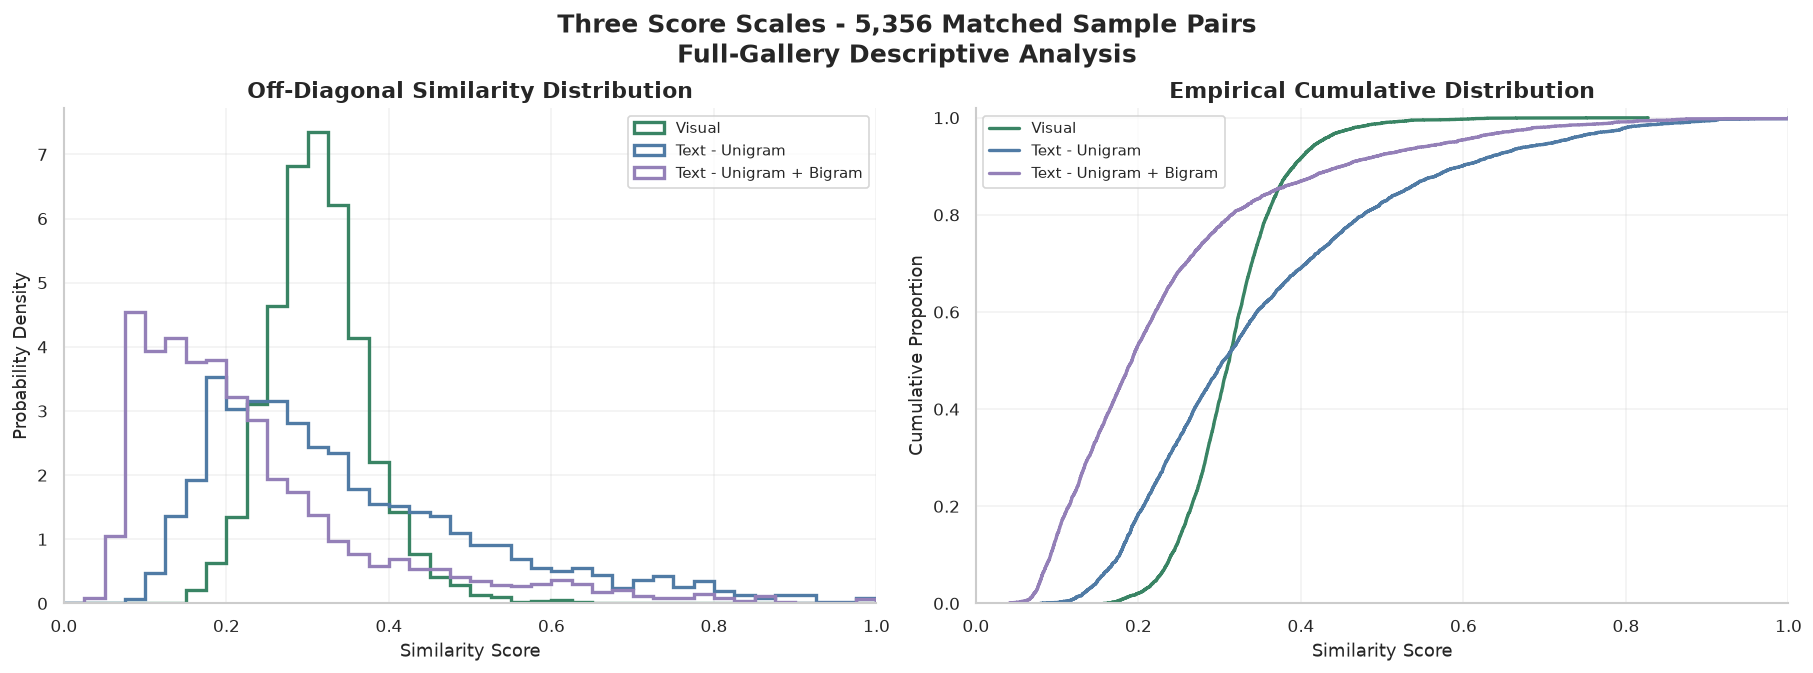

[SAVED] 125_cross_modality_score_distributions.png


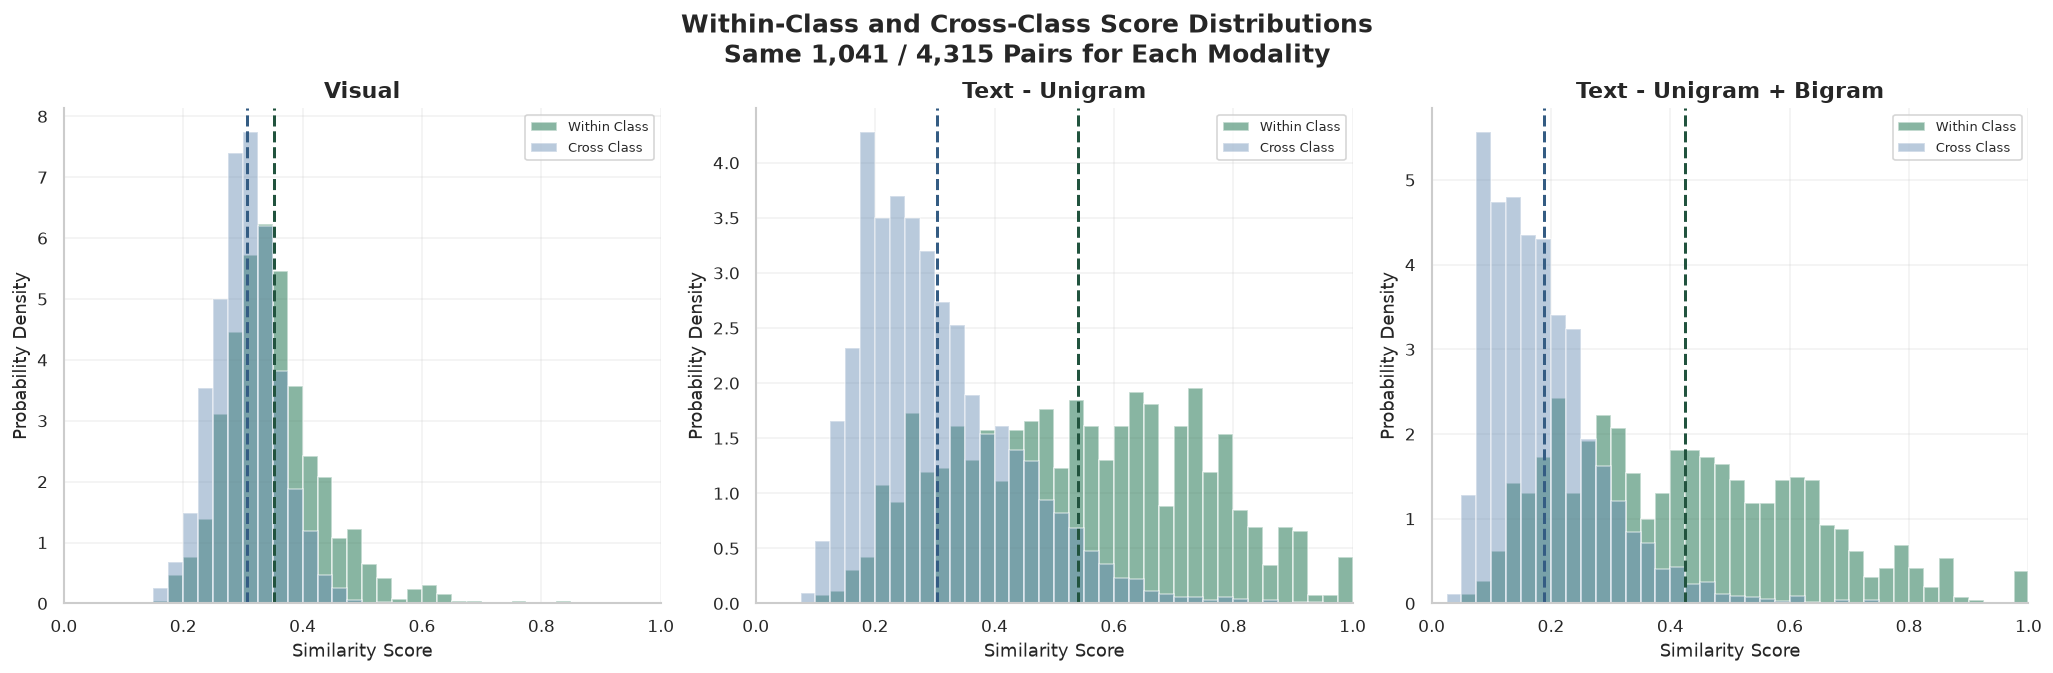

[SAVED] 126_cross_modality_within_cross_distributions.png


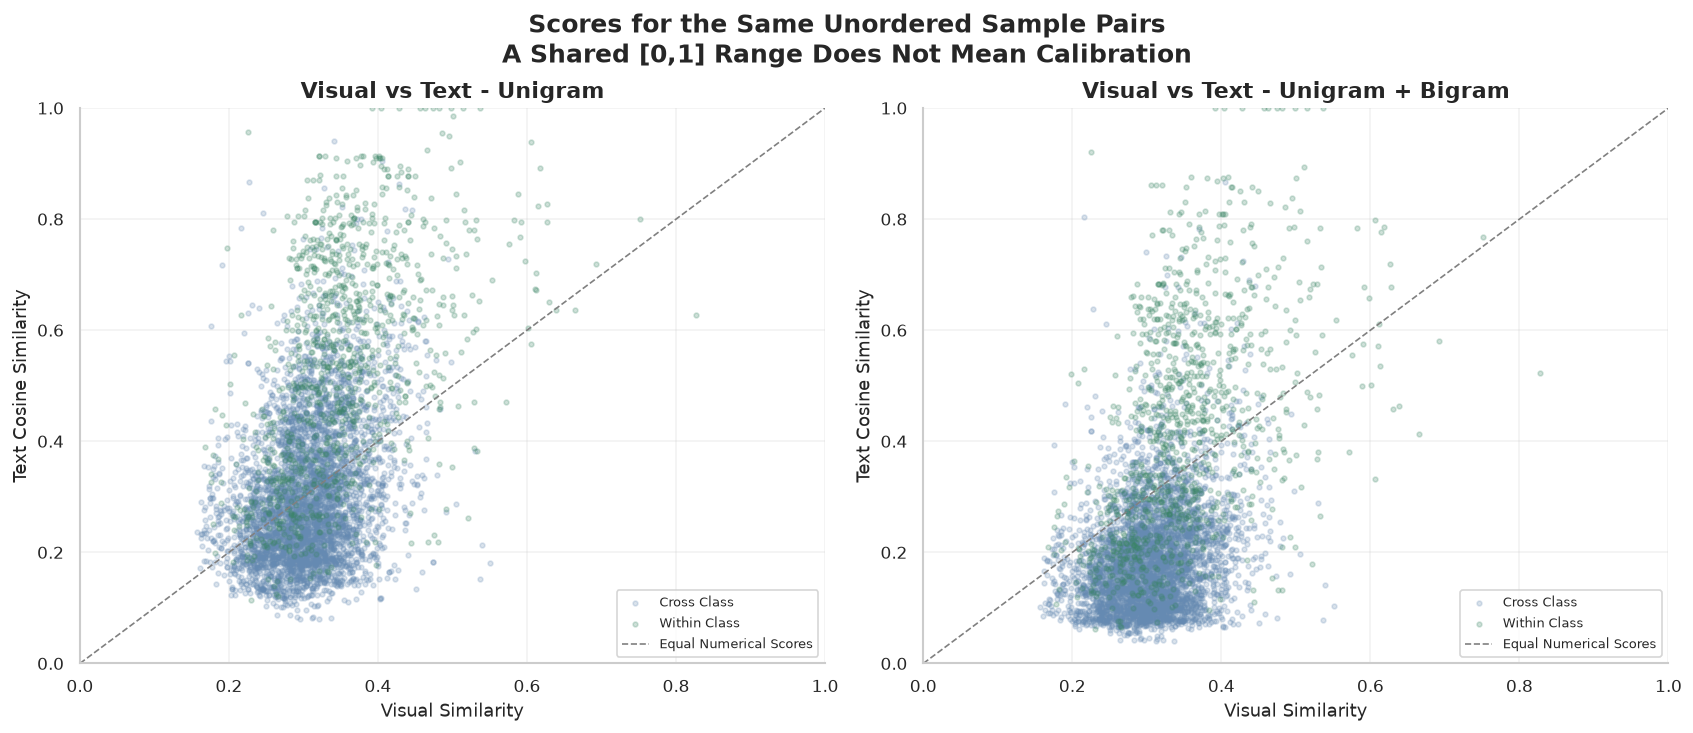

[SAVED] 127_cross_modality_paired_score_scatter.png


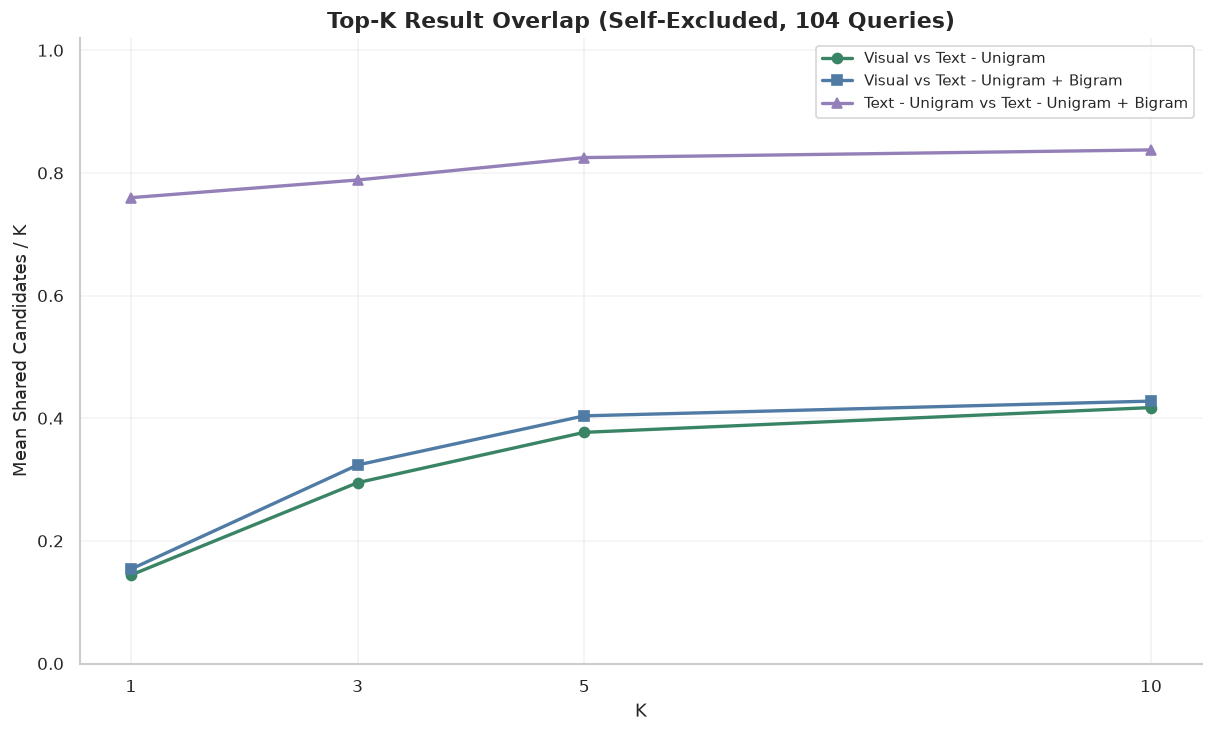

[SAVED] 128_cross_modality_topk_overlap.png

11. SAVING CROSS-MODALITY REPORTS
------------------------------------------------------------------------
[SAVED] 425_cross_modality_matrix_integrity.csv
[SAVED] 426_cross_modality_score_distribution.csv
[SAVED] 427_cross_modality_scale_comparison.csv
[SAVED] 428_cross_modality_pairwise_scores.csv
[SAVED] 429_cross_modality_pairwise_correlations.csv
[SAVED] 430_cross_modality_query_score_profiles.csv
[SAVED] 431_cross_modality_topk_overlap_detail.csv
[SAVED] 432_cross_modality_topk_overlap_summary.csv
[SAVED] 433_cross_modality_score_analysis_validation.csv
[SAVED] 434_cross_modality_score_analysis_summary.csv
[SAVED] 435_cross_modality_score_analysis_handoff.json

FINAL CROSS-MODALITY SCORE DISTRIBUTION SUMMARY


,Indicator,Result
0,Sample count,104
1,Matched unique pairs,5356
2,Within-class pairs,1041
3,Cross-class pairs,4315
4,Similarity matrices,3
5,Distribution summaries,9
6,Pairwise correlations,9
7,Query profiles,312
8,Top-K overlap records,1248
9,Top-K summary records,12


Score matrices: 3, unique pairs: 5356, Top-K comparisons: 1248
Technical checks: 26/26; failed: 0
Reports: 10 CSV + 1 JSON; Figures: 4
[INFO] Scores are not calibrated probabilities.
[INFO] Top-K overlap and pairwise correlations are descriptive, not held-out accuracy.
[INFO] No fusion weights or text configurations have been selected.

CROSS-MODALITY SCORE ANALYSIS COMPLETED SUCCESSFULLY

Next cell: Cell 13 - Weighted Score-Level Late Fusion


In [14]:
# ============================================================
# CELL 12 - CROSS-MODALITY SCORE DISTRIBUTION ANALYSIS
# ============================================================

print("MULTIMODAL FUSION - CROSS-MODALITY SCORE ANALYSIS")
print("=" * 72)

CROSS_MODALITY_SCORE_ANALYSIS_COMPLETED = False
CROSS_MODALITY_SCORE_ANALYSIS_READY = False


# ============================================================
# 1. VALIDATE PREVIOUS STAGES
# ============================================================

required_flags = {
    "MULTIMODAL_DATASET_VALIDATION_COMPLETED":
        MULTIMODAL_DATASET_VALIDATION_COMPLETED,

    "FUSION_CONFIGURATION_COMPLETED":
        FUSION_CONFIGURATION_COMPLETED,

    "VISUAL_SIMILARITY_CONVERSION_COMPLETED":
        VISUAL_SIMILARITY_CONVERSION_COMPLETED,

    "TEXT_COSINE_SIMILARITY_COMPLETED":
        TEXT_COSINE_SIMILARITY_COMPLETED,
}

for name, completed in required_flags.items():
    assert completed is True, (
        f"Run the preceding stage first: {name}"
    )

assert multimodal_validation_df["passed"].all()

assert visual_similarity_conversion_validation_df[
    "passed"
].all()

assert text_cosine_similarity_validation_df[
    "passed"
].all()


# ============================================================
# 2. ANALYSIS CONFIGURATION
# ============================================================

SCORE_ANALYSIS_TOLERANCE = 1e-10

SCORE_ANALYSIS_ZERO_THRESHOLD = 1e-12

SCORE_ANALYSIS_TOP_K = (1, 3, 5, 10)

SCORE_ANALYSIS_SCOPE = (
    "Full-gallery exploratory diagnostics; "
    "no hold-out evaluation"
)

score_analysis_validation_records = []
score_analysis_figure_paths = []


def score_analysis_check(group, name, condition):

    score_analysis_validation_records.append({
        "category": group,
        "validation_check": name,
        "passed": bool(condition),
        "status": (
            "Passed" if bool(condition) else "Failed"
        ),
    })


def save_score_analysis_figure(fig, filename):

    path = FUSION_FIGURES_DIR / filename

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    score_analysis_figure_paths.append(path)

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


def score_stats(values, score_name, pair_group):

    x = np.asarray(
        values,
        dtype=np.float64
    )

    assert x.ndim == 1
    assert x.size > 0
    assert np.isfinite(x).all()

    return {
        "modality": score_name,
        "pair_group": pair_group,
        "number_of_pairs": int(x.size),

        "minimum": float(x.min()),
        "mean": float(x.mean()),
        "median": float(np.median(x)),
        "maximum": float(x.max()),
        "std_population": float(x.std(ddof=0)),

        "q05": float(np.quantile(x, 0.05)),
        "q25": float(np.quantile(x, 0.25)),
        "q75": float(np.quantile(x, 0.75)),
        "q95": float(np.quantile(x, 0.95)),

        "iqr": float(
            np.quantile(x, 0.75)
            - np.quantile(x, 0.25)
        ),

        "zero_or_near_zero_percent": float(
            100 * np.mean(
                x <= SCORE_ANALYSIS_ZERO_THRESHOLD
            )
        ),

        "near_one_percent": float(
            100 * np.mean(
                x >= 1 - SCORE_ANALYSIS_TOLERANCE
            )
        ),
    }


# ============================================================
# 3. PREPARE THREE SIMILARITY MATRICES
# ============================================================

# Reuse existing results from Cells 10 and 11.
# No feature extraction, scaling, or refitting.

cross_modality_similarity_matrices = {

    "Visual": np.asarray(
        visual_similarity_matrix,
        dtype=np.float64
    ),

    "Text - Unigram": np.asarray(
        text_unigram_similarity_matrix,
        dtype=np.float64
    ),

    "Text - Unigram + Bigram": np.asarray(
        text_combined_similarity_matrix,
        dtype=np.float64
    ),
}

cross_modality_names = list(
    cross_modality_similarity_matrices
)

cross_modality_colors = {
    "Visual": "#398464",
    "Text - Unigram": "#507BA5",
    "Text - Unigram + Bigram": "#9480B8",
}

cross_modality_ids = np.asarray(
    multimodal_sample_ids,
    dtype=str
)

cross_modality_labels = np.asarray(
    multimodal_labels,
    dtype=str
)

n_samples = cross_modality_ids.size

assert n_samples == 104

assert np.array_equal(
    cross_modality_ids,
    visual_similarity_sample_ids
)

assert np.array_equal(
    cross_modality_ids,
    text_cosine_sample_ids
)

assert np.array_equal(
    cross_modality_labels,
    text_cosine_labels
)

print("\n1. SIMILARITY MATRIX CONFIGURATION")
print("-" * 72)

for name, matrix in (
    cross_modality_similarity_matrices.items()
):
    print(f"{name:26s}: {matrix.shape}")

print("Sample count:", n_samples)


# ============================================================
# 4. DEFINE UNIQUE SAMPLE PAIRS
# ============================================================

# Use the upper triangle only.
# Self-matches and mirrored pairs are excluded.

pair_i, pair_j = np.triu_indices(
    n_samples,
    k=1
)

within_mask = (
    cross_modality_labels[pair_i]
    == cross_modality_labels[pair_j]
)

assert len(pair_i) == 5356
assert within_mask.sum() == 1041
assert (~within_mask).sum() == 4315

score_analysis_check(
    "Alignment",
    "104 paired sample IDs and class labels preserved",
    n_samples == 104
    and np.array_equal(
        cross_modality_ids,
        text_cosine_sample_ids
    )
)

score_analysis_check(
    "Alignment",
    "5356 unique pairs, 1041 within and 4315 cross",
    len(pair_i) == 5356
    and int(within_mask.sum()) == 1041
)

print("\n2. MATCHED SAMPLE PAIRS")
print("-" * 72)

print("Unique pairs     :", len(pair_i))
print("Within-class     :", int(within_mask.sum()))
print("Cross-class      :", int((~within_mask).sum()))


# ============================================================
# 5. VALIDATE MATRICES AND EXTRACT MATCHED SCORES
# ============================================================

score_integrity_rows = []
paired_score_vectors = {}

for name, s in cross_modality_similarity_matrices.items():

    tests = {
        "shape_104x104":
            s.shape == (n_samples, n_samples),

        "finite":
            np.isfinite(s).all(),

        "range_0_to_1":
            np.all(
                (s >= -SCORE_ANALYSIS_TOLERANCE)
                &
                (s <= 1 + SCORE_ANALYSIS_TOLERANCE)
            ),

        "symmetric":
            np.allclose(
                s,
                s.T,
                atol=SCORE_ANALYSIS_TOLERANCE,
                rtol=0
            ),

        "diagonal_one":
            np.allclose(
                np.diag(s),
                1.0,
                atol=SCORE_ANALYSIS_TOLERANCE,
                rtol=0
            ),
    }

    for test_name, passed in tests.items():
        score_analysis_check(
            "Matrix - " + name,
            test_name,
            passed
        )

    assert all(tests.values()), (
        f"Invalid similarity matrix: {name}; {tests}"
    )

    paired_score_vectors[name] = s[
        pair_i,
        pair_j
    ]

    score_integrity_rows.append({
        "modality": name,
        "matrix_shape": str(s.shape),
        "dtype": str(s.dtype),

        "minimum_matrix_value": float(s.min()),
        "maximum_matrix_value": float(s.max()),

        "maximum_symmetry_error": float(
            np.max(np.abs(s - s.T))
        ),

        "maximum_diagonal_error": float(
            np.max(
                np.abs(np.diag(s) - 1)
            )
        ),

        **tests,
    })

cross_modality_matrix_integrity_df = pd.DataFrame(
    score_integrity_rows
)

print("\n3. SIMILARITY MATRIX INTEGRITY")
print("-" * 72)

display(cross_modality_matrix_integrity_df)


# ============================================================
# 6. SCORE DISTRIBUTION AND SCALE COMPARISON
# ============================================================

score_distribution_rows = []
score_scale_rows = []

for name, values in paired_score_vectors.items():

    within = values[within_mask]
    cross = values[~within_mask]

    for group_name, subset in [
        ("All Unique Pairs", values),
        ("Within Class", within),
        ("Cross Class", cross),
    ]:

        score_distribution_rows.append(
            score_stats(
                subset,
                name,
                group_name
            )
        )

    score_scale_rows.append({
        "modality": name,

        "mean_all_pairs": float(
            values.mean()
        ),

        "std_all_pairs": float(
            values.std(ddof=0)
        ),

        "iqr_all_pairs": float(
            np.quantile(values, 0.75)
            - np.quantile(values, 0.25)
        ),

        "q05_to_q95_range": float(
            np.quantile(values, 0.95)
            - np.quantile(values, 0.05)
        ),

        "within_class_mean": float(
            within.mean()
        ),

        "cross_class_mean": float(
            cross.mean()
        ),

        "within_minus_cross_mean_gap": float(
            within.mean() - cross.mean()
        ),

        "zero_or_near_zero_percent": float(
            100 * np.mean(
                values <= SCORE_ANALYSIS_ZERO_THRESHOLD
            )
        ),

        "near_one_percent": float(
            100 * np.mean(
                values >= 1 - SCORE_ANALYSIS_TOLERANCE
            )
        ),

        "score_calibration_completed": False,
    })


cross_modality_score_distribution_df = pd.DataFrame(
    score_distribution_rows
)

cross_modality_score_scale_df = pd.DataFrame(
    score_scale_rows
)

score_analysis_check(
    "Distribution",
    "Three modalities x three pair groups = nine summaries",
    len(cross_modality_score_distribution_df) == 9
)

score_analysis_check(
    "Distribution",
    "Three modality scale summaries",
    len(cross_modality_score_scale_df) == 3
)

print("\n4. SCORE SCALE COMPARISON")
print("-" * 72)

display(
    cross_modality_score_scale_df.round(6)
)

print("\n5. WITHIN / CROSS SCORE DISTRIBUTIONS")
print("-" * 72)

display(
    cross_modality_score_distribution_df.round(6)
)


# ============================================================
# 7. CREATE MATCHED PAIRWISE SCORE DATASET
# ============================================================

# Each row represents the same leaf pair across
# all three similarity matrices.

cross_modality_pairwise_scores_df = pd.DataFrame({

    "sample_id_i":
        cross_modality_ids[pair_i],

    "sample_id_j":
        cross_modality_ids[pair_j],

    "class_i":
        cross_modality_labels[pair_i],

    "class_j":
        cross_modality_labels[pair_j],

    "pair_type": np.where(
        within_mask,
        "Within Class",
        "Cross Class"
    ),

    "visual_similarity":
        paired_score_vectors["Visual"],

    "unigram_similarity":
        paired_score_vectors["Text - Unigram"],

    "unigram_bigram_similarity":
        paired_score_vectors["Text - Unigram + Bigram"],
})

cross_modality_pairwise_scores_df[
    "visual_minus_unigram"
] = (
    cross_modality_pairwise_scores_df[
        "visual_similarity"
    ]
    -
    cross_modality_pairwise_scores_df[
        "unigram_similarity"
    ]
)

cross_modality_pairwise_scores_df[
    "visual_minus_combined"
] = (
    cross_modality_pairwise_scores_df[
        "visual_similarity"
    ]
    -
    cross_modality_pairwise_scores_df[
        "unigram_bigram_similarity"
    ]
)

score_analysis_check(
    "Pair Matching",
    "Exactly 5356 distinct off-diagonal sample pairs",
    len(cross_modality_pairwise_scores_df) == 5356
    and not cross_modality_pairwise_scores_df[
        ["sample_id_i", "sample_id_j"]
    ].duplicated().any()
)

print("\n6. MATCHED PAIRWISE SCORES")
print("-" * 72)

display(
    cross_modality_pairwise_scores_df.head(10).round(6)
)


# ============================================================
# 8. CROSS-MODALITY CORRELATION ANALYSIS
# ============================================================

# These correlations are descriptive.
# The 5356 pair scores are not statistically
# independent observations.
#
# Therefore, inferential p-values are not reported.

modality_pairs = [
    ("Visual", "Text - Unigram"),

    ("Visual", "Text - Unigram + Bigram"),

    ("Text - Unigram", "Text - Unigram + Bigram"),
]

correlation_rows = []

for a, b in modality_pairs:

    comparison_groups = [
        (
            "All Unique Pairs",
            np.ones(len(pair_i), dtype=bool)
        ),

        ("Within Class", within_mask),

        ("Cross Class", ~within_mask),
    ]

    for group_name, mask in comparison_groups:

        x = paired_score_vectors[a][mask]
        y = paired_score_vectors[b][mask]

        usable = (
            np.ptp(x) > SCORE_ANALYSIS_ZERO_THRESHOLD
            and
            np.ptp(y) > SCORE_ANALYSIS_ZERO_THRESHOLD
        )

        pearson_r = (
            float(pearsonr(x, y).statistic)
            if usable else np.nan
        )

        spearman_r = (
            float(spearmanr(x, y).statistic)
            if usable else np.nan
        )

        correlation_rows.append({
            "modality_a": a,
            "modality_b": b,
            "pair_group": group_name,

            "number_of_pairs": int(
                mask.sum()
            ),

            "pearson_r_descriptive": pearson_r,

            "spearman_r_descriptive": spearman_r,

            "mean_absolute_score_difference": float(
                np.mean(np.abs(x - y))
            ),

            "median_absolute_score_difference": float(
                np.median(np.abs(x - y))
            ),

            "correlation_defined": bool(usable),

            "inferential_p_value_reported": False,
        })


cross_modality_pairwise_correlations_df = pd.DataFrame(
    correlation_rows
)

score_analysis_check(
    "Cross-Modal Comparison",
    "Three modality pairs x three strata",
    len(cross_modality_pairwise_correlations_df) == 9
)

print("\n7. CROSS-MODALITY SCORE CORRELATIONS")
print("-" * 72)

display(
    cross_modality_pairwise_correlations_df.round(5)
)


# ============================================================
# 9. PER-QUERY SCORE DISTRIBUTION PROFILES
# ============================================================

query_profile_rows = []

cross_modality_ranked_indices = {
    name: []
    for name in cross_modality_names
}

for name, s in (
    cross_modality_similarity_matrices.items()
):

    for query_idx in range(n_samples):

        candidates = np.arange(n_samples)

        # Exclude the query sample itself.

        candidates = candidates[
            candidates != query_idx
        ]

        scores = s[
            query_idx,
            candidates
        ]

        same = (
            cross_modality_labels[candidates]
            ==
            cross_modality_labels[query_idx]
        )

        # Sort by score descending.
        # Resolve ties by sample_id ascending.

        ranking_order = np.lexsort((
            cross_modality_ids[candidates],
            -scores
        ))

        ranked = candidates[
            ranking_order
        ]

        cross_modality_ranked_indices[
            name
        ].append(ranked)

        query_profile_rows.append({
            "modality": name,

            "query_sample_id":
                cross_modality_ids[query_idx],

            "query_class":
                cross_modality_labels[query_idx],

            "candidate_count": len(candidates),

            "mean_score_excluding_self": float(
                scores.mean()
            ),

            "std_score_excluding_self": float(
                scores.std(ddof=0)
            ),

            "q10_score": float(
                np.quantile(scores, 0.10)
            ),

            "q90_score": float(
                np.quantile(scores, 0.90)
            ),

            "nearest_sample_id":
                cross_modality_ids[ranked[0]],

            "nearest_score": float(
                s[query_idx, ranked[0]]
            ),

            "nearest_same_class": bool(
                cross_modality_labels[ranked[0]]
                ==
                cross_modality_labels[query_idx]
            ),

            "within_class_mean_score": float(
                scores[same].mean()
            ),

            "cross_class_mean_score": float(
                scores[~same].mean()
            ),

            "within_minus_cross_query_gap": float(
                scores[same].mean()
                -
                scores[~same].mean()
            ),

            "zero_or_near_zero_candidate_percent": float(
                100 * np.mean(
                    scores <= SCORE_ANALYSIS_ZERO_THRESHOLD
                )
            ),
        })


cross_modality_query_profiles_df = pd.DataFrame(
    query_profile_rows
)

score_analysis_check(
    "Query Profiles",
    "Three score profiles for each of 104 queries",
    len(cross_modality_query_profiles_df) == 312
)

score_analysis_check(
    "Query Profiles",
    "Every profile excludes its own sample",
    (
        cross_modality_query_profiles_df[
            "candidate_count"
        ] == 103
    ).all()
)

print("\n8. PER-QUERY SCORE PROFILES")
print("-" * 72)

display(
    cross_modality_query_profiles_df.head(10).round(6)
)


# ============================================================
# 10. TOP-K RANKING OVERLAP ANALYSIS
# ============================================================

# We measure how many retrieved candidates overlap
# between two modalities for the SAME query.
#
# This is NOT Precision@K, Recall@K, or accuracy.

k_values = [
    int(k)
    for k in FUSION_TOP_K_VALUES
]

assert k_values == list(
    SCORE_ANALYSIS_TOP_K
)

topk_rows = []

for a, b in modality_pairs:

    for q in range(n_samples):

        ordered_a = (
            cross_modality_ranked_indices[a][q]
        )

        ordered_b = (
            cross_modality_ranked_indices[b][q]
        )

        for k in k_values:

            set_a = set(
                ordered_a[:k].tolist()
            )

            set_b = set(
                ordered_b[:k].tolist()
            )

            overlap = len(
                set_a & set_b
            )

            topk_rows.append({
                "modality_a": a,
                "modality_b": b,

                "query_sample_id":
                    cross_modality_ids[q],

                "query_class":
                    cross_modality_labels[q],

                "k": k,

                "overlap_count": overlap,

                "overlap_at_k": float(
                    overlap / k
                ),

                "jaccard_at_k": float(
                    overlap / (2 * k - overlap)
                ),
            })


cross_modality_topk_overlap_df = pd.DataFrame(
    topk_rows
)

cross_modality_topk_summary_df = (
    cross_modality_topk_overlap_df

    .groupby(
        [
            "modality_a",
            "modality_b",
            "k"
        ],
        as_index=False
    )

    .agg(
        number_of_queries=(
            "query_sample_id",
            "count"
        ),

        mean_overlap_at_k=(
            "overlap_at_k",
            "mean"
        ),

        std_overlap_at_k=(
            "overlap_at_k",
            "std"
        ),

        median_overlap_at_k=(
            "overlap_at_k",
            "median"
        ),

        mean_jaccard_at_k=(
            "jaccard_at_k",
            "mean"
        )
    )
)

score_analysis_check(
    "Ranking",
    "Three comparisons x 104 queries x four K values",
    len(cross_modality_topk_overlap_df) == 1248
)

score_analysis_check(
    "Ranking",
    "Twelve summarized modality pair / K combinations",
    len(cross_modality_topk_summary_df) == 12
)

score_analysis_check(
    "Ranking",
    "Top-K overlaps stay in [0,1]",
    cross_modality_topk_overlap_df[
        "overlap_at_k"
    ].between(0, 1).all()
)

print("\n9. TOP-K RANKING OVERLAP")
print("-" * 72)

display(
    cross_modality_topk_summary_df.round(4)
)

print(
    "[INFO] Ranking overlap is not retrieval accuracy."
)


# ============================================================
# 11. FINAL TECHNICAL VALIDATION
# ============================================================

score_analysis_validation_df = pd.DataFrame(
    score_analysis_validation_records
)

score_analysis_passed = int(
    score_analysis_validation_df[
        "passed"
    ].sum()
)

score_analysis_failed = (
    len(score_analysis_validation_df)
    -
    score_analysis_passed
)

# Save diagnostics before stopping on failure.

score_analysis_validation_df.to_csv(
    METRICS_DIR
    / "433_cross_modality_score_analysis_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n10. TECHNICAL VALIDATION")
print("-" * 72)

display(score_analysis_validation_df)

assert score_analysis_validation_df[
    "passed"
].all(), (
    score_analysis_validation_df.loc[
        ~score_analysis_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All cross-modality checks passed.")


# ============================================================
# 12. FIGURE 125 - SCORE DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5.5),
    constrained_layout=True
)

bins = np.linspace(0, 1, 41)

for name in cross_modality_names:

    values = paired_score_vectors[name]

    # Histogram.

    axes[0].hist(
        values,
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2,
        label=name,
        color=cross_modality_colors[name]
    )

    # Empirical cumulative distribution.

    sorted_values = np.sort(values)

    cumulative = (
        np.arange(1, len(values) + 1)
        / len(values)
    )

    axes[1].step(
        sorted_values,
        cumulative,
        where="post",
        linewidth=2,
        label=name,
        color=cross_modality_colors[name]
    )

axes[0].set_title(
    "Off-Diagonal Similarity Distribution"
)

axes[0].set_xlabel("Similarity Score")
axes[0].set_ylabel("Probability Density")
axes[0].set_xlim(0, 1)

axes[1].set_title(
    "Empirical Cumulative Distribution"
)

axes[1].set_xlabel("Similarity Score")
axes[1].set_ylabel("Cumulative Proportion")

axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.02)

for ax in axes:
    ax.legend(fontsize=9)

fig.suptitle(
    "Three Score Scales - 5,356 Matched Sample Pairs\n"
    "Full-Gallery Descriptive Analysis",
    fontweight="bold",
    fontsize=15
)

save_score_analysis_figure(
    fig,
    "125_cross_modality_score_distributions.png"
)


# ============================================================
# 13. FIGURE 126 - WITHIN VS CROSS CLASS DISTRIBUTION
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5.5),
    constrained_layout=True
)

for ax, name in zip(
    axes,
    cross_modality_names
):

    scores = paired_score_vectors[name]

    within_scores = scores[
        within_mask
    ]

    cross_scores = scores[
        ~within_mask
    ]

    ax.hist(
        within_scores,
        bins=bins,
        density=True,
        alpha=0.60,
        color="#398464",
        label="Within Class"
    )

    ax.hist(
        cross_scores,
        bins=bins,
        density=True,
        alpha=0.45,
        color="#658AB2",
        label="Cross Class"
    )

    ax.axvline(
        within_scores.mean(),
        color="#21533E",
        linestyle="--",
        linewidth=1.8
    )

    ax.axvline(
        cross_scores.mean(),
        color="#345C83",
        linestyle="--",
        linewidth=1.8
    )

    ax.set_title(name)
    ax.set_xlabel("Similarity Score")
    ax.set_ylabel("Probability Density")
    ax.set_xlim(0, 1)
    ax.legend(fontsize=8)

fig.suptitle(
    "Within-Class and Cross-Class Score Distributions\n"
    "Same 1,041 / 4,315 Pairs for Each Modality",
    fontweight="bold",
    fontsize=15
)

save_score_analysis_figure(
    fig,
    "126_cross_modality_within_cross_distributions.png"
)


# ============================================================
# 14. FIGURE 127 - PAIRED SCORE SCATTER
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    constrained_layout=True
)

for ax, text_name in zip(
    axes,
    cross_modality_names[1:]
):

    image_scores = paired_score_vectors[
        "Visual"
    ]

    text_scores = paired_score_vectors[
        text_name
    ]

    for mask, label, color in [
        (~within_mask, "Cross Class", "#658AB2"),
        (within_mask, "Within Class", "#398464"),
    ]:

        ax.scatter(
            image_scores[mask],
            text_scores[mask],
            s=8,
            alpha=0.24,
            c=color,
            label=label,
            rasterized=True
        )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1,
        color="gray",
        label="Equal Numerical Scores"
    )

    ax.set_title(
        "Visual vs " + text_name
    )

    ax.set_xlabel("Visual Similarity")
    ax.set_ylabel("Text Cosine Similarity")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.legend(fontsize=8)

fig.suptitle(
    "Scores for the Same Unordered Sample Pairs\n"
    "A Shared [0,1] Range Does Not Mean Calibration",
    fontweight="bold",
    fontsize=15
)

save_score_analysis_figure(
    fig,
    "127_cross_modality_paired_score_scatter.png"
)


# ============================================================
# 15. FIGURE 128 - TOP-K RANKING OVERLAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6),
    constrained_layout=True
)

for idx, (a, b) in enumerate(
    modality_pairs
):

    subset = (
        cross_modality_topk_summary_df.loc[
            (
                cross_modality_topk_summary_df[
                    "modality_a"
                ] == a
            )
            &
            (
                cross_modality_topk_summary_df[
                    "modality_b"
                ] == b
            )
        ]
        .sort_values("k")
    )

    ax.plot(
        subset["k"],
        subset["mean_overlap_at_k"],
        marker=["o", "s", "^"][idx],
        linewidth=2,
        color=[
            "#398464",
            "#507BA5",
            "#9480B8"
        ][idx],
        label=f"{a} vs {b}"
    )

ax.set_title(
    "Top-K Result Overlap (Self-Excluded, 104 Queries)"
)

ax.set_xlabel("K")

ax.set_ylabel(
    "Mean Shared Candidates / K"
)

ax.set_xticks(k_values)
ax.set_ylim(0, 1.02)

ax.grid(
    axis="y",
    alpha=0.2
)

ax.legend(fontsize=9)

save_score_analysis_figure(
    fig,
    "128_cross_modality_topk_overlap.png"
)


# ============================================================
# 16. CREATE FINAL ANALYSIS SUMMARY
# ============================================================

cross_modality_score_analysis_summary_df = pd.DataFrame([
    ("Sample count", n_samples),

    ("Matched unique pairs", len(pair_i)),

    ("Within-class pairs", int(within_mask.sum())),

    ("Cross-class pairs", int((~within_mask).sum())),

    ("Similarity matrices",
     len(cross_modality_similarity_matrices)),

    ("Distribution summaries",
     len(cross_modality_score_distribution_df)),

    ("Pairwise correlations",
     len(cross_modality_pairwise_correlations_df)),

    ("Query profiles",
     len(cross_modality_query_profiles_df)),

    ("Top-K overlap records",
     len(cross_modality_topk_overlap_df)),

    ("Top-K summary records",
     len(cross_modality_topk_summary_df)),

    ("Technical checks",
     len(score_analysis_validation_df)),

    ("Passed checks",
     score_analysis_passed),

    ("Failed checks",
     score_analysis_failed),

    ("Generated figures",
     len(score_analysis_figure_paths)),

    ("Score calibration performed", False),

    ("Late fusion performed", False),

    ("Final fusion weight selected", False),

    ("Independent retrieval evaluation", False),

    ("Scope", SCORE_ANALYSIS_SCOPE),

], columns=["Indicator", "Result"])


# ============================================================
# 17. SAVE ANALYSIS REPORTS
# ============================================================

score_analysis_reports = {

    "425_cross_modality_matrix_integrity.csv":
        cross_modality_matrix_integrity_df,

    "426_cross_modality_score_distribution.csv":
        cross_modality_score_distribution_df,

    "427_cross_modality_scale_comparison.csv":
        cross_modality_score_scale_df,

    "428_cross_modality_pairwise_scores.csv":
        cross_modality_pairwise_scores_df,

    "429_cross_modality_pairwise_correlations.csv":
        cross_modality_pairwise_correlations_df,

    "430_cross_modality_query_score_profiles.csv":
        cross_modality_query_profiles_df,

    "431_cross_modality_topk_overlap_detail.csv":
        cross_modality_topk_overlap_df,

    "432_cross_modality_topk_overlap_summary.csv":
        cross_modality_topk_summary_df,

    "433_cross_modality_score_analysis_validation.csv":
        score_analysis_validation_df,

    "434_cross_modality_score_analysis_summary.csv":
        cross_modality_score_analysis_summary_df,
}

print("\n11. SAVING CROSS-MODALITY REPORTS")
print("-" * 72)

for filename, dataframe in score_analysis_reports.items():

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print("[SAVED]", filename)


# ============================================================
# 18. SAVE CONFIGURATION HANDOFF
# ============================================================

cross_modality_score_handoff = {

    "notebook":
        "05_multimodal_fusion.ipynb",

    "cell": 12,

    "sample_count": int(n_samples),

    "alignment_signature":
        multimodal_alignment_signature,

    "modalities":
        cross_modality_names,

    "unique_pairs":
        int(len(pair_i)),

    "top_k_values":
        k_values,

    "all_diagonals_excluded_from_statistics":
        True,

    "tie_breaker":
        "similarity_descending_then_sample_id_ascending",

    "score_calibration_performed":
        False,

    "fusion_weight_selected":
        False,

    "independent_evaluation_completed":
        False,

    "scope":
        SCORE_ANALYSIS_SCOPE,
}

CROSS_MODALITY_HANDOFF_PATH = (
    METRICS_DIR
    / "435_cross_modality_score_analysis_handoff.json"
)

with open(
    CROSS_MODALITY_HANDOFF_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        cross_modality_score_handoff,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False
    )

print(
    "[SAVED]",
    CROSS_MODALITY_HANDOFF_PATH.name
)


# ============================================================
# 19. FINAL COMPLETION CHECKS
# ============================================================

assert score_analysis_validation_df[
    "passed"
].all()

assert score_analysis_failed == 0

assert len(score_analysis_figure_paths) == 4

assert all(
    path.is_file() and path.stat().st_size > 0
    for path in score_analysis_figure_paths
)

assert all(
    (METRICS_DIR / filename).is_file()
    and
    (METRICS_DIR / filename).stat().st_size > 0

    for filename in score_analysis_reports
)

assert CROSS_MODALITY_HANDOFF_PATH.is_file()

CROSS_MODALITY_SCORE_ANALYSIS_COMPLETED = True
CROSS_MODALITY_SCORE_ANALYSIS_READY = True


# ============================================================
# 20. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 72)

print("FINAL CROSS-MODALITY SCORE DISTRIBUTION SUMMARY")

print("=" * 72)

display(
    cross_modality_score_analysis_summary_df
)

print(
    f"Score matrices: 3, "
    f"unique pairs: {len(pair_i)}, "
    f"Top-K comparisons: {len(cross_modality_topk_overlap_df)}"
)

print(
    f"Technical checks: "
    f"{score_analysis_passed}/"
    f"{len(score_analysis_validation_df)}; "
    f"failed: {score_analysis_failed}"
)

print(
    "Reports: 10 CSV + 1 JSON; Figures:",
    len(score_analysis_figure_paths)
)

print(
    "[INFO] Scores are not calibrated probabilities."
)

print(
    "[INFO] Top-K overlap and pairwise correlations "
    "are descriptive, not held-out accuracy."
)

print(
    "[INFO] No fusion weights or text configurations "
    "have been selected."
)

print(
    "\nCROSS-MODALITY SCORE ANALYSIS "
    "COMPLETED SUCCESSFULLY"
)

print(
    "\nNext cell: Cell 13 - "
    "Weighted Score-Level Late Fusion"
)

MULTIMODAL FUSION - WEIGHTED SCORE-LEVEL LATE FUSION
[PASS] All previous stages validated.

1. FUSION CONFIGURATION
------------------------------------------------------------------------
Method           : Score-Level Late Fusion
Strategy         : Weighted Sum
Visual weight    : 0.5
Text weight      : 0.5
Text configurations: ['Unigram', 'Unigram + Bigram']
Analysis scope   : Full-Gallery Exploratory Development

2. INPUT SIMILARITY MATRICES
------------------------------------------------------------------------
Visual similarity: (104, 104)
Text Unigram: (104, 104)
Text Unigram + Bigram: (104, 104)

FUSION CONFIGURATION: Unigram

FUSION RESULTS
------------------------------------------------------------------------
Matrix shape : (104, 104)
Within mean  : 0.445397
Cross mean   : 0.305023
Mean gap     : 0.140374
Formula error: 0.000e+00
Self-excluded nearest-neighbor agreement: 87.50%

FUSION CONFIGURATION: Unigram + Bigram

FUSION RESULTS
-----------------------------------------

,configuration,matrix_shape,visual_weight,text_weight,effective_mode,unique_pair_count,within_class_pairs,cross_class_pairs,minimum_off_diagonal_similarity,maximum_off_diagonal_similarity,mean_off_diagonal_similarity,std_off_diagonal_similarity,mean_within_class_similarity,mean_cross_class_similarity,within_minus_cross_mean_gap,nearest_neighbor_class_agreement_percent,maximum_formula_error,maximum_symmetry_error,maximum_diagonal_error,calculation_time_ms,score_calibration_completed,independent_evaluation_completed
0,Unigram,"(104, 104)",0.5,0.5,Multimodal,5356,1041,4315,0.163515,0.775684,0.332306,0.103131,0.445397,0.305023,0.140374,87.500000,0.0,0.0,0.0,0.1309,False,False
1,Unigram + Bigram,"(104, 104)",0.5,0.5,Multimodal,5356,1041,4315,0.123107,0.768388,0.274652,0.095345,0.387700,0.247379,0.140322,93.269231,0.0,0.0,0.0,0.0971,False,False



5. REPRESENTATIVE TOP-5 RETRIEVAL
------------------------------------------------------------------------


,configuration,query_sample_id,query_class,rank,reference_sample_id,reference_class,visual_similarity,text_similarity,fusion_similarity,same_class,self_match_excluded
0,Unigram,leaf_165d2f32c7fda707,Mangkok,1,leaf_12439b9ebf0eb8d3,Mangkok,0.410040,0.801573,0.605806,True,True
1,Unigram,leaf_165d2f32c7fda707,Mangkok,2,leaf_4de65b11758965f6,Mangkok,0.415129,0.716764,0.565946,True,True
2,Unigram,leaf_165d2f32c7fda707,Mangkok,3,leaf_23b789945271fb92,Mangkok,0.301963,0.816337,0.559150,True,True
3,Unigram,leaf_165d2f32c7fda707,Mangkok,4,leaf_663a651dd51f9c94,Mangkok,0.348048,0.734944,0.541496,True,True
4,Unigram,leaf_165d2f32c7fda707,Mangkok,5,leaf_a6da65cb0493ceef,Mangkok,0.448113,0.622668,0.535390,True,True
5,Unigram,leaf_c29e2560b188fb2c,Salam,1,leaf_1ebaf9512209a61f,Salam,0.352536,0.770880,0.561708,True,True
6,Unigram,leaf_c29e2560b188fb2c,Salam,2,leaf_ac463b36b6e61052,Salam,0.316570,0.598149,0.457360,True,True
7,Unigram,leaf_c29e2560b188fb2c,Salam,3,leaf_0a8999109a734f1d,Salam,0.323049,0.570881,0.446965,True,True
8,Unigram,leaf_c29e2560b188fb2c,Salam,4,leaf_a7704c0316865cd7,Salam,0.304387,0.544515,0.424451,True,True
9,Unigram,leaf_c29e2560b188fb2c,Salam,5,leaf_68b0c81b496519cd,Salam,0.349500,0.498347,0.423924,True,True



6. MATHEMATICAL VERIFICATION
------------------------------------------------------------------------


,mathematical_test,passed,status
0,Unigram: weighted-sum formula,True,Passed
1,Unigram: convex score bounds,True,Passed
2,Unigram: alpha=0 gives text similarity,True,Passed
3,Unigram: alpha=1 gives visual similarity,True,Passed
4,Unigram: effective weights sum to one,True,Passed
5,Unigram: mean fusion score identity,True,Passed
6,Unigram + Bigram: weighted-sum formula,True,Passed
7,Unigram + Bigram: convex score bounds,True,Passed
8,Unigram + Bigram: alpha=0 gives text similarity,True,Passed
9,Unigram + Bigram: alpha=1 gives visual similarity,True,Passed



7. FUSION VALIDATION
------------------------------------------------------------------------


,category,validation_check,passed,status
0,Input Matrices,Visual matrix properties valid,True,Passed
1,Input Matrices,Unigram matrix properties valid,True,Passed
2,Input Matrices,Unigram + Bigram matrix properties valid,True,Passed
3,Sample Alignment,All 104 samples and labels aligned,True,Passed
4,Pair Inventory,5356 matched unique off-diagonal pairs,True,Passed
5,Pair Inventory,1041 within and 4315 cross-class pairs,True,Passed
6,Unigram,shape_104x104,True,Passed
7,Unigram,float64_dtype,True,Passed
8,Unigram,finite_scores,True,Passed
9,Unigram,scores_in_0_1,True,Passed


[PASS] All default fusion checks passed.


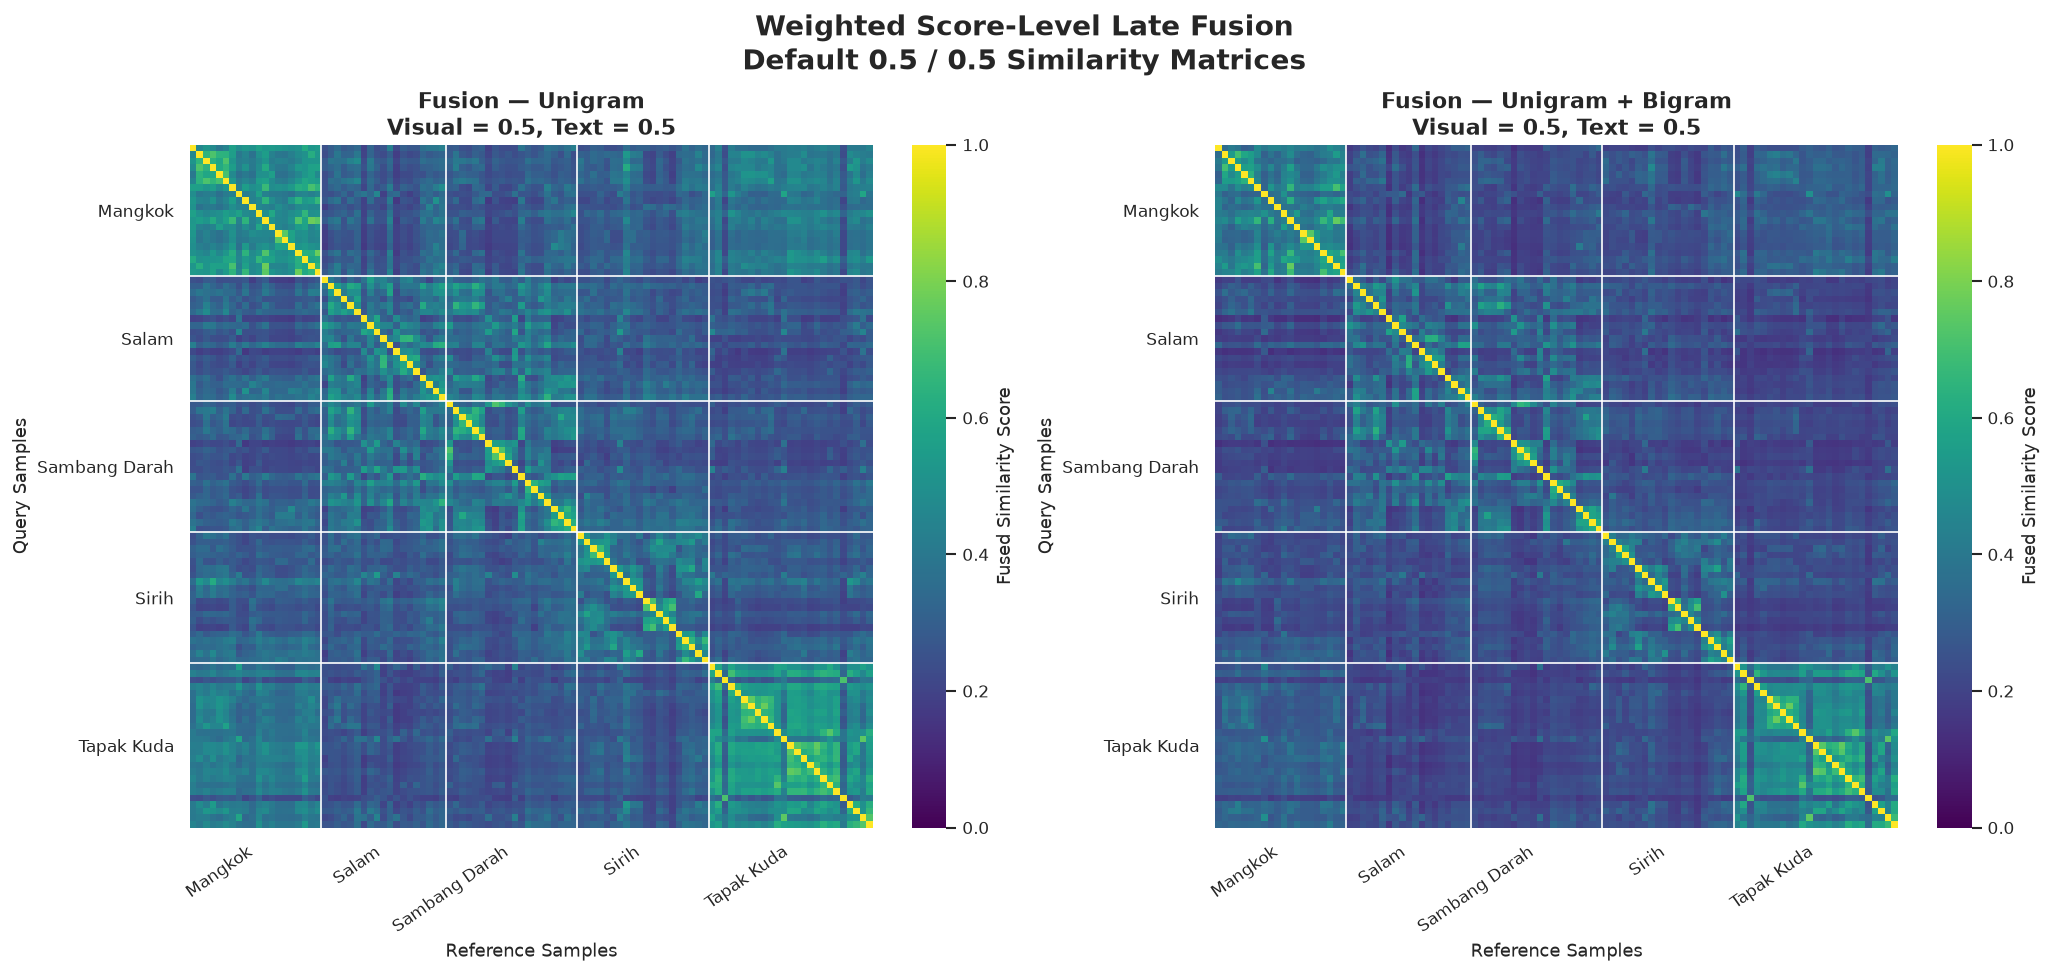

[SAVED] 129_default_fusion_similarity_matrices.png


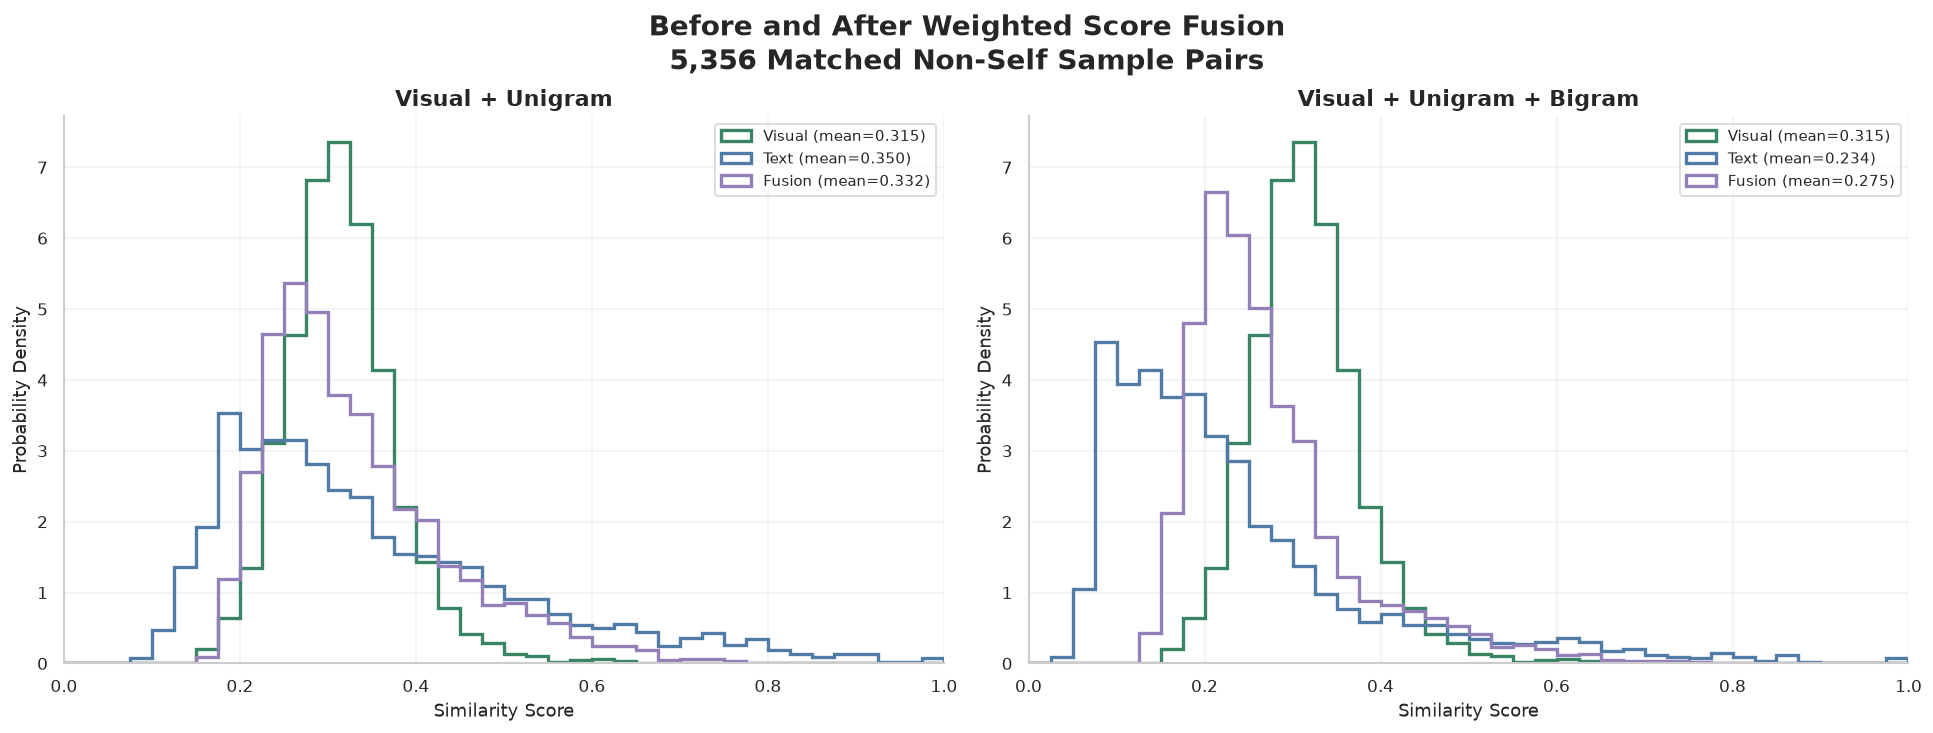

[SAVED] 130_default_fusion_score_distributions.png

8. FINAL FUSION SUMMARY
------------------------------------------------------------------------


,Indicator,Result
0,Total multimodal samples,104
1,Number of plant classes,5
2,Fusion method,Score-Level Late Fusion
3,Fusion strategy,Weighted Sum
4,Default visual weight,0.5
5,Default text weight,0.5
6,Text configurations,2
7,Fusion matrices generated,2
8,Fusion matrix shape,"(104, 104)"
9,Unique pairs per configuration,5356



9. SAVING DEFAULT FUSION REPORTS
------------------------------------------------------------------------
[SAVED] 436_default_fusion_matrix_summary.csv
[SAVED] 437_default_fusion_pairwise_scores.csv
[SAVED] 438_default_fusion_class_pair_summary.csv
[SAVED] 439_default_fusion_retrieval_preview.csv
[SAVED] 440_default_fusion_mathematical_validation.csv
[SAVED] 441_default_fusion_validation.csv
[SAVED] 442_default_fusion_summary.csv
[SAVED] 443_default_fusion_handoff.json

FINAL WEIGHTED SCORE-LEVEL LATE FUSION SUMMARY

FUSION CONFIGURATION
------------------------------------------------------------------------
Fusion method    : Score-Level Late Fusion
Fusion strategy  : Weighted Sum
Visual weight    : 0.5
Text weight      : 0.5

FUSION MATRICES
------------------------------------------------------------------------
Unigram fusion   : (104, 104)
Combined fusion  : (104, 104)

PAIR STATISTICS
------------------------------------------------------------------------
Unique pairs per conf

,configuration,mean_within_class_similarity,mean_cross_class_similarity,within_minus_cross_mean_gap,nearest_neighbor_class_agreement_percent
0,Unigram,0.445397,0.305023,0.140374,87.500000
1,Unigram + Bigram,0.387700,0.247379,0.140322,93.269231



VALIDATION RESULTS
------------------------------------------------------------------------
Mathematical tests : 12/12
Technical checks  : 34/34
Failed checks     : 0
Generated reports : 7
Generated figures : 2
Configuration JSON: 1

[PASS] Unigram fusion matrix generated.
[PASS] Unigram + Bigram fusion matrix generated.
[PASS] Weighted-sum formula verified.
[PASS] Alpha endpoint behavior verified.
[PASS] Matrix symmetry and diagonal validated.
[PASS] Original sample order preserved.
[PASS] Self-match excluded from ranking diagnostics.
[PASS] Reports and visualizations saved.

[INFO] Fusion uses provisional equal weights.
[INFO] No optimal weight has been selected.
[INFO] Results are exploratory, not held-out accuracy.
[INFO] No input similarity matrix was modified.

WEIGHTED SCORE-LEVEL LATE FUSION COMPLETED SUCCESSFULLY

Next cell: Cell 14 - Fusion Weight Sensitivity Analysis


In [15]:
# ============================================================
# CELL 13 - WEIGHTED SCORE-LEVEL LATE FUSION
# ============================================================

print("MULTIMODAL FUSION - WEIGHTED SCORE-LEVEL LATE FUSION")
print("=" * 72)

WEIGHTED_LATE_FUSION_COMPLETED = False
MULTIMODAL_FUSION_COMPLETED = False


# ============================================================
# 1. VALIDATE PREVIOUS STAGES
# ============================================================

required_stages = {
    "MULTIMODAL_DATASET_VALIDATION_COMPLETED":
        MULTIMODAL_DATASET_VALIDATION_COMPLETED,

    "FUSION_CONFIGURATION_COMPLETED":
        FUSION_CONFIGURATION_COMPLETED,

    "VISUAL_SIMILARITY_CONVERSION_COMPLETED":
        VISUAL_SIMILARITY_CONVERSION_COMPLETED,

    "TEXT_COSINE_SIMILARITY_COMPLETED":
        TEXT_COSINE_SIMILARITY_COMPLETED,

    "CROSS_MODALITY_SCORE_ANALYSIS_COMPLETED":
        CROSS_MODALITY_SCORE_ANALYSIS_COMPLETED,
}

for stage_name, completed in required_stages.items():
    assert completed is True, (
        f"Previous stage not completed: {stage_name}"
    )

assert multimodal_validation_df["passed"].all()
assert fusion_configuration_validation_df["passed"].all()
assert score_analysis_validation_df["passed"].all()

assert FUSION_METHOD == "Score-Level Late Fusion"
assert FUSION_STRATEGY == "Weighted Sum"

print("[PASS] All previous stages validated.")


# ============================================================
# 2. FUSION PARAMETERS
# ============================================================

FUSION13_ALPHA = float(
    FUSION_DEFAULT_VISUAL_WEIGHT
)

FUSION13_BETA = float(
    1.0 - FUSION13_ALPHA
)

FUSION13_TOLERANCE = 1e-10

FUSION13_SAMPLE_COUNT = 104

FUSION13_TOP_K_PREVIEW = 5

FUSION13_TEXT_CONFIGURATIONS = [
    "Unigram",
    "Unigram + Bigram"
]

FUSION13_SCOPE = (
    "Full-Gallery Exploratory Development"
)

assert np.isclose(FUSION13_ALPHA, 0.5)
assert np.isclose(FUSION13_BETA, 0.5)
assert np.isclose(FUSION13_ALPHA + FUSION13_BETA, 1.0)

fusion13_validation_records = []
fusion13_math_records = []
fusion13_figure_paths = []


def register_fusion13_check(category, name, passed):

    fusion13_validation_records.append({
        "category": category,
        "validation_check": name,
        "passed": bool(passed),
        "status": "Passed" if passed else "Failed"
    })


def register_fusion13_math(name, passed):

    fusion13_math_records.append({
        "mathematical_test": name,
        "passed": bool(passed),
        "status": "Passed" if passed else "Failed"
    })


def save_fusion13_figure(fig, filename):

    output_path = FUSION_FIGURES_DIR / filename

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    fusion13_figure_paths.append(output_path)

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


print("\n1. FUSION CONFIGURATION")
print("-" * 72)

print("Method           :", FUSION_METHOD)
print("Strategy         :", FUSION_STRATEGY)
print("Visual weight    :", FUSION13_ALPHA)
print("Text weight      :", FUSION13_BETA)
print("Text configurations:", FUSION13_TEXT_CONFIGURATIONS)
print("Analysis scope   :", FUSION13_SCOPE)


# ============================================================
# 3. PREPARE INPUT SIMILARITY MATRICES
# ============================================================

# Use the matrices calculated in Cells 10 and 11.
# No feature concatenation or normalization is applied.

fusion13_visual_matrix = np.asarray(
    visual_similarity_matrix,
    dtype=np.float64
)

fusion13_text_matrices = {
    "Unigram": np.asarray(
        text_unigram_similarity_matrix,
        dtype=np.float64
    ),

    "Unigram + Bigram": np.asarray(
        text_combined_similarity_matrix,
        dtype=np.float64
    )
}

fusion13_sample_ids = np.asarray(
    multimodal_sample_ids,
    dtype=str
)

fusion13_labels = np.asarray(
    multimodal_labels,
    dtype=str
)

fusion13_n_samples = len(fusion13_sample_ids)

assert fusion13_n_samples == FUSION13_SAMPLE_COUNT

assert fusion13_visual_matrix.shape == (104, 104)

assert all(
    matrix.shape == (104, 104)
    for matrix in fusion13_text_matrices.values()
)

assert np.array_equal(
    fusion13_sample_ids,
    text_sample_ids
)

assert np.array_equal(
    fusion13_sample_ids,
    visual_similarity_sample_ids
)

assert np.array_equal(
    fusion13_labels,
    text_labels
)

# Keep copies only to verify that fusion did not
# mutate the original input matrices.

fusion13_input_snapshots = {
    "Visual": fusion13_visual_matrix.copy(),

    **{
        name: matrix.copy()
        for name, matrix in fusion13_text_matrices.items()
    }
}

for name, matrix in {
    "Visual": fusion13_visual_matrix,
    **fusion13_text_matrices
}.items():

    valid = (
        matrix.shape == (104, 104)
        and np.isfinite(matrix).all()
        and np.all(
            matrix >= -FUSION13_TOLERANCE
        )
        and np.all(
            matrix <= 1 + FUSION13_TOLERANCE
        )
        and np.allclose(
            matrix,
            matrix.T,
            atol=FUSION13_TOLERANCE,
            rtol=0
        )
        and np.allclose(
            np.diag(matrix),
            1.0,
            atol=FUSION13_TOLERANCE,
            rtol=0
        )
    )

    register_fusion13_check(
        "Input Matrices",
        f"{name} matrix properties valid",
        valid
    )

assert all(
    record["passed"]
    for record in fusion13_validation_records
)

print("\n2. INPUT SIMILARITY MATRICES")
print("-" * 72)

print("Visual similarity:", fusion13_visual_matrix.shape)

for name, matrix in fusion13_text_matrices.items():
    print(f"Text {name}: {matrix.shape}")


# ============================================================
# 4. DEFINE MATCHED SAMPLE PAIRS
# ============================================================

fusion13_pair_i, fusion13_pair_j = np.triu_indices(
    fusion13_n_samples,
    k=1
)

fusion13_within_mask = (
    fusion13_labels[fusion13_pair_i]
    ==
    fusion13_labels[fusion13_pair_j]
)

fusion13_n_pairs = len(fusion13_pair_i)

assert fusion13_n_pairs == 5356

assert int(fusion13_within_mask.sum()) == 1041

assert int((~fusion13_within_mask).sum()) == 4315

register_fusion13_check(
    "Sample Alignment",
    "All 104 samples and labels aligned",
    fusion13_n_samples == 104
    and np.array_equal(
        fusion13_sample_ids,
        multimodal_sample_ids
    )
)

register_fusion13_check(
    "Pair Inventory",
    "5356 matched unique off-diagonal pairs",
    fusion13_n_pairs == 5356
)

register_fusion13_check(
    "Pair Inventory",
    "1041 within and 4315 cross-class pairs",
    int(fusion13_within_mask.sum()) == 1041
    and int((~fusion13_within_mask).sum()) == 4315
)


# ============================================================
# 5. CALCULATE DEFAULT WEIGHTED FUSION
# ============================================================

fusion_default_similarity_matrices = {}

fusion13_effective_weights = {}

fusion13_calculation_times = {}

fusion13_matrix_summary_records = []

fusion13_pairwise_frames = []

fusion13_class_pair_records = []

fusion13_neighbor_records = []

fusion13_retrieval_preview_records = []

fusion13_class_names = sorted(
    np.unique(fusion13_labels)
)

for configuration_name in FUSION13_TEXT_CONFIGURATIONS:

    print("\n" + "=" * 72)
    print(f"FUSION CONFIGURATION: {configuration_name}")
    print("=" * 72)

    text_matrix = fusion13_text_matrices[
        configuration_name
    ]

    # Use the weighted fusion function from Cell 7.

    start_time = time.perf_counter()

    fused_matrix, effective_weights = (
        fuse_modality_scores(
            image_scores=fusion13_visual_matrix,
            text_scores=text_matrix,
            visual_weight=FUSION13_ALPHA
        )
    )

    calculation_time_ms = (
        time.perf_counter() - start_time
    ) * 1000

    fusion_default_similarity_matrices[
        configuration_name
    ] = fused_matrix

    fusion13_effective_weights[
        configuration_name
    ] = effective_weights

    fusion13_calculation_times[
        configuration_name
    ] = calculation_time_ms

    # ------------------------------------------------
    # A. Independent formula verification
    # ------------------------------------------------

    expected_fused_matrix = (
        FUSION13_ALPHA * fusion13_visual_matrix
        +
        FUSION13_BETA * text_matrix
    )

    formula_error = float(
        np.max(
            np.abs(
                fused_matrix
                - expected_fused_matrix
            )
        )
    )

    register_fusion13_math(
        f"{configuration_name}: weighted-sum formula",
        formula_error <= FUSION13_TOLERANCE
    )

    # ------------------------------------------------
    # B. Verify convex combination bounds
    # ------------------------------------------------

    lower_bound = np.minimum(
        fusion13_visual_matrix,
        text_matrix
    )

    upper_bound = np.maximum(
        fusion13_visual_matrix,
        text_matrix
    )

    bounds_valid = (
        np.all(
            fused_matrix
            >= lower_bound - FUSION13_TOLERANCE
        )
        and
        np.all(
            fused_matrix
            <= upper_bound + FUSION13_TOLERANCE
        )
    )

    register_fusion13_math(
        f"{configuration_name}: convex score bounds",
        bounds_valid
    )

    # ------------------------------------------------
    # C. Verify alpha endpoints
    # ------------------------------------------------

    alpha_zero_matrix, alpha_zero_weights = (
        fuse_modality_scores(
            image_scores=fusion13_visual_matrix,
            text_scores=text_matrix,
            visual_weight=0.0
        )
    )

    alpha_one_matrix, alpha_one_weights = (
        fuse_modality_scores(
            image_scores=fusion13_visual_matrix,
            text_scores=text_matrix,
            visual_weight=1.0
        )
    )

    register_fusion13_math(
        f"{configuration_name}: alpha=0 gives text similarity",
        np.allclose(
            alpha_zero_matrix,
            text_matrix,
            atol=FUSION13_TOLERANCE,
            rtol=0
        )
    )

    register_fusion13_math(
        f"{configuration_name}: alpha=1 gives visual similarity",
        np.allclose(
            alpha_one_matrix,
            fusion13_visual_matrix,
            atol=FUSION13_TOLERANCE,
            rtol=0
        )
    )

    register_fusion13_math(
        f"{configuration_name}: effective weights sum to one",
        np.isclose(
            effective_weights[
                "effective_visual_weight"
            ]
            +
            effective_weights[
                "effective_text_weight"
            ],
            1.0,
            atol=FUSION13_TOLERANCE
        )
    )

    # ------------------------------------------------
    # D. Matrix structural validation
    # ------------------------------------------------

    symmetry_error = float(
        np.max(
            np.abs(
                fused_matrix - fused_matrix.T
            )
        )
    )

    diagonal_error = float(
        np.max(
            np.abs(
                np.diag(fused_matrix) - 1.0
            )
        )
    )

    checks = {
        "shape_104x104":
            fused_matrix.shape == (104, 104),

        "float64_dtype":
            fused_matrix.dtype == np.float64,

        "finite_scores":
            np.isfinite(fused_matrix).all(),

        "scores_in_0_1":
            np.all(
                (fused_matrix >= 0)
                &
                (fused_matrix <= 1)
            ),

        "symmetric":
            symmetry_error <= FUSION13_TOLERANCE,

        "diagonal_one":
            diagonal_error <= FUSION13_TOLERANCE,

        "multimodal_mode":
            effective_weights["mode"] == "Multimodal",

        "formula_consistent":
            formula_error <= FUSION13_TOLERANCE,

        "convex_bounds":
            bounds_valid,
    }

    for check_name, passed in checks.items():

        register_fusion13_check(
            configuration_name,
            check_name,
            passed
        )

    assert all(checks.values()), (
        f"Fusion matrix validation failed: "
        f"{configuration_name}"
    )

    # ------------------------------------------------
    # E. Analyze unique sample-pair fusion scores
    # ------------------------------------------------

    visual_pair_scores = fusion13_visual_matrix[
        fusion13_pair_i,
        fusion13_pair_j
    ]

    text_pair_scores = text_matrix[
        fusion13_pair_i,
        fusion13_pair_j
    ]

    fusion_pair_scores = fused_matrix[
        fusion13_pair_i,
        fusion13_pair_j
    ]

    within_scores = fusion_pair_scores[
        fusion13_within_mask
    ]

    cross_scores = fusion_pair_scores[
        ~fusion13_within_mask
    ]

    within_mean = float(
        within_scores.mean()
    )

    cross_mean = float(
        cross_scores.mean()
    )

    mean_gap = within_mean - cross_mean

    # The fused mean must equal the weighted
    # combination of individual modality means.

    expected_fused_mean = (
        FUSION13_ALPHA * visual_pair_scores.mean()
        +
        FUSION13_BETA * text_pair_scores.mean()
    )

    mean_consistent = np.isclose(
        fusion_pair_scores.mean(),
        expected_fused_mean,
        atol=FUSION13_TOLERANCE,
        rtol=0
    )

    register_fusion13_math(
        f"{configuration_name}: mean fusion score identity",
        mean_consistent
    )

    # Preserve every unique pair for auditing.

    pair_df = pd.DataFrame({
        "configuration": configuration_name,

        "sample_id_i":
            fusion13_sample_ids[fusion13_pair_i],

        "sample_id_j":
            fusion13_sample_ids[fusion13_pair_j],

        "class_i":
            fusion13_labels[fusion13_pair_i],

        "class_j":
            fusion13_labels[fusion13_pair_j],

        "pair_type": np.where(
            fusion13_within_mask,
            "Within Class",
            "Cross Class"
        ),

        "visual_similarity":
            visual_pair_scores,

        "text_similarity":
            text_pair_scores,

        "fusion_similarity":
            fusion_pair_scores,

        "visual_weight":
            FUSION13_ALPHA,

        "text_weight":
            FUSION13_BETA
    })

    pair_df["fusion_minus_visual"] = (
        pair_df["fusion_similarity"]
        -
        pair_df["visual_similarity"]
    )

    pair_df["fusion_minus_text"] = (
        pair_df["fusion_similarity"]
        -
        pair_df["text_similarity"]
    )

    fusion13_pairwise_frames.append(pair_df)

    # ------------------------------------------------
    # F. Class-pair fusion statistics
    # ------------------------------------------------

    pair_label_i = fusion13_labels[
        fusion13_pair_i
    ]

    pair_label_j = fusion13_labels[
        fusion13_pair_j
    ]

    for ci, class_i in enumerate(
        fusion13_class_names
    ):

        for class_j in fusion13_class_names[ci:]:

            if class_i == class_j:

                mask = (
                    (pair_label_i == class_i)
                    &
                    (pair_label_j == class_i)
                )

                pair_type = "Within Class"

            else:

                mask = (
                    (
                        (pair_label_i == class_i)
                        &
                        (pair_label_j == class_j)
                    )
                    |
                    (
                        (pair_label_i == class_j)
                        &
                        (pair_label_j == class_i)
                    )
                )

                pair_type = "Cross Class"

            selected = fusion_pair_scores[
                mask
            ]

            assert selected.size > 0

            fusion13_class_pair_records.append({
                "configuration": configuration_name,

                "class_i": class_i,

                "class_j": class_j,

                "pair_type": pair_type,

                "number_of_pairs": int(
                    selected.size
                ),

                "mean_similarity": float(
                    selected.mean()
                ),

                "median_similarity": float(
                    np.median(selected)
                ),

                "std_similarity": float(
                    selected.std(ddof=0)
                ),

                "minimum_similarity": float(
                    selected.min()
                ),

                "maximum_similarity": float(
                    selected.max()
                )
            })

    # ------------------------------------------------
    # G. Self-excluded nearest-neighbor diagnostics
    # ------------------------------------------------

    nearest_same_class_flags = []

    for query_index in range(fusion13_n_samples):

        candidates = np.arange(
            fusion13_n_samples
        )

        candidates = candidates[
            candidates != query_index
        ]

        candidate_scores = fused_matrix[
            query_index,
            candidates
        ]

        # Higher fusion similarity first.
        # Equal scores: sample_id ascending.

        rank_order = np.lexsort((
            fusion13_sample_ids[candidates],
            -candidate_scores
        ))

        ranked_indices = candidates[
            rank_order
        ]

        nearest_index = int(
            ranked_indices[0]
        )

        same_class = bool(
            fusion13_labels[nearest_index]
            ==
            fusion13_labels[query_index]
        )

        nearest_same_class_flags.append(
            same_class
        )

        fusion13_neighbor_records.append({
            "configuration": configuration_name,

            "query_sample_id":
                fusion13_sample_ids[query_index],

            "query_class":
                fusion13_labels[query_index],

            "nearest_sample_id":
                fusion13_sample_ids[nearest_index],

            "nearest_class":
                fusion13_labels[nearest_index],

            "nearest_fusion_score": float(
                fused_matrix[
                    query_index,
                    nearest_index
                ]
            ),

            "nearest_same_class":
                same_class,

            "self_match_excluded":
                nearest_index != query_index
        })

    nearest_agreement = float(
        100 * np.mean(
            nearest_same_class_flags
        )
    )

    # ------------------------------------------------
    # H. Top-5 previews: one query for each class
    # ------------------------------------------------

    for class_name in fusion13_class_names:

        query_index = int(
            np.flatnonzero(
                fusion13_labels == class_name
            )[0]
        )

        candidates = np.arange(
            fusion13_n_samples
        )

        candidates = candidates[
            candidates != query_index
        ]

        candidate_order = np.lexsort((
            fusion13_sample_ids[candidates],
            -fused_matrix[
                query_index,
                candidates
            ]
        ))

        top_indices = candidates[
            candidate_order
        ][:FUSION13_TOP_K_PREVIEW]

        for rank, reference_index in enumerate(
            top_indices,
            start=1
        ):

            fusion13_retrieval_preview_records.append({
                "configuration":
                    configuration_name,

                "query_sample_id":
                    fusion13_sample_ids[query_index],

                "query_class":
                    class_name,

                "rank":
                    rank,

                "reference_sample_id":
                    fusion13_sample_ids[reference_index],

                "reference_class":
                    fusion13_labels[reference_index],

                "visual_similarity":
                    float(
                        fusion13_visual_matrix[
                            query_index,
                            reference_index
                        ]
                    ),

                "text_similarity":
                    float(
                        text_matrix[
                            query_index,
                            reference_index
                        ]
                    ),

                "fusion_similarity":
                    float(
                        fused_matrix[
                            query_index,
                            reference_index
                        ]
                    ),

                "same_class":
                    bool(
                        class_name
                        ==
                        fusion13_labels[reference_index]
                    ),

                "self_match_excluded":
                    reference_index != query_index
            })

    # ------------------------------------------------
    # I. Fusion matrix summary
    # ------------------------------------------------

    fusion13_matrix_summary_records.append({
        "configuration":
            configuration_name,

        "matrix_shape":
            str(fused_matrix.shape),

        "visual_weight":
            FUSION13_ALPHA,

        "text_weight":
            FUSION13_BETA,

        "effective_mode":
            effective_weights["mode"],

        "unique_pair_count":
            int(len(fusion_pair_scores)),

        "within_class_pairs":
            int(len(within_scores)),

        "cross_class_pairs":
            int(len(cross_scores)),

        "minimum_off_diagonal_similarity":
            float(fusion_pair_scores.min()),

        "maximum_off_diagonal_similarity":
            float(fusion_pair_scores.max()),

        "mean_off_diagonal_similarity":
            float(fusion_pair_scores.mean()),

        "std_off_diagonal_similarity":
            float(fusion_pair_scores.std(ddof=0)),

        "mean_within_class_similarity":
            within_mean,

        "mean_cross_class_similarity":
            cross_mean,

        "within_minus_cross_mean_gap":
            mean_gap,

        "nearest_neighbor_class_agreement_percent":
            nearest_agreement,

        "maximum_formula_error":
            formula_error,

        "maximum_symmetry_error":
            symmetry_error,

        "maximum_diagonal_error":
            diagonal_error,

        "calculation_time_ms":
            calculation_time_ms,

        "score_calibration_completed":
            False,

        "independent_evaluation_completed":
            False
    })

    print("\nFUSION RESULTS")
    print("-" * 72)

    print("Matrix shape :", fused_matrix.shape)

    print(
        "Within mean  :",
        f"{within_mean:.6f}"
    )

    print(
        "Cross mean   :",
        f"{cross_mean:.6f}"
    )

    print(
        "Mean gap     :",
        f"{mean_gap:.6f}"
    )

    print(
        "Formula error:",
        f"{formula_error:.3e}"
    )

    print(
        "Self-excluded nearest-neighbor agreement:",
        f"{nearest_agreement:.2f}%"
    )


# ============================================================
# 6. CREATE MAIN FUSION VARIABLES
# ============================================================

fusion_unigram_similarity_matrix = (
    fusion_default_similarity_matrices[
        "Unigram"
    ]
)

fusion_combined_similarity_matrix = (
    fusion_default_similarity_matrices[
        "Unigram + Bigram"
    ]
)

# Explicit aliases for downstream cells.

fusion_unigram_default_matrix = (
    fusion_unigram_similarity_matrix
)

fusion_combined_default_matrix = (
    fusion_combined_similarity_matrix
)

fusion_similarity_matrices = (
    fusion_default_similarity_matrices
)

fusion_sample_ids = fusion13_sample_ids

fusion_class_labels = fusion13_labels

print("\n3. GENERATED FUSION MATRICES")
print("-" * 72)

print(
    "Unigram fusion :",
    fusion_unigram_similarity_matrix.shape
)

print(
    "Combined fusion:",
    fusion_combined_similarity_matrix.shape
)


# ============================================================
# 7. CONSOLIDATE DIAGNOSTIC TABLES
# ============================================================

fusion13_matrix_summary_df = pd.DataFrame(
    fusion13_matrix_summary_records
)

fusion13_pairwise_scores_df = pd.concat(
    fusion13_pairwise_frames,
    ignore_index=True
)

fusion13_class_pair_summary_df = pd.DataFrame(
    fusion13_class_pair_records
)

fusion13_nearest_neighbor_df = pd.DataFrame(
    fusion13_neighbor_records
)

fusion13_retrieval_preview_df = pd.DataFrame(
    fusion13_retrieval_preview_records
)

fusion13_mathematical_validation_df = pd.DataFrame(
    fusion13_math_records
)

print("\n4. FUSION MATRIX SUMMARY")
print("-" * 72)

display(
    fusion13_matrix_summary_df.round(6)
)

print("\n5. REPRESENTATIVE TOP-5 RETRIEVAL")
print("-" * 72)

display(
    fusion13_retrieval_preview_df.head(15).round(6)
)


# ============================================================
# 8. VERIFY GLOBAL INVARIANTS
# ============================================================

register_fusion13_check(
    "Output Inventory",
    "Exactly two fusion matrices",
    len(fusion_default_similarity_matrices) == 2
)

register_fusion13_check(
    "Output Inventory",
    "Both fusion matrices have 104 x 104 shape",
    all(
        matrix.shape == (104, 104)
        for matrix
        in fusion_default_similarity_matrices.values()
    )
)

register_fusion13_check(
    "Pair Inventory",
    "10712 paired fusion records",
    len(fusion13_pairwise_scores_df)
    == 2 * 5356
)

register_fusion13_check(
    "Class Pairs",
    "30 class-pair summary records",
    len(fusion13_class_pair_summary_df) == 30
)

register_fusion13_check(
    "Ranking",
    "208 self-excluded nearest-neighbor records",
    len(fusion13_nearest_neighbor_df) == 208
    and fusion13_nearest_neighbor_df[
        "self_match_excluded"
    ].all()
)

register_fusion13_check(
    "Ranking",
    "50 representative Top-5 records",
    len(fusion13_retrieval_preview_df) == 50
    and fusion13_retrieval_preview_df[
        "self_match_excluded"
    ].all()
)

register_fusion13_check(
    "Mathematics",
    "All independent weighted-sum tests passed",
    fusion13_mathematical_validation_df[
        "passed"
    ].all()
)

# Confirm original score matrices were not modified.

original_matrices_unchanged = (
    np.array_equal(
        fusion13_visual_matrix,
        fusion13_input_snapshots["Visual"]
    )
    and
    all(
        np.array_equal(
            fusion13_text_matrices[name],
            fusion13_input_snapshots[name]
        )
        for name in FUSION13_TEXT_CONFIGURATIONS
    )
)

register_fusion13_check(
    "Input Integrity",
    "Original similarity matrices unchanged",
    original_matrices_unchanged
)

register_fusion13_check(
    "Configuration",
    "Default fusion weights are 0.5 and 0.5",
    np.isclose(FUSION13_ALPHA, 0.5)
    and np.isclose(FUSION13_BETA, 0.5)
)

register_fusion13_check(
    "Configuration",
    "Original sample order preserved",
    np.array_equal(
        fusion_sample_ids,
        multimodal_sample_ids
    )
)


# ============================================================
# 9. FINAL FUSION VALIDATION
# ============================================================

fusion13_validation_df = pd.DataFrame(
    fusion13_validation_records
)

fusion13_total_checks = len(
    fusion13_validation_df
)

fusion13_passed_checks = int(
    fusion13_validation_df[
        "passed"
    ].sum()
)

fusion13_failed_checks = (
    fusion13_total_checks
    -
    fusion13_passed_checks
)

print("\n6. MATHEMATICAL VERIFICATION")
print("-" * 72)

display(
    fusion13_mathematical_validation_df
)

print("\n7. FUSION VALIDATION")
print("-" * 72)

display(
    fusion13_validation_df
)

# Preserve diagnostics before stopping on failure.

fusion13_mathematical_validation_df.to_csv(
    METRICS_DIR
    / "440_default_fusion_mathematical_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

fusion13_validation_df.to_csv(
    METRICS_DIR
    / "441_default_fusion_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

assert fusion13_validation_df[
    "passed"
].all(), (
    fusion13_validation_df.loc[
        ~fusion13_validation_df["passed"]
    ].to_string(index=False)
)

assert fusion13_mathematical_validation_df[
    "passed"
].all()

print("[PASS] All default fusion checks passed.")


# ============================================================
# 10. FIGURE 129 - DEFAULT FUSION MATRICES
# ============================================================

# Sort by class for plotting only.
# The actual fusion matrices remain in sample-ID order.

fusion13_plot_order = np.argsort(
    fusion13_labels,
    kind="stable"
)

fusion13_plot_labels = (
    fusion13_labels[
        fusion13_plot_order
    ]
)

fusion13_class_boundaries = np.flatnonzero(
    fusion13_plot_labels[1:]
    != fusion13_plot_labels[:-1]
) + 1

fusion13_class_starts = np.r_[
    0,
    fusion13_class_boundaries
]

fusion13_class_ends = np.r_[
    fusion13_class_boundaries,
    fusion13_n_samples
]

fusion13_class_centers = (
    fusion13_class_starts
    +
    fusion13_class_ends
) / 2

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 8),
    constrained_layout=True
)

for ax, configuration_name in zip(
    axes,
    FUSION13_TEXT_CONFIGURATIONS
):

    matrix = fusion_default_similarity_matrices[
        configuration_name
    ]

    plot_matrix = matrix[
        np.ix_(
            fusion13_plot_order,
            fusion13_plot_order
        )
    ]

    sns.heatmap(
        plot_matrix,
        cmap="viridis",
        vmin=0,
        vmax=1,
        square=True,
        xticklabels=False,
        yticklabels=False,
        cbar_kws={
            "label": "Fused Similarity Score"
        },
        ax=ax
    )

    for boundary in fusion13_class_boundaries:

        ax.axhline(
            boundary,
            color="white",
            linewidth=1
        )

        ax.axvline(
            boundary,
            color="white",
            linewidth=1
        )

    ax.set_xticks(
        fusion13_class_centers
    )

    ax.set_yticks(
        fusion13_class_centers
    )

    ax.set_xticklabels(
        fusion13_plot_labels[
            fusion13_class_starts
        ],
        rotation=35,
        ha="right"
    )

    ax.set_yticklabels(
        fusion13_plot_labels[
            fusion13_class_starts
        ],
        rotation=0
    )

    ax.set_title(
        f"Fusion — {configuration_name}\n"
        f"Visual = {FUSION13_ALPHA:.1f}, "
        f"Text = {FUSION13_BETA:.1f}"
    )

    ax.set_xlabel("Reference Samples")
    ax.set_ylabel("Query Samples")

fig.suptitle(
    "Weighted Score-Level Late Fusion\n"
    "Default 0.5 / 0.5 Similarity Matrices",
    fontsize=17,
    fontweight="bold"
)

save_fusion13_figure(
    fig,
    "129_default_fusion_similarity_matrices.png"
)


# ============================================================
# 11. FIGURE 130 - SCORE DISTRIBUTION COMPARISON
# ============================================================

# Compare the score distribution of each fusion
# configuration with its two input modalities.
# The results are descriptive, not calibration.

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    constrained_layout=True
)

plot_inputs = {
    "Visual": fusion13_visual_matrix,

    "Text": None,

    "Fusion": None
}

plot_colors = {
    "Visual": "#398464",
    "Text": "#507BA5",
    "Fusion": "#9480B8"
}

bins = np.linspace(0.0, 1.0, 41)

for ax, configuration_name in zip(
    axes,
    FUSION13_TEXT_CONFIGURATIONS
):

    plot_inputs["Text"] = (
        fusion13_text_matrices[
            configuration_name
        ]
    )

    plot_inputs["Fusion"] = (
        fusion_default_similarity_matrices[
            configuration_name
        ]
    )

    for modality_name, matrix in plot_inputs.items():

        values = matrix[
            fusion13_pair_i,
            fusion13_pair_j
        ]

        ax.hist(
            values,
            bins=bins,
            density=True,
            histtype="step",
            linewidth=2,
            color=plot_colors[modality_name],
            label=(
                f"{modality_name} "
                f"(mean={values.mean():.3f})"
            )
        )

    ax.set_title(
        f"Visual + {configuration_name}"
    )

    ax.set_xlabel(
        "Similarity Score"
    )

    ax.set_ylabel(
        "Probability Density"
    )

    ax.set_xlim(0, 1)

    ax.legend(fontsize=9)

fig.suptitle(
    "Before and After Weighted Score Fusion\n"
    "5,356 Matched Non-Self Sample Pairs",
    fontsize=17,
    fontweight="bold"
)

save_fusion13_figure(
    fig,
    "130_default_fusion_score_distributions.png"
)


# ============================================================
# 12. CREATE FINAL FUSION SUMMARY
# ============================================================

fusion13_summary_df = pd.DataFrame([

    (
        "Total multimodal samples",
        fusion13_n_samples
    ),

    (
        "Number of plant classes",
        len(fusion13_class_names)
    ),

    (
        "Fusion method",
        FUSION_METHOD
    ),

    (
        "Fusion strategy",
        FUSION_STRATEGY
    ),

    (
        "Default visual weight",
        FUSION13_ALPHA
    ),

    (
        "Default text weight",
        FUSION13_BETA
    ),

    (
        "Text configurations",
        len(FUSION13_TEXT_CONFIGURATIONS)
    ),

    (
        "Fusion matrices generated",
        len(fusion_default_similarity_matrices)
    ),

    (
        "Fusion matrix shape",
        str(fusion_unigram_similarity_matrix.shape)
    ),

    (
        "Unique pairs per configuration",
        fusion13_n_pairs
    ),

    (
        "Total paired fusion records",
        len(fusion13_pairwise_scores_df)
    ),

    (
        "Class-pair summary records",
        len(fusion13_class_pair_summary_df)
    ),

    (
        "Nearest-neighbor diagnostic records",
        len(fusion13_nearest_neighbor_df)
    ),

    (
        "Representative Top-5 records",
        len(fusion13_retrieval_preview_df)
    ),

    (
        "Mathematical verification tests",
        len(fusion13_mathematical_validation_df)
    ),

    (
        "Technical validation checks",
        fusion13_total_checks
    ),

    (
        "Passed technical checks",
        fusion13_passed_checks
    ),

    (
        "Failed technical checks",
        fusion13_failed_checks
    ),

    (
        "Generated figures",
        len(fusion13_figure_paths)
    ),

    (
        "Original similarity matrices modified",
        False
    ),

    (
        "Feature matrices concatenated",
        False
    ),

    (
        "Fusion weight optimization performed",
        False
    ),

    (
        "Final text configuration selected",
        False
    ),

    (
        "Independent retrieval evaluation completed",
        False
    ),

    (
        "Analysis scope",
        FUSION13_SCOPE
    )

], columns=["Indicator", "Result"])

print("\n8. FINAL FUSION SUMMARY")
print("-" * 72)

display(
    fusion13_summary_df
)


# ============================================================
# 13. SAVE FUSION REPORTS
# ============================================================

fusion13_reports = {

    "436_default_fusion_matrix_summary.csv":
        fusion13_matrix_summary_df,

    "437_default_fusion_pairwise_scores.csv":
        fusion13_pairwise_scores_df,

    "438_default_fusion_class_pair_summary.csv":
        fusion13_class_pair_summary_df,

    "439_default_fusion_retrieval_preview.csv":
        fusion13_retrieval_preview_df,

    "440_default_fusion_mathematical_validation.csv":
        fusion13_mathematical_validation_df,

    "441_default_fusion_validation.csv":
        fusion13_validation_df,

    "442_default_fusion_summary.csv":
        fusion13_summary_df
}

print("\n9. SAVING DEFAULT FUSION REPORTS")
print("-" * 72)

for filename, dataframe in fusion13_reports.items():

    output_path = (
        METRICS_DIR / filename
    )

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print("[SAVED]", filename)


# ============================================================
# 14. SAVE FUSION CONFIGURATION HANDOFF
# ============================================================

fusion13_handoff = {

    "notebook":
        "05_multimodal_fusion.ipynb",

    "cell":
        13,

    "fusion_method":
        FUSION_METHOD,

    "fusion_strategy":
        FUSION_STRATEGY,

    "visual_similarity":
        "inverse_euclidean_distance",

    "text_similarity":
        "cosine_similarity",

    "visual_weight":
        FUSION13_ALPHA,

    "text_weight":
        FUSION13_BETA,

    "text_configurations":
        FUSION13_TEXT_CONFIGURATIONS,

    "sample_count":
        int(fusion13_n_samples),

    "matrix_shape":
        [104, 104],

    "sample_alignment_signature":
        multimodal_alignment_signature,

    "self_matches_excluded_from_ranking":
        True,

    "ranking_tie_breaking":
        FUSION_TIE_BREAKING_METHOD,

    "score_calibration_completed":
        False,

    "final_weight_selected":
        False,

    "final_text_configuration_selected":
        False,

    "independent_evaluation_completed":
        False,

    "analysis_scope":
        FUSION13_SCOPE,

    "next_stage":
        "Fusion Weight Sensitivity Analysis"
}

FUSION13_HANDOFF_PATH = (
    METRICS_DIR
    / "443_default_fusion_handoff.json"
)

with open(
    FUSION13_HANDOFF_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        fusion13_handoff,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )

print(
    "[SAVED]",
    FUSION13_HANDOFF_PATH.name
)


# ============================================================
# 15. FINAL COMPLETION CHECKS
# ============================================================

assert fusion13_validation_df[
    "passed"
].all()

assert fusion13_mathematical_validation_df[
    "passed"
].all()

assert fusion13_failed_checks == 0

assert fusion_unigram_similarity_matrix.shape == (
    104, 104
)

assert fusion_combined_similarity_matrix.shape == (
    104, 104
)

assert len(fusion13_pairwise_scores_df) == 10712

assert len(fusion13_class_pair_summary_df) == 30

assert len(fusion13_nearest_neighbor_df) == 208

assert len(fusion13_retrieval_preview_df) == 50

assert len(fusion13_figure_paths) == 2

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in fusion13_figure_paths
)

assert all(
    (METRICS_DIR / filename).is_file()
    and (METRICS_DIR / filename).stat().st_size > 0
    for filename in fusion13_reports
)

assert FUSION13_HANDOFF_PATH.is_file()

WEIGHTED_LATE_FUSION_COMPLETED = True
MULTIMODAL_FUSION_COMPLETED = True


# ============================================================
# 16. PRINT FINAL OUTPUT
# ============================================================

print("\n" + "=" * 72)

print("FINAL WEIGHTED SCORE-LEVEL LATE FUSION SUMMARY")

print("=" * 72)

print("\nFUSION CONFIGURATION")
print("-" * 72)

print("Fusion method    :", FUSION_METHOD)
print("Fusion strategy  :", FUSION_STRATEGY)
print("Visual weight    :", FUSION13_ALPHA)
print("Text weight      :", FUSION13_BETA)

print("\nFUSION MATRICES")
print("-" * 72)

print(
    "Unigram fusion   :",
    fusion_unigram_similarity_matrix.shape
)

print(
    "Combined fusion  :",
    fusion_combined_similarity_matrix.shape
)

print("\nPAIR STATISTICS")
print("-" * 72)

print("Unique pairs per configuration:", fusion13_n_pairs)
print("Total paired fusion records   :", len(fusion13_pairwise_scores_df))
print("Class-pair summary records    :", len(fusion13_class_pair_summary_df))

print("\nFUSION PERFORMANCE DIAGNOSTICS")
print("-" * 72)

display(
    fusion13_matrix_summary_df[
        [
            "configuration",
            "mean_within_class_similarity",
            "mean_cross_class_similarity",
            "within_minus_cross_mean_gap",
            "nearest_neighbor_class_agreement_percent"
        ]
    ].round(6)
)

print("\nVALIDATION RESULTS")
print("-" * 72)

print(
    "Mathematical tests :",
    f"{fusion13_mathematical_validation_df['passed'].sum()}/"
    f"{len(fusion13_mathematical_validation_df)}"
)

print(
    "Technical checks  :",
    f"{fusion13_passed_checks}/{fusion13_total_checks}"
)

print("Failed checks     :", fusion13_failed_checks)
print("Generated reports :", len(fusion13_reports))
print("Generated figures :", len(fusion13_figure_paths))
print("Configuration JSON:", 1)

print("\n[PASS] Unigram fusion matrix generated.")
print("[PASS] Unigram + Bigram fusion matrix generated.")
print("[PASS] Weighted-sum formula verified.")
print("[PASS] Alpha endpoint behavior verified.")
print("[PASS] Matrix symmetry and diagonal validated.")
print("[PASS] Original sample order preserved.")
print("[PASS] Self-match excluded from ranking diagnostics.")
print("[PASS] Reports and visualizations saved.")

print("\n[INFO] Fusion uses provisional equal weights.")
print("[INFO] No optimal weight has been selected.")
print("[INFO] Results are exploratory, not held-out accuracy.")
print("[INFO] No input similarity matrix was modified.")

print("\n" + "=" * 72)

print("WEIGHTED SCORE-LEVEL LATE FUSION COMPLETED SUCCESSFULLY")

print("=" * 72)

print("\nNext cell: Cell 14 - Fusion Weight Sensitivity Analysis")

MULTIMODAL FUSION - FUSION WEIGHT SENSITIVITY ANALYSIS
[PASS] Previous processing stages validated.

1. FUSION SENSITIVITY CONFIGURATION
------------------------------------------------------------------------
Alpha values       : [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
Text configurations: ['Unigram', 'Unigram + Bigram']
Reference alpha    : 0.5
Top-K values       : (1, 3, 5, 10)
Analysis scope     : Full-Gallery Exploratory Sensitivity; no independent evaluation

2. INPUT SIMILARITY MATRICES
------------------------------------------------------------------------
Visual matrix : (104, 104)
Text Unigram: (104, 104)
Text Unigram + Bigram: (104, 104)

3. REFERENCE RANKINGS
------------------------------------------------------------------------
Reference visual weight: 0.5
Reference text weight  : 0.5
Reference queries      : 104

TEXT CONFIGURATION: Unigram
[CALCULATED] alpha=0.0, beta=1.0, gap=0.235161
[CALCULATED] alpha=0.1, beta=0.9, gap=0.216204
[CALCULATED] alpha=0

,text_configuration,visual_weight,text_weight,retrieval_mode,unique_pairs,mean_pair_similarity,std_pair_similarity,mean_within_class_similarity,mean_cross_class_similarity,within_minus_cross_mean_gap,nearest_neighbor_same_class_rate_percent,calculation_time_ms,max_formula_error,independent_evaluation
0,Unigram,0.0,1.0,Text Only,5356,0.34960,0.17032,0.53906,0.30390,0.23516,87.50000,0.1452,0.0,False
1,Unigram,0.1,0.9,Multimodal,5356,0.34614,0.15620,0.52033,0.30412,0.21620,86.53846,0.1491,0.0,False
2,Unigram,0.2,0.8,Multimodal,5356,0.34268,0.14232,0.50159,0.30435,0.19725,85.57692,0.1349,0.0,False
3,Unigram,0.3,0.7,Multimodal,5356,0.33923,0.12876,0.48286,0.30457,0.17829,86.53846,0.1531,0.0,False
4,Unigram,0.4,0.6,Multimodal,5356,0.33577,0.11564,0.46413,0.30480,0.15933,87.50000,0.0996,0.0,False
5,Unigram,0.5,0.5,Multimodal,5356,0.33231,0.10313,0.44540,0.30502,0.14037,87.50000,0.1131,0.0,False
6,Unigram,0.6,0.4,Multimodal,5356,0.32885,0.09147,0.42666,0.30525,0.12142,90.38462,0.1465,0.0,False
7,Unigram,0.7,0.3,Multimodal,5356,0.32539,0.08104,0.40793,0.30547,0.10246,91.34615,0.1174,0.0,False
8,Unigram,0.8,0.2,Multimodal,5356,0.32193,0.07236,0.38920,0.30570,0.08350,94.23077,0.1570,0.0,False
9,Unigram,0.9,0.1,Multimodal,5356,0.31847,0.06614,0.37047,0.30592,0.06454,92.30769,0.1645,0.0,False



5. REFERENCE MATRIX VERIFICATION
------------------------------------------------------------------------


,text_configuration,visual_weight,expected_source,maximum_absolute_difference,passed
0,Unigram,0.0,Text Only,0.0,True
1,Unigram,0.5,Cell 13 Balanced Fusion,0.0,True
2,Unigram,1.0,Image Only,0.0,True
3,Unigram + Bigram,0.0,Text Only,0.0,True
4,Unigram + Bigram,0.5,Cell 13 Balanced Fusion,0.0,True
5,Unigram + Bigram,1.0,Image Only,0.0,True



6. TOP-K OVERLAP SUMMARY
------------------------------------------------------------------------


,text_configuration,visual_weight,k,number_of_queries,mean_overlap_vs_alpha_0p5,mean_jaccard_vs_alpha_0p5,mean_gallery_same_class_share,ordered_topk_agreement_rate
0,Unigram,0.0,1,104,0.6154,0.6154,0.8750,0.6154
1,Unigram,0.0,3,104,0.7436,0.6442,0.8462,0.1538
2,Unigram,0.0,5,104,0.8019,0.7005,0.8231,0.0385
3,Unigram,0.0,10,104,0.8452,0.7433,0.7404,0.0000
4,Unigram,0.1,1,104,0.7115,0.7115,0.8654,0.7115
5,Unigram,0.1,3,104,0.7788,0.6856,0.8397,0.2500
6,Unigram,0.1,5,104,0.8365,0.7479,0.8365,0.0673
7,Unigram,0.1,10,104,0.8712,0.7810,0.7462,0.0096
8,Unigram,0.2,1,104,0.7404,0.7404,0.8558,0.7404
9,Unigram,0.2,3,104,0.8141,0.7327,0.8462,0.3077


[PASS] All fusion weight sensitivity checks passed.


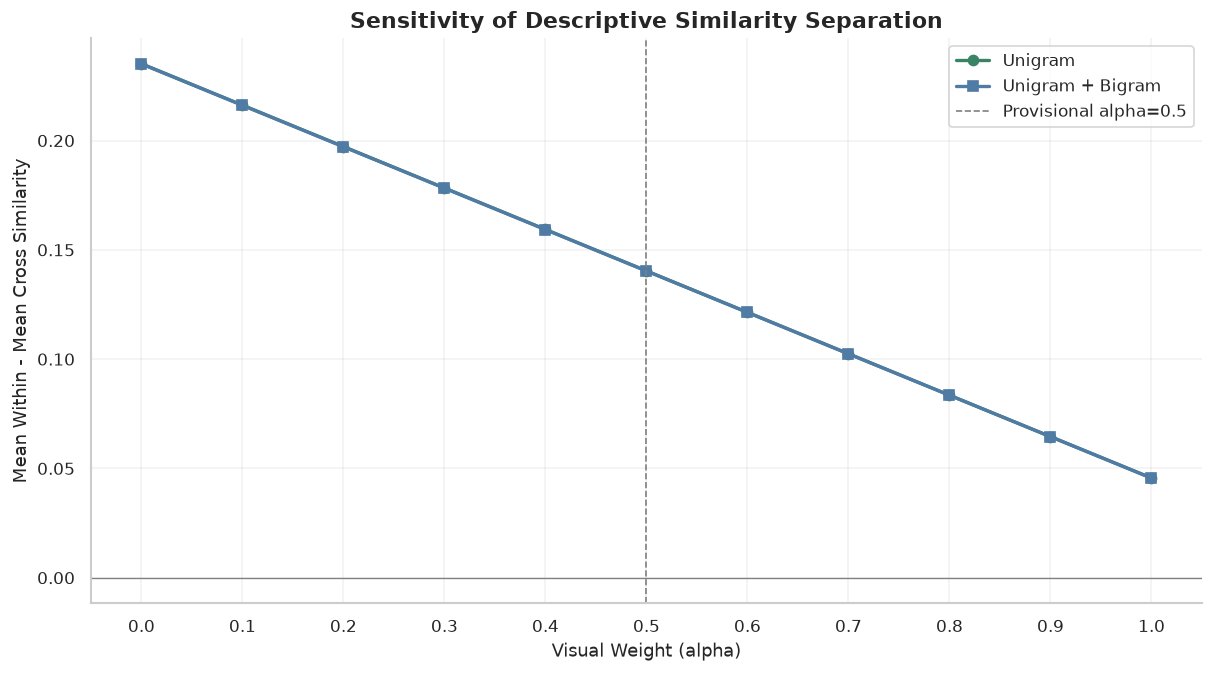

[SAVED] 131_fusion_weight_similarity_gap.png


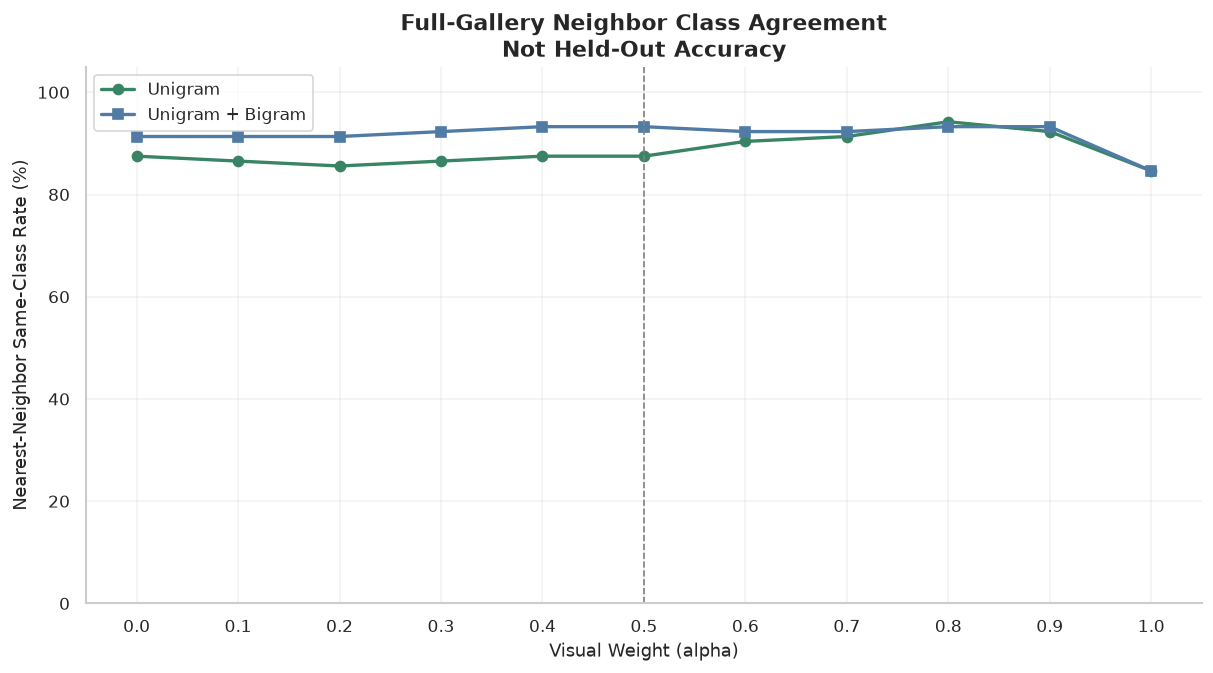

[SAVED] 132_fusion_weight_neighbor_agreement.png


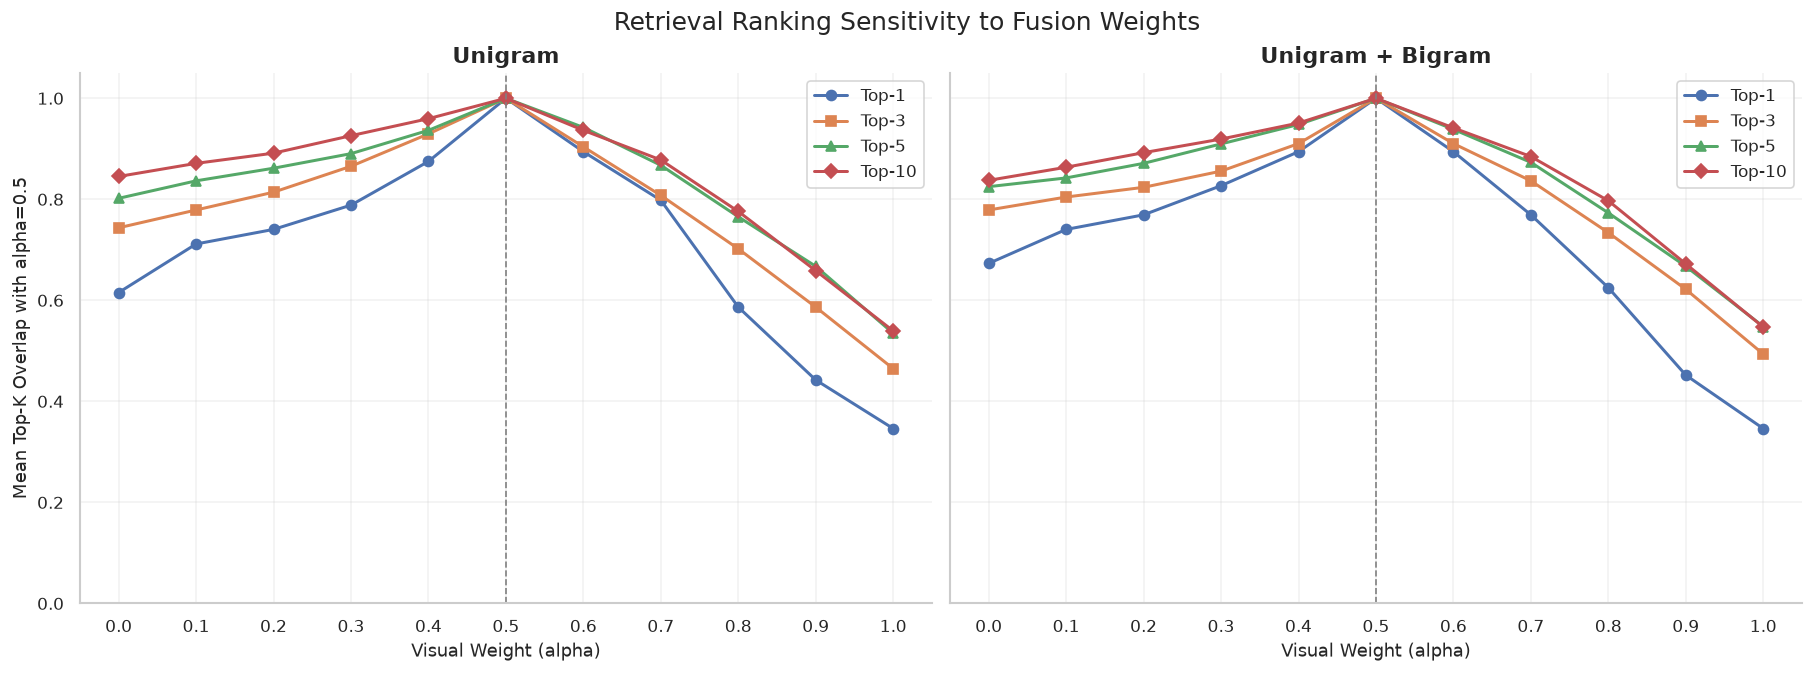

[SAVED] 133_fusion_weight_topk_overlap.png


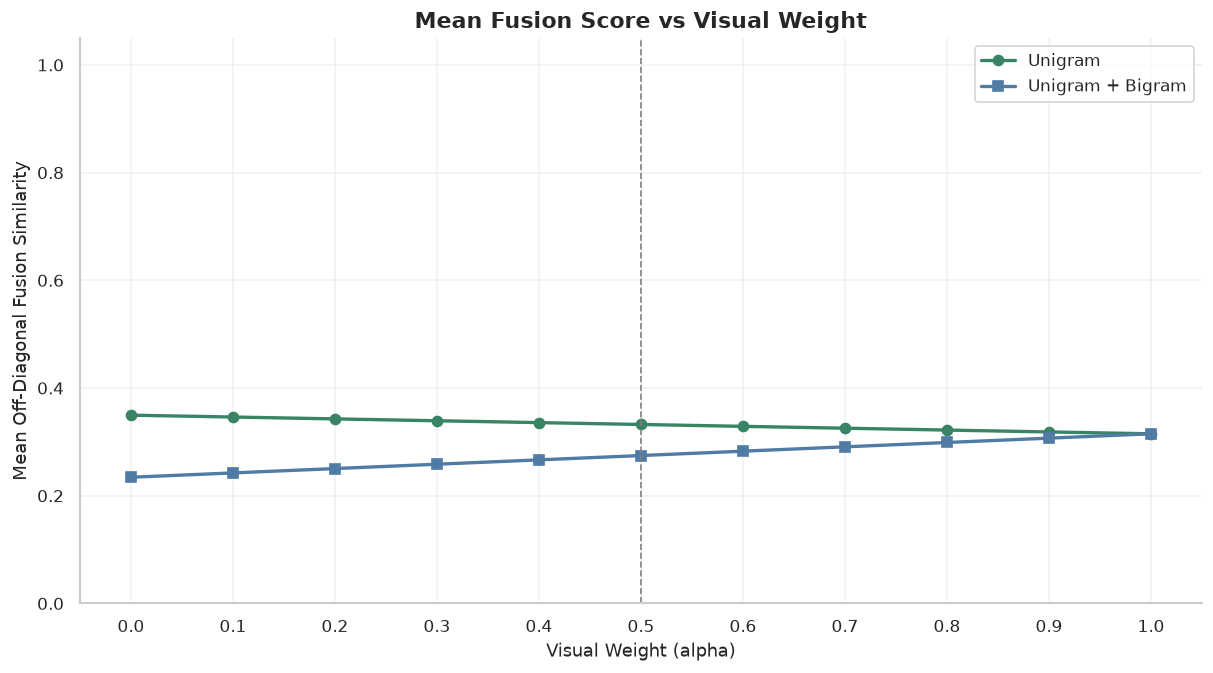

[SAVED] 134_fusion_weight_mean_similarity.png

7. SAVING FUSION SENSITIVITY REPORTS
------------------------------------------------------------------------
[SAVED] 444_fusion_weight_sensitivity_summary.csv
[SAVED] 445_fusion_weight_sensitivity_per_query.csv
[SAVED] 446_fusion_weight_sensitivity_topk_detail.csv
[SAVED] 447_fusion_weight_sensitivity_topk_summary.csv
[SAVED] 448_fusion_weight_sensitivity_endpoint_checks.csv
[SAVED] 449_fusion_weight_sensitivity_validation.csv
[SAVED] 450_fusion_weight_sensitivity_overview.csv
[SAVED] 451_fusion_weight_sensitivity_handoff.json

FINAL FUSION WEIGHT SENSITIVITY SUMMARY


,Indicator,Result
0,Sample count,104
1,Visual weight choices,11
2,Text configurations,2
3,Configuration-weight combinations,22
4,Distinct retrieval methods,21
5,Per-query diagnostics,2288
6,Top-K detail records,9152
7,Top-K summary records,88
8,Endpoint/default checks,6
9,Technical validation checks,169


Validation checks: 169/169; failed: 0
Figures: 4 | CSV reports: 7 | JSON handoff: 1
[INFO] Class agreement and Top-K overlap are full-gallery diagnostics.
[INFO] No best alpha or text configuration selected.

FUSION WEIGHT SENSITIVITY ANALYSIS COMPLETED SUCCESSFULLY
Next cell: Cell 15 - Multimodal Similarity Matrix Analysis


In [16]:
# ============================================================
# CELL 14 - FUSION WEIGHT SENSITIVITY ANALYSIS
# ============================================================

print("MULTIMODAL FUSION - FUSION WEIGHT SENSITIVITY ANALYSIS")
print("=" * 72)

FUSION_WEIGHT_SENSITIVITY_COMPLETED = False
FUSION_WEIGHT_SENSITIVITY_READY = False


# ============================================================
# 1. VALIDATE PREVIOUS STAGES
# ============================================================

required_flags = [
    "MULTIMODAL_DATASET_VALIDATION_COMPLETED",
    "FUSION_CONFIGURATION_COMPLETED",
    "VISUAL_SIMILARITY_CONVERSION_COMPLETED",
    "TEXT_COSINE_SIMILARITY_COMPLETED",
    "CROSS_MODALITY_SCORE_ANALYSIS_COMPLETED",
    "WEIGHTED_LATE_FUSION_COMPLETED",
]

for name in required_flags:

    assert globals().get(name, False) is True, (
        f"Run the prior cell first: {name}"
    )

assert fusion13_validation_df["passed"].all()

assert fusion13_mathematical_validation_df[
    "passed"
].all()

print("[PASS] Previous processing stages validated.")


# ============================================================
# 2. FUSION WEIGHT CONFIGURATION
# ============================================================

FUSION14_ALPHA_VALUES = [
    float(value)
    for value in FUSION_ALPHA_GRID
]

FUSION14_TEXT_CONFIGURATIONS = list(
    FUSION13_TEXT_CONFIGURATIONS
)

FUSION14_TOP_K_VALUES = tuple(
    int(k)
    for k in FUSION_TOP_K_VALUES
)

FUSION14_REFERENCE_ALPHA = 0.5

FUSION14_TOLERANCE = 1e-10

FUSION14_SCOPE = (
    "Full-Gallery Exploratory Sensitivity; "
    "no independent evaluation"
)

assert np.allclose(
    FUSION14_ALPHA_VALUES,
    np.linspace(0, 1, 11)
)

assert FUSION14_TEXT_CONFIGURATIONS == [
    "Unigram",
    "Unigram + Bigram"
]

assert FUSION14_TOP_K_VALUES == (1, 3, 5, 10)

assert FUSION14_REFERENCE_ALPHA in (
    FUSION14_ALPHA_VALUES
)

print("\n1. FUSION SENSITIVITY CONFIGURATION")
print("-" * 72)

print("Alpha values       :", FUSION14_ALPHA_VALUES)
print("Text configurations:", FUSION14_TEXT_CONFIGURATIONS)
print("Reference alpha    :", FUSION14_REFERENCE_ALPHA)
print("Top-K values       :", FUSION14_TOP_K_VALUES)
print("Analysis scope     :", FUSION14_SCOPE)


# ============================================================
# 3. PREPARE INPUT SIMILARITY MATRICES
# ============================================================

# Reuse results from Cells 10, 11, and 13.
# Do not refit normalizers or vectorizers.

fusion14_ids = np.asarray(
    multimodal_sample_ids,
    dtype=str
)

fusion14_labels = np.asarray(
    multimodal_labels,
    dtype=str
)

fusion14_visual = np.asarray(
    visual_similarity_matrix,
    dtype=np.float64
)

fusion14_texts = {
    name: np.asarray(
        text_similarity_matrices[name],
        dtype=np.float64
    )
    for name in FUSION14_TEXT_CONFIGURATIONS
}

n = len(fusion14_ids)

assert n == 104

assert fusion14_visual.shape == (n, n)

assert len(np.unique(fusion14_ids)) == n

assert np.array_equal(
    fusion14_ids,
    fusion_sample_ids
)

assert np.array_equal(
    fusion14_labels,
    fusion_class_labels
)

for name, matrix in fusion14_texts.items():

    assert matrix.shape == (n, n), name

print("\n2. INPUT SIMILARITY MATRICES")
print("-" * 72)

print("Visual matrix :", fusion14_visual.shape)

for name, matrix in fusion14_texts.items():

    print(
        f"Text {name}: {matrix.shape}"
    )


# ============================================================
# 4. PREPARE MATCHED SAMPLE PAIRS
# ============================================================

# Upper triangle excludes:
# - self-matches
# - duplicated reversed pairs

pair_i, pair_j = np.triu_indices(
    n,
    k=1
)

pair_is_same_class = (
    fusion14_labels[pair_i]
    ==
    fusion14_labels[pair_j]
)

assert len(pair_i) == 5356

assert int(
    pair_is_same_class.sum()
) == 1041

assert int(
    (~pair_is_same_class).sum()
) == 4315


# ============================================================
# 5. HELPER FUNCTIONS
# ============================================================

def fusion14_rank_nonself(matrix, query_idx):
    """
    Rank all candidates using descending similarity.

    Tie-breaking:
        sample_id ascending.

    The query sample is excluded.
    """

    candidates = np.arange(n)

    candidates = candidates[
        candidates != query_idx
    ]

    order = np.lexsort((
        fusion14_ids[candidates],
        -matrix[query_idx, candidates]
    ))

    return candidates[order]


def fusion14_add_check(category, name, passed):

    fusion14_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(passed),
        "status": (
            "Passed" if passed else "Failed"
        )
    })


def fusion14_save_fig(fig, filename):

    path = FUSION_FIGURES_DIR / filename

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    fusion14_figures.append(path)

    plt.show()
    plt.close(fig)

    print("[SAVED]", filename)


fusion14_checks = []

fusion14_figures = []

fusion_weight_sensitivity_matrices = {}

summary_rows = []
query_rows = []
topk_rows = []
endpoint_rows = []


# ============================================================
# 6. DEFINE REFERENCE RANKINGS AT ALPHA = 0.5
# ============================================================

# Compare each weight against the default fusion
# matrices created in Cell 13.

reference_rankings = {

    name: [
        fusion14_rank_nonself(
            fusion_default_similarity_matrices[name],
            query_index
        )
        for query_index in range(n)
    ]

    for name in FUSION14_TEXT_CONFIGURATIONS
}

print("\n3. REFERENCE RANKINGS")
print("-" * 72)

print("Reference visual weight:", FUSION14_REFERENCE_ALPHA)
print("Reference text weight  :", 1 - FUSION14_REFERENCE_ALPHA)
print("Reference queries      :", n)


# ============================================================
# 7. FUSION WEIGHT SENSITIVITY LOOP
# ============================================================

for text_name in FUSION14_TEXT_CONFIGURATIONS:

    print("\n" + "=" * 72)

    print(f"TEXT CONFIGURATION: {text_name}")

    print("=" * 72)

    text_matrix = fusion14_texts[
        text_name
    ]

    visual_pair_scores = fusion14_visual[
        pair_i,
        pair_j
    ]

    text_pair_scores = text_matrix[
        pair_i,
        pair_j
    ]

    visual_gap = float(
        visual_pair_scores[
            pair_is_same_class
        ].mean()
        -
        visual_pair_scores[
            ~pair_is_same_class
        ].mean()
    )

    text_gap = float(
        text_pair_scores[
            pair_is_same_class
        ].mean()
        -
        text_pair_scores[
            ~pair_is_same_class
        ].mean()
    )

    for alpha in FUSION14_ALPHA_VALUES:

        beta = 1.0 - alpha

        matrix_key = (
            text_name,
            alpha
        )

        # --------------------------------------------
        # A. CALCULATE WEIGHTED FUSION MATRIX
        # --------------------------------------------

        start_time = time.perf_counter()

        fused, effective_weights = (
            fuse_modality_scores(
                image_scores=fusion14_visual,
                text_scores=text_matrix,
                visual_weight=alpha
            )
        )

        duration_ms = (
            time.perf_counter() - start_time
        ) * 1000

        fusion_weight_sensitivity_matrices[
            matrix_key
        ] = fused

        # --------------------------------------------
        # B. VERIFY WEIGHTED-SUM FORMULA
        # --------------------------------------------

        expected = (
            alpha * fusion14_visual
            +
            beta * text_matrix
        )

        formula_error = float(
            np.max(
                np.abs(
                    fused - expected
                )
            )
        )

        structural_checks = {

            "shape_104x104":
                fused.shape == (n, n),

            "finite_and_in_range":
                np.isfinite(fused).all()
                and np.all(
                    fused >= -FUSION14_TOLERANCE
                )
                and np.all(
                    fused <= 1 + FUSION14_TOLERANCE
                ),

            "symmetric":
                np.allclose(
                    fused,
                    fused.T,
                    atol=FUSION14_TOLERANCE,
                    rtol=0
                ),

            "diagonal_one":
                np.allclose(
                    np.diag(fused),
                    1.0,
                    atol=FUSION14_TOLERANCE,
                    rtol=0
                ),

            "weighted_formula":
                formula_error
                <= FUSION14_TOLERANCE,

            "weights_sum_to_one":
                np.isclose(
                    effective_weights[
                        "effective_visual_weight"
                    ]
                    +
                    effective_weights[
                        "effective_text_weight"
                    ],
                    1.0,
                    atol=FUSION14_TOLERANCE
                )
        }

        for check_name, passed in structural_checks.items():

            fusion14_add_check(
                "Matrix " + text_name,
                f"alpha={alpha:.1f}: {check_name}",
                passed
            )

        # --------------------------------------------
        # C. WITHIN-CLASS VS CROSS-CLASS ANALYSIS
        # --------------------------------------------

        all_scores = fused[
            pair_i,
            pair_j
        ]

        within_scores = all_scores[
            pair_is_same_class
        ]

        cross_scores = all_scores[
            ~pair_is_same_class
        ]

        mean_gap = float(
            within_scores.mean()
            -
            cross_scores.mean()
        )

        # Because weighted fusion is linear,
        # the group-mean difference must also
        # follow the weighted-sum identity.

        expected_gap = (
            alpha * visual_gap
            +
            beta * text_gap
        )

        fusion14_add_check(
            "Linear Mean Identity",
            (
                f"{text_name} alpha={alpha:.1f} "
                "mean-gap identity"
            ),
            np.isclose(
                mean_gap,
                expected_gap,
                atol=FUSION14_TOLERANCE,
                rtol=0
            )
        )

        # --------------------------------------------
        # D. VALIDATE ALPHA ENDPOINTS AND DEFAULT
        # --------------------------------------------

        if alpha in (0.0, 0.5, 1.0):

            if alpha == 0.0:

                reference = text_matrix

                reference_name = "Text Only"

            elif alpha == 1.0:

                reference = fusion14_visual

                reference_name = "Image Only"

            else:

                reference = (
                    fusion_default_similarity_matrices[
                        text_name
                    ]
                )

                reference_name = (
                    "Cell 13 Balanced Fusion"
                )

            error = float(
                np.max(
                    np.abs(
                        fused - reference
                    )
                )
            )

            endpoint_rows.append({
                "text_configuration": text_name,
                "visual_weight": alpha,
                "expected_source": reference_name,
                "maximum_absolute_difference": error,
                "passed": (
                    error <= FUSION14_TOLERANCE
                )
            })

            fusion14_add_check(
                "Reference Matrices",
                (
                    f"{text_name} alpha={alpha:.1f} "
                    "reference consistency"
                ),
                error <= FUSION14_TOLERANCE
            )

        # --------------------------------------------
        # E. PER-QUERY RANKING ANALYSIS
        # --------------------------------------------

        nearest_matches = []

        for query_index in range(n):

            ranked_indices = fusion14_rank_nonself(
                fused,
                query_index
            )

            reference_ranked = reference_rankings[
                text_name
            ][query_index]

            nearest_index = int(
                ranked_indices[0]
            )

            same_class = bool(
                fusion14_labels[nearest_index]
                ==
                fusion14_labels[query_index]
            )

            nearest_matches.append(
                same_class
            )

            query_rows.append({
                "text_configuration": text_name,
                "visual_weight": alpha,
                "text_weight": beta,

                "query_sample_id":
                    fusion14_ids[query_index],

                "query_class":
                    fusion14_labels[query_index],

                "nearest_sample_id":
                    fusion14_ids[nearest_index],

                "nearest_class":
                    fusion14_labels[nearest_index],

                "nearest_similarity": float(
                    fused[
                        query_index,
                        nearest_index
                    ]
                ),

                "nearest_same_class":
                    same_class,

                "top1_same_as_alpha_0p5": bool(
                    nearest_index
                    ==
                    int(reference_ranked[0])
                ),

                "self_match_excluded": bool(
                    nearest_index != query_index
                )
            })

            # ----------------------------------------
            # F. TOP-K SENSITIVITY
            # ----------------------------------------

            for k in FUSION14_TOP_K_VALUES:

                selected = set(
                    ranked_indices[:k].tolist()
                )

                reference_set = set(
                    reference_ranked[:k].tolist()
                )

                overlap = len(
                    selected & reference_set
                )

                # Diagnostic only:
                # share of same-class candidates
                # among the gallery Top-K results.

                same_class_share = float(
                    np.mean(
                        fusion14_labels[
                            ranked_indices[:k]
                        ]
                        ==
                        fusion14_labels[
                            query_index
                        ]
                    )
                )

                topk_rows.append({
                    "text_configuration": text_name,
                    "visual_weight": alpha,

                    "query_sample_id":
                        fusion14_ids[query_index],

                    "query_class":
                        fusion14_labels[query_index],

                    "k": k,

                    "overlap_count_vs_alpha_0p5":
                        overlap,

                    "overlap_fraction_vs_alpha_0p5":
                        overlap / k,

                    "jaccard_vs_alpha_0p5":
                        overlap / (2 * k - overlap),

                    "gallery_same_class_share_at_k":
                        same_class_share,

                    "identical_ordered_topk_vs_alpha_0p5":
                        bool(
                            np.array_equal(
                                ranked_indices[:k],
                                reference_ranked[:k]
                            )
                        )
                })

        # --------------------------------------------
        # G. SAVE SUMMARY FOR EACH ALPHA
        # --------------------------------------------

        summary_rows.append({
            "text_configuration": text_name,

            "visual_weight": alpha,

            "text_weight": beta,

            "retrieval_mode": (
                "Text Only"
                if alpha == 0.0
                else (
                    "Image Only"
                    if alpha == 1.0
                    else "Multimodal"
                )
            ),

            "unique_pairs":
                len(all_scores),

            "mean_pair_similarity":
                float(all_scores.mean()),

            "std_pair_similarity":
                float(all_scores.std(ddof=0)),

            "mean_within_class_similarity":
                float(within_scores.mean()),

            "mean_cross_class_similarity":
                float(cross_scores.mean()),

            "within_minus_cross_mean_gap":
                mean_gap,

            "nearest_neighbor_same_class_rate_percent":
                float(
                    100.0
                    * np.mean(nearest_matches)
                ),

            "calculation_time_ms":
                duration_ms,

            "max_formula_error":
                formula_error,

            "independent_evaluation":
                False
        })

        print(
            f"[CALCULATED] "
            f"alpha={alpha:.1f}, "
            f"beta={beta:.1f}, "
            f"gap={mean_gap:.6f}"
        )


# ============================================================
# 8. CREATE SENSITIVITY DATAFRAMES
# ============================================================

fusion_weight_sensitivity_summary_df = pd.DataFrame(
    summary_rows
)

fusion_weight_sensitivity_query_df = pd.DataFrame(
    query_rows
)

fusion_weight_sensitivity_topk_df = pd.DataFrame(
    topk_rows
)

fusion_weight_sensitivity_endpoint_df = pd.DataFrame(
    endpoint_rows
)

fusion_weight_sensitivity_topk_summary_df = (
    fusion_weight_sensitivity_topk_df

    .groupby(
        [
            "text_configuration",
            "visual_weight",
            "k"
        ],
        as_index=False
    )

    .agg(
        number_of_queries=(
            "query_sample_id",
            "count"
        ),

        mean_overlap_vs_alpha_0p5=(
            "overlap_fraction_vs_alpha_0p5",
            "mean"
        ),

        mean_jaccard_vs_alpha_0p5=(
            "jaccard_vs_alpha_0p5",
            "mean"
        ),

        mean_gallery_same_class_share=(
            "gallery_same_class_share_at_k",
            "mean"
        ),

        ordered_topk_agreement_rate=(
            "identical_ordered_topk_vs_alpha_0p5",
            "mean"
        )
    )
)


# ============================================================
# 9. VERIFY EXPERIMENT INVENTORY
# ============================================================

fusion14_add_check(
    "Inventory",
    "22 configuration-weight combinations",
    len(fusion_weight_sensitivity_summary_df) == 22
)

fusion14_add_check(
    "Inventory",
    "2288 self-excluded query diagnostics",
    len(fusion_weight_sensitivity_query_df)
    == 22 * 104
    and fusion_weight_sensitivity_query_df[
        "self_match_excluded"
    ].all()
)

fusion14_add_check(
    "Inventory",
    "9152 query-K diagnostics",
    len(fusion_weight_sensitivity_topk_df)
    == 22 * 104 * 4
)

fusion14_add_check(
    "Inventory",
    "88 aggregated Top-K configurations",
    len(fusion_weight_sensitivity_topk_summary_df)
    == 22 * 4
)

fusion14_add_check(
    "Reference Matrices",
    "All six endpoint/default checks passed",
    len(fusion_weight_sensitivity_endpoint_df) == 6
    and fusion_weight_sensitivity_endpoint_df[
        "passed"
    ].all()
)

# When alpha=1, text weight becomes zero.
# Both TF-IDF configurations must yield the
# same image-only similarity matrix.

fusion14_add_check(
    "Reference Matrices",
    "Image-only outputs match across text configurations",
    np.allclose(
        fusion_weight_sensitivity_matrices[
            ("Unigram", 1.0)
        ],
        fusion_weight_sensitivity_matrices[
            ("Unigram + Bigram", 1.0)
        ],
        atol=FUSION14_TOLERANCE,
        rtol=0
    )
)

fusion14_add_check(
    "Ranking",
    "All Top-K overlap fractions in [0,1]",
    fusion_weight_sensitivity_topk_df[
        "overlap_fraction_vs_alpha_0p5"
    ].between(0, 1).all()
)

# At alpha=0.5 each configuration is compared
# against its own identical Cell 13 reference.

fusion14_add_check(
    "Ranking",
    "At alpha=0.5, all Top-K overlaps equal one",
    np.allclose(
        fusion_weight_sensitivity_topk_df.loc[
            fusion_weight_sensitivity_topk_df[
                "visual_weight"
            ].eq(0.5),
            "overlap_fraction_vs_alpha_0p5"
        ],
        1.0
    )
)

fusion14_add_check(
    "Alignment",
    "Output sample order preserved",
    np.array_equal(
        fusion14_ids,
        multimodal_sample_ids
    )
)


# ============================================================
# 10. FINAL TECHNICAL VALIDATION
# ============================================================

fusion_weight_sensitivity_validation_df = pd.DataFrame(
    fusion14_checks
)

fusion14_validation_total = len(
    fusion_weight_sensitivity_validation_df
)

fusion14_validation_passed = int(
    fusion_weight_sensitivity_validation_df[
        "passed"
    ].sum()
)

fusion14_validation_failed = (
    fusion14_validation_total
    -
    fusion14_validation_passed
)

# Save diagnostics before assertion.

validation_path = (
    METRICS_DIR
    / "449_fusion_weight_sensitivity_validation.csv"
)

fusion_weight_sensitivity_validation_df.to_csv(
    validation_path,
    index=False,
    encoding="utf-8-sig"
)

print("\n4. FUSION SENSITIVITY RESULTS")
print("-" * 72)

display(
    fusion_weight_sensitivity_summary_df.round(5)
)

print("\n5. REFERENCE MATRIX VERIFICATION")
print("-" * 72)

display(
    fusion_weight_sensitivity_endpoint_df
)

print("\n6. TOP-K OVERLAP SUMMARY")
print("-" * 72)

display(
    fusion_weight_sensitivity_topk_summary_df.round(4)
)

assert fusion_weight_sensitivity_validation_df[
    "passed"
].all(), (
    fusion_weight_sensitivity_validation_df.loc[
        ~fusion_weight_sensitivity_validation_df[
            "passed"
        ]
    ].to_string(index=False)
)

print(
    "[PASS] All fusion weight sensitivity "
    "checks passed."
)


# ============================================================
# 11. FIGURE 131 - SIMILARITY SEPARATION GAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 5.5),
    constrained_layout=True
)

for name, color, marker in [
    ("Unigram", "#398464", "o"),
    ("Unigram + Bigram", "#507BA5", "s"),
]:

    subset = (
        fusion_weight_sensitivity_summary_df.loc[
            fusion_weight_sensitivity_summary_df[
                "text_configuration"
            ].eq(name)
        ]
        .sort_values("visual_weight")
    )

    ax.plot(
        subset["visual_weight"],
        subset["within_minus_cross_mean_gap"],
        marker=marker,
        linewidth=2,
        color=color,
        label=name
    )

ax.axvline(
    0.5,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="Provisional alpha=0.5"
)

ax.axhline(
    0,
    color="gray",
    linewidth=0.8
)

ax.set_xlabel(
    "Visual Weight (alpha)"
)

ax.set_ylabel(
    "Mean Within - Mean Cross Similarity"
)

ax.set_title(
    "Sensitivity of Descriptive Similarity Separation"
)

ax.set_xticks(
    FUSION14_ALPHA_VALUES
)

ax.legend()

fusion14_save_fig(
    fig,
    "131_fusion_weight_similarity_gap.png"
)


# ============================================================
# 12. FIGURE 132 - NEAREST-NEIGHBOR CLASS AGREEMENT
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 5.5),
    constrained_layout=True
)

for name, color, marker in [
    ("Unigram", "#398464", "o"),
    ("Unigram + Bigram", "#507BA5", "s"),
]:

    subset = (
        fusion_weight_sensitivity_summary_df.loc[
            fusion_weight_sensitivity_summary_df[
                "text_configuration"
            ].eq(name)
        ]
        .sort_values("visual_weight")
    )

    ax.plot(
        subset["visual_weight"],
        subset[
            "nearest_neighbor_same_class_rate_percent"
        ],
        marker=marker,
        linewidth=2,
        color=color,
        label=name
    )

ax.axvline(
    0.5,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    "Visual Weight (alpha)"
)

ax.set_ylabel(
    "Nearest-Neighbor Same-Class Rate (%)"
)

ax.set_title(
    "Full-Gallery Neighbor Class Agreement\n"
    "Not Held-Out Accuracy"
)

ax.set_xticks(
    FUSION14_ALPHA_VALUES
)

ax.set_ylim(0, 105)

ax.legend()

fusion14_save_fig(
    fig,
    "132_fusion_weight_neighbor_agreement.png"
)


# ============================================================
# 13. FIGURE 133 - TOP-K OVERLAP SENSITIVITY
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5.5),
    sharey=True,
    constrained_layout=True
)

for ax, name in zip(
    axes,
    FUSION14_TEXT_CONFIGURATIONS
):

    for k, marker in zip(
        FUSION14_TOP_K_VALUES,
        ["o", "s", "^", "D"]
    ):

        subset = (
            fusion_weight_sensitivity_topk_summary_df.loc[
                fusion_weight_sensitivity_topk_summary_df[
                    "text_configuration"
                ].eq(name)
                &
                fusion_weight_sensitivity_topk_summary_df[
                    "k"
                ].eq(k)
            ]
            .sort_values("visual_weight")
        )

        ax.plot(
            subset["visual_weight"],
            subset["mean_overlap_vs_alpha_0p5"],
            marker=marker,
            linewidth=1.8,
            label=f"Top-{k}"
        )

    ax.axvline(
        0.5,
        color="gray",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(name)

    ax.set_xlabel(
        "Visual Weight (alpha)"
    )

    ax.set_xticks(
        FUSION14_ALPHA_VALUES
    )

    ax.set_ylim(0, 1.05)

    ax.legend()

axes[0].set_ylabel(
    "Mean Top-K Overlap with alpha=0.5"
)

fig.suptitle(
    "Retrieval Ranking Sensitivity to Fusion Weights",
    fontsize=15
)

fusion14_save_fig(
    fig,
    "133_fusion_weight_topk_overlap.png"
)


# ============================================================
# 14. FIGURE 134 - MEAN SIMILARITY VS WEIGHT
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 5.5),
    constrained_layout=True
)

for name, color, marker in [
    ("Unigram", "#398464", "o"),
    ("Unigram + Bigram", "#507BA5", "s"),
]:

    subset = (
        fusion_weight_sensitivity_summary_df.loc[
            fusion_weight_sensitivity_summary_df[
                "text_configuration"
            ].eq(name)
        ]
        .sort_values("visual_weight")
    )

    ax.plot(
        subset["visual_weight"],
        subset["mean_pair_similarity"],
        marker=marker,
        color=color,
        linewidth=2,
        label=name
    )

ax.axvline(
    0.5,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    "Visual Weight (alpha)"
)

ax.set_ylabel(
    "Mean Off-Diagonal Fusion Similarity"
)

ax.set_title(
    "Mean Fusion Score vs Visual Weight"
)

ax.set_xticks(
    FUSION14_ALPHA_VALUES
)

ax.set_ylim(0, 1.05)

ax.legend()

fusion14_save_fig(
    fig,
    "134_fusion_weight_mean_similarity.png"
)


# ============================================================
# 15. FINAL ANALYSIS SUMMARY
# ============================================================

fusion_weight_sensitivity_overview_df = pd.DataFrame([
    (
        "Sample count",
        n
    ),

    (
        "Visual weight choices",
        len(FUSION14_ALPHA_VALUES)
    ),

    (
        "Text configurations",
        len(FUSION14_TEXT_CONFIGURATIONS)
    ),

    (
        "Configuration-weight combinations",
        len(fusion_weight_sensitivity_summary_df)
    ),

    (
        "Distinct retrieval methods",
        21
    ),

    (
        "Per-query diagnostics",
        len(fusion_weight_sensitivity_query_df)
    ),

    (
        "Top-K detail records",
        len(fusion_weight_sensitivity_topk_df)
    ),

    (
        "Top-K summary records",
        len(fusion_weight_sensitivity_topk_summary_df)
    ),

    (
        "Endpoint/default checks",
        len(fusion_weight_sensitivity_endpoint_df)
    ),

    (
        "Technical validation checks",
        len(fusion_weight_sensitivity_validation_df)
    ),

    (
        "Failed technical checks",
        fusion14_validation_failed
    ),

    (
        "Generated figures",
        len(fusion14_figures)
    ),

    (
        "Best weight selected",
        False
    ),

    (
        "Independent evaluation completed",
        False
    ),

    (
        "Analysis scope",
        FUSION14_SCOPE
    )

], columns=["Indicator", "Result"])


# ============================================================
# 16. SAVE SENSITIVITY REPORTS
# ============================================================

fusion14_reports = {

    "444_fusion_weight_sensitivity_summary.csv":
        fusion_weight_sensitivity_summary_df,

    "445_fusion_weight_sensitivity_per_query.csv":
        fusion_weight_sensitivity_query_df,

    "446_fusion_weight_sensitivity_topk_detail.csv":
        fusion_weight_sensitivity_topk_df,

    "447_fusion_weight_sensitivity_topk_summary.csv":
        fusion_weight_sensitivity_topk_summary_df,

    "448_fusion_weight_sensitivity_endpoint_checks.csv":
        fusion_weight_sensitivity_endpoint_df,

    "449_fusion_weight_sensitivity_validation.csv":
        fusion_weight_sensitivity_validation_df,

    "450_fusion_weight_sensitivity_overview.csv":
        fusion_weight_sensitivity_overview_df,
}

print("\n7. SAVING FUSION SENSITIVITY REPORTS")
print("-" * 72)

for filename, dataframe in fusion14_reports.items():

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print("[SAVED]", filename)


# ============================================================
# 17. SAVE CONFIGURATION HANDOFF
# ============================================================

fusion14_handoff = {

    "notebook":
        "05_multimodal_fusion.ipynb",

    "cell":
        14,

    "method":
        "weighted_score_level_late_fusion",

    "sample_count":
        n,

    "sample_alignment_signature":
        multimodal_alignment_signature,

    "text_configurations":
        FUSION14_TEXT_CONFIGURATIONS,

    "alpha_values":
        FUSION14_ALPHA_VALUES,

    "reference_alpha":
        FUSION14_REFERENCE_ALPHA,

    "top_k_values":
        list(FUSION14_TOP_K_VALUES),

    "all_query_self_matches_excluded":
        True,

    "selection_status":
        "no_final_weight_or_text_configuration_selected",

    "independent_evaluation_completed":
        False,

    "scope":
        FUSION14_SCOPE,
}

fusion14_handoff_path = (
    METRICS_DIR
    / "451_fusion_weight_sensitivity_handoff.json"
)

with open(
    fusion14_handoff_path,
    "w",
    encoding="utf-8"
) as handle:

    json.dump(
        fusion14_handoff,
        handle,
        ensure_ascii=False,
        indent=2,
        allow_nan=False
    )

print(
    "[SAVED]",
    fusion14_handoff_path.name
)


# ============================================================
# 18. FINAL COMPLETION CHECKS
# ============================================================

assert len(
    fusion_weight_sensitivity_matrices
) == 22

assert fusion_weight_sensitivity_validation_df[
    "passed"
].all()

assert fusion14_validation_failed == 0

assert len(
    fusion_weight_sensitivity_summary_df
) == 22

assert len(
    fusion_weight_sensitivity_query_df
) == 2288

assert len(
    fusion_weight_sensitivity_topk_df
) == 9152

assert len(
    fusion_weight_sensitivity_topk_summary_df
) == 88

assert len(fusion14_figures) == 4

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in fusion14_figures
)

assert all(
    (METRICS_DIR / filename).is_file()
    for filename in fusion14_reports
)

assert fusion14_handoff_path.is_file()

FUSION_WEIGHT_SENSITIVITY_COMPLETED = True

FUSION_WEIGHT_SENSITIVITY_READY = True


# ============================================================
# 19. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 72)

print("FINAL FUSION WEIGHT SENSITIVITY SUMMARY")

print("=" * 72)

display(
    fusion_weight_sensitivity_overview_df
)

print(
    f"Validation checks: "
    f"{fusion14_validation_passed}/"
    f"{fusion14_validation_total}; "
    f"failed: {fusion14_validation_failed}"
)

print(
    "Figures: 4 | CSV reports: 7 | JSON handoff: 1"
)

print(
    "[INFO] Class agreement and Top-K overlap "
    "are full-gallery diagnostics."
)

print(
    "[INFO] No best alpha or text configuration selected."
)

print(
    "\nFUSION WEIGHT SENSITIVITY ANALYSIS "
    "COMPLETED SUCCESSFULLY"
)

print(
    "Next cell: Cell 15 - "
    "Multimodal Similarity Matrix Analysis"
)

MULTIMODAL FUSION - SIMILARITY MATRIX ANALYSIS

1. ANALYSIS CONFIGURATION
------------------------------------------------------------------------
Samples        : 104
Default alpha  : 0.5
Configurations : ('Unigram', 'Unigram + Bigram')
Top-K values   : (1, 3, 5, 10)
Analysis scope : Full-gallery descriptive analysis; no held-out evaluation

2. INPUT SIMILARITY MATRICES
------------------------------------------------------------------------
Visual                        : (104, 104)
Text - Unigram                : (104, 104)
Fusion - Unigram              : (104, 104)
Text - Unigram + Bigram       : (104, 104)
Fusion - Unigram + Bigram     : (104, 104)

TEXT CONFIGURATION: Unigram

TEXT CONFIGURATION: Unigram + Bigram

3. FUSION MATRIX STRUCTURE
------------------------------------------------------------------------


,text_configuration,sample_count,unique_pairs,visual_weight,text_weight,mean_visual_similarity,mean_text_similarity,mean_fusion_similarity,mean_abs_fusion_minus_visual,mean_abs_fusion_minus_text,mean_fusion_within,mean_fusion_cross,within_minus_cross_mean_gap,max_formula_error,max_cell14_consistency_error,independent_evaluation
0,Unigram,104,5356,0.5,0.5,0.31501,0.34960,0.33231,0.05876,0.05876,0.4454,0.30502,0.14037,0.0,0.0,False
1,Unigram + Bigram,104,5356,0.5,0.5,0.31501,0.23429,0.27465,0.06871,0.06871,0.3877,0.24738,0.14032,0.0,0.0,False



4. CLASS-BLOCK SIMILARITY (PREVIEW)
------------------------------------------------------------------------


,text_configuration,class_i,class_j,pair_type,number_of_pairs,visual_mean,text_mean,fusion_mean,fusion_minus_visual_mean,fusion_minus_text_mean,fusion_minimum,fusion_maximum
0,Unigram,Mangkok,Mangkok,Within Class,190,0.39905,0.62078,0.50992,0.11086,-0.11086,0.36334,0.77568
1,Unigram,Mangkok,Salam,Cross Class,380,0.27562,0.31428,0.29495,0.01933,-0.01933,0.16351,0.50720
2,Unigram,Mangkok,Sambang Darah,Cross Class,400,0.29251,0.27727,0.28489,-0.00762,0.00762,0.16604,0.47426
3,Unigram,Mangkok,Sirih,Cross Class,400,0.33995,0.28058,0.31027,-0.02969,0.02969,0.19043,0.61089
4,Unigram,Mangkok,Tapak Kuda,Cross Class,500,0.33570,0.45853,0.39711,0.06142,-0.06142,0.20377,0.58839
5,Unigram,Salam,Salam,Within Class,171,0.30592,0.48085,0.39338,0.08747,-0.08747,0.19077,0.65739
6,Unigram,Salam,Sambang Darah,Cross Class,380,0.30664,0.43401,0.37033,0.06368,-0.06368,0.19411,0.65530
7,Unigram,Salam,Sirih,Cross Class,380,0.28885,0.29798,0.29342,0.00457,-0.00457,0.18278,0.54043
8,Unigram,Salam,Tapak Kuda,Cross Class,475,0.28477,0.23410,0.25943,-0.02534,0.02534,0.16364,0.46639
9,Unigram,Sambang Darah,Sambang Darah,Within Class,190,0.32176,0.44982,0.38579,0.06403,-0.06403,0.17226,0.72650



5. TOP-K OVERLAP SUMMARY
------------------------------------------------------------------------


,text_configuration,reference_modality,k,number_of_queries,mean_overlap_at_k,mean_jaccard_at_k,ordered_topk_agreement
0,Unigram,Text,1,104,0.6154,0.6154,0.6154
1,Unigram,Text,3,104,0.7436,0.6442,0.1538
2,Unigram,Text,5,104,0.8019,0.7005,0.0385
3,Unigram,Text,10,104,0.8452,0.7433,0.0000
4,Unigram,Visual,1,104,0.3462,0.3462,0.3462
5,Unigram,Visual,3,104,0.4647,0.3538,0.0385
6,Unigram,Visual,5,104,0.5346,0.3965,0.0000
7,Unigram,Visual,10,104,0.5394,0.3883,0.0000
8,Unigram + Bigram,Text,1,104,0.6731,0.6731,0.6731
9,Unigram + Bigram,Text,3,104,0.7788,0.6875,0.2115



6. TECHNICAL VALIDATION
------------------------------------------------------------------------


,category,validation_check,passed,status
0,Matrix Integrity,Visual,True,Passed
1,Matrix Integrity,Text - Unigram,True,Passed
2,Matrix Integrity,Fusion - Unigram,True,Passed
3,Matrix Integrity,Text - Unigram + Bigram,True,Passed
4,Matrix Integrity,Fusion - Unigram + Bigram,True,Passed
5,Fusion Formula,Unigram: weighted average,True,Passed
6,Fusion Formula,Unigram: Cell 14 alpha=0.5,True,Passed
7,Class Blocks,Unigram: 5356 class-block pairs,True,Passed
8,Fusion Formula,Unigram + Bigram: weighted average,True,Passed
9,Fusion Formula,Unigram + Bigram: Cell 14 alpha=0.5,True,Passed


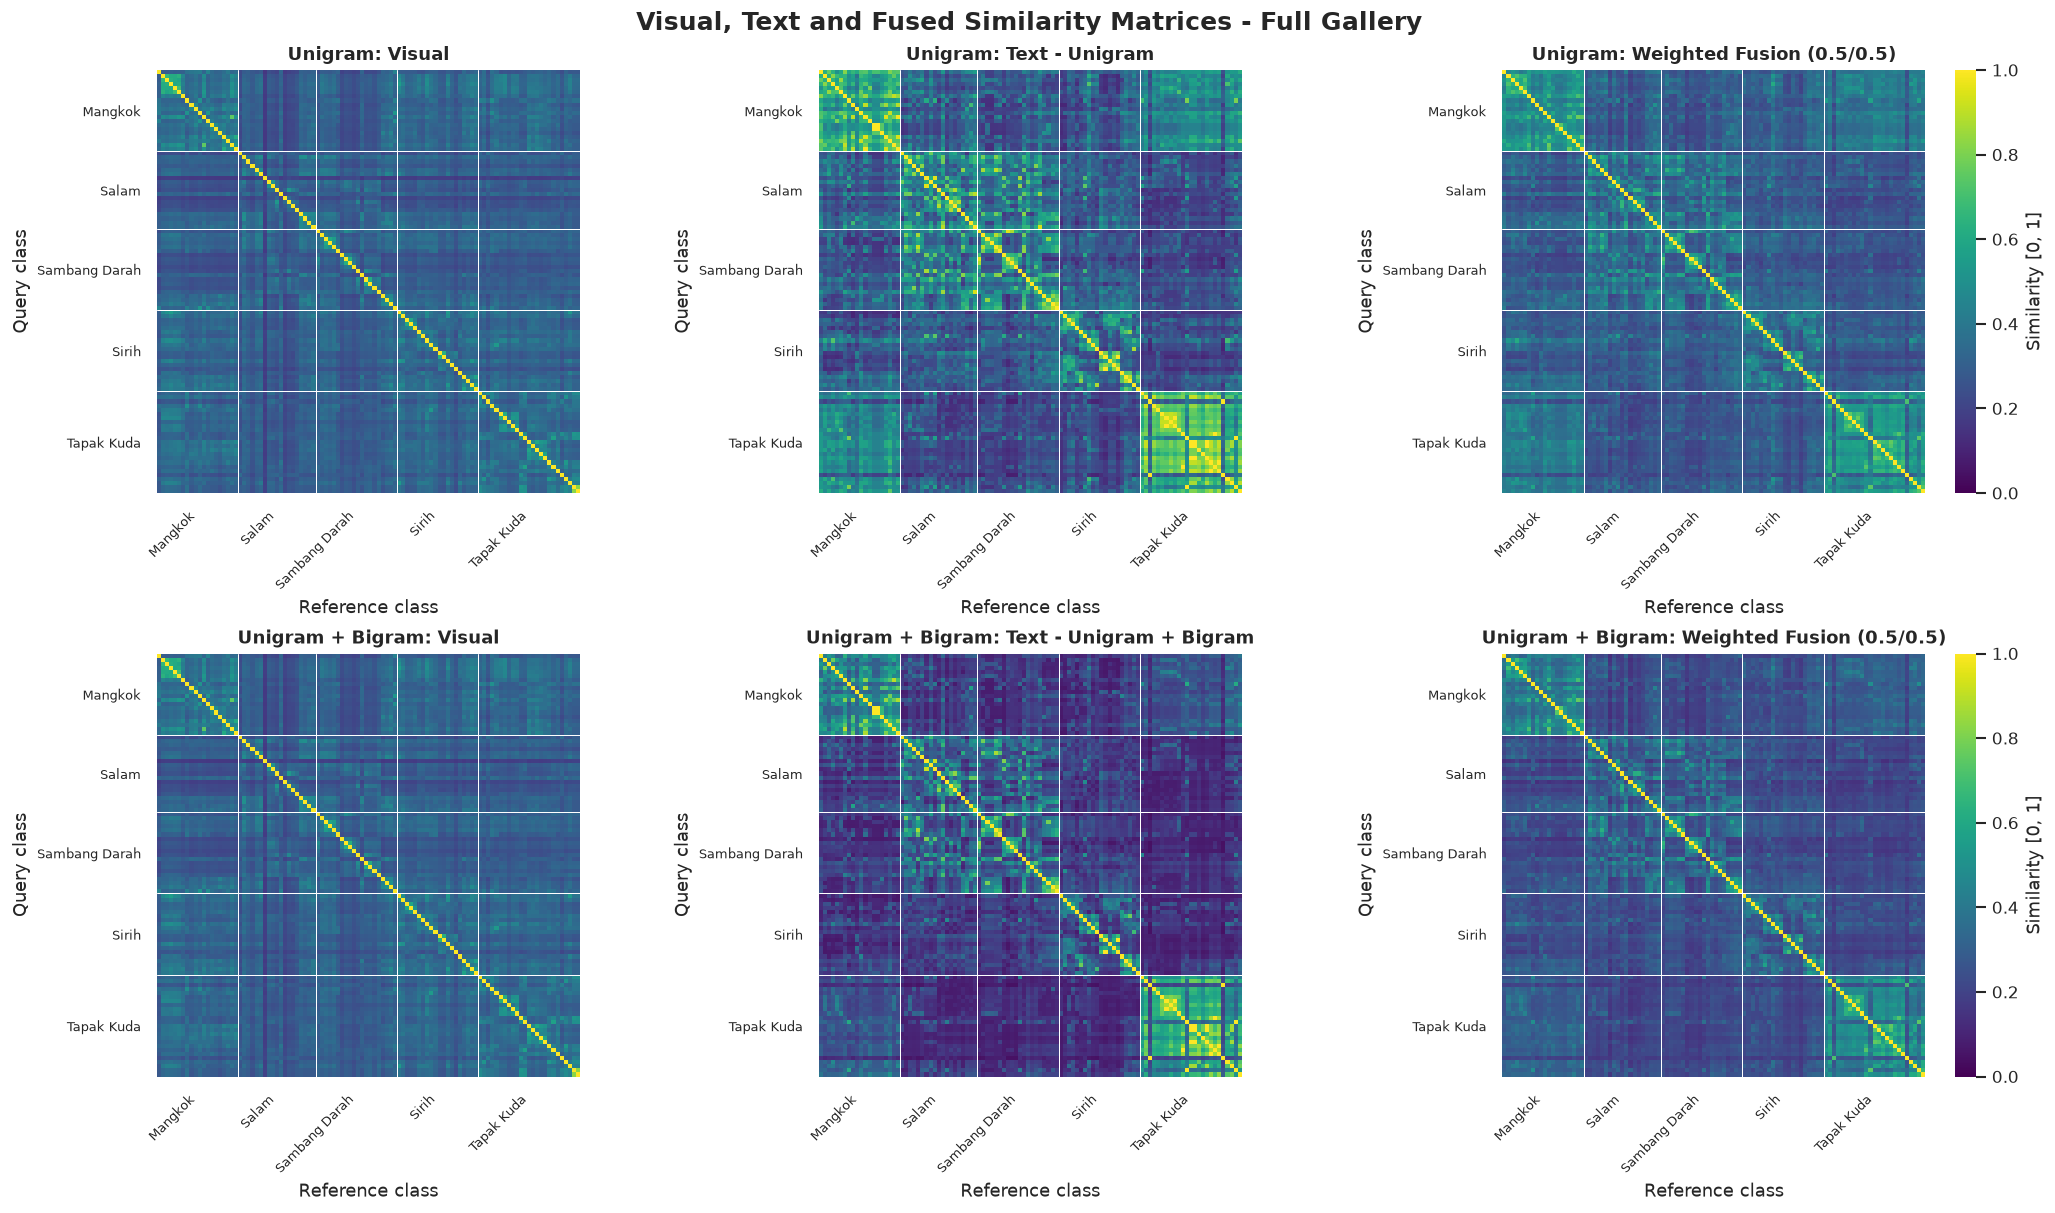

[SAVED] 135_multimodal_similarity_matrix_comparison.png


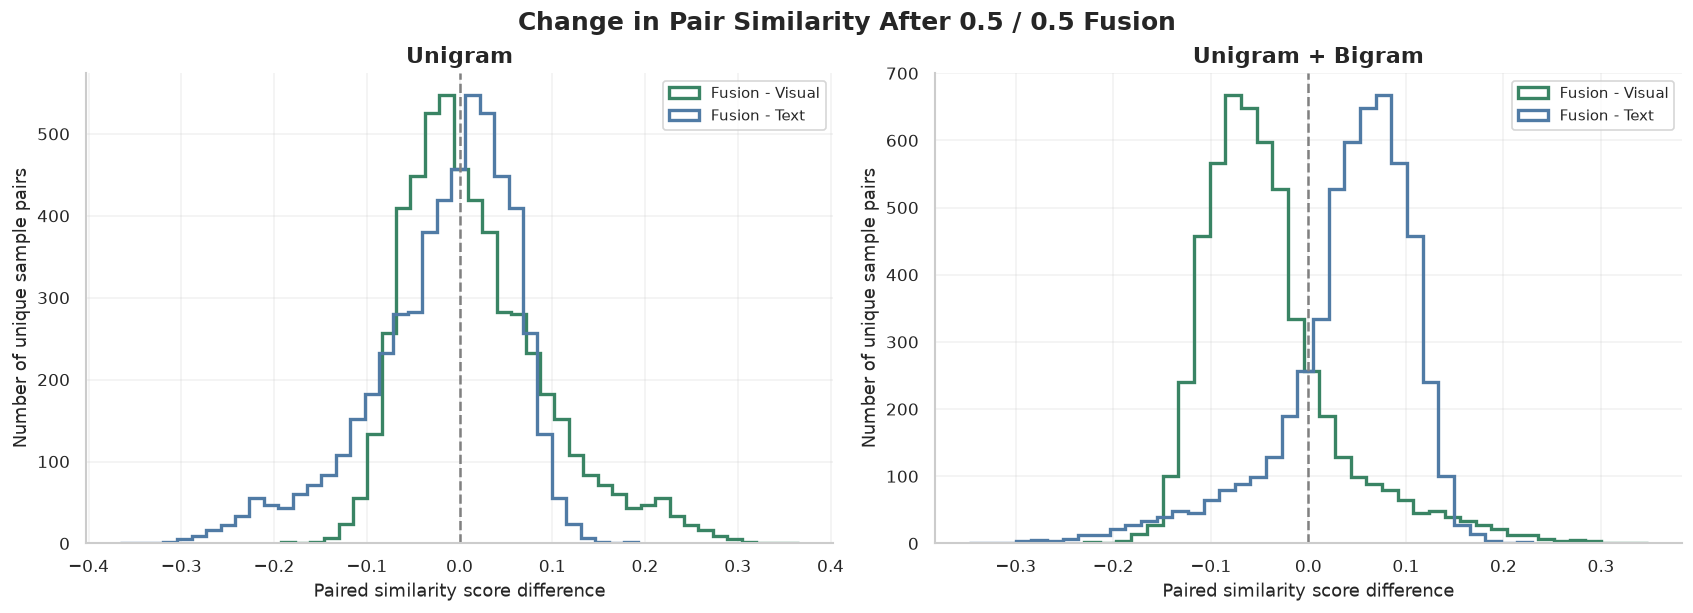

[SAVED] 136_multimodal_fusion_score_differences.png


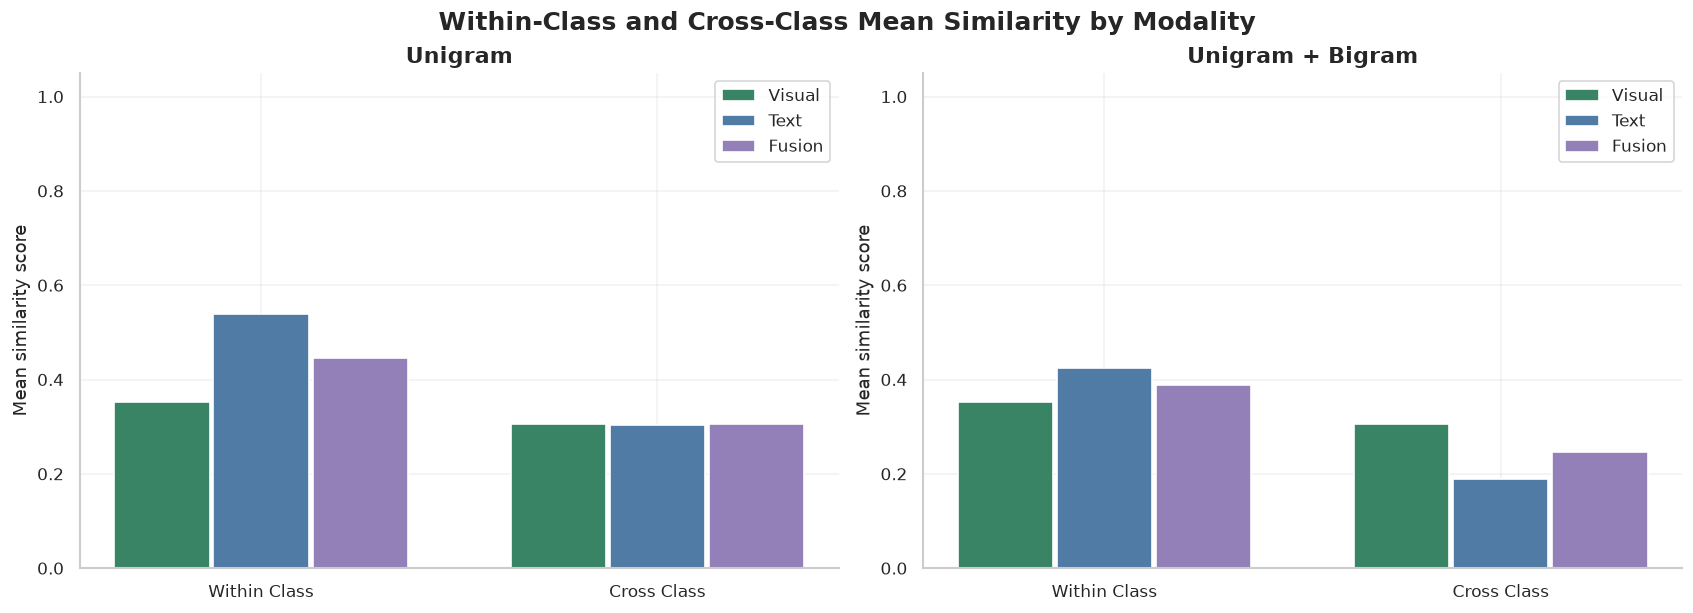

[SAVED] 137_multimodal_class_block_similarity.png


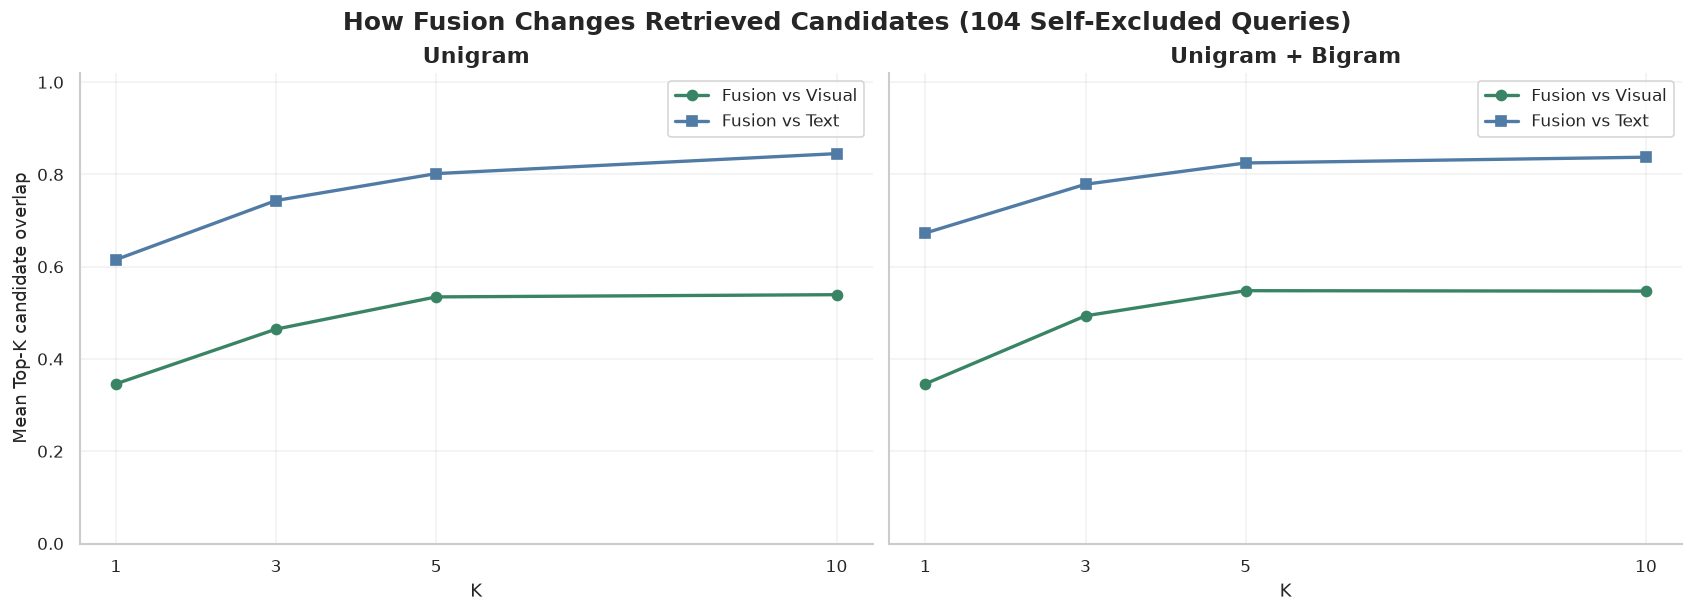

[SAVED] 138_multimodal_matrix_topk_overlap.png

7. FINAL MATRIX ANALYSIS OVERVIEW
------------------------------------------------------------------------


,Indicator,Result
0,Samples,104
1,Fusion configurations,2
2,Default alpha,0.5
3,Unique unordered pairs per configuration,5356
4,Paired score comparison rows,10712
5,Class-block summary rows,30
6,Per-query ranking rows,208
7,Query-Top-K overlap rows,1664
8,Top-K aggregate rows,16
9,Passed checks,20



8. SAVING MATRIX ANALYSIS REPORTS
------------------------------------------------------------------------
[SAVED] 452_multimodal_matrix_structure_summary.csv
[SAVED] 453_multimodal_matrix_pairwise_differences.csv
[SAVED] 454_multimodal_matrix_class_blocks.csv
[SAVED] 455_multimodal_matrix_query_diagnostics.csv
[SAVED] 456_multimodal_matrix_topk_overlap.csv
[SAVED] 457_multimodal_matrix_topk_summary.csv
[SAVED] 458_multimodal_matrix_analysis_validation.csv
[SAVED] 459_multimodal_matrix_analysis_overview.csv
[SAVED] 460_multimodal_matrix_analysis_handoff.json

MULTIMODAL SIMILARITY MATRIX ANALYSIS COMPLETED SUCCESSFULLY
Fusion matrices: 2 (104 x 104)
Paired scores: 10712
Checks passed: 20/20
Outputs: 8 CSV reports, 1 JSON handoff, 4 figures
[INFO] No final weight selected; diagnostics are full-gallery only.

Next cell: Cell 16 - Top-K Multimodal Retrieval


In [17]:
# ============================================================
# CELL 15 - MULTIMODAL SIMILARITY MATRIX ANALYSIS
# ============================================================

import json

print("MULTIMODAL FUSION - SIMILARITY MATRIX ANALYSIS")
print("=" * 72)

MULTIMODAL_MATRIX_ANALYSIS_COMPLETED = False


# ============================================================
# 1. VALIDATE PREVIOUS STAGES
# ============================================================

for flag in [
    "MULTIMODAL_DATASET_VALIDATION_COMPLETED",
    "FUSION_CONFIGURATION_COMPLETED",
    "VISUAL_SIMILARITY_CONVERSION_COMPLETED",
    "TEXT_COSINE_SIMILARITY_COMPLETED",
    "CROSS_MODALITY_SCORE_ANALYSIS_COMPLETED",
    "WEIGHTED_LATE_FUSION_COMPLETED",
    "FUSION_WEIGHT_SENSITIVITY_COMPLETED",
]:
    assert globals().get(flag, False) is True, (
        f"Run previous stage: {flag}"
    )

assert fusion13_validation_df["passed"].all()

assert fusion_weight_sensitivity_validation_df[
    "passed"
].all()


# ============================================================
# 2. ANALYSIS PARAMETERS AND HELPERS
# ============================================================

MATRIX15_ALPHA = 0.5

MATRIX15_K_VALUES = (1, 3, 5, 10)

MATRIX15_CONFIGS = (
    "Unigram",
    "Unigram + Bigram"
)

MATRIX15_TOL = 1e-10

MATRIX15_SCOPE = (
    "Full-gallery descriptive analysis; "
    "no held-out evaluation"
)

matrix15_ids = np.asarray(
    multimodal_sample_ids,
    dtype=str
)

matrix15_labels = np.asarray(
    multimodal_labels,
    dtype=str
)

matrix15_n = len(matrix15_ids)

assert matrix15_n == 104

assert np.unique(matrix15_ids).size == matrix15_n

assert np.array_equal(
    matrix15_ids,
    fusion_sample_ids
)

assert np.array_equal(
    matrix15_labels,
    fusion_class_labels
)

matrix15_pair_i, matrix15_pair_j = np.triu_indices(
    matrix15_n,
    k=1
)

matrix15_within = (
    matrix15_labels[matrix15_pair_i]
    ==
    matrix15_labels[matrix15_pair_j]
)

assert len(matrix15_pair_i) == 5356

assert matrix15_within.sum() == 1041

assert (~matrix15_within).sum() == 4315


# ============================================================
# 3. INITIALIZE OUTPUT COLLECTIONS
# ============================================================

matrix15_checks = []

matrix15_figures = []

matrix15_matrix_rows = []

matrix15_pair_frames = []

matrix15_class_rows = []

matrix15_query_rows = []

matrix15_topk_rows = []


def matrix15_check(category, name, ok):

    matrix15_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(ok),
        "status": (
            "Passed" if ok else "Failed"
        )
    })


def matrix15_rank(s, qi):

    candidates = np.arange(
        matrix15_n
    )

    candidates = candidates[
        candidates != qi
    ]

    order = np.lexsort((
        matrix15_ids[candidates],
        -s[qi, candidates]
    ))

    return candidates[order]


def matrix15_save(fig, filename):

    path = FUSION_FIGURES_DIR / filename

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    matrix15_figures.append(path)

    plt.show()

    plt.close(fig)

    print("[SAVED]", filename)


print("\n1. ANALYSIS CONFIGURATION")
print("-" * 72)

print("Samples        :", matrix15_n)
print("Default alpha  :", MATRIX15_ALPHA)
print("Configurations :", MATRIX15_CONFIGS)
print("Top-K values   :", MATRIX15_K_VALUES)
print("Analysis scope :", MATRIX15_SCOPE)


# ============================================================
# 4. COLLECT AND VALIDATE SIMILARITY MATRICES
# ============================================================

matrix15_visual = np.asarray(
    visual_similarity_matrix,
    dtype=np.float64
)

matrix15_inputs = {
    "Visual": matrix15_visual
}

matrix15_fusions = {}

matrix15_texts = {}

for cfg in MATRIX15_CONFIGS:

    text_s = np.asarray(
        text_similarity_matrices[cfg],
        dtype=np.float64
    )

    fused_s = np.asarray(
        fusion_default_similarity_matrices[cfg],
        dtype=np.float64
    )

    matrix15_texts[cfg] = text_s

    matrix15_fusions[cfg] = fused_s

    matrix15_inputs[
        f"Text - {cfg}"
    ] = text_s

    matrix15_inputs[
        f"Fusion - {cfg}"
    ] = fused_s


# Keep snapshots to detect accidental mutation.

matrix15_snapshots = {
    name: arr.copy()
    for name, arr in matrix15_inputs.items()
}


for name, s in matrix15_inputs.items():

    ok = (
        s.shape == (104, 104)
        and s.dtype == np.float64
        and np.isfinite(s).all()
        and np.all(
            (s >= -MATRIX15_TOL)
            &
            (s <= 1 + MATRIX15_TOL)
        )
        and np.allclose(
            s,
            s.T,
            atol=MATRIX15_TOL,
            rtol=0
        )
        and np.allclose(
            np.diag(s),
            1,
            atol=MATRIX15_TOL,
            rtol=0
        )
    )

    matrix15_check(
        "Matrix Integrity",
        name,
        ok
    )

    assert ok, (
        f"Invalid similarity matrix: {name}"
    )


print("\n2. INPUT SIMILARITY MATRICES")
print("-" * 72)

for name, matrix in matrix15_inputs.items():

    print(
        f"{name:30s}: {matrix.shape}"
    )


# ============================================================
# 5. ANALYZE EACH FUSION CONFIGURATION
# ============================================================

for cfg in MATRIX15_CONFIGS:

    print("\n" + "=" * 72)
    print(f"TEXT CONFIGURATION: {cfg}")
    print("=" * 72)

    v = matrix15_visual

    t = matrix15_texts[cfg]

    f = matrix15_fusions[cfg]

    # --------------------------------------------------------
    # A. VERIFY WEIGHTED FUSION FORMULA
    # --------------------------------------------------------

    expected = (
        0.5 * v
        +
        0.5 * t
    )

    sensitivity_copy = (
        fusion_weight_sensitivity_matrices[
            (cfg, MATRIX15_ALPHA)
        ]
    )

    algebra_error = float(
        np.max(
            np.abs(
                f - expected
            )
        )
    )

    sensitivity_error = float(
        np.max(
            np.abs(
                f - sensitivity_copy
            )
        )
    )

    matrix15_check(
        "Fusion Formula",
        f"{cfg}: weighted average",
        algebra_error <= MATRIX15_TOL
    )

    matrix15_check(
        "Fusion Formula",
        f"{cfg}: Cell 14 alpha=0.5",
        sensitivity_error <= MATRIX15_TOL
    )

    # --------------------------------------------------------
    # B. EXTRACT UNIQUE PAIR SCORES
    # --------------------------------------------------------

    vp = v[
        matrix15_pair_i,
        matrix15_pair_j
    ]

    tp = t[
        matrix15_pair_i,
        matrix15_pair_j
    ]

    fp = f[
        matrix15_pair_i,
        matrix15_pair_j
    ]

    paired = pd.DataFrame({

        "text_configuration": cfg,

        "sample_id_i":
            matrix15_ids[matrix15_pair_i],

        "sample_id_j":
            matrix15_ids[matrix15_pair_j],

        "class_i":
            matrix15_labels[matrix15_pair_i],

        "class_j":
            matrix15_labels[matrix15_pair_j],

        "pair_type": np.where(
            matrix15_within,
            "Within Class",
            "Cross Class"
        ),

        "visual_similarity": vp,

        "text_similarity": tp,

        "fusion_similarity": fp,

        "fusion_minus_visual": fp - vp,

        "fusion_minus_text": fp - tp,

        "abs_fusion_minus_visual":
            np.abs(fp - vp),

        "abs_fusion_minus_text":
            np.abs(fp - tp)
    })

    matrix15_pair_frames.append(
        paired
    )

    # --------------------------------------------------------
    # C. MATRIX STRUCTURE SUMMARY
    # --------------------------------------------------------

    summary = {

        "text_configuration": cfg,

        "sample_count": matrix15_n,

        "unique_pairs": len(fp),

        "visual_weight": MATRIX15_ALPHA,

        "text_weight": (
            1 - MATRIX15_ALPHA
        ),

        "mean_visual_similarity":
            float(vp.mean()),

        "mean_text_similarity":
            float(tp.mean()),

        "mean_fusion_similarity":
            float(fp.mean()),

        "mean_abs_fusion_minus_visual":
            float(np.abs(fp - vp).mean()),

        "mean_abs_fusion_minus_text":
            float(np.abs(fp - tp).mean()),

        "mean_fusion_within":
            float(fp[matrix15_within].mean()),

        "mean_fusion_cross":
            float(fp[~matrix15_within].mean()),

        "within_minus_cross_mean_gap":
            float(
                fp[matrix15_within].mean()
                -
                fp[~matrix15_within].mean()
            ),

        "max_formula_error":
            algebra_error,

        "max_cell14_consistency_error":
            sensitivity_error,

        "independent_evaluation":
            False
    }

    matrix15_matrix_rows.append(
        summary
    )

    # --------------------------------------------------------
    # D. CLASS-BLOCK SIMILARITY ANALYSIS
    # --------------------------------------------------------

    # Each class block counts unordered pairs once.
    # Diagonal entries are excluded.

    classes = sorted(
        np.unique(matrix15_labels)
    )

    label_i = matrix15_labels[
        matrix15_pair_i
    ]

    label_j = matrix15_labels[
        matrix15_pair_j
    ]

    class_block_pair_total = 0

    for a_index, a in enumerate(classes):

        for b in classes[a_index:]:

            if a == b:

                mask = (
                    (label_i == a)
                    &
                    (label_j == a)
                )

                category = "Within Class"

            else:

                mask = (
                    (
                        (label_i == a)
                        &
                        (label_j == b)
                    )
                    |
                    (
                        (label_i == b)
                        &
                        (label_j == a)
                    )
                )

                category = "Cross Class"

            assert np.any(mask)

            class_block_pair_total += int(
                mask.sum()
            )

            matrix15_class_rows.append({

                "text_configuration": cfg,

                "class_i": a,

                "class_j": b,

                "pair_type": category,

                "number_of_pairs":
                    int(mask.sum()),

                "visual_mean":
                    float(vp[mask].mean()),

                "text_mean":
                    float(tp[mask].mean()),

                "fusion_mean":
                    float(fp[mask].mean()),

                "fusion_minus_visual_mean":
                    float(
                        (fp[mask] - vp[mask]).mean()
                    ),

                "fusion_minus_text_mean":
                    float(
                        (fp[mask] - tp[mask]).mean()
                    ),

                "fusion_minimum":
                    float(fp[mask].min()),

                "fusion_maximum":
                    float(fp[mask].max())
            })

    matrix15_check(
        "Class Blocks",
        f"{cfg}: 5356 class-block pairs",
        class_block_pair_total == 5356
    )

    # --------------------------------------------------------
    # E. COMPARE QUERY RANKINGS
    # --------------------------------------------------------

    for qi in range(matrix15_n):

        rank_v = matrix15_rank(
            v,
            qi
        )

        rank_t = matrix15_rank(
            t,
            qi
        )

        rank_f = matrix15_rank(
            f,
            qi
        )

        fi = int(
            rank_f[0]
        )

        matrix15_query_rows.append({

            "text_configuration": cfg,

            "query_sample_id":
                matrix15_ids[qi],

            "query_class":
                matrix15_labels[qi],

            "visual_top1_sample_id":
                matrix15_ids[rank_v[0]],

            "text_top1_sample_id":
                matrix15_ids[rank_t[0]],

            "fusion_top1_sample_id":
                matrix15_ids[fi],

            "fusion_top1_similarity":
                float(f[qi, fi]),

            "fusion_top1_same_class":
                bool(
                    matrix15_labels[fi]
                    ==
                    matrix15_labels[qi]
                ),

            "fusion_top1_matches_visual":
                bool(
                    fi == rank_v[0]
                ),

            "fusion_top1_matches_text":
                bool(
                    fi == rank_t[0]
                ),

            "visual_top1_matches_text":
                bool(
                    rank_v[0] == rank_t[0]
                ),

            "self_match_excluded":
                bool(qi != fi)
        })

        # ----------------------------------------------------
        # F. TOP-K OVERLAP WITH VISUAL AND TEXT
        # ----------------------------------------------------

        for ref_name, ranked_ref in (
            ("Visual", rank_v),
            ("Text", rank_t)
        ):

            for k in MATRIX15_K_VALUES:

                fset = set(
                    rank_f[:k].tolist()
                )

                rset = set(
                    ranked_ref[:k].tolist()
                )

                intersection = len(
                    fset & rset
                )

                matrix15_topk_rows.append({

                    "text_configuration": cfg,

                    "reference_modality":
                        ref_name,

                    "query_sample_id":
                        matrix15_ids[qi],

                    "k": k,

                    "shared_candidates":
                        intersection,

                    "overlap_at_k":
                        intersection / k,

                    "jaccard_at_k":
                        intersection
                        /
                        (2 * k - intersection),

                    "identical_ordered_topk":
                        bool(
                            np.array_equal(
                                rank_f[:k],
                                ranked_ref[:k]
                            )
                        )
                })


# ============================================================
# 6. ASSEMBLE ANALYSIS RESULTS
# ============================================================

multimodal_matrix_structure_summary_df = pd.DataFrame(
    matrix15_matrix_rows
)

multimodal_matrix_pairwise_differences_df = pd.concat(
    matrix15_pair_frames,
    ignore_index=True
)

multimodal_matrix_class_blocks_df = pd.DataFrame(
    matrix15_class_rows
)

multimodal_matrix_query_diagnostics_df = pd.DataFrame(
    matrix15_query_rows
)

multimodal_matrix_topk_overlap_df = pd.DataFrame(
    matrix15_topk_rows
)

multimodal_matrix_topk_summary_df = (
    multimodal_matrix_topk_overlap_df

    .groupby(
        [
            "text_configuration",
            "reference_modality",
            "k"
        ],
        as_index=False
    )

    .agg(

        number_of_queries=(
            "query_sample_id",
            "count"
        ),

        mean_overlap_at_k=(
            "overlap_at_k",
            "mean"
        ),

        mean_jaccard_at_k=(
            "jaccard_at_k",
            "mean"
        ),

        ordered_topk_agreement=(
            "identical_ordered_topk",
            "mean"
        )
    )
)


# ============================================================
# 7. VALIDATE OUTPUT INVENTORY
# ============================================================

matrix15_check(
    "Output Inventory",
    "Two fusion configuration summaries",
    len(
        multimodal_matrix_structure_summary_df
    ) == 2
)

matrix15_check(
    "Output Inventory",
    "10712 unique-pair comparison records",
    len(
        multimodal_matrix_pairwise_differences_df
    ) == 10712
)

matrix15_check(
    "Output Inventory",
    "30 class-pair block records",
    len(
        multimodal_matrix_class_blocks_df
    ) == 30
)

matrix15_check(
    "Output Inventory",
    "208 per-query records",
    len(
        multimodal_matrix_query_diagnostics_df
    ) == 208
)

matrix15_check(
    "Output Inventory",
    "1664 Top-K query comparisons",
    len(
        multimodal_matrix_topk_overlap_df
    ) == 1664
)

matrix15_check(
    "Output Inventory",
    "16 Top-K summary records",
    len(
        multimodal_matrix_topk_summary_df
    ) == 16
)

matrix15_check(
    "Output Inventory",
    "No fusion self-matches ranked",
    multimodal_matrix_query_diagnostics_df[
        "self_match_excluded"
    ].all()
)

matrix15_check(
    "Output Inventory",
    "Top-K overlap scores in [0,1]",
    multimodal_matrix_topk_overlap_df[
        "overlap_at_k"
    ].between(0, 1).all()
)

matrix15_check(
    "Input Integrity",
    "Original input matrices unchanged",
    all(
        np.array_equal(
            arr,
            matrix15_snapshots[name]
        )
        for name, arr in matrix15_inputs.items()
    )
)


# ============================================================
# 8. FINAL TECHNICAL VALIDATION
# ============================================================

multimodal_matrix_analysis_validation_df = pd.DataFrame(
    matrix15_checks
)

assert multimodal_matrix_analysis_validation_df[
    "passed"
].all(), (
    multimodal_matrix_analysis_validation_df.loc[
        ~multimodal_matrix_analysis_validation_df[
            "passed"
        ]
    ].to_string(index=False)
)

print("\n3. FUSION MATRIX STRUCTURE")
print("-" * 72)

display(
    multimodal_matrix_structure_summary_df.round(5)
)

print("\n4. CLASS-BLOCK SIMILARITY (PREVIEW)")
print("-" * 72)

display(
    multimodal_matrix_class_blocks_df.head(10).round(5)
)

print("\n5. TOP-K OVERLAP SUMMARY")
print("-" * 72)

display(
    multimodal_matrix_topk_summary_df.round(4)
)

print("\n6. TECHNICAL VALIDATION")
print("-" * 72)

display(
    multimodal_matrix_analysis_validation_df
)


# ============================================================
# 9. FIGURE 135 - SIMILARITY MATRIX COMPARISON
# ============================================================

plot_order = np.argsort(
    matrix15_labels,
    kind="stable"
)

class_labels_sorted = (
    matrix15_labels[plot_order]
)

class_edges = np.flatnonzero(
    class_labels_sorted[1:]
    !=
    class_labels_sorted[:-1]
) + 1

class_starts = np.r_[
    0,
    class_edges
]

class_ends = np.r_[
    class_edges,
    matrix15_n
]

class_centers = (
    class_starts + class_ends
) / 2

fig, axes = plt.subplots(
    2,
    3,
    figsize=(17, 10),
    constrained_layout=True
)

for row, cfg in enumerate(
    MATRIX15_CONFIGS
):

    matrices_to_plot = [

        (
            "Visual",
            matrix15_visual
        ),

        (
            f"Text - {cfg}",
            matrix15_texts[cfg]
        ),

        (
            "Weighted Fusion (0.5/0.5)",
            matrix15_fusions[cfg]
        )
    ]

    for col, (label, mat) in enumerate(
        matrices_to_plot
    ):

        ax = axes[row, col]

        sns.heatmap(
            mat[
                np.ix_(
                    plot_order,
                    plot_order
                )
            ],
            ax=ax,
            cmap="viridis",
            vmin=0,
            vmax=1,
            square=True,
            xticklabels=False,
            yticklabels=False,
            cbar=(col == 2),
            cbar_kws={
                "label": "Similarity [0, 1]"
            }
        )

        for edge in class_edges:

            ax.axhline(
                edge,
                color="white",
                linewidth=0.6
            )

            ax.axvline(
                edge,
                color="white",
                linewidth=0.6
            )

        ax.set_xticks(
            class_centers
        )

        ax.set_yticks(
            class_centers
        )

        ax.set_xticklabels(
            class_labels_sorted[
                class_starts
            ],
            rotation=45,
            ha="right",
            fontsize=8
        )

        ax.set_yticklabels(
            class_labels_sorted[
                class_starts
            ],
            rotation=0,
            fontsize=8
        )

        ax.set_title(
            f"{cfg}: {label}",
            fontsize=11
        )

        ax.set_xlabel(
            "Reference class"
        )

        ax.set_ylabel(
            "Query class"
        )

fig.suptitle(
    "Visual, Text and Fused Similarity Matrices - Full Gallery",
    fontsize=15,
    fontweight="bold"
)

matrix15_save(
    fig,
    "135_multimodal_similarity_matrix_comparison.png"
)


# ============================================================
# 10. FIGURE 136 - FUSION SCORE DIFFERENCES
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    constrained_layout=True
)

for ax, cfg in zip(
    axes,
    MATRIX15_CONFIGS
):

    part = (
        multimodal_matrix_pairwise_differences_df.loc[
            multimodal_matrix_pairwise_differences_df[
                "text_configuration"
            ].eq(cfg)
        ]
    )

    ax.hist(
        part["fusion_minus_visual"],
        bins=36,
        histtype="step",
        linewidth=2,
        label="Fusion - Visual",
        color="#398464"
    )

    ax.hist(
        part["fusion_minus_text"],
        bins=36,
        histtype="step",
        linewidth=2,
        label="Fusion - Text",
        color="#507BA5"
    )

    ax.axvline(
        0,
        color="gray",
        linestyle="--"
    )

    ax.set_title(cfg)

    ax.set_xlabel(
        "Paired similarity score difference"
    )

    ax.set_ylabel(
        "Number of unique sample pairs"
    )

    ax.legend(
        fontsize=9
    )

fig.suptitle(
    "Change in Pair Similarity After 0.5 / 0.5 Fusion",
    fontsize=15,
    fontweight="bold"
)

matrix15_save(
    fig,
    "136_multimodal_fusion_score_differences.png"
)


# ============================================================
# 11. FIGURE 137 - CLASS-BLOCK SIMILARITY
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    constrained_layout=True
)

for ax, cfg in zip(
    axes,
    MATRIX15_CONFIGS
):

    part = (
        multimodal_matrix_pairwise_differences_df.loc[
            multimodal_matrix_pairwise_differences_df[
                "text_configuration"
            ].eq(cfg)
        ]
    )

    means = (
        part.groupby(
            "pair_type"
        )[
            [
                "visual_similarity",
                "text_similarity",
                "fusion_similarity"
            ]
        ]
        .mean()
    )

    classes_order = [
        "Within Class",
        "Cross Class"
    ]

    x = np.arange(2)

    modalities_to_plot = [

        (
            "visual_similarity",
            "Visual",
            "#398464"
        ),

        (
            "text_similarity",
            "Text",
            "#507BA5"
        ),

        (
            "fusion_similarity",
            "Fusion",
            "#9480B8"
        )
    ]

    for j, (column, label, color) in enumerate(
        modalities_to_plot
    ):

        ax.bar(
            x + (j - 1) * 0.25,
            means.loc[
                classes_order,
                column
            ],
            width=0.24,
            label=label,
            color=color
        )

    ax.set_xticks(x)

    ax.set_xticklabels(
        classes_order
    )

    ax.set_ylim(
        0,
        1.05
    )

    ax.set_title(cfg)

    ax.set_ylabel(
        "Mean similarity score"
    )

    ax.legend()

fig.suptitle(
    "Within-Class and Cross-Class Mean Similarity by Modality",
    fontsize=15,
    fontweight="bold"
)

matrix15_save(
    fig,
    "137_multimodal_class_block_similarity.png"
)


# ============================================================
# 12. FIGURE 138 - TOP-K OVERLAP
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    sharey=True,
    constrained_layout=True
)

for ax, cfg in zip(
    axes,
    MATRIX15_CONFIGS
):

    part = (
        multimodal_matrix_topk_summary_df.loc[
            multimodal_matrix_topk_summary_df[
                "text_configuration"
            ].eq(cfg)
        ]
    )

    comparisons = [
        ("Visual", "#398464", "o"),
        ("Text", "#507BA5", "s")
    ]

    for ref, color, marker in comparisons:

        p = (
            part.loc[
                part[
                    "reference_modality"
                ].eq(ref)
            ]
            .sort_values("k")
        )

        ax.plot(
            p["k"],
            p["mean_overlap_at_k"],
            marker=marker,
            linewidth=2,
            label=f"Fusion vs {ref}",
            color=color
        )

    ax.set_xticks(
        MATRIX15_K_VALUES
    )

    ax.set_ylim(
        0,
        1.02
    )

    ax.set_title(cfg)

    ax.set_xlabel("K")

    ax.legend()

axes[0].set_ylabel(
    "Mean Top-K candidate overlap"
)

fig.suptitle(
    "How Fusion Changes Retrieved Candidates "
    "(104 Self-Excluded Queries)",
    fontsize=15,
    fontweight="bold"
)

matrix15_save(
    fig,
    "138_multimodal_matrix_topk_overlap.png"
)


# ============================================================
# 13. CREATE FINAL ANALYSIS OVERVIEW
# ============================================================

multimodal_matrix_analysis_overview_df = pd.DataFrame([

    (
        "Samples",
        matrix15_n
    ),

    (
        "Fusion configurations",
        len(MATRIX15_CONFIGS)
    ),

    (
        "Default alpha",
        MATRIX15_ALPHA
    ),

    (
        "Unique unordered pairs per configuration",
        len(matrix15_pair_i)
    ),

    (
        "Paired score comparison rows",
        len(multimodal_matrix_pairwise_differences_df)
    ),

    (
        "Class-block summary rows",
        len(multimodal_matrix_class_blocks_df)
    ),

    (
        "Per-query ranking rows",
        len(multimodal_matrix_query_diagnostics_df)
    ),

    (
        "Query-Top-K overlap rows",
        len(multimodal_matrix_topk_overlap_df)
    ),

    (
        "Top-K aggregate rows",
        len(multimodal_matrix_topk_summary_df)
    ),

    (
        "Passed checks",
        int(
            multimodal_matrix_analysis_validation_df[
                "passed"
            ].sum()
        )
    ),

    (
        "Failed checks",
        int(
            (
                ~multimodal_matrix_analysis_validation_df[
                    "passed"
                ]
            ).sum()
        )
    ),

    (
        "Figures generated",
        len(matrix15_figures)
    ),

    (
        "Input matrices modified",
        False
    ),

    (
        "Final fusion configuration selected",
        False
    ),

    (
        "Independent evaluation performed",
        False
    )

], columns=["Indicator", "Result"])

print("\n7. FINAL MATRIX ANALYSIS OVERVIEW")
print("-" * 72)

display(
    multimodal_matrix_analysis_overview_df
)


# ============================================================
# 14. SAVE ANALYSIS REPORTS
# ============================================================

matrix15_reports = {

    "452_multimodal_matrix_structure_summary.csv":
        multimodal_matrix_structure_summary_df,

    "453_multimodal_matrix_pairwise_differences.csv":
        multimodal_matrix_pairwise_differences_df,

    "454_multimodal_matrix_class_blocks.csv":
        multimodal_matrix_class_blocks_df,

    "455_multimodal_matrix_query_diagnostics.csv":
        multimodal_matrix_query_diagnostics_df,

    "456_multimodal_matrix_topk_overlap.csv":
        multimodal_matrix_topk_overlap_df,

    "457_multimodal_matrix_topk_summary.csv":
        multimodal_matrix_topk_summary_df,

    "458_multimodal_matrix_analysis_validation.csv":
        multimodal_matrix_analysis_validation_df,

    "459_multimodal_matrix_analysis_overview.csv":
        multimodal_matrix_analysis_overview_df
}

print("\n8. SAVING MATRIX ANALYSIS REPORTS")
print("-" * 72)

for filename, frame in matrix15_reports.items():

    target = METRICS_DIR / filename

    frame.to_csv(
        target,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(
        "[SAVED]",
        filename
    )


# ============================================================
# 15. SAVE CONFIGURATION HANDOFF
# ============================================================

matrix15_handoff = {

    "notebook":
        "05_multimodal_fusion.ipynb",

    "cell":
        15,

    "fusion_method":
        "weighted_score_level_late_fusion",

    "visual_weight":
        MATRIX15_ALPHA,

    "text_weight":
        1 - MATRIX15_ALPHA,

    "text_configurations":
        list(MATRIX15_CONFIGS),

    "matrix_shape":
        [matrix15_n, matrix15_n],

    "alignment_signature":
        multimodal_alignment_signature,

    "self_matches_excluded_from_rankings":
        True,

    "tie_breaking":
        "similarity_descending_then_sample_id_ascending",

    "weight_selected_from_heldout_validation":
        False,

    "independent_evaluation_completed":
        False,

    "analysis_scope":
        MATRIX15_SCOPE,

    "next_cell":
        "16 - Top-K Multimodal Retrieval"
}

matrix15_handoff_path = (
    METRICS_DIR
    / "460_multimodal_matrix_analysis_handoff.json"
)

with open(
    matrix15_handoff_path,
    "w",
    encoding="utf-8"
) as handle:

    json.dump(
        matrix15_handoff,
        handle,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    )

print(
    "[SAVED]",
    matrix15_handoff_path.name
)


# ============================================================
# 16. FINAL COMPLETION CHECKS
# ============================================================

assert multimodal_matrix_analysis_validation_df[
    "passed"
].all()

assert len(matrix15_figures) == 4

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in matrix15_figures
)

assert all(
    (METRICS_DIR / name).is_file()
    for name in matrix15_reports
)

assert matrix15_handoff_path.is_file()


# ============================================================
# 17. EXPORT DOWNSTREAM VARIABLES
# ============================================================

multimodal_matrix_analysis_fusion_matrices = (
    matrix15_fusions
)

multimodal_matrix_analysis_sample_ids = (
    matrix15_ids
)

multimodal_matrix_analysis_labels = (
    matrix15_labels
)

MULTIMODAL_MATRIX_ANALYSIS_COMPLETED = True


# ============================================================
# 18. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 72)

print(
    "MULTIMODAL SIMILARITY MATRIX ANALYSIS "
    "COMPLETED SUCCESSFULLY"
)

print("=" * 72)

print(
    f"Fusion matrices: "
    f"{len(matrix15_fusions)} (104 x 104)"
)

print(
    f"Paired scores: "
    f"{len(multimodal_matrix_pairwise_differences_df)}"
)

print(
    f"Checks passed: "
    f"{int(multimodal_matrix_analysis_validation_df['passed'].sum())}/"
    f"{len(multimodal_matrix_analysis_validation_df)}"
)

print(
    "Outputs: 8 CSV reports, "
    "1 JSON handoff, 4 figures"
)

print(
    "[INFO] No final weight selected; "
    "diagnostics are full-gallery only."
)

print(
    "\nNext cell: "
    "Cell 16 - Top-K Multimodal Retrieval"
)

In [18]:
# ============================================================
# CELL 16 - TOP-K MULTIMODAL RETRIEVAL
# ============================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd

from scipy.spatial.distance import cdist
from sklearn.metrics.pairwise import cosine_similarity


print("MULTIMODAL FUSION - TOP-K MULTIMODAL RETRIEVAL")
print("=" * 70)

TOPK_MULTIMODAL_RETRIEVAL_COMPLETED = False


# ============================================================
# 1. VALIDATE PREVIOUS STAGES
# ============================================================

required_stages = [
    "MULTIMODAL_DATASET_VALIDATION_COMPLETED",
    "FUSION_CONFIGURATION_COMPLETED",
    "VISUAL_SIMILARITY_CONVERSION_COMPLETED",
    "TEXT_COSINE_SIMILARITY_COMPLETED",
    "WEIGHTED_LATE_FUSION_COMPLETED",
    "FUSION_WEIGHT_SENSITIVITY_COMPLETED",
    "MULTIMODAL_MATRIX_ANALYSIS_COMPLETED"
]

for stage in required_stages:

    assert globals().get(stage, False) is True, (
        f"Run previous cell: {stage}"
    )

assert multimodal_validation_df["passed"].all()

assert fusion13_validation_df["passed"].all()

assert multimodal_matrix_analysis_validation_df[
    "passed"
].all()

print("[PASS] Previous stages validated.")


# ============================================================
# 2. RETRIEVAL CONFIGURATION
# ============================================================

RETRIEVAL16_CONFIGS = (
    "Unigram",
    "Unigram + Bigram"
)

RETRIEVAL16_K_VALUES = (
    1, 3, 5, 10
)

RETRIEVAL16_DEFAULT_ALPHA = 0.5

RETRIEVAL16_TOL = 1e-8

RETRIEVAL16_SCOPE = (
    "Full-Gallery Exploratory Retrieval"
)


# ============================================================
# 3. PREPARE GALLERY REFERENCES
# ============================================================

retrieval16_ids = np.asarray(
    multimodal_sample_ids,
    dtype=str
)

retrieval16_labels = np.asarray(
    multimodal_labels,
    dtype=str
)

retrieval16_visual_features = np.asarray(
    multimodal_visual_features,
    dtype=np.float64
)

retrieval16_visual_scores = np.asarray(
    visual_similarity_matrix,
    dtype=np.float64
)

retrieval16_text_scores = {
    name: np.asarray(
        text_similarity_matrices[name],
        dtype=np.float64
    )
    for name in RETRIEVAL16_CONFIGS
}

retrieval16_text_features = {
    name: text_feature_matrices[name]
    for name in RETRIEVAL16_CONFIGS
}

retrieval16_vectorizers = {
    name: text_vectorizers[name]
    for name in RETRIEVAL16_CONFIGS
}

retrieval16_id_to_index = {
    sample_id: i
    for i, sample_id in enumerate(retrieval16_ids)
}

assert retrieval16_ids.size == 104

assert len(retrieval16_id_to_index) == 104

assert retrieval16_visual_features.shape == (104, 143)

assert retrieval16_visual_scores.shape == (104, 104)

assert all(
    matrix.shape == (104, 104)
    for matrix in retrieval16_text_scores.values()
)

assert all(
    retrieval16_text_features[name].shape[0] == 104
    for name in RETRIEVAL16_CONFIGS
)

assert np.array_equal(
    retrieval16_ids,
    fusion_sample_ids
)

assert np.array_equal(
    retrieval16_labels,
    fusion_class_labels
)

retrieval16_metadata = (
    multimodal_metadata_df
    .copy()
    .reset_index(drop=True)
)

assert np.array_equal(
    retrieval16_metadata[
        "sample_id"
    ].astype(str).to_numpy(),
    retrieval16_ids
)

print("\n1. GALLERY INFORMATION")
print("-" * 70)

print("Samples              :", len(retrieval16_ids))
print("Classes              :", len(np.unique(retrieval16_labels)))
print("Visual features      :", retrieval16_visual_features.shape)
print("Visual similarity    :", retrieval16_visual_scores.shape)
print("Text configurations  :", RETRIEVAL16_CONFIGS)
print("Top-K values         :", RETRIEVAL16_K_VALUES)
print("Default visual weight:", RETRIEVAL16_DEFAULT_ALPHA)


# ============================================================
# 4. DEFINE MULTIMODAL RETRIEVAL FUNCTION
# ============================================================

def retrieve_multimodal(
    query_sample_id=None,
    visual_feature_vector=None,
    text_query=None,
    text_configuration="Unigram",
    alpha=RETRIEVAL16_DEFAULT_ALPHA,
    top_k=10,
    mode="auto"
):
    """
    Retrieve Top-K medicinal plant leaf samples.

    QUERY TYPES
    -----------

    1. Gallery query:
       query_sample_id = existing gallery sample ID

       Uses cached similarity matrices.
       Self-match is excluded automatically.

    2. External query:
       visual_feature_vector = normalized 143-D vector
       and/or
       text_query = preprocessed textual description

       Visual vector must follow Notebook 03
       preprocessing and normalization.

       Text must follow Notebook 04 preprocessing.
       Saved TF-IDF vectorizers are reused,
       never refitted.

    MODES
    -----

    auto:
        Uses both modalities when available.
        Falls back to one available modality.

    visual_only:
        Uses visual similarity only.

    text_only:
        Uses text similarity only.

    multimodal:
        Requires both modalities.

    RETURNS
    -------

    ranked_results : pandas.DataFrame
        Top-K ranked retrieval results.

    query_info : dict
        Query configuration and effective weights.

    NOTE
    ----

    External queries are not automatically identified
    as gallery members. Self-exclusion applies only
    when query_sample_id is provided.
    """

    # --------------------------------------------------------
    # A. VALIDATE PARAMETERS
    # --------------------------------------------------------

    if text_configuration not in RETRIEVAL16_CONFIGS:

        raise ValueError(
            f"Unknown TF-IDF configuration: "
            f"{text_configuration}"
        )

    valid_modes = (
        "auto",
        "visual_only",
        "text_only",
        "multimodal"
    )

    if mode not in valid_modes:

        raise ValueError(
            f"mode must be one of: {valid_modes}"
        )

    if (
        not np.isfinite(alpha)
        or not 0 <= alpha <= 1
    ):

        raise ValueError(
            "alpha must be between 0 and 1."
        )

    if (
        isinstance(top_k, (bool, np.bool_))
        or not isinstance(
            top_k,
            (int, np.integer)
        )
        or top_k < 1
    ):

        raise ValueError(
            "top_k must be a positive integer."
        )

    gallery_query = (
        query_sample_id is not None
    )

    if gallery_query and (
        visual_feature_vector is not None
        or text_query is not None
    ):

        raise ValueError(
            "Provide either query_sample_id "
            "OR external query inputs."
        )

    if (
        not gallery_query
        and visual_feature_vector is None
        and text_query is None
    ):

        raise ValueError(
            "No query modality was provided."
        )

    # --------------------------------------------------------
    # B. INITIALIZE QUERY MODALITIES
    # --------------------------------------------------------

    visual_scores = None

    text_scores = None

    query_index = None

    # --------------------------------------------------------
    # C. GALLERY QUERY
    # --------------------------------------------------------

    if gallery_query:

        sample_id = str(
            query_sample_id
        )

        if sample_id not in retrieval16_id_to_index:

            raise ValueError(
                f"Unknown gallery sample_id: {sample_id}"
            )

        query_index = retrieval16_id_to_index[
            sample_id
        ]

        visual_scores = (
            retrieval16_visual_scores[
                query_index
            ].copy()
        )

        text_scores = (
            retrieval16_text_scores[
                text_configuration
            ][query_index].copy()
        )

        query_type = "Gallery"

        query_class = retrieval16_labels[
            query_index
        ]

    # --------------------------------------------------------
    # D. EXTERNAL QUERY
    # --------------------------------------------------------

    else:

        query_type = "External"

        sample_id = None

        query_class = None

        # ----------------------------------------------------
        # D1. EXTERNAL VISUAL QUERY
        # ----------------------------------------------------

        if visual_feature_vector is not None:

            visual_vector = np.asarray(
                visual_feature_vector,
                dtype=np.float64
            )

            if (
                visual_vector.shape != (143,)
                or not np.isfinite(
                    visual_vector
                ).all()
            ):

                raise ValueError(
                    "External visual vector must be "
                    "a finite normalized 143-D vector."
                )

            distances = cdist(
                visual_vector.reshape(1, -1),
                retrieval16_visual_features,
                metric="euclidean"
            )[0]

            visual_scores = (
                convert_visual_distance_to_similarity(
                    distances,
                    scale=FUSION_VISUAL_DISTANCE_SCALE
                )
            )

        # ----------------------------------------------------
        # D2. EXTERNAL TEXT QUERY
        # ----------------------------------------------------

        if text_query is not None:

            if not isinstance(
                text_query,
                str
            ):

                raise ValueError(
                    "text_query must be a "
                    "preprocessed string."
                )

            if text_query.strip():

                vectorizer = retrieval16_vectorizers[
                    text_configuration
                ]

                transformed_query = (
                    vectorizer.transform(
                        [text_query]
                    )
                )

                # Empty and all-OOV queries are treated
                # as unavailable textual modality.

                if transformed_query.nnz > 0:

                    text_scores = cosine_similarity(
                        transformed_query,
                        retrieval16_text_features[
                            text_configuration
                        ]
                    ).ravel()

    # --------------------------------------------------------
    # E. APPLY REQUESTED RETRIEVAL MODE
    # --------------------------------------------------------

    if mode == "visual_only":

        text_scores = None

    elif mode == "text_only":

        visual_scores = None

    elif mode == "multimodal":

        if (
            visual_scores is None
            or text_scores is None
        ):

            raise ValueError(
                "Multimodal mode requires both "
                "available modalities."
            )

    # --------------------------------------------------------
    # F. HANDLE MISSING MODALITIES
    # --------------------------------------------------------

    if (
        visual_scores is None
        and text_scores is None
    ):

        raise ValueError(
            "No usable modality. Text may be empty "
            "or outside the fitted vocabulary."
        )

    # --------------------------------------------------------
    # G. CALCULATE WEIGHTED FUSION
    # --------------------------------------------------------

    fused_scores, effective_weights = (
        fuse_modality_scores(
            image_scores=visual_scores,
            text_scores=text_scores,
            visual_weight=float(alpha)
        )
    )

    assert fused_scores.shape == (104,)

    assert np.isfinite(
        fused_scores
    ).all()

    # --------------------------------------------------------
    # H. EXCLUDE SELF-MATCH FOR GALLERY QUERIES
    # --------------------------------------------------------

    eligible_indices = np.arange(104)

    if query_index is not None:

        eligible_indices = eligible_indices[
            eligible_indices != query_index
        ]

    if top_k > len(eligible_indices):

        raise ValueError(
            f"top_k cannot exceed "
            f"{len(eligible_indices)} candidates."
        )

    # --------------------------------------------------------
    # I. RANK CANDIDATES
    # --------------------------------------------------------

    # Primary:
    #   Fusion similarity descending
    #
    # Secondary:
    #   Sample ID ascending

    ranking_order = np.lexsort((
        retrieval16_ids[
            eligible_indices
        ],
        -fused_scores[
            eligible_indices
        ]
    ))

    selected_indices = (
        eligible_indices[
            ranking_order[:int(top_k)]
        ]
    )

    # --------------------------------------------------------
    # J. CREATE RANKED RESULTS
    # --------------------------------------------------------

    ranked_results = pd.DataFrame({

        "rank":
            np.arange(
                1,
                len(selected_indices) + 1
            ),

        "query_type":
            query_type,

        "query_sample_id":
            sample_id,

        "text_configuration":
            text_configuration,

        "retrieved_sample_id":
            retrieval16_ids[
                selected_indices
            ],

        "retrieved_class":
            retrieval16_labels[
                selected_indices
            ],

        "visual_similarity":
            (
                visual_scores[selected_indices]
                if visual_scores is not None
                else np.full(
                    len(selected_indices),
                    np.nan
                )
            ),

        "text_similarity":
            (
                text_scores[selected_indices]
                if text_scores is not None
                else np.full(
                    len(selected_indices),
                    np.nan
                )
            ),

        "fusion_similarity":
            fused_scores[
                selected_indices
            ],

        "effective_visual_weight":
            effective_weights[
                "effective_visual_weight"
            ],

        "effective_text_weight":
            effective_weights[
                "effective_text_weight"
            ],

        "effective_mode":
            effective_weights["mode"],

        "same_class_as_query":
            (
                retrieval16_labels[
                    selected_indices
                ] == query_class

                if query_class is not None

                else pd.NA
            )
    })

    # --------------------------------------------------------
    # K. ATTACH AVAILABLE IMAGE METADATA
    # --------------------------------------------------------

    optional_fields = {
        "nama_file":
            "retrieved_filename",

        "tampilan_daun":
            "retrieved_leaf_view",

        "processed_image_path":
            "retrieved_image_path",

        "final_dataset_status":
            "retrieved_dataset_status"
    }

    for source_col, destination_col in (
        optional_fields.items()
    ):

        if source_col in retrieval16_metadata.columns:

            ranked_results[
                destination_col
            ] = (
                retrieval16_metadata.loc[
                    selected_indices,
                    source_col
                ].to_numpy()
            )

    # --------------------------------------------------------
    # L. CREATE QUERY METADATA
    # --------------------------------------------------------

    query_info = {

        "query_type":
            query_type,

        "query_sample_id":
            sample_id,

        "query_class":
            query_class,

        "text_configuration":
            text_configuration,

        "alpha_requested":
            float(alpha),

        "effective_visual_weight":
            effective_weights[
                "effective_visual_weight"
            ],

        "effective_text_weight":
            effective_weights[
                "effective_text_weight"
            ],

        "effective_mode":
            effective_weights["mode"],

        "visual_available":
            visual_scores is not None,

        "text_available":
            text_scores is not None,

        "self_exclusion_applied":
            gallery_query,

        "top_k":
            int(top_k),

        "ranking_rule":
            "fusion_similarity_desc_then_sample_id_asc"
    }

    return ranked_results, query_info


# ============================================================
# 5. INITIALIZE VALIDATION
# ============================================================

retrieval16_validation = []


def retrieval16_check(name, condition):

    retrieval16_validation.append({
        "check": name,
        "passed": bool(condition)
    })


retrieval16_check(
    "All gallery samples are unique",
    len(retrieval16_id_to_index) == 104
)

retrieval16_check(
    "Gallery alignment preserved",
    np.array_equal(
        retrieval16_ids,
        text_sample_ids
    )
)


# ============================================================
# 6. VERIFY TOP-1 AGAINST CELL 13
# ============================================================

# Test all 104 gallery queries for both
# TF-IDF configurations.

retrieval16_exhaustive_records = []

for configuration_name in RETRIEVAL16_CONFIGS:

    previous_results = (
        fusion13_nearest_neighbor_df.loc[
            fusion13_nearest_neighbor_df[
                "configuration"
            ].eq(configuration_name)
        ]
        .set_index("query_sample_id")
    )

    for sample_id in retrieval16_ids:

        ranked, query_info = retrieve_multimodal(
            query_sample_id=sample_id,
            text_configuration=configuration_name,
            alpha=0.5,
            top_k=1
        )

        result = ranked.iloc[0]

        previous = previous_results.loc[
            sample_id
        ]

        retrieval16_exhaustive_records.append({

            "configuration":
                configuration_name,

            "query_sample_id":
                sample_id,

            "top1_sample_id":
                result["retrieved_sample_id"],

            "prior_top1_sample_id":
                previous["nearest_sample_id"],

            "matched_cell13":
                (
                    result["retrieved_sample_id"]
                    ==
                    previous["nearest_sample_id"]
                ),

            "not_self":
                result["retrieved_sample_id"]
                != sample_id,

            "score_matches_cell13":
                np.isclose(
                    result["fusion_similarity"],
                    previous["nearest_fusion_score"],
                    atol=RETRIEVAL16_TOL,
                    rtol=0
                )
        })


retrieval16_exhaustive_df = pd.DataFrame(
    retrieval16_exhaustive_records
)

retrieval16_check(
    "208 gallery Top-1 results",
    len(retrieval16_exhaustive_df) == 208
)

retrieval16_check(
    "Top-1 agrees with Cell 13",
    retrieval16_exhaustive_df[
        "matched_cell13"
    ].all()
)

retrieval16_check(
    "Top-1 scores agree with Cell 13",
    retrieval16_exhaustive_df[
        "score_matches_cell13"
    ].all()
)

retrieval16_check(
    "No gallery self-matches",
    retrieval16_exhaustive_df[
        "not_self"
    ].all()
)

print("\n2. EXHAUSTIVE TOP-1 VALIDATION")
print("-" * 70)

print(
    "Validated queries:",
    len(retrieval16_exhaustive_df)
)

print(
    "Matched Cell 13:",
    int(
        retrieval16_exhaustive_df[
            "matched_cell13"
        ].sum()
    )
)


# ============================================================
# 7. GENERATE REPRESENTATIVE TOP-K RESULTS
# ============================================================

retrieval16_preview_frames = []

retrieval16_preview_summary = []

class_names = sorted(
    np.unique(retrieval16_labels)
)

for configuration_name in RETRIEVAL16_CONFIGS:

    for class_name in class_names:

        query_index = int(
            np.flatnonzero(
                retrieval16_labels == class_name
            )[0]
        )

        query_sample_id = retrieval16_ids[
            query_index
        ]

        for k in RETRIEVAL16_K_VALUES:

            ranked, query_info = retrieve_multimodal(
                query_sample_id=query_sample_id,
                text_configuration=configuration_name,
                alpha=RETRIEVAL16_DEFAULT_ALPHA,
                top_k=k
            )

            retrieval16_preview_summary.append({

                "configuration":
                    configuration_name,

                "query_sample_id":
                    query_sample_id,

                "query_class":
                    class_name,

                "k":
                    k,

                "returned_count":
                    len(ranked),

                "same_class_share_exploratory":
                    float(
                        ranked[
                            "same_class_as_query"
                        ].mean()
                    ),

                "max_fusion_score":
                    float(
                        ranked[
                            "fusion_similarity"
                        ].max()
                    )
            })

            if k == 10:

                retrieval16_preview_frames.append(
                    ranked
                )


retrieval16_preview_df = pd.concat(
    retrieval16_preview_frames,
    ignore_index=True
)

retrieval16_preview_summary_df = pd.DataFrame(
    retrieval16_preview_summary
)

retrieval16_check(
    "Representative Top-10 rows = 100",
    len(retrieval16_preview_df) == 100
)

retrieval16_check(
    "Representative query and K cases = 40",
    len(retrieval16_preview_summary_df) == 40
)

ranking_valid = all(

    (
        np.diff(
            group.sort_values("rank")[
                "fusion_similarity"
            ].to_numpy()
        )
        <= RETRIEVAL16_TOL
    ).all()

    for _, group in retrieval16_preview_df.groupby(
        [
            "text_configuration",
            "query_sample_id"
        ]
    )
)

retrieval16_check(
    "Rank ordering descending",
    ranking_valid
)

print("\n3. REPRESENTATIVE TOP-K RESULTS")
print("-" * 70)

display(
    retrieval16_preview_df.head(10).round(6)
)


# ============================================================
# 8. TEST EXTERNAL VISUAL QUERY
# ============================================================

# This is a sanity test using a gallery vector
# through the external-query interface.
#
# Its identical gallery member may appear at rank 1.
# This is expected and is NOT evaluation accuracy.

first_id = retrieval16_ids[0]

first_features = retrieval16_visual_features[0]

external_visual, external_visual_info = (
    retrieve_multimodal(
        visual_feature_vector=first_features,
        text_configuration="Unigram",
        top_k=3
    )
)

retrieval16_check(
    "External visual uses image-only mode",
    external_visual_info[
        "effective_mode"
    ] == "Image Only"
)

retrieval16_check(
    "External visual reproduces gallery vector",
    (
        external_visual.iloc[0][
            "retrieved_sample_id"
        ] == first_id
    )
    and
    np.isclose(
        external_visual.iloc[0][
            "fusion_similarity"
        ],
        1.0,
        atol=RETRIEVAL16_TOL
    )
)

print("\n4. EXTERNAL VISUAL QUERY TEST")
print("-" * 70)

display(
    external_visual.round(6)
)


# ============================================================
# 9. TEST OUT-OF-VOCABULARY FALLBACK
# ============================================================

# Construct a token absent from the fitted
# TF-IDF vocabulary.

oov_token = (
    "zzzxqvunknownmedicalplanttokenzzzxqv"
)

assert all(
    retrieval16_vectorizers[cfg].transform(
        [oov_token]
    ).nnz == 0

    for cfg in RETRIEVAL16_CONFIGS
)

fallback_results, fallback_info = retrieve_multimodal(
    visual_feature_vector=first_features,
    text_query=oov_token,
    text_configuration="Unigram",
    top_k=3
)

retrieval16_check(
    "OOV text falls back to visual modality",
    fallback_info[
        "effective_mode"
    ] == "Image Only"
    and fallback_results[
        "text_similarity"
    ].isna().all()
)

print("\n5. OOV TEXT FALLBACK TEST")
print("-" * 70)

print(
    "Effective mode:",
    fallback_info["effective_mode"]
)

display(
    fallback_results.round(6)
)


# ============================================================
# 10. TEST EXTERNAL TEXT QUERY
# ============================================================

# Reuse a description already validated in Cell 5.
# No vectorizer fitting is performed.

external_text, external_text_info = (
    retrieve_multimodal(
        text_query=str(text_corpus[0]),
        text_configuration="Unigram",
        top_k=3
    )
)

retrieval16_check(
    "External known text uses text-only mode",
    external_text_info[
        "effective_mode"
    ] == "Text Only"
)

print("\n6. EXTERNAL TEXT QUERY TEST")
print("-" * 70)

display(
    external_text.round(6)
)


# ============================================================
# 11. TEST ERROR HANDLING
# ============================================================

def retrieval16_rejects(action):

    try:
        action()
        return False

    except ValueError:
        return True


retrieval16_check(
    "Rejects absent modalities",
    retrieval16_rejects(
        lambda: retrieve_multimodal()
    )
)

retrieval16_check(
    "Rejects all-OOV text-only query",
    retrieval16_rejects(
        lambda: retrieve_multimodal(
            text_query=oov_token
        )
    )
)

retrieval16_check(
    "Rejects unknown gallery ID",
    retrieval16_rejects(
        lambda: retrieve_multimodal(
            query_sample_id="__UNKNOWN__"
        )
    )
)

retrieval16_check(
    "Rejects mixed query interfaces",
    retrieval16_rejects(
        lambda: retrieve_multimodal(
            query_sample_id=first_id,
            text_query="daun"
        )
    )
)

retrieval16_check(
    "Rejects incorrect visual vector dimension",
    retrieval16_rejects(
        lambda: retrieve_multimodal(
            visual_feature_vector=np.ones(5)
        )
    )
)

retrieval16_check(
    "Rejects invalid alpha",
    retrieval16_rejects(
        lambda: retrieve_multimodal(
            query_sample_id=first_id,
            alpha=2
        )
    )
)

retrieval16_check(
    "Rejects unsupported TF-IDF configuration",
    retrieval16_rejects(
        lambda: retrieve_multimodal(
            query_sample_id=first_id,
            text_configuration="Unknown"
        )
    )
)

retrieval16_check(
    "Rejects excessive Top-K",
    retrieval16_rejects(
        lambda: retrieve_multimodal(
            query_sample_id=first_id,
            top_k=104
        )
    )
)

retrieval16_check(
    "Rejects multimodal mode with only one modality",
    retrieval16_rejects(
        lambda: retrieve_multimodal(
            visual_feature_vector=first_features,
            mode="multimodal"
        )
    )
)


# ============================================================
# 12. FINAL TECHNICAL VALIDATION
# ============================================================

retrieval16_validation_df = pd.DataFrame(
    retrieval16_validation
)

retrieval16_total_checks = len(
    retrieval16_validation_df
)

retrieval16_passed_checks = int(
    retrieval16_validation_df[
        "passed"
    ].sum()
)

retrieval16_failed_checks = (
    retrieval16_total_checks
    -
    retrieval16_passed_checks
)

print("\n7. TOP-K RETRIEVAL VALIDATION")
print("-" * 70)

display(
    retrieval16_validation_df
)

# Save diagnostics before stopping on failure.

retrieval16_validation_df.to_csv(
    METRICS_DIR / "464_topk_retrieval_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

assert retrieval16_validation_df[
    "passed"
].all(), (
    retrieval16_validation_df.loc[
        ~retrieval16_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All Top-K retrieval checks passed.")


# ============================================================
# 13. CREATE FINAL RETRIEVAL SUMMARY
# ============================================================

retrieval16_summary_df = pd.DataFrame([

    (
        "Gallery samples",
        len(retrieval16_ids)
    ),

    (
        "Plant classes",
        len(np.unique(retrieval16_labels))
    ),

    (
        "Visual feature dimensions",
        retrieval16_visual_features.shape[1]
    ),

    (
        "Text configurations",
        len(RETRIEVAL16_CONFIGS)
    ),

    (
        "Supported Top-K",
        str(RETRIEVAL16_K_VALUES)
    ),

    (
        "Default visual weight",
        RETRIEVAL16_DEFAULT_ALPHA
    ),

    (
        "Full-gallery Top-1 checks",
        len(retrieval16_exhaustive_df)
    ),

    (
        "Representative Top-10 records",
        len(retrieval16_preview_df)
    ),

    (
        "Representative query-K cases",
        len(retrieval16_preview_summary_df)
    ),

    (
        "External visual supported",
        True
    ),

    (
        "External text supported",
        True
    ),

    (
        "Missing modality fallback",
        True
    ),

    (
        "Gallery self-match excluded",
        True
    ),

    (
        "External self-match automatically excluded",
        False
    ),

    (
        "Technical validation checks",
        retrieval16_total_checks
    ),

    (
        "Passed checks",
        retrieval16_passed_checks
    ),

    (
        "Failed checks",
        retrieval16_failed_checks
    ),

    (
        "Independent evaluation completed",
        False
    )

], columns=[
    "Indicator",
    "Result"
])

print("\n8. RETRIEVAL SUMMARY")
print("-" * 70)

display(
    retrieval16_summary_df
)


# ============================================================
# 14. SAVE RETRIEVAL REPORTS
# ============================================================

retrieval16_reports = {

    "461_topk_retrieval_representative_results.csv":
        retrieval16_preview_df,

    "462_topk_retrieval_query_summary.csv":
        retrieval16_preview_summary_df,

    "463_topk_retrieval_full_gallery_top1_check.csv":
        retrieval16_exhaustive_df,

    "464_topk_retrieval_validation.csv":
        retrieval16_validation_df,

    "466_topk_retrieval_summary.csv":
        retrieval16_summary_df
}

print("\n9. SAVING RETRIEVAL REPORTS")
print("-" * 70)

for filename, dataframe in retrieval16_reports.items():

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print("[SAVED]", filename)


# ============================================================
# 15. SAVE RETRIEVAL CONFIGURATION HANDOFF
# ============================================================

retrieval16_handoff = {

    "notebook":
        "05_multimodal_fusion.ipynb",

    "cell":
        16,

    "sample_count":
        104,

    "alignment_signature":
        multimodal_alignment_signature,

    "text_configurations":
        list(RETRIEVAL16_CONFIGS),

    "default_alpha":
        RETRIEVAL16_DEFAULT_ALPHA,

    "top_k_values":
        list(RETRIEVAL16_K_VALUES),

    "supports_gallery_queries":
        True,

    "supports_external_visual_queries":
        True,

    "supports_external_text_queries":
        True,

    "external_visual_requires_normalized_143D_features":
        True,

    "external_text_requires_notebook04_preprocessing":
        True,

    "gallery_self_match_excluded":
        True,

    "external_self_match_not_automatically_detected":
        True,

    "missing_modality_fallback":
        True,

    "independent_evaluation_completed":
        False,

    "next_stage":
        "Cell 17 - Retrieval Result Visualization"
}

RETRIEVAL16_HANDOFF_PATH = (
    METRICS_DIR
    / "465_topk_retrieval_handoff.json"
)

with open(
    RETRIEVAL16_HANDOFF_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        retrieval16_handoff,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )

print(
    "[SAVED]",
    RETRIEVAL16_HANDOFF_PATH.name
)


# ============================================================
# 16. FINAL COMPLETION CHECKS
# ============================================================

assert retrieval16_validation_df[
    "passed"
].all()

assert retrieval16_failed_checks == 0

assert len(retrieval16_exhaustive_df) == 208

assert len(retrieval16_preview_df) == 100

assert len(retrieval16_preview_summary_df) == 40

assert all(
    (METRICS_DIR / filename).is_file()
    for filename in retrieval16_reports
)

assert RETRIEVAL16_HANDOFF_PATH.is_file()

TOPK_MULTIMODAL_RETRIEVAL_COMPLETED = True


# ============================================================
# 17. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 70)

print("FINAL TOP-K MULTIMODAL RETRIEVAL SUMMARY")

print("=" * 70)

print("\nRETRIEVAL CONFIGURATION")
print("-" * 70)

print("Gallery samples    :", len(retrieval16_ids))
print("Text configurations:", RETRIEVAL16_CONFIGS)
print("Supported Top-K    :", RETRIEVAL16_K_VALUES)
print("Default alpha      :", RETRIEVAL16_DEFAULT_ALPHA)

print("\nVALIDATION RESULTS")
print("-" * 70)

print(
    "Technical checks:",
    f"{retrieval16_passed_checks}/"
    f"{retrieval16_total_checks}"
)

print(
    "Failed checks    :",
    retrieval16_failed_checks
)

print(
    "Top-1 checks     :",
    len(retrieval16_exhaustive_df)
)

print(
    "Top-10 preview rows:",
    len(retrieval16_preview_df)
)

print(
    "Generated CSV reports:",
    len(retrieval16_reports)
)

print("Generated JSON:", 1)

print("\n[PASS] Gallery-based retrieval implemented.")
print("[PASS] External visual retrieval implemented.")
print("[PASS] External text retrieval implemented.")
print("[PASS] Weighted multimodal retrieval implemented.")
print("[PASS] Missing modality fallback validated.")
print("[PASS] Deterministic ranking validated.")
print("[PASS] Gallery self-match exclusion validated.")
print("[PASS] Top-1 results consistent with Cell 13.")
print("[PASS] Retrieval reports saved.")

print("\n[INFO] External visual queries require normalized features.")
print("[INFO] External text queries require Notebook 04 preprocessing.")
print("[INFO] No vectorizers or normalizers were refitted.")
print("[INFO] No independent retrieval evaluation performed.")

print("\n" + "=" * 70)

print("TOP-K MULTIMODAL RETRIEVAL COMPLETED SUCCESSFULLY")

print("=" * 70)

print(
    "\nNext cell: "
    "Cell 17 - Retrieval Result Visualization"
)

MULTIMODAL FUSION - TOP-K MULTIMODAL RETRIEVAL
[PASS] Previous stages validated.

1. GALLERY INFORMATION
----------------------------------------------------------------------
Samples              : 104
Classes              : 5
Visual features      : (104, 143)
Visual similarity    : (104, 104)
Text configurations  : ('Unigram', 'Unigram + Bigram')
Top-K values         : (1, 3, 5, 10)
Default visual weight: 0.5

2. EXHAUSTIVE TOP-1 VALIDATION
----------------------------------------------------------------------
Validated queries: 208
Matched Cell 13: 208

3. REPRESENTATIVE TOP-K RESULTS
----------------------------------------------------------------------


,rank,query_type,query_sample_id,text_configuration,retrieved_sample_id,retrieved_class,visual_similarity,text_similarity,fusion_similarity,effective_visual_weight,effective_text_weight,effective_mode,same_class_as_query,retrieved_filename,retrieved_leaf_view,retrieved_image_path,retrieved_dataset_status
0,1,Gallery,leaf_165d2f32c7fda707,Unigram,leaf_12439b9ebf0eb8d3,Mangkok,0.410040,0.801573,0.605806,0.5,0.5,Multimodal,True,mangkok 7.png,depan,dataset/processed/images/daun_mangkok/foto depan/mangkok 7.png.png,Ready - Initial Checks Passed
1,2,Gallery,leaf_165d2f32c7fda707,Unigram,leaf_4de65b11758965f6,Mangkok,0.415129,0.716764,0.565946,0.5,0.5,Multimodal,True,mangkok 1.jpeg,depan,dataset/processed/images/daun_mangkok/foto depan/mangkok 1.jpeg.png,Ready - Pending Review
2,3,Gallery,leaf_165d2f32c7fda707,Unigram,leaf_23b789945271fb92,Mangkok,0.301963,0.816337,0.559150,0.5,0.5,Multimodal,True,mangkok 6.jpeg,belakang,dataset/processed/images/daun_mangkok/foto belakang/mangkok 6.jpeg.png,Ready - Pending Review
3,4,Gallery,leaf_165d2f32c7fda707,Unigram,leaf_663a651dd51f9c94,Mangkok,0.348048,0.734944,0.541496,0.5,0.5,Multimodal,True,mangkok 9.png,depan,dataset/processed/images/daun_mangkok/foto depan/mangkok 9.png.png,Ready - Initial Checks Passed
4,5,Gallery,leaf_165d2f32c7fda707,Unigram,leaf_a6da65cb0493ceef,Mangkok,0.448113,0.622668,0.535390,0.5,0.5,Multimodal,True,mangkok 2.jpeg,depan,dataset/processed/images/daun_mangkok/foto depan/mangkok 2.jpeg.png,Ready - Pending Review
5,6,Gallery,leaf_165d2f32c7fda707,Unigram,leaf_8f09fd62c7391c0d,Mangkok,0.323016,0.731715,0.527366,0.5,0.5,Multimodal,True,mangkok 10.png,depan,dataset/processed/images/daun_mangkok/foto depan/mangkok 10.png.png,Ready - Initial Checks Passed
6,7,Gallery,leaf_165d2f32c7fda707,Unigram,leaf_de455d31a4df8c43,Mangkok,0.329539,0.724236,0.526887,0.5,0.5,Multimodal,True,mangkok 8.png,depan,dataset/processed/images/daun_mangkok/foto depan/mangkok 8.png.png,Ready - Initial Checks Passed
7,8,Gallery,leaf_165d2f32c7fda707,Unigram,leaf_36d4f083fa652592,Mangkok,0.392007,0.660280,0.526143,0.5,0.5,Multimodal,True,mangkok 8.jpeg,belakang,dataset/processed/images/daun_mangkok/foto belakang/mangkok 8.jpeg.png,Ready - Pending Review
8,9,Gallery,leaf_165d2f32c7fda707,Unigram,leaf_1a80f5749cc68900,Mangkok,0.345624,0.704691,0.525157,0.5,0.5,Multimodal,True,mangkok 3.jpeg,depan,dataset/processed/images/daun_mangkok/foto depan/mangkok 3.jpeg.png,Ready - Pending Review
9,10,Gallery,leaf_165d2f32c7fda707,Unigram,leaf_8f425d66b1e193b9,Mangkok,0.285530,0.761038,0.523284,0.5,0.5,Multimodal,True,mangkok 12.png,belakang,dataset/processed/images/daun_mangkok/foto belakang/mangkok 12.png.png,Ready - Initial Checks Passed



4. EXTERNAL VISUAL QUERY TEST
----------------------------------------------------------------------


,rank,query_type,query_sample_id,text_configuration,retrieved_sample_id,retrieved_class,visual_similarity,text_similarity,fusion_similarity,effective_visual_weight,effective_text_weight,effective_mode,same_class_as_query,retrieved_filename,retrieved_leaf_view,retrieved_image_path,retrieved_dataset_status
0,1,External,None,Unigram,leaf_165d2f32c7fda707,Mangkok,1.000000,NaN,1.000000,1.0,0.0,Image Only,<NA>,mangkok 10.jpeg,belakang,dataset/processed/images/daun_mangkok/foto belakang/mangkok 10.jpeg.png,Ready - Pending Review
1,2,External,None,Unigram,leaf_a6da65cb0493ceef,Mangkok,0.448113,NaN,0.448113,1.0,0.0,Image Only,<NA>,mangkok 2.jpeg,depan,dataset/processed/images/daun_mangkok/foto depan/mangkok 2.jpeg.png,Ready - Pending Review
2,3,External,None,Unigram,leaf_ac5e952a9ae56c36,Sambang Darah,0.443691,NaN,0.443691,1.0,0.0,Image Only,<NA>,sambang darah 9.png,depan,dataset/processed/images/daun_sambang_darah/foto depan/sambang darah 9.png.png,Ready - Initial Checks Passed



5. OOV TEXT FALLBACK TEST
----------------------------------------------------------------------
Effective mode: Image Only


,rank,query_type,query_sample_id,text_configuration,retrieved_sample_id,retrieved_class,visual_similarity,text_similarity,fusion_similarity,effective_visual_weight,effective_text_weight,effective_mode,same_class_as_query,retrieved_filename,retrieved_leaf_view,retrieved_image_path,retrieved_dataset_status
0,1,External,None,Unigram,leaf_165d2f32c7fda707,Mangkok,1.000000,NaN,1.000000,1.0,0.0,Image Only,<NA>,mangkok 10.jpeg,belakang,dataset/processed/images/daun_mangkok/foto belakang/mangkok 10.jpeg.png,Ready - Pending Review
1,2,External,None,Unigram,leaf_a6da65cb0493ceef,Mangkok,0.448113,NaN,0.448113,1.0,0.0,Image Only,<NA>,mangkok 2.jpeg,depan,dataset/processed/images/daun_mangkok/foto depan/mangkok 2.jpeg.png,Ready - Pending Review
2,3,External,None,Unigram,leaf_ac5e952a9ae56c36,Sambang Darah,0.443691,NaN,0.443691,1.0,0.0,Image Only,<NA>,sambang darah 9.png,depan,dataset/processed/images/daun_sambang_darah/foto depan/sambang darah 9.png.png,Ready - Initial Checks Passed


... (3 outputs left out)

,check,passed
0,All gallery samples are unique,True
1,Gallery alignment preserved,True
2,208 gallery Top-1 results,True
3,Top-1 agrees with Cell 13,True
4,Top-1 scores agree with Cell 13,True
5,No gallery self-matches,True
6,Representative Top-10 rows = 100,True
7,Representative query and K cases = 40,True
8,Rank ordering descending,True
9,External visual uses image-only mode,True


[PASS] All Top-K retrieval checks passed.

8. RETRIEVAL SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Gallery samples,104
1,Plant classes,5
2,Visual feature dimensions,143
3,Text configurations,2
4,Supported Top-K,"(1, 3, 5, 10)"
5,Default visual weight,0.5
6,Full-gallery Top-1 checks,208
7,Representative Top-10 records,100
8,Representative query-K cases,40
9,External visual supported,True



9. SAVING RETRIEVAL REPORTS
----------------------------------------------------------------------
[SAVED] 461_topk_retrieval_representative_results.csv
[SAVED] 462_topk_retrieval_query_summary.csv
[SAVED] 463_topk_retrieval_full_gallery_top1_check.csv
[SAVED] 464_topk_retrieval_validation.csv
[SAVED] 466_topk_retrieval_summary.csv
[SAVED] 465_topk_retrieval_handoff.json

FINAL TOP-K MULTIMODAL RETRIEVAL SUMMARY

RETRIEVAL CONFIGURATION
----------------------------------------------------------------------
Gallery samples    : 104
Text configurations: ('Unigram', 'Unigram + Bigram')
Supported Top-K    : (1, 3, 5, 10)
Default alpha      : 0.5

VALIDATION RESULTS
----------------------------------------------------------------------
Technical checks: 22/22
Failed checks    : 0
Top-1 checks     : 208
Top-10 preview rows: 100
Generated CSV reports: 5
Generated JSON: 1

[PASS] Gallery-based retrieval implemented.
[PASS] External visual retrieval implemented.
[PASS] External text retrieval 